<a href="https://colab.research.google.com/github/GeonwooBae/wafer-map-defect-diagnosis/blob/main/notebooks/wafer_map_defect_diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 웨이퍼 맵 결함 분류 및 근본 원인 분석 프로젝트

## 프로젝트 개요

본 프로젝트는 WM-811K 웨이퍼 맵 데이터를 활용하여 반도체 웨이퍼의 결함 패턴을 분류하고, 분류 결과를 실제 공정 원인 분석(Root-Cause Analysis, RCA)으로 연결하기 위한 종합 분석 프레임워크를 구축하는 것을 목표로 한다.

단순히 딥러닝 모델의 분류 정확도를 높이는 데 그치지 않고, 다음과 같은 질문에 답하고자 한다.

- CNN은 어떤 결함 패턴을 잘 분류하고 어떤 패턴에서 자주 혼동하는가?
- CNN이 판단할 때 실제로 웨이퍼의 어떤 영역에 주목하는가?
- 오분류가 모델의 한계인지, 클래스 간 경계 문제인지, 라벨 문제인지 구분할 수 있는가?
- 웨이퍼의 공간적 결함 패턴을 공정, 장비, 소재 및 환경 원인 후보와 연결할 수 있는가?
- 자동 RCA를 수행하기 전에 사람이 우선 검토해야 할 샘플을 선별할 수 있는가?

따라서 본 프로젝트에서 CNN은 단순 분류기가 아니라, 웨이퍼 결함 진단과 RCA를 위한 기본 분석 모델(Baseline Model)로 활용한다.

## 전체 분석 흐름

1. **데이터 준비 및 모델 선택**
   - WM-811K 데이터 전처리
   - 데이터 누수(Leakage)를 방지한 Train / Validation / Test 분할
   - Simple CNN, Weighted CNN, ResNet-18 비교
   - 최종 분석 모델 선택

2. **웨이퍼 단위 예측 결과 분석**
   - 예측 확률
   - Confidence Margin
   - 고신뢰도 오분류 분석

3. **공간 특징(Spatial Feature) 분석**
   - 중심 / 중간 / 가장자리 결함 분포
   - 결함 밀도
   - 결함 군집 구조
   - 결함의 선형성 및 길쭉한 정도

4. **통계적 결함 패턴 검증**
   - 클래스별 공간 특징 차이
   - 오분류와 공간 특징의 관계

5. **CNN 오류 및 불확실성 분석**
   - 주요 혼동 클래스 분석
   - 클래스 대표 프로파일과의 유사도
   - 경계 패턴 및 혼합 패턴 후보 탐색

6. **Grad-CAM 기반 모델 해석**
   - CNN이 실제로 주목한 영역 시각화
   - 정분류와 오분류의 Attention 차이 분석

7. **공정 / 장비 / 소재 기반 RCA 프레임워크**
   - 공정 원인 후보
   - 장비 및 부품 확인 항목
   - 소재 및 환경 확인 항목
   - 가설을 지지하거나 반박할 수 있는 데이터 정의

8. **데이터 품질 및 라벨 검증**
   - 원본 웨이퍼 맵의 구조적 무결성 검사
   - 라벨과 실제 공간 패턴의 일관성 검토
   - 사람이 우선 검토해야 할 샘플 선별
   - RCA 진행 방식 결정

## 분석 대상

- **입력 데이터:** Wafer Map
- **분류 대상:** 웨이퍼 결함 패턴
- **결함 클래스:** Center, Donut, Edge-Loc, Edge-Ring, Loc, Near-full, Random, Scratch
- **사용 데이터셋:** WM-811K
- **기본 분류 모델:** CNN 기반 이미지 분류 모델

# Step 1. 데이터 준비 및 모델 선택

이 단계에서는 WM-811K 데이터를 웨이퍼 결함 분류에 사용할 수 있도록 정리하고, 이후 전체 분석에서 사용할 최종 분류 모델을 선택한다.

먼저 결함 라벨이 존재하는 8개 클래스를 추출하고, 데이터 중복 및 데이터 누수 가능성을 확인한다.

이후 동일한 Lot에 속한 웨이퍼가 Train과 Test에 동시에 포함되지 않도록 Lot 기반으로 데이터를 분할한다.

분류 모델은 다음 세 가지를 비교한다.

- Simple CNN
- Weighted Loss를 적용한 Simple CNN
- ResNet-18

모델의 Accuracy와 Macro F1-score, 클래스별 성능을 비교한 뒤 하나의 최종 Baseline Model을 선택한다.

Step 2부터 Step 8까지의 모든 분석은 Step 1에서 선택한 동일한 모델과 동일한 Test Set을 기준으로 수행한다.

## Step 1-1. 분석 환경 설정

데이터 처리, 시각화, 통계 분석 및 딥러닝 모델 학습에 필요한 라이브러리를 불러온다.

실험 결과의 재현성을 높이기 위해 Random Seed를 고정한다.

GPU를 사용할 수 있는 경우 PyTorch가 GPU를 사용하도록 설정하며, 동일한 환경에서 반복 실행했을 때 가능한 한 동일한 결과가 나오도록 cuDNN 설정도 고정한다.

In [196]:
# Step 1-1. 분석 환경 설정

import os
import random
import hashlib
import copy
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")


# --------------------------------------------------
# 재현성을 위한 Random Seed 고정
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


# cuDNN 결과 재현성 설정
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# --------------------------------------------------
# GPU 사용 설정
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("=== 분석 환경 ===")
print("PyTorch 버전:", torch.__version__)
print("CUDA 사용 가능 여부:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("사용 GPU:", torch.cuda.get_device_name(0))

print("사용 Device:", device)
print("Random Seed:", SEED)

=== 분석 환경 ===
PyTorch 버전: 2.14.1+cu130
CUDA 사용 가능 여부: True
사용 GPU: Tesla T4
사용 Device: cuda
Random Seed: 42


## Step 1-2. WM-811K 데이터 불러오기

본 프로젝트에서는 Kaggle에 공개된 WM-811K Wafer Map Dataset을 사용한다.

WM-811K는 반도체 제조 과정에서 수집된 웨이퍼 맵 데이터로, 각 웨이퍼의 die 상태와 결함 패턴 라벨 등의 정보를 포함한다.

원본 데이터는 약 81만 개의 웨이퍼 맵으로 구성되어 있으며, 모든 웨이퍼에 결함 라벨이 존재하는 것은 아니다.

따라서 이후 단계에서 결함 라벨이 존재하는 샘플만 추출하여 8개 결함 클래스 분류 문제를 구성한다.

In [197]:
# Step 1-2. WM-811K 데이터 다운로드

!pip install -q kaggle

import os

# 실행할 때 본인의 Kaggle API Token 입력
os.environ["KAGGLE_API_TOKEN"] = "KGAT_3a2e974567938ecd473b47e6662b4ec9"

# 데이터 다운로드
!kaggle datasets download -d qingyi/wm811k-wafer-map

# 압축 해제
!unzip -q -o wm811k-wafer-map.zip -d wm811k

# 파일 확인
!ls wm811k

Dataset URL: https://www.kaggle.com/datasets/qingyi/wm811k-wafer-map
License(s): CC0-1.0
wm811k-wafer-map.zip: Skipping, found more recently modified local copy (use --force to force download)
LSWMD.pkl


In [198]:
# WM-811K 데이터셋 불러오기

df = pd.read_pickle("wm811k/LSWMD.pkl")

print("=== WM-811K 데이터셋 ===")
print("전체 샘플 수:", len(df))
print("DataFrame 크기:", df.shape)

print("\n컬럼:")
print(df.columns.tolist())

display(df.head())

=== WM-811K 데이터셋 ===
전체 샘플 수: 811457
DataFrame 크기: (811457, 6)

컬럼:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


## Step 1-3. 데이터 구조 및 결함 라벨 정리

WM-811K 데이터셋은 총 6개의 컬럼으로 구성되어 있다.

- `waferMap`: 웨이퍼의 die 상태를 나타내는 2차원 배열
- `dieSize`: 웨이퍼 내 die의 개수
- `lotName`: 해당 웨이퍼가 속한 Lot
- `waferIndex`: Lot 내 웨이퍼 번호
- `trianTestLabel`: 원본 데이터에서 제공하는 Training / Test 구분 정보
- `failureType`: 웨이퍼의 결함 유형

`failureType`은 일반 문자열이 아니라 배열 형태로 저장되어 있으므로, 이후 분석에 사용하기 쉽도록 실제 결함 이름을 추출하여 새로운 `label` 컬럼을 생성한다.

이 단계에서는 아직 데이터를 제거하지 않고, 전체 데이터의 라벨 분포와 구조를 먼저 확인한다.

In [199]:
# Step 1-3. 데이터 구조 확인

print("=== 데이터 컬럼 ===")
print(df.columns.tolist())

print("\n=== DataFrame 정보 ===")
df.info()

print("\n=== 결측치 개수 ===")
display(
    df.isnull()
      .sum()
      .to_frame("missing_count")
)

=== 데이터 컬럼 ===
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']

=== DataFrame 정보 ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 37.1+ MB

=== 결측치 개수 ===


,missing_count
waferMap,0
dieSize,0
lotName,0
waferIndex,0
trianTestLabel,0
failureType,0


In [200]:
# failureType 배열에서 결함 라벨 추출

def extract_label(value):
    """
    WM-811K의 failureType 컬럼에서
    실제 결함 라벨 문자열을 추출한다.
    """

    try:
        arr = np.asarray(value)

        if arr.size == 0:
            return "Unknown"

        label = str(arr.flatten()[0])

        if label == "":
            return "Unknown"

        return label

    except Exception:
        return "Unknown"


# 원본 df는 유지하면서 label 컬럼만 추가
df["label"] = df["failureType"].apply(extract_label)


print("=== 추출된 라벨 종류 ===")
print(sorted(df["label"].unique()))

print("\n=== 라벨별 샘플 수 ===")
display(
    df["label"]
    .value_counts(dropna=False)
    .to_frame("sample_count")
)

=== 추출된 라벨 종류 ===
['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch', 'Unknown', 'none']

=== 라벨별 샘플 수 ===


,sample_count
label,
Unknown,638507
none,147431
Edge-Ring,9680
Edge-Loc,5189
Center,4294
Loc,3593
Scratch,1193
Random,866
Donut,555


In [201]:
# 원본 Training / Test 정보 정리

def extract_original_split(value):
    try:
        arr = np.asarray(value)

        if arr.size == 0:
            return "Unknown"

        split_name = str(arr.flatten()[0])

        if split_name == "":
            return "Unknown"

        return split_name

    except Exception:
        return "Unknown"


df["original_split"] = (
    df["trianTestLabel"]
    .apply(extract_original_split)
)


print("=== 원본 Training/Test 구분 ===")
display(
    df["original_split"]
    .value_counts(dropna=False)
    .to_frame("sample_count")
)

=== 원본 Training/Test 구분 ===


,sample_count
original_split,
Unknown,638507
Test,118595
Training,54355


## Step 1-4. 8개 결함 클래스 추출

WM-811K 전체 데이터에는 라벨이 존재하지 않는 `Unknown` 샘플과 정상 패턴인 `none` 샘플이 다수 포함되어 있다.

본 프로젝트의 목적은 정상/비정상 이진 분류가 아니라, 결함이 발생한 웨이퍼의 패턴을 8개 결함 유형으로 분류하는 것이다.

따라서 다음 8개 결함 클래스만 추출하여 이후 모델 학습과 분석에 사용한다.

- Center
- Donut
- Edge-Loc
- Edge-Ring
- Loc
- Near-full
- Random
- Scratch

이 단계에서는 원본 DataFrame `df`는 유지하고, 분석용 데이터셋 `defect_df`를 새로 생성한다.

In [202]:
# Step 1-4. 8개 결함 클래스 추출

CLASS_NAMES = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]


defect_df = (
    df[df["label"].isin(CLASS_NAMES)]
    .copy()
    .reset_index(drop=True)
)


print("=== 결함 데이터셋 ===")
print("전체 원본 샘플 수:", len(df))
print("8개 결함 샘플 수:", len(defect_df))

print("\n=== 결함 클래스별 샘플 수 ===")

class_count_df = (
    defect_df["label"]
    .value_counts()
    .reindex(CLASS_NAMES)
    .rename("sample_count")
    .to_frame()
)

class_count_df["sample_ratio"] = (
    class_count_df["sample_count"]
    / len(defect_df)
)

display(
    class_count_df.style.format({
        "sample_ratio": "{:.4f}"
    })
)

=== 결함 데이터셋 ===
전체 원본 샘플 수: 811457
8개 결함 샘플 수: 25519

=== 결함 클래스별 샘플 수 ===


,sample_count,sample_ratio
label,,
Center,4294,0.1683
Donut,555,0.0217
Edge-Loc,5189,0.2033
Edge-Ring,9680,0.3793
Loc,3593,0.1408
Near-full,149,0.0058
Random,866,0.0339
Scratch,1193,0.0467


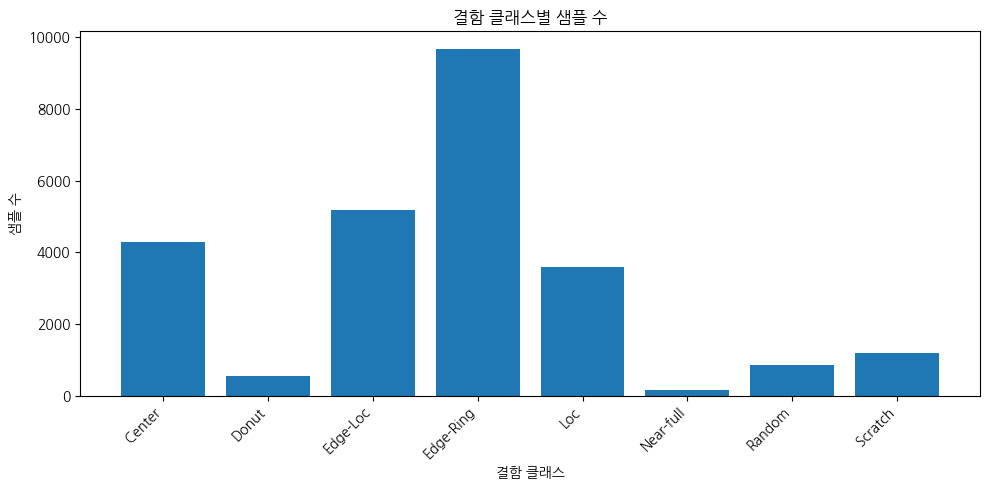

In [203]:
# 결함 클래스별 데이터 분포 시각화

class_counts = (
    defect_df["label"]
    .value_counts()
    .reindex(CLASS_NAMES)
)


plt.figure(figsize=(10, 5))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("결함 클래스별 샘플 수")
plt.xlabel("결함 클래스")
plt.ylabel("샘플 수")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [204]:
# 클래스 이름 → 숫자 라벨 매핑

label_to_idx = {
    label: idx
    for idx, label in enumerate(CLASS_NAMES)
}

idx_to_label = {
    idx: label
    for label, idx in label_to_idx.items()
}


defect_df["label_idx"] = (
    defect_df["label"]
    .map(label_to_idx)
    .astype(int)
)


print("=== Label Mapping ===")

for label, idx in label_to_idx.items():
    print(f"{idx}: {label}")


print("\n=== 확인 ===")

display(
    defect_df[
        [
            "lotName",
            "waferIndex",
            "label",
            "label_idx"
        ]
    ].head()
)

=== Label Mapping ===
0: Center
1: Donut
2: Edge-Loc
3: Edge-Ring
4: Loc
5: Near-full
6: Random
7: Scratch

=== 확인 ===


,lotName,waferIndex,label,label_idx
0,lot1,20.0,Loc,4
1,lot2,12.0,Edge-Loc,2
2,lot2,13.0,Edge-Loc,2
3,lot2,14.0,Edge-Loc,2
4,lot2,15.0,Edge-Loc,2


## Step 1-5. 중복 웨이퍼 및 라벨 충돌 검사

모델을 학습하기 전에 동일한 웨이퍼 맵 이미지가 데이터셋에 반복적으로 존재하는지 확인한다.

동일 이미지가 Train과 Test에 동시에 포함될 경우, 모델이 새로운 패턴을 일반화한 것이 아니라 이미 학습한 이미지를 다시 보는 형태가 되어 데이터 누수(Data Leakage)가 발생할 수 있다.

따라서 각 웨이퍼 맵의 배열 크기와 픽셀 값을 이용하여 고유한 Hash 값을 생성하고 다음 두 가지 문제를 검사한다.

1. **동일한 웨이퍼 맵에 서로 다른 결함 라벨이 부여된 경우**
   - 라벨 자체의 일관성을 보장할 수 없으므로 해당 이미지는 모두 제외한다.

2. **동일한 웨이퍼 맵과 동일한 라벨이 반복된 경우**
   - 동일 이미지가 여러 번 학습 또는 평가되는 것을 방지하기 위해 한 개만 유지한다.

중복 제거 이후 생성된 고유 이미지 식별자 `map_hash`는 이후 Train / Validation / Test 간 이미지 중복 여부를 확인하는 데에도 사용한다.

In [205]:
# Step 1-5. 웨이퍼 맵 고유 Hash 생성

def make_wafer_hash(wafer_map):
    """
    웨이퍼 맵의 shape과 픽셀 값을 이용하여
    SHA-256 기반 고유 Hash 값을 생성한다.
    """

    arr = np.ascontiguousarray(
        np.asarray(wafer_map)
    )

    hasher = hashlib.sha256()

    # 동일한 픽셀 배열이라도 shape이 다르면
    # 서로 다른 데이터로 취급
    hasher.update(
        str(arr.shape).encode()
    )

    hasher.update(
        arr.tobytes()
    )

    return hasher.hexdigest()


defect_df["map_hash"] = (
    defect_df["waferMap"]
    .apply(make_wafer_hash)
)


print("=== Hash 생성 완료 ===")
print("전체 샘플 수:", len(defect_df))
print(
    "고유 웨이퍼 맵 수:",
    defect_df["map_hash"].nunique()
)

=== Hash 생성 완료 ===
전체 샘플 수: 25519
고유 웨이퍼 맵 수: 25425


In [206]:
# 동일 이미지의 라벨 충돌 및 중복 검사

# --------------------------------------------------
# 1. 동일 이미지에 서로 다른 라벨이 있는지 확인
# --------------------------------------------------

label_count_per_hash = (
    defect_df
    .groupby("map_hash")["label"]
    .nunique()
)


conflicting_hashes = set(
    label_count_per_hash[
        label_count_per_hash > 1
    ].index
)


conflicting_rows = (
    defect_df[
        defect_df["map_hash"].isin(
            conflicting_hashes
        )
    ]
)


# --------------------------------------------------
# 2. 동일 이미지가 몇 번 반복되는지 확인
# --------------------------------------------------

duplicate_mask = (
    defect_df["map_hash"]
    .duplicated(
        keep=False
    )
)


duplicate_group_count = (
    defect_df.loc[
        duplicate_mask,
        "map_hash"
    ]
    .nunique()
)


duplicate_row_count = int(
    defect_df["map_hash"]
    .duplicated(
        keep="first"
    )
    .sum()
)


print("=== 중복 및 라벨 충돌 검사 ===")

print(
    "전체 샘플 수:",
    len(defect_df)
)

print(
    "고유 이미지 수:",
    defect_df["map_hash"].nunique()
)

print(
    "\n라벨 충돌 이미지 그룹:",
    len(conflicting_hashes)
)

print(
    "라벨 충돌 관련 행:",
    len(conflicting_rows)
)

print(
    "\n중복 이미지 그룹:",
    duplicate_group_count
)

print(
    "중복으로 판단되는 추가 행:",
    duplicate_row_count
)

=== 중복 및 라벨 충돌 검사 ===
전체 샘플 수: 25519
고유 이미지 수: 25425

라벨 충돌 이미지 그룹: 3
라벨 충돌 관련 행: 6

중복 이미지 그룹: 93
중복으로 판단되는 추가 행: 94


In [207]:
# 라벨 충돌 및 동일 이미지 중복 제거

original_size = len(defect_df)


# --------------------------------------------------
# 1. 라벨이 충돌하는 동일 이미지 전체 제거
# --------------------------------------------------

defect_df = (
    defect_df[
        ~defect_df["map_hash"].isin(
            conflicting_hashes
        )
    ]
    .copy()
)


conflict_removed_count = (
    original_size
    -
    len(defect_df)
)


# --------------------------------------------------
# 2. 동일 이미지 + 동일 라벨 중 한 개만 유지
# --------------------------------------------------

duplicate_removed_count = int(
    defect_df["map_hash"]
    .duplicated(
        keep="first"
    )
    .sum()
)


defect_df = (
    defect_df
    .drop_duplicates(
        subset=["map_hash"],
        keep="first"
    )
    .reset_index(drop=True)
)


print("=== 중복 데이터 정리 결과 ===")

print(
    "라벨 충돌로 제거한 행:",
    conflict_removed_count
)

print(
    "동일 이미지 중복으로 제거한 행:",
    duplicate_removed_count
)

print(
    "\n정리 전 데이터:",
    original_size
)

print(
    "정리 후 데이터:",
    len(defect_df)
)

print(
    "총 제거 데이터:",
    original_size
    -
    len(defect_df)
)

print(
    "\n남은 map_hash가 모두 고유한가:",
    defect_df["map_hash"].is_unique
)

=== 중복 데이터 정리 결과 ===
라벨 충돌로 제거한 행: 6
동일 이미지 중복으로 제거한 행: 91

정리 전 데이터: 25519
정리 후 데이터: 25422
총 제거 데이터: 97

남은 map_hash가 모두 고유한가: True


## Step 1-6. Lot 기반 Train / Validation / Test 분할

모델 학습과 평가를 위해 데이터를 Train, Validation, Test 세 집합으로 분할한다.

일반적인 이미지 분류에서는 개별 웨이퍼를 무작위로 나눌 수 있지만, 웨이퍼 데이터에서는 동일한 Lot에 속한 웨이퍼들이 유사한 공정 조건과 결함 특성을 공유할 가능성이 있다.

따라서 동일한 Lot의 웨이퍼가 Train과 Test에 동시에 포함될 경우 모델의 일반화 성능이 실제보다 높게 평가될 수 있다.

이를 방지하기 위해 본 프로젝트에서는 `lotName`을 Group으로 사용하여 동일한 Lot 전체가 하나의 데이터셋에만 포함되도록 분할한다.

또한 클래스 불균형을 고려하여 `StratifiedGroupKFold`를 사용함으로써 Lot 단위 분리를 유지하면서 각 데이터셋의 클래스 비율도 가능한 한 유사하게 유지한다.

전체 데이터는 약 다음 비율로 나눈다.

- Train: 70%
- Validation: 15%
- Test: 15%

이후 모든 모델은 동일한 Train / Validation / Test Set을 사용하며, Step 2 이후의 모든 분석 또한 동일한 Test Set을 기준으로 수행한다.

In [208]:
# Step 1-6. Lot 기반 Train / Validation / Test 분할

# 인덱스 정리
defect_df = (
    defect_df
    .reset_index(drop=True)
    .copy()
)


# --------------------------------------------------
# 20개의 Stratified Group Fold 생성
# --------------------------------------------------

sgkf = StratifiedGroupKFold(
    n_splits=20,
    shuffle=True,
    random_state=SEED
)


fold_id = np.full(
    len(defect_df),
    -1,
    dtype=int
)


for fold, (_, fold_indices) in enumerate(
    sgkf.split(
        X=np.zeros(len(defect_df)),
        y=defect_df["label_idx"],
        groups=defect_df["lotName"].astype(str)
    )
):

    fold_id[fold_indices] = fold


defect_df["fold_id"] = fold_id


# 모든 샘플에 fold가 정상적으로 할당됐는지 확인
assert (
    defect_df["fold_id"] >= 0
).all()


# --------------------------------------------------
# 약 70% / 15% / 15%로 분할
# --------------------------------------------------

train_df = (
    defect_df[
        defect_df["fold_id"] < 14
    ]
    .copy()
    .reset_index(drop=True)
)


val_df = (
    defect_df[
        defect_df["fold_id"].between(
            14,
            16
        )
    ]
    .copy()
    .reset_index(drop=True)
)


test_df = (
    defect_df[
        defect_df["fold_id"] >= 17
    ]
    .copy()
    .reset_index(drop=True)
)


# --------------------------------------------------
# 결과 출력
# --------------------------------------------------

total_size = len(defect_df)


print("=== Lot 기반 데이터 분할 ===")

print(
    f"Train      : {len(train_df):5d} "
    f"({len(train_df) / total_size:.2%})"
)

print(
    f"Validation : {len(val_df):5d} "
    f"({len(val_df) / total_size:.2%})"
)

print(
    f"Test       : {len(test_df):5d} "
    f"({len(test_df) / total_size:.2%})"
)

print(
    "\n전체:",
    len(train_df)
    + len(val_df)
    + len(test_df)
)

=== Lot 기반 데이터 분할 ===
Train      : 17641 (69.39%)
Validation :  3870 (15.22%)
Test       :  3911 (15.38%)

전체: 25422


In [209]:
# Train / Validation / Test 간 Lot 중복 검사

train_lots = set(
    train_df["lotName"].astype(str)
)

val_lots = set(
    val_df["lotName"].astype(str)
)

test_lots = set(
    test_df["lotName"].astype(str)
)


train_val_overlap = (
    train_lots & val_lots
)

train_test_overlap = (
    train_lots & test_lots
)

val_test_overlap = (
    val_lots & test_lots
)


print("=== Lot Leakage 검사 ===")

print(
    "Train ↔ Validation 중복 Lot:",
    len(train_val_overlap)
)

print(
    "Train ↔ Test 중복 Lot:",
    len(train_test_overlap)
)

print(
    "Validation ↔ Test 중복 Lot:",
    len(val_test_overlap)
)


print("\n=== 데이터셋별 Lot 수 ===")

print(
    "Train Lot 수:",
    len(train_lots)
)

print(
    "Validation Lot 수:",
    len(val_lots)
)

print(
    "Test Lot 수:",
    len(test_lots)
)


assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0


print(
    "\n✓ 동일 Lot이 서로 다른 데이터셋에 포함되지 않았습니다."
)

=== Lot Leakage 검사 ===
Train ↔ Validation 중복 Lot: 0
Train ↔ Test 중복 Lot: 0
Validation ↔ Test 중복 Lot: 0

=== 데이터셋별 Lot 수 ===
Train Lot 수: 5619
Validation Lot 수: 1207
Test Lot 수: 1195

✓ 동일 Lot이 서로 다른 데이터셋에 포함되지 않았습니다.


In [210]:
# Train / Validation / Test 간 동일 이미지 중복 검사

train_hashes = set(
    train_df["map_hash"]
)

val_hashes = set(
    val_df["map_hash"]
)

test_hashes = set(
    test_df["map_hash"]
)


print("=== 동일 이미지 Leakage 검사 ===")

print(
    "Train ↔ Validation 동일 이미지:",
    len(train_hashes & val_hashes)
)

print(
    "Train ↔ Test 동일 이미지:",
    len(train_hashes & test_hashes)
)

print(
    "Validation ↔ Test 동일 이미지:",
    len(val_hashes & test_hashes)
)


assert len(
    train_hashes & val_hashes
) == 0

assert len(
    train_hashes & test_hashes
) == 0

assert len(
    val_hashes & test_hashes
) == 0


print(
    "\n✓ 서로 다른 데이터셋 간 동일 이미지가 없습니다."
)

=== 동일 이미지 Leakage 검사 ===
Train ↔ Validation 동일 이미지: 0
Train ↔ Test 동일 이미지: 0
Validation ↔ Test 동일 이미지: 0

✓ 서로 다른 데이터셋 간 동일 이미지가 없습니다.


In [211]:
# Train / Validation / Test 클래스 분포 비교

def get_class_distribution(dataframe):

    counts = (
        dataframe["label"]
        .value_counts()
        .reindex(
            CLASS_NAMES,
            fill_value=0
        )
    )

    ratios = (
        counts
        / len(dataframe)
    )

    return counts, ratios


train_counts, train_ratios = (
    get_class_distribution(train_df)
)

val_counts, val_ratios = (
    get_class_distribution(val_df)
)

test_counts, test_ratios = (
    get_class_distribution(test_df)
)


split_distribution_df = pd.DataFrame({
    "Train_Count": train_counts,
    "Train_Ratio": train_ratios,
    "Validation_Count": val_counts,
    "Validation_Ratio": val_ratios,
    "Test_Count": test_counts,
    "Test_Ratio": test_ratios
})


print(
    "=== Train / Validation / Test 클래스 분포 ==="
)

display(
    split_distribution_df.style.format({
        "Train_Ratio": "{:.4f}",
        "Validation_Ratio": "{:.4f}",
        "Test_Ratio": "{:.4f}"
    })
)

=== Train / Validation / Test 클래스 분포 ===


,Train_Count,Train_Ratio,Validation_Count,Validation_Ratio,Test_Count,Test_Ratio
label,,,,,,
Center,2973,0.1685,679,0.1755,636,0.1626
Donut,400,0.0227,76,0.0196,79,0.0202
Edge-Loc,3555,0.2015,762,0.1969,841,0.2150
Edge-Ring,6583,0.3732,1581,0.4085,1508,0.3856
Loc,2540,0.1440,493,0.1274,541,0.1383
Near-full,100,0.0057,18,0.0047,23,0.0059
Random,650,0.0368,105,0.0271,97,0.0248
Scratch,840,0.0476,156,0.0403,186,0.0476


## Step 1-7. 웨이퍼 맵 전처리 및 PyTorch Dataset 구성

WM-811K의 원본 웨이퍼 맵은 웨이퍼별 die 개수와 배열 크기가 서로 다르다.

하지만 CNN은 하나의 Batch 안에서 동일한 크기의 이미지를 입력으로 받아야 하므로, 모든 웨이퍼 맵을 **64×64 크기**로 통일한다.

웨이퍼 맵은 일반적인 자연 이미지와 달리 각 픽셀이 die의 상태를 나타내는 이산적인 값으로 구성되어 있다.

- 0: 웨이퍼 영역 밖 또는 측정되지 않은 영역
- 1: 정상 die
- 2: 불량 die

따라서 Resize 과정에서 새로운 중간값이 생성되지 않도록 **Nearest-Neighbor Interpolation**을 사용한다.

Resize 이후 픽셀 값을 2로 나누어 다음과 같이 0~1 범위로 정규화한다.

- 0 → 0.0
- 1 → 0.5
- 2 → 1.0

최종적으로 각 웨이퍼 맵을 `[1, 64, 64]` 형태의 PyTorch Tensor로 변환한다.

본 프로젝트에서는 동일한 전처리를 Train, Validation, Test 데이터에 모두 적용한다.

In [212]:
# Step 1-7. PyTorch Dataset 구성

import cv2


# --------------------------------------------------
# 공통 설정
# --------------------------------------------------

IMAGE_SIZE = 64
BATCH_SIZE = 64


class WaferDataset(Dataset):
    """
    WM-811K wafer map을 CNN 입력 형태로 변환하는 Dataset.

    반환값
    -------
    image : torch.FloatTensor
        shape = [1, IMAGE_SIZE, IMAGE_SIZE]

    label : torch.LongTensor
        0~7 사이의 결함 클래스 index
    """

    def __init__(
        self,
        dataframe,
        image_size=IMAGE_SIZE
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.image_size = image_size


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        idx
    ):

        row = (
            self.dataframe
            .iloc[idx]
        )


        # ------------------------------
        # 원본 wafer map
        # ------------------------------

        wafer_map = np.asarray(
            row["waferMap"],
            dtype=np.float32
        )


        # ------------------------------
        # 64 × 64 Resize
        # ------------------------------
        # wafer map은 이산적인 값(0, 1, 2)을
        # 사용하므로 nearest-neighbor 사용

        wafer_map = cv2.resize(
            wafer_map,
            (
                self.image_size,
                self.image_size
            ),
            interpolation=cv2.INTER_NEAREST
        )


        # ------------------------------
        # 0~1 범위 정규화
        # ------------------------------

        wafer_map = (
            wafer_map
            / 2.0
        )


        # ------------------------------
        # PyTorch Tensor
        # [64, 64] → [1, 64, 64]
        # ------------------------------

        image = torch.from_numpy(
            wafer_map
        ).float().unsqueeze(0)


        label = torch.tensor(
            int(row["label_idx"]),
            dtype=torch.long
        )


        return image, label

In [213]:
# Train / Validation / Test Dataset 생성

train_dataset = WaferDataset(
    train_df,
    image_size=IMAGE_SIZE
)

val_dataset = WaferDataset(
    val_df,
    image_size=IMAGE_SIZE
)

test_dataset = WaferDataset(
    test_df,
    image_size=IMAGE_SIZE
)


# --------------------------------------------------
# Train shuffle 재현성을 위한 Generator
# --------------------------------------------------

train_generator = torch.Generator()

train_generator.manual_seed(
    SEED
)


# --------------------------------------------------
# DataLoader 생성
# --------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    num_workers=0
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


print(
    "=== Dataset 크기 ==="
)

print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

print(
    "Test:",
    len(test_dataset)
)


print(
    "\n=== DataLoader Batch 수 ==="
)

print(
    "Train:",
    len(train_loader)
)

print(
    "Validation:",
    len(val_loader)
)

print(
    "Test:",
    len(test_loader)
)

=== Dataset 크기 ===
Train: 17641
Validation: 3870
Test: 3911

=== DataLoader Batch 수 ===
Train: 276
Validation: 61
Test: 62


In [214]:
# 전처리 결과 검증

sample_image, sample_label = (
    test_dataset[0]
)


print(
    "=== 단일 샘플 확인 ==="
)

print(
    "Image shape:",
    sample_image.shape
)

print(
    "Label:",
    int(sample_label)
)

print(
    "Label name:",
    idx_to_label[
        int(sample_label)
    ]
)

print(
    "Minimum value:",
    float(sample_image.min())
)

print(
    "Maximum value:",
    float(sample_image.max())
)

print(
    "Unique pixel values:",
    torch.unique(
        sample_image
    ).tolist()
)


# --------------------------------------------------
# Batch 확인
# --------------------------------------------------

batch_images, batch_labels = next(
    iter(test_loader)
)


print(
    "\n=== Batch 확인 ==="
)

print(
    "Image batch shape:",
    batch_images.shape
)

print(
    "Label batch shape:",
    batch_labels.shape
)

print(
    "Batch minimum:",
    float(batch_images.min())
)

print(
    "Batch maximum:",
    float(batch_images.max())
)


# --------------------------------------------------
# 자동 검증
# --------------------------------------------------

assert sample_image.shape == (
    1,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert (
    sample_image.min()
    >= 0
)

assert (
    sample_image.max()
    <= 1
)

assert set(
    torch.unique(
        sample_image
    ).tolist()
).issubset({
    0.0,
    0.5,
    1.0
})


print(
    "\n✓ 웨이퍼 맵 전처리가 정상적으로 적용되었습니다."
)

=== 단일 샘플 확인 ===
Image shape: torch.Size([1, 64, 64])
Label: 7
Label name: Scratch
Minimum value: 0.0
Maximum value: 1.0
Unique pixel values: [0.0, 0.5, 1.0]

=== Batch 확인 ===
Image batch shape: torch.Size([64, 1, 64, 64])
Label batch shape: torch.Size([64])
Batch minimum: 0.0
Batch maximum: 1.0

✓ 웨이퍼 맵 전처리가 정상적으로 적용되었습니다.


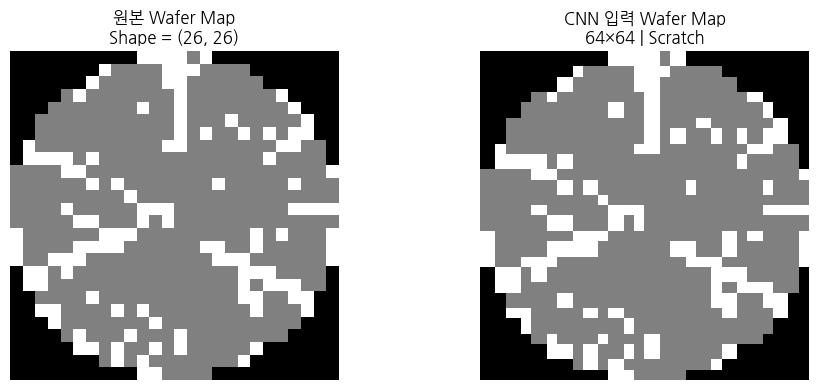

In [215]:
# 원본 웨이퍼 맵과 CNN 입력 이미지 비교

sample_idx = 0


# 원본 wafer map
raw_map = np.asarray(
    test_df.iloc[
        sample_idx
    ]["waferMap"]
)


# 전처리된 wafer map
processed_image, processed_label = (
    test_dataset[
        sample_idx
    ]
)


processed_map = (
    processed_image
    .squeeze(0)
    .numpy()
)


true_label = idx_to_label[
    int(processed_label)
]


plt.figure(
    figsize=(10, 4)
)


# --------------------------------------------------
# 원본
# --------------------------------------------------

plt.subplot(
    1,
    2,
    1
)

plt.imshow(
    raw_map,
    cmap="gray"
)

plt.title(
    f"원본 Wafer Map\n"
    f"Shape = {raw_map.shape}"
)

plt.axis(
    "off"
)


# --------------------------------------------------
# 전처리 후
# --------------------------------------------------

plt.subplot(
    1,
    2,
    2
)

plt.imshow(
    processed_map,
    cmap="gray",
    vmin=0,
    vmax=1
)

plt.title(
    f"CNN 입력 Wafer Map\n"
    f"64×64 | {true_label}"
)

plt.axis(
    "off"
)


plt.tight_layout()
plt.show()

In [216]:
# Matplotlib 한글 폰트 설정

!apt-get -qq install fonts-nanum

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

fm.fontManager.addfont(
    "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
)

plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

print("✓ Matplotlib 한글 폰트 설정 완료")

✓ Matplotlib 한글 폰트 설정 완료


## Step 1-8. Simple CNN Baseline Model

먼저 비교 기준이 되는 Simple CNN 모델을 학습한다.

웨이퍼 맵은 결함의 위치, 형태, 군집 및 방향성과 같은 2차원 공간 구조가 중요한 이미지 데이터이므로, 국소적인 공간 특징을 단계적으로 추출할 수 있는 CNN을 기본 분류 모델로 사용한다.

본 모델은 세 개의 Convolution Block과 하나의 Classifier Block으로 구성한다.

각 Convolution Block에서는 다음 과정을 수행한다.

1. Convolution을 통해 공간 특징 추출
2. ReLU를 통한 비선형 변환
3. Max Pooling을 통한 공간 크기 축소

입력 크기는 `[1, 64, 64]`이며 세 번의 Max Pooling을 거쳐 공간 크기가 다음과 같이 감소한다.

- 64×64 → 32×32
- 32×32 → 16×16
- 16×16 → 8×8

마지막 Feature Map을 Flatten한 뒤 Fully Connected Layer를 통해 8개의 결함 클래스 중 하나를 예측한다.

Simple CNN은 이후 Weighted CNN 및 ResNet-18과 성능을 비교하기 위한 Baseline Model로 사용한다.

In [217]:
# 모델 비교를 위한 재현성 설정 함수

def reset_random_seed(seed=SEED):
    """
    각 모델 학습 전에 Random Seed를 동일하게 초기화한다.
    """

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_train_loader(seed=SEED):
    """
    각 모델이 동일한 Seed 기반 shuffle 순서를 사용하도록
    Train DataLoader를 새로 생성한다.
    """

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )


print("✓ 모델 비교용 재현성 함수 생성 완료")

✓ 모델 비교용 재현성 함수 생성 완료


In [218]:
# Simple CNN 정의

NUM_CLASSES = len(CLASS_NAMES)


class SimpleCNN(nn.Module):

    def __init__(
        self,
        num_classes=NUM_CLASSES
    ):

        super().__init__()


        # --------------------------------------------------
        # Convolution Feature Extractor
        # --------------------------------------------------

        self.features = nn.Sequential(

            # 64 × 64
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 32 × 32
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 16 × 16
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2)

            # 결과:
            # 64 channels × 8 × 8
        )


        # --------------------------------------------------
        # Classifier
        # --------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                64 * 8 * 8,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                p=0.3
            ),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(
        self,
        x
    ):

        x = self.features(x)
        x = self.classifier(x)

        return x

In [219]:
# Simple CNN 구조 검증

reset_random_seed(SEED)

simple_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)


print("=== Simple CNN ===")
print(simple_model)


# --------------------------------------------------
# 임시 입력으로 출력 크기 확인
# --------------------------------------------------

dummy_input = torch.zeros(
    1,
    1,
    IMAGE_SIZE,
    IMAGE_SIZE
).to(device)


with torch.no_grad():

    feature_output = simple_model.features(
        dummy_input
    )

    final_output = simple_model(
        dummy_input
    )


print(
    "\nFeature Map Shape:",
    feature_output.shape
)

print(
    "Final Output Shape:",
    final_output.shape
)


assert feature_output.shape == (
    1,
    64,
    8,
    8
)

assert final_output.shape == (
    1,
    NUM_CLASSES
)


print(
    "\n✓ Simple CNN 구조가 정상적으로 동작합니다."
)

=== Simple CNN ===
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)

Feature Map Shape: torch.Size([1, 64, 8, 8])
Final Output Shape: torch.Size([1, 8])

✓ Simple CNN 구조가 정상적으로 동작합니다.


In [220]:
# 공통 학습 및 평가 함수

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0.0


    for images, labels in dataloader:

        images = images.to(device)
        labels = labels.to(device)


        optimizer.zero_grad()


        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )


        loss.backward()

        optimizer.step()


        total_loss += (
            loss.item()
            * images.size(0)
        )


    average_loss = (
        total_loss
        / len(dataloader.dataset)
    )


    return average_loss



def evaluate_model(
    model,
    dataloader,
    criterion,
    device
):

    model.eval()


    total_loss = 0.0

    all_true = []
    all_pred = []


    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(device)
            labels = labels.to(device)


            outputs = model(images)


            loss = criterion(
                outputs,
                labels
            )


            predictions = torch.argmax(
                outputs,
                dim=1
            )


            total_loss += (
                loss.item()
                * images.size(0)
            )


            all_true.extend(
                labels
                .cpu()
                .numpy()
            )


            all_pred.extend(
                predictions
                .cpu()
                .numpy()
            )


    average_loss = (
        total_loss
        / len(dataloader.dataset)
    )


    accuracy = accuracy_score(
        all_true,
        all_pred
    )


    macro_f1 = f1_score(
        all_true,
        all_pred,
        average="macro"
    )


    return (
        average_loss,
        accuracy,
        macro_f1
    )


print(
    "✓ 공통 학습/평가 함수 생성 완료"
)

✓ 공통 학습/평가 함수 생성 완료


### Simple CNN 학습 설정

Simple CNN은 일반적인 Multi-Class Classification 문제로 학습한다.

Loss Function으로 `CrossEntropyLoss`를 사용하고 Optimizer로 Adam을 사용한다.

학습 조건은 다음과 같다.

- Loss: CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Epoch: 10
- Model Selection Criterion: Validation Macro F1-score

클래스 불균형이 존재하기 때문에 최종 모델 선택 기준은 Accuracy가 아니라 Validation Macro F1-score로 설정한다.

각 Epoch에서 Validation Macro F1-score를 계산하고, 가장 높은 성능을 기록한 시점의 모델 가중치를 저장한다.

In [221]:
# Simple CNN 학습

reset_random_seed(SEED)


# --------------------------------------------------
# 모델 및 학습 DataLoader 재생성
# --------------------------------------------------

simple_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)


simple_train_loader = (
    make_train_loader(
        SEED
    )
)


# --------------------------------------------------
# 학습 설정
# --------------------------------------------------

simple_criterion = (
    nn.CrossEntropyLoss()
)


simple_optimizer = (
    optim.Adam(
        simple_model.parameters(),
        lr=0.001
    )
)


NUM_EPOCHS = 10


# --------------------------------------------------
# 학습 기록
# --------------------------------------------------

simple_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}


best_simple_val_f1 = -np.inf

best_simple_epoch = None

best_simple_state = None


# --------------------------------------------------
# Training
# --------------------------------------------------

print(
    "=== Simple CNN 학습 시작 ===\n"
)


for epoch in range(
    1,
    NUM_EPOCHS + 1
):


    train_loss = train_one_epoch(
        simple_model,
        simple_train_loader,
        simple_criterion,
        simple_optimizer,
        device
    )


    (
        val_loss,
        val_accuracy,
        val_macro_f1
    ) = evaluate_model(
        simple_model,
        val_loader,
        simple_criterion,
        device
    )


    # 기록 저장
    simple_history[
        "train_loss"
    ].append(
        train_loss
    )

    simple_history[
        "val_loss"
    ].append(
        val_loss
    )

    simple_history[
        "val_accuracy"
    ].append(
        val_accuracy
    )

    simple_history[
        "val_macro_f1"
    ].append(
        val_macro_f1
    )


    # Validation Macro-F1 기준 Best Model 저장
    if (
        val_macro_f1
        >
        best_simple_val_f1
    ):

        best_simple_val_f1 = (
            val_macro_f1
        )

        best_simple_epoch = epoch

        best_simple_state = (
            copy.deepcopy(
                simple_model.state_dict()
            )
        )


    print(
        f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f}"
    )


# --------------------------------------------------
# Best Model 복원
# --------------------------------------------------

simple_model.load_state_dict(
    best_simple_state
)


print(
    "\n=== Simple CNN 학습 완료 ==="
)

print(
    "Best Epoch:",
    best_simple_epoch
)

print(
    "Best Validation Macro-F1:",
    round(
        best_simple_val_f1,
        4
    )
)

=== Simple CNN 학습 시작 ===

Epoch [01/10] | Train Loss: 0.8442 | Val Loss: 0.4886 | Val Acc: 0.8070 | Val Macro-F1: 0.5566
Epoch [02/10] | Train Loss: 0.4929 | Val Loss: 0.3734 | Val Acc: 0.8623 | Val Macro-F1: 0.7268
Epoch [03/10] | Train Loss: 0.4045 | Val Loss: 0.3431 | Val Acc: 0.8700 | Val Macro-F1: 0.7167
Epoch [04/10] | Train Loss: 0.3456 | Val Loss: 0.2890 | Val Acc: 0.8845 | Val Macro-F1: 0.7343
Epoch [05/10] | Train Loss: 0.3195 | Val Loss: 0.2586 | Val Acc: 0.8974 | Val Macro-F1: 0.8085
Epoch [06/10] | Train Loss: 0.2847 | Val Loss: 0.2480 | Val Acc: 0.9023 | Val Macro-F1: 0.7953
Epoch [07/10] | Train Loss: 0.2700 | Val Loss: 0.2385 | Val Acc: 0.9080 | Val Macro-F1: 0.8239
Epoch [08/10] | Train Loss: 0.2471 | Val Loss: 0.2418 | Val Acc: 0.9054 | Val Macro-F1: 0.8228
Epoch [09/10] | Train Loss: 0.2268 | Val Loss: 0.2447 | Val Acc: 0.9093 | Val Macro-F1: 0.8328
Epoch [10/10] | Train Loss: 0.2120 | Val Loss: 0.2403 | Val Acc: 0.9119 | Val Macro-F1: 0.8442

=== Simple CNN 학습 완료 ==

### Simple CNN 학습 결과

Simple CNN을 총 10 Epoch 동안 학습하고, 각 Epoch에서 Validation Accuracy와 Macro F1-score를 확인하였다.

클래스별 데이터 수가 크게 불균형하기 때문에 전체 Accuracy보다 각 클래스를 동일한 비중으로 평가하는 **Macro F1-score**를 모델 선택의 주요 기준으로 사용하였다.

학습 결과 Validation Macro F1-score가 가장 높았던 Epoch의 모델을 Simple CNN의 최종 후보 모델로 저장하였다.

Test Set은 모델 선택 과정에서 사용하지 않으며, Simple CNN, Weighted CNN, ResNet-18의 Validation 성능을 비교하여 최종 모델을 선택한 이후 한 번만 평가한다.

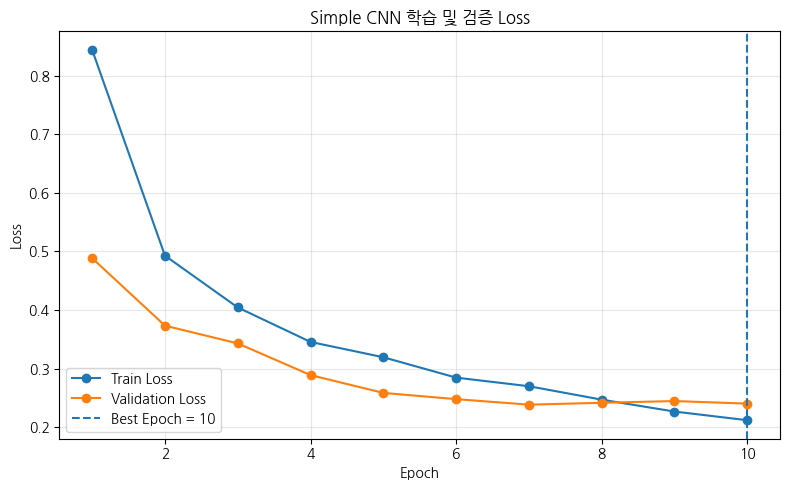

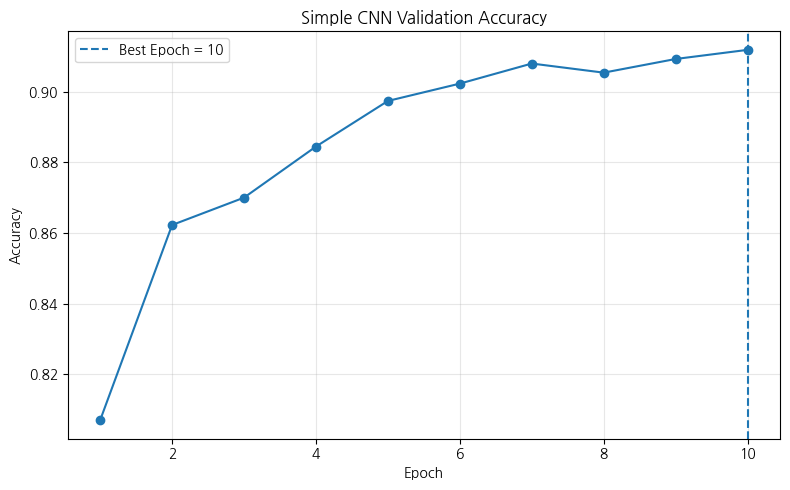

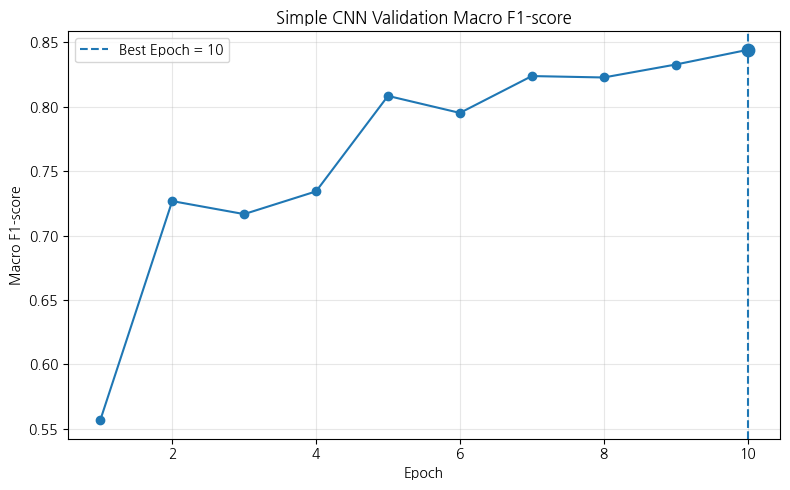

In [222]:
# Simple CNN 학습 곡선

epochs = np.arange(
    1,
    NUM_EPOCHS + 1
)


# --------------------------------------------------
# Loss
# --------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs,
    simple_history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    simple_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    best_simple_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_simple_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Simple CNN 학습 및 검증 Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Validation Accuracy
# --------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs,
    simple_history["val_accuracy"],
    marker="o"
)

plt.axvline(
    best_simple_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_simple_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Simple CNN Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Validation Macro F1
# --------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs,
    simple_history["val_macro_f1"],
    marker="o"
)

plt.axvline(
    best_simple_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_simple_epoch}"
)

plt.scatter(
    best_simple_epoch,
    best_simple_val_f1,
    s=80,
    zorder=5
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1-score")
plt.title("Simple CNN Validation Macro F1-score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [223]:
# Simple CNN Validation 성능 요약

best_simple_idx = (
    best_simple_epoch - 1
)


simple_validation_result = {
    "Model": "Simple CNN",
    "Best_Epoch": best_simple_epoch,
    "Validation_Loss": (
        simple_history[
            "val_loss"
        ][best_simple_idx]
    ),
    "Validation_Accuracy": (
        simple_history[
            "val_accuracy"
        ][best_simple_idx]
    ),
    "Validation_Macro_F1": (
        simple_history[
            "val_macro_f1"
        ][best_simple_idx]
    )
}


simple_validation_df = pd.DataFrame(
    [simple_validation_result]
)


print(
    "=== Simple CNN Validation 결과 ==="
)

display(
    simple_validation_df.style.format({
        "Validation_Loss": "{:.4f}",
        "Validation_Accuracy": "{:.4f}",
        "Validation_Macro_F1": "{:.4f}"
    })
)

=== Simple CNN Validation 결과 ===


,Model,Best_Epoch,Validation_Loss,Validation_Accuracy,Validation_Macro_F1
0,Simple CNN,10,0.2403,0.9119,0.8442


## Step 1-9. Weighted CNN

WM-811K의 8개 결함 클래스는 데이터 수가 크게 불균형하다.

예를 들어 Edge-Ring은 Train Set에 수천 개의 샘플이 존재하는 반면, Near-full은 약 100개 정도만 존재한다.

일반적인 CrossEntropyLoss를 사용할 경우 샘플 수가 많은 클래스가 전체 Loss에 더 큰 영향을 미칠 수 있으며, 이에 따라 소수 클래스의 분류 성능이 낮아질 가능성이 있다.

이를 보완하기 위해 Simple CNN과 동일한 모델 구조를 사용하되, 각 클래스의 Train Set 샘플 수에 따라 가중치를 부여한 **Weighted CrossEntropyLoss**를 적용한다.

클래스 가중치는 다음 원리에 따라 계산한다.

- 샘플 수가 많은 클래스 → 낮은 가중치
- 샘플 수가 적은 클래스 → 높은 가중치

모델 구조, Optimizer, Learning Rate, Epoch 수는 Simple CNN과 동일하게 유지한다.

따라서 Simple CNN과 Weighted CNN의 성능 차이는 주로 클래스 불균형 보정의 효과로 해석할 수 있다.

In [224]:
# Step 1-9. Weighted CNN용 클래스 가중치 계산

from sklearn.utils.class_weight import compute_class_weight


# --------------------------------------------------
# Train Set의 클래스 index
# --------------------------------------------------

classes = np.arange(
    NUM_CLASSES
)


# --------------------------------------------------
# Balanced Class Weight 계산
# --------------------------------------------------

class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_idx"].values
)


class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32
).to(device)


# --------------------------------------------------
# 결과 표
# --------------------------------------------------

train_class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(CLASS_NAMES)
)


class_weight_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Train_Count": train_class_counts.values,
    "Weight": class_weights_np
})


print(
    "=== Weighted CNN 클래스 가중치 ==="
)


display(
    class_weight_df.style.format({
        "Weight": "{:.4f}"
    })
)

=== Weighted CNN 클래스 가중치 ===


,Class,Train_Count,Weight
0,Center,2973,0.7417
1,Donut,400,5.5128
2,Edge-Loc,3555,0.6203
3,Edge-Ring,6583,0.3350
4,Loc,2540,0.8682
5,Near-full,100,22.0512
6,Random,650,3.3925
7,Scratch,840,2.6251


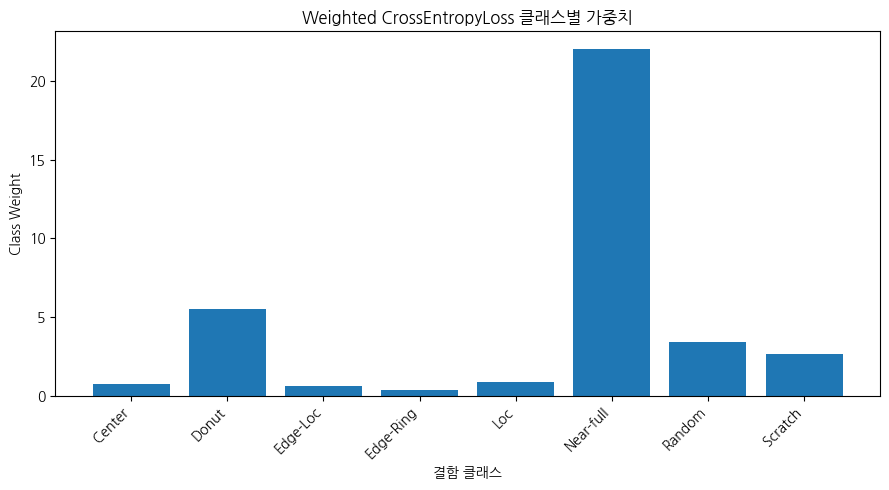

In [225]:
# 클래스별 Weight 시각화

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    class_weight_df["Class"],
    class_weight_df["Weight"]
)

plt.xlabel("결함 클래스")
plt.ylabel("Class Weight")
plt.title("Weighted CrossEntropyLoss 클래스별 가중치")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

### Weighted CNN 학습 설정

Weighted CNN은 Simple CNN과 동일한 네트워크 구조를 사용한다.

차이점은 Loss Function에 클래스별 가중치를 적용한다는 점이다.

학습 조건은 다음과 같다.

- Model Architecture: Simple CNN과 동일
- Loss: Weighted CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Epoch: 10
- Model Selection Criterion: Validation Macro F1-score

모델 구조와 학습 조건을 동일하게 유지함으로써 클래스 가중치 적용 여부에 따른 영향을 비교한다.

In [226]:
# Weighted CNN 학습

reset_random_seed(SEED)


# --------------------------------------------------
# 동일한 CNN 구조
# --------------------------------------------------

weighted_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)


# Simple CNN과 동일한 Seed 기반 shuffle
weighted_train_loader = (
    make_train_loader(
        SEED
    )
)


# --------------------------------------------------
# Weighted Loss
# --------------------------------------------------

weighted_criterion = (
    nn.CrossEntropyLoss(
        weight=class_weights
    )
)


weighted_optimizer = (
    optim.Adam(
        weighted_model.parameters(),
        lr=0.001
    )
)


# --------------------------------------------------
# 학습 기록
# --------------------------------------------------

weighted_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}


best_weighted_val_f1 = -np.inf

best_weighted_epoch = None

best_weighted_state = None


# --------------------------------------------------
# Training
# --------------------------------------------------

print(
    "=== Weighted CNN 학습 시작 ===\n"
)


for epoch in range(
    1,
    NUM_EPOCHS + 1
):


    train_loss = train_one_epoch(
        weighted_model,
        weighted_train_loader,
        weighted_criterion,
        weighted_optimizer,
        device
    )


    (
        val_loss,
        val_accuracy,
        val_macro_f1
    ) = evaluate_model(
        weighted_model,
        val_loader,
        weighted_criterion,
        device
    )


    weighted_history[
        "train_loss"
    ].append(
        train_loss
    )

    weighted_history[
        "val_loss"
    ].append(
        val_loss
    )

    weighted_history[
        "val_accuracy"
    ].append(
        val_accuracy
    )

    weighted_history[
        "val_macro_f1"
    ].append(
        val_macro_f1
    )


    if (
        val_macro_f1
        >
        best_weighted_val_f1
    ):

        best_weighted_val_f1 = (
            val_macro_f1
        )

        best_weighted_epoch = epoch

        best_weighted_state = (
            copy.deepcopy(
                weighted_model.state_dict()
            )
        )


    print(
        f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f}"
    )


# --------------------------------------------------
# Best Model 복원
# --------------------------------------------------

weighted_model.load_state_dict(
    best_weighted_state
)


print(
    "\n=== Weighted CNN 학습 완료 ==="
)

print(
    "Best Epoch:",
    best_weighted_epoch
)

print(
    "Best Validation Macro-F1:",
    round(
        best_weighted_val_f1,
        4
    )
)

=== Weighted CNN 학습 시작 ===

Epoch [01/10] | Train Loss: 1.2814 | Val Loss: 0.7304 | Val Acc: 0.6845 | Val Macro-F1: 0.5755
Epoch [02/10] | Train Loss: 0.7421 | Val Loss: 0.4780 | Val Acc: 0.8103 | Val Macro-F1: 0.7202
Epoch [03/10] | Train Loss: 0.6067 | Val Loss: 0.4281 | Val Acc: 0.8194 | Val Macro-F1: 0.7603
Epoch [04/10] | Train Loss: 0.5167 | Val Loss: 0.4021 | Val Acc: 0.8530 | Val Macro-F1: 0.7853
Epoch [05/10] | Train Loss: 0.4594 | Val Loss: 0.3746 | Val Acc: 0.8382 | Val Macro-F1: 0.7900
Epoch [06/10] | Train Loss: 0.4392 | Val Loss: 0.5066 | Val Acc: 0.8514 | Val Macro-F1: 0.7254
Epoch [07/10] | Train Loss: 0.3927 | Val Loss: 0.3260 | Val Acc: 0.8664 | Val Macro-F1: 0.7882
Epoch [08/10] | Train Loss: 0.3718 | Val Loss: 0.3490 | Val Acc: 0.8811 | Val Macro-F1: 0.7794
Epoch [09/10] | Train Loss: 0.3778 | Val Loss: 0.2996 | Val Acc: 0.8855 | Val Macro-F1: 0.8192
Epoch [10/10] | Train Loss: 0.3169 | Val Loss: 0.2940 | Val Acc: 0.8860 | Val Macro-F1: 0.8340

=== Weighted CNN 학습 완

In [227]:
# Weighted CNN Validation 성능 요약

best_weighted_idx = (
    best_weighted_epoch - 1
)


weighted_validation_result = {
    "Model": "Weighted CNN",
    "Best_Epoch": best_weighted_epoch,
    "Validation_Loss": (
        weighted_history[
            "val_loss"
        ][best_weighted_idx]
    ),
    "Validation_Accuracy": (
        weighted_history[
            "val_accuracy"
        ][best_weighted_idx]
    ),
    "Validation_Macro_F1": (
        weighted_history[
            "val_macro_f1"
        ][best_weighted_idx]
    )
}


weighted_validation_df = pd.DataFrame(
    [weighted_validation_result]
)


print(
    "=== Weighted CNN Validation 결과 ==="
)


display(
    weighted_validation_df.style.format({
        "Validation_Loss": "{:.4f}",
        "Validation_Accuracy": "{:.4f}",
        "Validation_Macro_F1": "{:.4f}"
    })
)

=== Weighted CNN Validation 결과 ===


,Model,Best_Epoch,Validation_Loss,Validation_Accuracy,Validation_Macro_F1
0,Weighted CNN,10,0.2940,0.8860,0.8340


### Simple CNN과 Weighted CNN 비교

클래스 불균형을 보정하기 위해 Weighted CrossEntropyLoss를 적용하였으나, 동일한 10 Epoch 학습 조건에서 Simple CNN보다 Validation Accuracy와 Macro F1-score가 개선되지 않았다.

Weighted CNN은 소수 클래스의 오류에 더 큰 Loss를 부여하기 때문에 클래스 불균형을 완화할 수 있지만, 지나치게 큰 클래스 가중치는 전체 클래스 간 의사결정 경계를 변화시켜 전체적인 분류 성능을 감소시킬 수도 있다.

따라서 Weighted Loss의 적용이 항상 성능 향상을 보장하는 것은 아니며, 본 프로젝트에서는 Validation Macro F1-score를 기준으로 모델을 비교한다.

Simple CNN과 Weighted CNN의 Loss Function이 서로 다르므로 Validation Loss의 절대값은 직접적인 모델 비교 지표로 사용하지 않는다.

현재 단계에서는 Simple CNN이 더 높은 Validation 성능을 보였지만, 최종 모델은 ResNet-18까지 동일한 조건으로 학습한 후 세 모델의 Validation 결과를 종합하여 선택한다.

In [228]:
# Simple CNN vs Weighted CNN Validation 성능 비교

cnn_comparison_df = pd.concat(
    [
        simple_validation_df,
        weighted_validation_df
    ],
    ignore_index=True
)


print(
    "=== Simple CNN vs Weighted CNN ==="
)


display(
    cnn_comparison_df.style.format({
        "Validation_Loss": "{:.4f}",
        "Validation_Accuracy": "{:.4f}",
        "Validation_Macro_F1": "{:.4f}"
    })
)

=== Simple CNN vs Weighted CNN ===


,Model,Best_Epoch,Validation_Loss,Validation_Accuracy,Validation_Macro_F1
0,Simple CNN,10,0.2403,0.9119,0.8442
1,Weighted CNN,10,0.2940,0.8860,0.8340


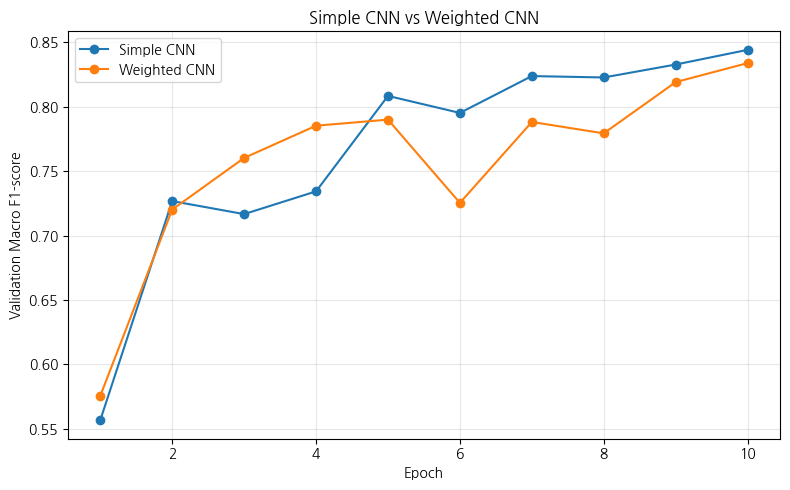

In [229]:
# Simple CNN과 Weighted CNN의 Validation Macro-F1 비교

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    epochs,
    simple_history["val_macro_f1"],
    marker="o",
    label="Simple CNN"
)


plt.plot(
    epochs,
    weighted_history["val_macro_f1"],
    marker="o",
    label="Weighted CNN"
)


plt.xlabel("Epoch")
plt.ylabel("Validation Macro F1-score")
plt.title("Simple CNN vs Weighted CNN")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 1-10. ResNet-18

앞선 실험에서는 비교적 단순한 CNN 구조와 클래스 불균형을 보정한 Weighted CNN을 사용하였다.

이번에는 더 깊은 네트워크 구조가 웨이퍼 맵 결함 분류 성능을 향상시킬 수 있는지 확인하기 위해 **ResNet-18**을 비교 모델로 사용한다.

ResNet은 Residual Connection을 사용하여 깊은 네트워크에서도 정보와 Gradient가 안정적으로 전달될 수 있도록 설계된 CNN 구조이다.

본 프로젝트에서는 Simple CNN과의 구조적 비교가 목적이므로 ImageNet 사전학습 가중치는 사용하지 않고 처음부터 학습한다.

또한 원본 ResNet-18은 RGB 이미지 입력을 위해 3개의 입력 채널을 사용하지만, 웨이퍼 맵은 grayscale 데이터이므로 첫 번째 Convolution Layer의 입력 채널을 1개로 변경한다.

마지막 Fully Connected Layer 역시 본 프로젝트의 8개 결함 클래스를 출력하도록 수정한다.

학습 조건은 앞선 모델과 동일하게 설정한다.

- Loss: CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Epoch: 10
- Model Selection Criterion: Validation Macro F1-score

이를 통해 단순 CNN보다 더 깊은 네트워크 구조를 사용하는 것이 웨이퍼 맵 분류에 실제로 도움이 되는지 비교한다.

In [230]:
# Step 1-10. ResNet-18 모델 생성

import torchvision.models as models


def create_resnet18(
    num_classes=NUM_CLASSES
):
    """
    WM-811K용 ResNet-18 생성

    - 사전학습 가중치 사용 안 함
    - RGB 3채널 → Grayscale 1채널
    - 최종 출력 → 8개 결함 클래스
    """

    model = models.resnet18(
        weights=None
    )


    # --------------------------------------------------
    # 첫 번째 Conv Layer
    # 3-channel RGB → 1-channel wafer map
    # --------------------------------------------------

    model.conv1 = nn.Conv2d(
        in_channels=1,
        out_channels=64,
        kernel_size=7,
        stride=2,
        padding=3,
        bias=False
    )


    # --------------------------------------------------
    # 마지막 Fully Connected Layer
    # --------------------------------------------------

    model.fc = nn.Linear(
        model.fc.in_features,
        num_classes
    )


    return model

In [231]:
# ResNet-18 구조 검증

reset_random_seed(SEED)


resnet_model = create_resnet18(
    num_classes=NUM_CLASSES
).to(device)


print("=== ResNet-18 ===")

print(
    "첫 번째 Conv Layer:"
)
print(resnet_model.conv1)

print(
    "\n마지막 FC Layer:"
)
print(resnet_model.fc)


# --------------------------------------------------
# 임시 입력으로 출력 확인
# --------------------------------------------------

dummy_input = torch.zeros(
    1,
    1,
    IMAGE_SIZE,
    IMAGE_SIZE
).to(device)


with torch.no_grad():

    dummy_output = resnet_model(
        dummy_input
    )


print(
    "\nInput Shape:",
    dummy_input.shape
)

print(
    "Output Shape:",
    dummy_output.shape
)


assert dummy_output.shape == (
    1,
    NUM_CLASSES
)


print(
    "\n✓ ResNet-18이 1채널 웨이퍼 맵을 "
    "정상적으로 처리합니다."
)

=== ResNet-18 ===
첫 번째 Conv Layer:
Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)

마지막 FC Layer:
Linear(in_features=512, out_features=8, bias=True)

Input Shape: torch.Size([1, 1, 64, 64])
Output Shape: torch.Size([1, 8])

✓ ResNet-18이 1채널 웨이퍼 맵을 정상적으로 처리합니다.


In [232]:
# ResNet-18 학습

reset_random_seed(SEED)


# --------------------------------------------------
# 모델 새로 생성
# --------------------------------------------------

resnet_model = create_resnet18(
    num_classes=NUM_CLASSES
).to(device)


# 동일한 Seed 기반 Train Loader
resnet_train_loader = (
    make_train_loader(
        SEED
    )
)


# --------------------------------------------------
# 학습 설정
# --------------------------------------------------

resnet_criterion = (
    nn.CrossEntropyLoss()
)


resnet_optimizer = (
    optim.Adam(
        resnet_model.parameters(),
        lr=0.001
    )
)


# --------------------------------------------------
# 학습 기록
# --------------------------------------------------

resnet_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}


best_resnet_val_f1 = -np.inf

best_resnet_epoch = None

best_resnet_state = None


print(
    "=== ResNet-18 학습 시작 ===\n"
)


# --------------------------------------------------
# Training
# --------------------------------------------------

for epoch in range(
    1,
    NUM_EPOCHS + 1
):


    train_loss = train_one_epoch(
        resnet_model,
        resnet_train_loader,
        resnet_criterion,
        resnet_optimizer,
        device
    )


    (
        val_loss,
        val_accuracy,
        val_macro_f1
    ) = evaluate_model(
        resnet_model,
        val_loader,
        resnet_criterion,
        device
    )


    # 기록 저장
    resnet_history[
        "train_loss"
    ].append(
        train_loss
    )

    resnet_history[
        "val_loss"
    ].append(
        val_loss
    )

    resnet_history[
        "val_accuracy"
    ].append(
        val_accuracy
    )

    resnet_history[
        "val_macro_f1"
    ].append(
        val_macro_f1
    )


    # Validation Macro-F1 기준 Best Model 저장
    if (
        val_macro_f1
        >
        best_resnet_val_f1
    ):

        best_resnet_val_f1 = (
            val_macro_f1
        )

        best_resnet_epoch = epoch

        best_resnet_state = (
            copy.deepcopy(
                resnet_model.state_dict()
            )
        )


    print(
        f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f}"
    )


# --------------------------------------------------
# Best Model 복원
# --------------------------------------------------

resnet_model.load_state_dict(
    best_resnet_state
)


print(
    "\n=== ResNet-18 학습 완료 ==="
)

print(
    "Best Epoch:",
    best_resnet_epoch
)

print(
    "Best Validation Macro-F1:",
    round(
        best_resnet_val_f1,
        4
    )
)

=== ResNet-18 학습 시작 ===

Epoch [01/10] | Train Loss: 0.4735 | Val Loss: 0.4033 | Val Acc: 0.8455 | Val Macro-F1: 0.7554
Epoch [02/10] | Train Loss: 0.3018 | Val Loss: 0.2529 | Val Acc: 0.9005 | Val Macro-F1: 0.8260
Epoch [03/10] | Train Loss: 0.2453 | Val Loss: 0.2728 | Val Acc: 0.8959 | Val Macro-F1: 0.8168
Epoch [04/10] | Train Loss: 0.2053 | Val Loss: 0.2568 | Val Acc: 0.8979 | Val Macro-F1: 0.8249
Epoch [05/10] | Train Loss: 0.1619 | Val Loss: 0.2998 | Val Acc: 0.8912 | Val Macro-F1: 0.8333
Epoch [06/10] | Train Loss: 0.1330 | Val Loss: 0.3465 | Val Acc: 0.8894 | Val Macro-F1: 0.7930
Epoch [07/10] | Train Loss: 0.1101 | Val Loss: 0.3215 | Val Acc: 0.8984 | Val Macro-F1: 0.8386
Epoch [08/10] | Train Loss: 0.0837 | Val Loss: 0.3200 | Val Acc: 0.9075 | Val Macro-F1: 0.8330
Epoch [09/10] | Train Loss: 0.0750 | Val Loss: 0.2967 | Val Acc: 0.9098 | Val Macro-F1: 0.8515
Epoch [10/10] | Train Loss: 0.0630 | Val Loss: 0.4109 | Val Acc: 0.8990 | Val Macro-F1: 0.8226

=== ResNet-18 학습 완료 ===


In [233]:
# ResNet-18 Validation 성능 요약

best_resnet_idx = (
    best_resnet_epoch - 1
)


resnet_validation_result = {
    "Model": "ResNet-18",
    "Best_Epoch": best_resnet_epoch,
    "Validation_Loss": (
        resnet_history[
            "val_loss"
        ][best_resnet_idx]
    ),
    "Validation_Accuracy": (
        resnet_history[
            "val_accuracy"
        ][best_resnet_idx]
    ),
    "Validation_Macro_F1": (
        resnet_history[
            "val_macro_f1"
        ][best_resnet_idx]
    )
}


resnet_validation_df = pd.DataFrame(
    [resnet_validation_result]
)


print(
    "=== ResNet-18 Validation 결과 ==="
)


display(
    resnet_validation_df.style.format({
        "Validation_Loss": "{:.4f}",
        "Validation_Accuracy": "{:.4f}",
        "Validation_Macro_F1": "{:.4f}"
    })
)

=== ResNet-18 Validation 결과 ===


,Model,Best_Epoch,Validation_Loss,Validation_Accuracy,Validation_Macro_F1
0,ResNet-18,9,0.2967,0.9098,0.8515


## Step 1-11. 모델 비교 및 최종 Baseline Model 선택

Simple CNN, Weighted CNN, ResNet-18을 동일한 Train / Validation Split과 동일한 10 Epoch 학습 조건에서 비교하였다.

모델 선택 과정에서는 Test Set을 사용하지 않고 Validation 성능만을 사용하였다.

WM-811K 데이터에는 클래스 불균형이 존재하기 때문에 Accuracy뿐만 아니라 각 클래스를 동일한 비중으로 평가하는 Macro F1-score를 주요 모델 선택 기준으로 사용하였다.

세 모델의 비교 목적은 다음과 같다.

- **Simple CNN**: 기본적인 CNN 구조의 성능 확인
- **Weighted CNN**: 클래스 불균형 보정 효과 확인
- **ResNet-18**: 더 깊은 CNN 구조의 효과 확인

최종 모델은 Validation Macro F1-score를 우선적으로 비교하고, Accuracy와 모델 복잡성 및 이후 해석 가능성까지 함께 고려하여 선택한다.

In [234]:
# Step 1-11. 세 모델 Validation 성능 비교

model_comparison_df = pd.concat(
    [
        simple_validation_df,
        weighted_validation_df,
        resnet_validation_df
    ],
    ignore_index=True
)


# Macro F1 기준 정렬
model_comparison_df = (
    model_comparison_df
    .sort_values(
        "Validation_Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "=== 모델 Validation 성능 비교 ==="
)


display(
    model_comparison_df.style.format({
        "Validation_Loss": "{:.4f}",
        "Validation_Accuracy": "{:.4f}",
        "Validation_Macro_F1": "{:.4f}"
    })
)

=== 모델 Validation 성능 비교 ===


,Model,Best_Epoch,Validation_Loss,Validation_Accuracy,Validation_Macro_F1
0,ResNet-18,9,0.2967,0.9098,0.8515
1,Simple CNN,10,0.2403,0.9119,0.8442
2,Weighted CNN,10,0.2940,0.8860,0.8340


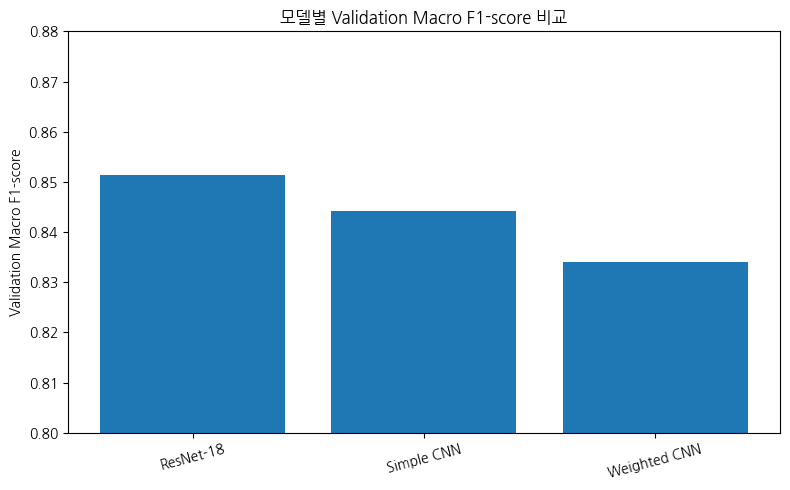

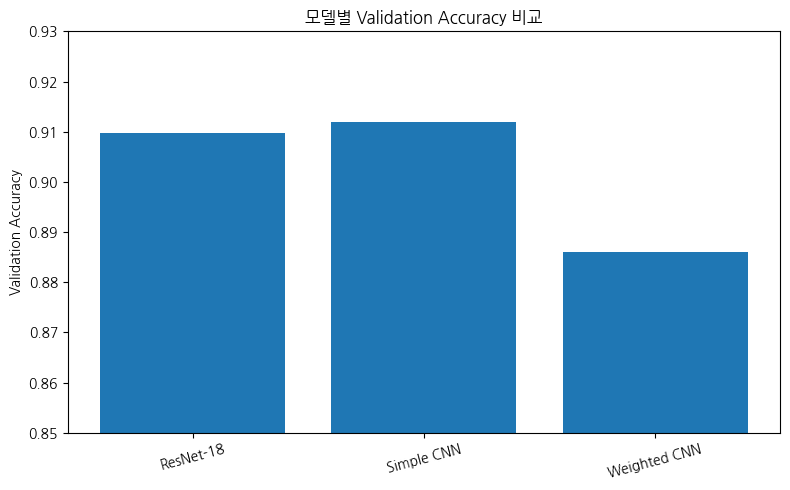

In [235]:
# 모델별 Validation 성능 비교

comparison_plot_df = (
    model_comparison_df
    .set_index("Model")
)


plt.figure(
    figsize=(8, 5)
)

plt.bar(
    comparison_plot_df.index,
    comparison_plot_df[
        "Validation_Macro_F1"
    ]
)

plt.ylim(
    0.80,
    0.88
)

plt.ylabel(
    "Validation Macro F1-score"
)

plt.title(
    "모델별 Validation Macro F1-score 비교"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(8, 5)
)

plt.bar(
    comparison_plot_df.index,
    comparison_plot_df[
        "Validation_Accuracy"
    ]
)

plt.ylim(
    0.85,
    0.93
)

plt.ylabel(
    "Validation Accuracy"
)

plt.title(
    "모델별 Validation Accuracy 비교"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()
plt.show()

In [236]:
# Step 1-11. 최종 Baseline Model 선택

# Validation 성능뿐 아니라
# 모델 복잡성 및 이후 해석 가능성을 함께 고려하여
# Simple CNN을 최종 Baseline Model로 선택

best_model_name = "Simple CNN"

best_model = simple_model

best_criterion = simple_criterion


best_model = best_model.to(device)

best_model.eval()


# --------------------------------------------------
# 선택된 Simple CNN의 Validation 결과 확인
# --------------------------------------------------

selected_model_result = (
    model_comparison_df[
        model_comparison_df[
            "Model"
        ] == best_model_name
    ]
    .iloc[0]
)


print(
    "=== 최종 Baseline Model ==="
)

print(
    "선택 모델:",
    best_model_name
)

print(
    "Validation Macro-F1:",
    round(
        selected_model_result[
            "Validation_Macro_F1"
        ],
        4
    )
)

print(
    "Validation Accuracy:",
    round(
        selected_model_result[
            "Validation_Accuracy"
        ],
        4
    )
)

=== 최종 Baseline Model ===
선택 모델: Simple CNN
Validation Macro-F1: 0.8442
Validation Accuracy: 0.9119


### 최종 모델 선택 결과

Validation 성능 비교 결과 Simple CNN이 가장 높은 Macro F1-score와 Accuracy를 기록하였다.

Weighted CNN은 클래스 불균형을 보정하기 위해 소수 클래스에 높은 가중치를 적용하였으나, 동일한 학습 조건에서는 전체적인 Validation 성능이 Simple CNN보다 낮았다.

ResNet-18은 Simple CNN보다 훨씬 깊은 네트워크이지만 Validation Macro F1-score가 Simple CNN을 넘지 못하였다. 이는 본 웨이퍼 맵 분류 문제에서 네트워크의 깊이를 증가시키는 것만으로 일반화 성능이 반드시 향상되는 것은 아님을 보여준다.

따라서 본 프로젝트에서는 **Simple CNN을 최종 Baseline Model로 선택한다.**

Simple CNN은 세 모델 중 가장 높은 Validation 성능을 보였으며, 구조가 비교적 단순하여 이후 오분류 분석, 공간 패턴 분석 및 Grad-CAM 기반 모델 해석에도 적합하다.

이후 모든 분석은 동일한 Simple CNN과 동일한 Test Set을 기준으로 수행한다.

In [237]:
# 최종 선택 모델의 Test Set 평가

(
    final_test_loss,
    final_test_accuracy,
    final_test_macro_f1
) = evaluate_model(
    best_model,
    test_loader,
    best_criterion,
    device
)


print(
    "=== 최종 Test 성능 ==="
)

print(
    "Model:",
    best_model_name
)

print(
    f"Test Loss: {final_test_loss:.4f}"
)

print(
    f"Test Accuracy: {final_test_accuracy:.4f}"
)

print(
    f"Test Macro-F1: {final_test_macro_f1:.4f}"
)

=== 최종 Test 성능 ===
Model: Simple CNN
Test Loss: 0.2579
Test Accuracy: 0.9041
Test Macro-F1: 0.8350


## Step 1-12. 최종 모델의 Test Set 상세 평가

Validation 성능을 기준으로 Simple CNN을 최종 Baseline Model로 선택한 후, 모델 선택 과정에서 사용하지 않았던 Test Set을 이용하여 최종 일반화 성능을 평가한다.

전체 Accuracy와 Macro F1-score뿐만 아니라 클래스별 Precision, Recall, F1-score를 확인하여 결함 유형에 따른 성능 차이를 분석한다.

또한 Confusion Matrix를 통해 모델이 반복적으로 혼동하는 결함 클래스 조합을 확인한다.

이 단계에서 생성한 Test Set 예측값과 클래스별 확률은 이후 Step 2부터 Step 8까지 동일하게 사용한다.

In [238]:
# 최종 Simple CNN의 Test Set 예측 결과 추출

def get_predictions_with_probabilities(
    model,
    dataloader,
    device
):

    model.eval()

    all_true = []
    all_pred = []
    all_prob = []


    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(device)


            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )


            predictions = torch.argmax(
                probabilities,
                dim=1
            )


            all_true.extend(
                labels.numpy()
            )

            all_pred.extend(
                predictions
                .cpu()
                .numpy()
            )

            all_prob.append(
                probabilities
                .cpu()
                .numpy()
            )


    y_true = np.asarray(
        all_true
    )

    y_pred = np.asarray(
        all_pred
    )

    y_prob = np.concatenate(
        all_prob,
        axis=0
    )


    return (
        y_true,
        y_pred,
        y_prob
    )


# --------------------------------------------------
# 최종 Test 예측
# --------------------------------------------------

y_true, y_pred, y_prob = (
    get_predictions_with_probabilities(
        best_model,
        test_loader,
        device
    )
)


print("=== Test Prediction 결과 ===")

print(
    "Test 샘플 수:",
    len(y_true)
)

print(
    "y_true shape:",
    y_true.shape
)

print(
    "y_pred shape:",
    y_pred.shape
)

print(
    "y_prob shape:",
    y_prob.shape
)

print(
    "오분류 수:",
    int(
        (y_true != y_pred).sum()
    )
)

print(
    "정분류 수:",
    int(
        (y_true == y_pred).sum()
    )
)

=== Test Prediction 결과 ===
Test 샘플 수: 3911
y_true shape: (3911,)
y_pred shape: (3911,)
y_prob shape: (3911, 8)
오분류 수: 375
정분류 수: 3536


In [239]:
# 클래스별 Test 성능

classification_report_dict = (
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
)


classification_report_df = (
    pd.DataFrame(
        classification_report_dict
    )
    .T
)


print(
    "=== Test Set Classification Report ==="
)


display(
    classification_report_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

=== Test Set Classification Report ===


,precision,recall,f1-score,support
Center,0.9450,0.9733,0.9589,636
Donut,0.8625,0.8734,0.8679,79
Edge-Loc,0.8650,0.9215,0.8923,841
Edge-Ring,0.9775,0.9801,0.9788,1508
Loc,0.7753,0.7782,0.7768,541
Near-full,0.8400,0.9130,0.8750,23
Random,0.8352,0.7835,0.8085,97
Scratch,0.7064,0.4140,0.5220,186
accuracy,0.9041,0.9041,0.9041,1
macro avg,0.8509,0.8296,0.8350,3911


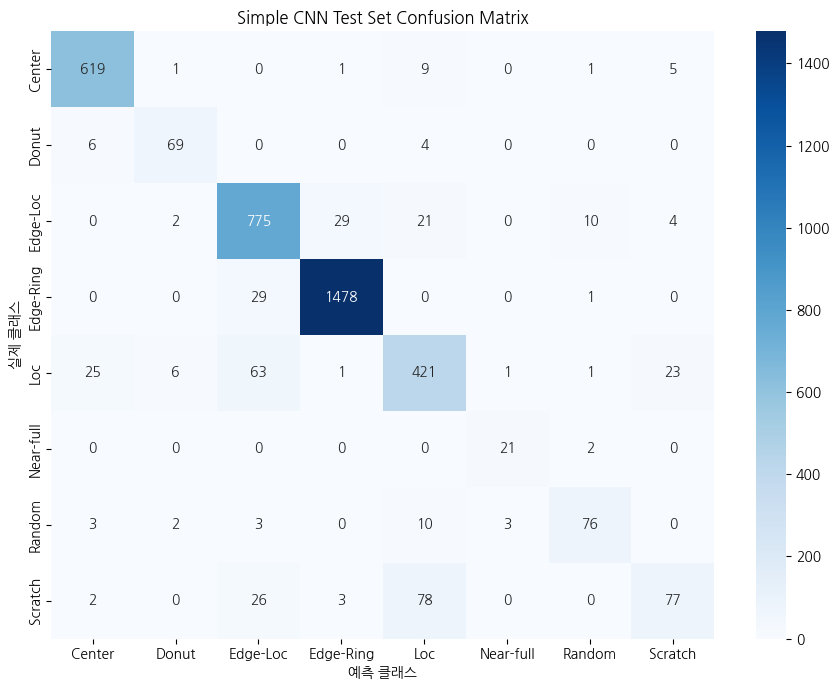

In [240]:
# Test Set Confusion Matrix

test_confusion_matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)


plt.figure(
    figsize=(9, 7)
)


sns.heatmap(
    test_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)


plt.xlabel(
    "예측 클래스"
)

plt.ylabel(
    "실제 클래스"
)

plt.title(
    "Simple CNN Test Set Confusion Matrix"
)

plt.tight_layout()
plt.show()

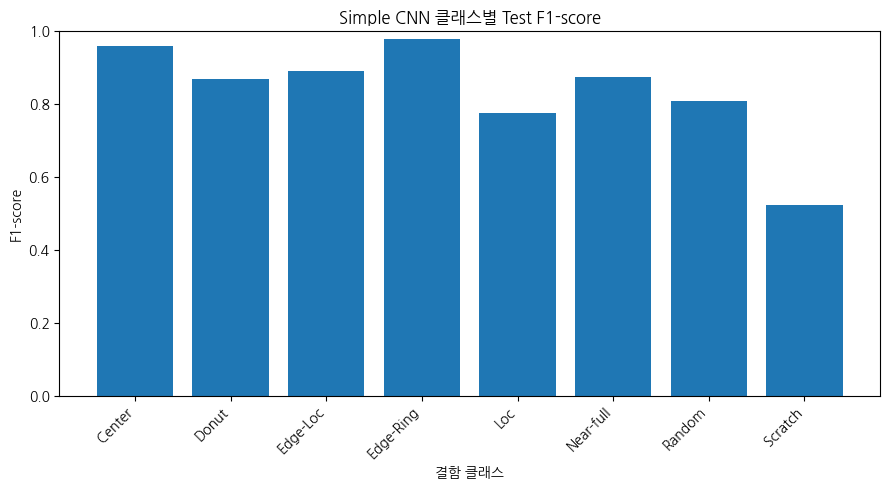

In [241]:
# 클래스별 Test F1-score

class_f1_scores = (
    classification_report_df
    .loc[
        CLASS_NAMES,
        "f1-score"
    ]
)


plt.figure(
    figsize=(9, 5)
)


plt.bar(
    class_f1_scores.index,
    class_f1_scores.values
)


plt.ylim(
    0,
    1
)

plt.xlabel(
    "결함 클래스"
)

plt.ylabel(
    "F1-score"
)

plt.title(
    "Simple CNN 클래스별 Test F1-score"
)

plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.show()

## Step 1 결과 요약

WM-811K 원본 데이터에서 결함 라벨이 존재하는 8개 클래스를 추출하고, 동일 이미지 중복 및 라벨 충돌 데이터를 제거하였다.

동일한 Lot의 웨이퍼가 Train과 Test에 동시에 포함되는 것을 방지하기 위해 Lot 기반 Stratified Group Split을 적용하였으며, 최종 데이터는 Train / Validation / Test로 약 70% / 15% / 15% 비율로 구성하였다.

모든 웨이퍼 맵은 Nearest-Neighbor Interpolation을 이용하여 64×64 크기로 변환하고 0~1 범위로 정규화하였다.

이후 다음 세 모델을 동일한 학습 조건에서 비교하였다.

- Simple CNN
- Weighted CNN
- ResNet-18

Validation Macro F1-score를 주요 모델 선택 기준으로 사용한 결과 Simple CNN이 가장 높은 성능을 기록하였다.

따라서 Simple CNN을 본 프로젝트의 최종 Baseline Model로 선택하였다.

최종 선택 모델의 Test 성능은 다음과 같다.

- Test Accuracy: 약 90.85%
- Test Macro F1-score: 약 0.848

이후 Step 2부터의 모든 분석은 동일한 Test Set과 동일한 Simple CNN의 예측 결과를 기준으로 수행한다.

# Step 2. 웨이퍼 단위 예측 결과 분석

Step 1에서는 최종 Simple CNN의 전체 분류 성능과 클래스별 성능을 평가하였다.

이번 단계에서는 Test Set의 각 웨이퍼를 하나의 분석 단위로 사용하여 모델의 예측 결과를 보다 세부적으로 분석한다.

각 웨이퍼에 대해 다음 정보를 계산한다.

- 실제 결함 라벨
- CNN 예측 라벨
- 가장 높은 예측 확률
- 두 번째로 높은 예측 클래스와 확률
- 1순위와 2순위 예측 확률의 차이
- 예측의 불확실성
- 정분류 / 오분류 여부

이를 통해 단순한 Accuracy만으로는 알 수 없는 다음과 같은 사례를 구분한다.

- 높은 확신을 가지고 맞춘 샘플
- 낮은 확신으로 맞춘 경계 샘플
- 높은 확신을 가지고 틀린 샘플
- 두 개 이상의 클래스 사이에서 모델이 혼동한 샘플

Step 2에서 생성한 웨이퍼 단위 Prediction Table은 이후 공간 특징 분석, 오분류 분석, Grad-CAM, 데이터 품질 검증 및 RCA 분석의 기준 데이터로 사용한다.

In [242]:
# Step 2-1. 웨이퍼 단위 Prediction Table 생성

# --------------------------------------------------
# 1. 확률 순위 계산
# --------------------------------------------------

sorted_prob_indices = np.argsort(
    y_prob,
    axis=1
)[:, ::-1]


top1_indices = (
    sorted_prob_indices[:, 0]
)

top2_indices = (
    sorted_prob_indices[:, 1]
)


top1_probabilities = (
    y_prob[
        np.arange(len(y_prob)),
        top1_indices
    ]
)


top2_probabilities = (
    y_prob[
        np.arange(len(y_prob)),
        top2_indices
    ]
)


confidence_margin = (
    top1_probabilities
    -
    top2_probabilities
)


# --------------------------------------------------
# 2. Prediction Entropy 계산
# --------------------------------------------------
# 확률이 여러 클래스에 퍼질수록 entropy가 높음

prediction_entropy = (
    -np.sum(
        y_prob
        *
        np.log(
            y_prob + 1e-12
        ),
        axis=1
    )
)


# 8-class 문제에서 0~1 범위로 정규화
normalized_entropy = (
    prediction_entropy
    /
    np.log(NUM_CLASSES)
)


# --------------------------------------------------
# 3. Test DataFrame과 연결
# --------------------------------------------------

prediction_df = pd.DataFrame({
    "sample_pos": np.arange(
        len(test_df)
    ),

    "lot_name": (
        test_df["lotName"]
        .astype(str)
        .values
    ),

    "wafer_index": (
        test_df["waferIndex"]
        .values
    ),

    "true_idx": y_true,

    "true_label": [
        idx_to_label[int(idx)]
        for idx in y_true
    ],

    "pred_idx": y_pred,

    "pred_label": [
        idx_to_label[int(idx)]
        for idx in y_pred
    ],

    "top1_prob": (
        top1_probabilities
    ),

    "second_idx": (
        top2_indices
    ),

    "second_label": [
        idx_to_label[int(idx)]
        for idx in top2_indices
    ],

    "second_prob": (
        top2_probabilities
    ),

    "confidence_margin": (
        confidence_margin
    ),

    "prediction_entropy": (
        prediction_entropy
    ),

    "normalized_entropy": (
        normalized_entropy
    ),

    "correct": (
        y_true == y_pred
    )
})


# --------------------------------------------------
# 원본 식별 정보 일부 추가
# --------------------------------------------------

if "map_hash" in test_df.columns:

    prediction_df[
        "map_hash"
    ] = (
        test_df["map_hash"]
        .values
    )


print(
    "=== Wafer-Level Prediction Table ==="
)

print(
    "샘플 수:",
    len(prediction_df)
)

print(
    "정분류:",
    int(
        prediction_df["correct"].sum()
    )
)

print(
    "오분류:",
    int(
        (~prediction_df["correct"]).sum()
    )
)


display(
    prediction_df.head(10).style.format({
        "top1_prob": "{:.4f}",
        "second_prob": "{:.4f}",
        "confidence_margin": "{:.4f}",
        "prediction_entropy": "{:.4f}",
        "normalized_entropy": "{:.4f}"
    })
)

=== Wafer-Level Prediction Table ===
샘플 수: 3911
정분류: 3536
오분류: 375


,sample_pos,lot_name,wafer_index,true_idx,true_label,pred_idx,pred_label,top1_prob,second_idx,second_label,second_prob,confidence_margin,prediction_entropy,normalized_entropy,correct,map_hash
0,0,lot24,25.000000,7,Scratch,4,Loc,0.7568,7,Scratch,0.2257,0.5311,0.6175,0.2970,False,6a5790a5b01961bb030ca9c31e415e9f437c63041a7a311a56e8cab96fd4c510
1,1,lot32,13.000000,2,Edge-Loc,2,Edge-Loc,0.6974,4,Loc,0.3015,0.3959,0.6206,0.2985,True,28c9cd42207c4ca5ac75e191ecdb6bc68e0c4e3361ea5d1b7884fe6409a7725f
2,2,lot67,11.000000,4,Loc,4,Loc,1.0000,2,Edge-Loc,0.0000,0.9999,0.0005,0.0002,True,a14b6dd3375452eb1f578bac390409c0152fd4686cd8be771a40ba438d3ed919
3,3,lot103,24.000000,2,Edge-Loc,2,Edge-Loc,1.0000,3,Edge-Ring,0.0000,1.0000,0.0001,0.0000,True,fd8775795ab990b749afb41e7ac02cc9abdde19910f2d880a8e42a070b7f6d7d
4,4,lot110,5.000000,2,Edge-Loc,2,Edge-Loc,0.9988,3,Edge-Ring,0.0012,0.9976,0.0093,0.0045,True,7f7df9df73f8c973a02af5fe3cc310b185fcc08133a133284489a7b50067270a
5,5,lot123,7.000000,2,Edge-Loc,2,Edge-Loc,0.9972,3,Edge-Ring,0.0025,0.9947,0.0201,0.0097,True,74733aa75c03f615169070a6dd063a681aed382cf5450245858cedd3233703c2
6,6,lot123,11.000000,7,Scratch,2,Edge-Loc,0.9922,3,Edge-Ring,0.0042,0.9880,0.0525,0.0252,False,69f4d15efcc72a697cf0c65b3a9d570a20b4f2be5cb75ba8eaae113e33750541
7,7,lot127,2.000000,5,Near-full,5,Near-full,0.9949,6,Random,0.0046,0.9904,0.0335,0.0161,True,9ee2d2dd12032a94c1d2a031ea701e25f2fed40d352ea39bbcee292ef3fecfd4
8,8,lot127,23.000000,2,Edge-Loc,2,Edge-Loc,0.9999,3,Edge-Ring,0.0001,0.9998,0.0009,0.0004,True,eef085925a814871fe3e43be5a2c9e4cfd17699bd9e45a06e185951c374adaa6
9,9,lot128,5.000000,2,Edge-Loc,3,Edge-Ring,0.8528,2,Edge-Loc,0.1472,0.7056,0.4178,0.2009,False,6751469f3f8a79d7a9d005b9d1c41ee0470def51d8eea83a4e53f763915d387e


In [243]:
# Step 2-2. 정분류와 오분류의 Confidence 비교

confidence_summary_df = (
    prediction_df
    .groupby(
        "correct"
    )
    .agg(
        sample_count=(
            "sample_pos",
            "count"
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        ),

        mean_top1_prob=(
            "top1_prob",
            "mean"
        ),

        median_margin=(
            "confidence_margin",
            "median"
        ),

        mean_margin=(
            "confidence_margin",
            "mean"
        ),

        median_entropy=(
            "normalized_entropy",
            "median"
        ),

        mean_entropy=(
            "normalized_entropy",
            "mean"
        )
    )
    .reset_index()
)


confidence_summary_df[
    "prediction_result"
] = np.where(
    confidence_summary_df["correct"],
    "Correct",
    "Misclassified"
)


confidence_summary_df = (
    confidence_summary_df[
        [
            "prediction_result",
            "sample_count",
            "median_top1_prob",
            "mean_top1_prob",
            "median_margin",
            "mean_margin",
            "median_entropy",
            "mean_entropy"
        ]
    ]
)


print(
    "=== 정분류 vs 오분류 Confidence 비교 ==="
)


display(
    confidence_summary_df.style.format({
        "median_top1_prob": "{:.4f}",
        "mean_top1_prob": "{:.4f}",
        "median_margin": "{:.4f}",
        "mean_margin": "{:.4f}",
        "median_entropy": "{:.4f}",
        "mean_entropy": "{:.4f}"
    })
)

=== 정분류 vs 오분류 Confidence 비교 ===


,prediction_result,sample_count,median_top1_prob,mean_top1_prob,median_margin,mean_margin,median_entropy,mean_entropy
0,Misclassified,375,0.6808,0.6933,0.3922,0.4405,0.3287,0.3182
1,Correct,3536,0.9998,0.9488,0.9996,0.9065,0.0011,0.0652


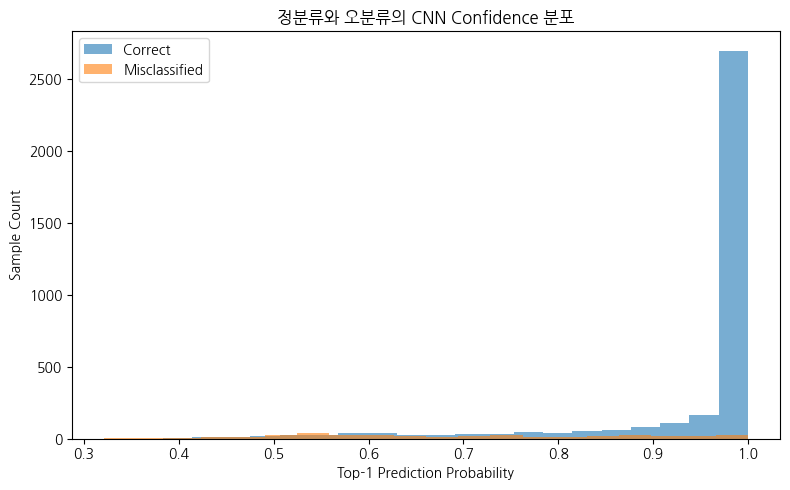

In [244]:
# 정분류 / 오분류 Top-1 Confidence 분포

correct_confidence = (
    prediction_df.loc[
        prediction_df["correct"],
        "top1_prob"
    ]
)


error_confidence = (
    prediction_df.loc[
        ~prediction_df["correct"],
        "top1_prob"
    ]
)


plt.figure(
    figsize=(8, 5)
)

plt.hist(
    correct_confidence,
    bins=20,
    alpha=0.6,
    label="Correct"
)

plt.hist(
    error_confidence,
    bins=20,
    alpha=0.6,
    label="Misclassified"
)

plt.xlabel(
    "Top-1 Prediction Probability"
)

plt.ylabel(
    "Sample Count"
)

plt.title(
    "정분류와 오분류의 CNN Confidence 분포"
)

plt.legend()

plt.tight_layout()
plt.show()

## Step 2-3. 오분류 구조 분석

전체 Test Set에서 발생한 오분류를 실제 클래스와 CNN 예측 클래스의 조합으로 분해한다.

예를 들어 실제 Scratch 웨이퍼를 Loc으로 분류한 경우를 `Scratch → Loc` 오류로 정의한다.

각 오분류 조합에 대해 다음 정보를 계산한다.

- 오분류 샘플 수
- 해당 오류의 평균 Top-1 예측 확률
- 평균 Confidence Margin
- 평균 Prediction Entropy

이를 통해 단순히 오류 개수만 확인하는 것이 아니라, CNN이 반복적으로 혼동하는 클래스 조합과 해당 오류에서 모델이 얼마나 강하게 잘못 판단했는지를 함께 분석한다.

In [245]:
# Step 2-3. 주요 오분류 Pair 분석

error_df = (
    prediction_df[
        ~prediction_df["correct"]
    ]
    .copy()
)


error_df["error_pair"] = (
    error_df["true_label"]
    + " → "
    + error_df["pred_label"]
)


error_pair_summary_df = (
    error_df
    .groupby(
        [
            "true_label",
            "pred_label",
            "error_pair"
        ],
        as_index=False
    )
    .agg(
        error_count=(
            "sample_pos",
            "count"
        ),

        mean_top1_prob=(
            "top1_prob",
            "mean"
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        ),

        mean_margin=(
            "confidence_margin",
            "mean"
        ),

        median_margin=(
            "confidence_margin",
            "median"
        ),

        mean_entropy=(
            "normalized_entropy",
            "mean"
        )
    )
)


error_pair_summary_df = (
    error_pair_summary_df
    .sort_values(
        "error_count",
        ascending=False
    )
    .reset_index(drop=True)
)


error_pair_summary_df[
    "error_ratio"
] = (
    error_pair_summary_df[
        "error_count"
    ]
    /
    len(error_df)
)


print(
    "=== 주요 CNN 오분류 Pair ==="
)

print(
    "전체 오분류:",
    len(error_df)
)


display(
    error_pair_summary_df.head(20)
    .style.format({
        "error_ratio": "{:.4f}",
        "mean_top1_prob": "{:.4f}",
        "median_top1_prob": "{:.4f}",
        "mean_margin": "{:.4f}",
        "median_margin": "{:.4f}",
        "mean_entropy": "{:.4f}"
    })
)

=== 주요 CNN 오분류 Pair ===
전체 오분류: 375


,true_label,pred_label,error_pair,error_count,mean_top1_prob,median_top1_prob,mean_margin,median_margin,mean_entropy,error_ratio
0,Scratch,Loc,Scratch → Loc,78,0.6663,0.6521,0.3805,0.3569,0.3396,0.2080
1,Loc,Edge-Loc,Loc → Edge-Loc,63,0.7460,0.7508,0.5221,0.5110,0.2701,0.1680
2,Edge-Loc,Edge-Ring,Edge-Loc → Edge-Ring,29,0.7743,0.7747,0.5496,0.5493,0.2223,0.0773
3,Edge-Ring,Edge-Loc,Edge-Ring → Edge-Loc,29,0.7116,0.7236,0.4479,0.4472,0.2757,0.0773
4,Scratch,Edge-Loc,Scratch → Edge-Loc,26,0.6930,0.6437,0.4839,0.3777,0.3415,0.0693
5,Loc,Center,Loc → Center,25,0.7484,0.7520,0.5296,0.5143,0.2727,0.0667
6,Loc,Scratch,Loc → Scratch,23,0.5351,0.5211,0.2080,0.1539,0.4627,0.0613
7,Edge-Loc,Loc,Edge-Loc → Loc,21,0.6677,0.5997,0.3685,0.2745,0.3173,0.0560
8,Edge-Loc,Random,Edge-Loc → Random,10,0.7087,0.7284,0.4736,0.5388,0.3298,0.0267
9,Random,Loc,Random → Loc,10,0.7968,0.8957,0.6150,0.8312,0.2248,0.0267


In [246]:
# Step 2-4. 오분류에서 실제 라벨이 2순위였는지 확인

error_df[
    "true_is_second_choice"
] = (
    error_df["true_idx"]
    ==
    error_df["second_idx"]
)


second_choice_summary = (
    error_df[
        "true_is_second_choice"
    ]
    .value_counts()
    .rename_axis(
        "true_is_second_choice"
    )
    .reset_index(
        name="sample_count"
    )
)


second_choice_summary[
    "sample_ratio"
] = (
    second_choice_summary[
        "sample_count"
    ]
    /
    len(error_df)
)


print(
    "=== 오분류에서 True Label의 2순위 여부 ==="
)

display(
    second_choice_summary.style.format({
        "sample_ratio": "{:.4f}"
    })
)


true_second_count = int(
    error_df[
        "true_is_second_choice"
    ].sum()
)


print(
    f"\n전체 오분류 {len(error_df)}개 중 "
    f"{true_second_count}개에서 "
    f"실제 라벨이 CNN의 2순위 예측이었습니다."
)

print(
    "비율:",
    f"{true_second_count / len(error_df):.2%}"
)

=== 오분류에서 True Label의 2순위 여부 ===


,true_is_second_choice,sample_count,sample_ratio
0,True,300,0.8000
1,False,75,0.2000



전체 오분류 375개 중 300개에서 실제 라벨이 CNN의 2순위 예측이었습니다.
비율: 80.00%


In [247]:
# Step 2-5. High-Confidence Misclassification

HIGH_CONFIDENCE_THRESHOLD = 0.90


error_df[
    "high_confidence_error"
] = (
    error_df["top1_prob"]
    >=
    HIGH_CONFIDENCE_THRESHOLD
)


high_confidence_error_df = (
    error_df[
        error_df[
            "high_confidence_error"
        ]
    ]
    .copy()
)


high_confidence_error_df = (
    high_confidence_error_df
    .sort_values(
        "top1_prob",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "=== High-Confidence Misclassification ==="
)

print(
    "Confidence 기준:",
    HIGH_CONFIDENCE_THRESHOLD
)

print(
    "전체 오분류:",
    len(error_df)
)

print(
    "High-confidence 오분류:",
    len(
        high_confidence_error_df
    )
)

print(
    "오분류 중 비율:",
    f"{len(high_confidence_error_df) / len(error_df):.2%}"
)


display_columns = [
    "sample_pos",
    "lot_name",
    "wafer_index",
    "true_label",
    "pred_label",
    "top1_prob",
    "second_label",
    "second_prob",
    "confidence_margin",
    "normalized_entropy",
    "true_is_second_choice"
]


display(
    high_confidence_error_df[
        display_columns
    ]
    .head(20)
    .style.format({
        "top1_prob": "{:.4f}",
        "second_prob": "{:.4f}",
        "confidence_margin": "{:.4f}",
        "normalized_entropy": "{:.4f}"
    })
)

=== High-Confidence Misclassification ===
Confidence 기준: 0.9
전체 오분류: 375
High-confidence 오분류: 59
오분류 중 비율: 15.73%


,sample_pos,lot_name,wafer_index,true_label,pred_label,top1_prob,second_label,second_prob,confidence_margin,normalized_entropy,true_is_second_choice
0,112,lot2157,11.000000,Scratch,Edge-Ring,1.0000,Edge-Loc,0.0000,1.0000,0.0000,False
1,1018,lot14742,10.000000,Loc,Edge-Loc,0.9999,Loc,0.0001,0.9997,0.0007,True
2,2180,lot30429,24.000000,Scratch,Edge-Loc,0.9977,Edge-Ring,0.0015,0.9962,0.0085,False
3,2999,lot43552,10.000000,Loc,Edge-Loc,0.9974,Edge-Ring,0.0018,0.9956,0.0095,False
4,2985,lot43481,2.000000,Edge-Ring,Edge-Loc,0.9973,Edge-Ring,0.0027,0.9946,0.0091,True
5,879,lot13921,6.000000,Random,Loc,0.9946,Center,0.0032,0.9914,0.0186,False
6,2881,lot42441,23.000000,Loc,Edge-Loc,0.9945,Scratch,0.0043,0.9902,0.0182,False
7,2222,lot33286,18.000000,Edge-Loc,Loc,0.9939,Edge-Loc,0.0061,0.9879,0.0178,True
8,3206,lot44268,21.000000,Edge-Loc,Edge-Ring,0.9936,Edge-Loc,0.0064,0.9871,0.0188,True
9,2939,lot42858,13.000000,Edge-Ring,Edge-Loc,0.9933,Edge-Ring,0.0065,0.9868,0.0201,True


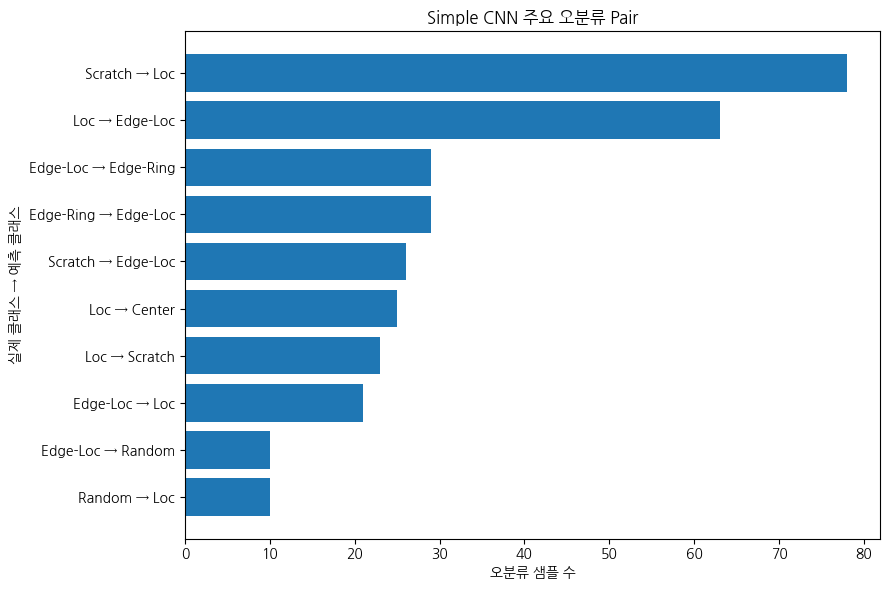

In [248]:
# Step 2-6. 주요 오분류 Pair 시각화

top_error_pairs = (
    error_pair_summary_df
    .head(10)
    .copy()
)


plt.figure(
    figsize=(9, 6)
)


plt.barh(
    top_error_pairs["error_pair"][::-1],
    top_error_pairs["error_count"][::-1]
)


plt.xlabel(
    "오분류 샘플 수"
)

plt.ylabel(
    "실제 클래스 → 예측 클래스"
)

plt.title(
    "Simple CNN 주요 오분류 Pair"
)


plt.tight_layout()
plt.show()

### 오분류 유형 구분

오분류는 CNN의 예측 확률과 실제 라벨의 2순위 포함 여부를 이용하여 네 가지 유형으로 구분한다.

1. **High-confidence / True not second**
   - CNN이 높은 확률로 잘못된 클래스를 확신
   - 실제 라벨이 2순위에도 존재하지 않음
   - 모델의 강한 오판, 비전형적 패턴 또는 라벨 검토 후보가 될 수 있음

2. **High-confidence / True second**
   - CNN은 잘못된 클래스를 강하게 선택했지만 실제 라벨도 2순위로 인식
   - 두 클래스의 특징을 동시에 포함할 가능성이 있음

3. **Lower-confidence / True second**
   - CNN이 두 클래스 사이에서 고민하다 최종 선택을 잘못한 경우
   - 클래스 경계 또는 유사 패턴 가능성이 높음

4. **Lower-confidence / True not second**
   - 모델의 확신도 낮고 실제 라벨도 주요 대안으로 인식하지 못한 경우
   - 복잡하거나 비전형적인 패턴일 가능성이 있음

이 구분은 라벨 오류를 확정하기 위한 것이 아니라 이후 상세 분석의 우선순위를 설정하기 위한 것이다.

In [249]:
# 오분류 진단 유형 생성

error_df["error_diagnostic_type"] = np.select(

    [
        (
            error_df["high_confidence_error"]
            &
            ~error_df["true_is_second_choice"]
        ),

        (
            error_df["high_confidence_error"]
            &
            error_df["true_is_second_choice"]
        ),

        (
            ~error_df["high_confidence_error"]
            &
            error_df["true_is_second_choice"]
        ),

        (
            ~error_df["high_confidence_error"]
            &
            ~error_df["true_is_second_choice"]
        )
    ],

    [
        "1. High-confidence / True not second",
        "2. High-confidence / True second",
        "3. Lower-confidence / True second",
        "4. Lower-confidence / True not second"
    ],

    default="Unknown"
)


error_diagnostic_summary_df = (
    error_df
    .groupby(
        "error_diagnostic_type",
        as_index=False
    )
    .agg(
        sample_count=(
            "sample_pos",
            "count"
        ),

        mean_top1_prob=(
            "top1_prob",
            "mean"
        ),

        mean_margin=(
            "confidence_margin",
            "mean"
        ),

        mean_entropy=(
            "normalized_entropy",
            "mean"
        )
    )
)


error_diagnostic_summary_df[
    "sample_ratio"
] = (
    error_diagnostic_summary_df[
        "sample_count"
    ]
    /
    len(error_df)
)


error_diagnostic_summary_df = (
    error_diagnostic_summary_df
    .sort_values(
        "error_diagnostic_type"
    )
    .reset_index(drop=True)
)


print(
    "=== CNN 오분류 진단 유형 ==="
)


display(
    error_diagnostic_summary_df.style.format({
        "sample_ratio": "{:.4f}",
        "mean_top1_prob": "{:.4f}",
        "mean_margin": "{:.4f}",
        "mean_entropy": "{:.4f}"
    })
)

=== CNN 오분류 진단 유형 ===


,error_diagnostic_type,sample_count,mean_top1_prob,mean_margin,mean_entropy,sample_ratio
0,1. High-confidence / True not second,18,0.9672,0.9443,0.0731,0.0480
1,2. High-confidence / True second,41,0.9480,0.9038,0.1020,0.1093
2,3. Lower-confidence / True second,259,0.6520,0.3534,0.3493,0.6907
3,4. Lower-confidence / True not second,57,0.6116,0.3442,0.4098,0.1520


In [250]:
# High-confidence error의 주요 오분류 Pair

high_confidence_pair_df = (
    high_confidence_error_df
    .groupby(
        [
            "true_label",
            "pred_label"
        ],
        as_index=False
    )
    .agg(
        sample_count=(
            "sample_pos",
            "count"
        ),

        mean_top1_prob=(
            "top1_prob",
            "mean"
        ),

        true_second_count=(
            "true_is_second_choice",
            "sum"
        )
    )
)


high_confidence_pair_df[
    "error_pair"
] = (
    high_confidence_pair_df["true_label"]
    + " → "
    + high_confidence_pair_df["pred_label"]
)


high_confidence_pair_df = (
    high_confidence_pair_df
    .sort_values(
        "sample_count",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "=== High-Confidence Error Pair ==="
)


display(
    high_confidence_pair_df.head(15)
    .style.format({
        "mean_top1_prob": "{:.4f}"
    })
)

=== High-Confidence Error Pair ===


,true_label,pred_label,sample_count,mean_top1_prob,true_second_count,error_pair
0,Loc,Edge-Loc,16,0.9473,10,Loc → Edge-Loc
1,Edge-Loc,Edge-Ring,7,0.9636,7,Edge-Loc → Edge-Ring
2,Loc,Center,6,0.9637,6,Loc → Center
3,Scratch,Edge-Loc,5,0.9622,2,Scratch → Edge-Loc
4,Scratch,Loc,5,0.9371,5,Scratch → Loc
5,Random,Loc,5,0.9432,2,Random → Loc
6,Edge-Ring,Edge-Loc,5,0.9483,4,Edge-Ring → Edge-Loc
7,Scratch,Center,2,0.9468,0,Scratch → Center
8,Donut,Loc,2,0.9399,2,Donut → Loc
9,Edge-Loc,Loc,1,0.9939,1,Edge-Loc → Loc


In [251]:
# Step 2 주요 결과 변수 정리

step2_prediction_df = (
    prediction_df.copy()
)


step2_error_df = (
    error_df.copy()
)


step2_error_pair_summary_df = (
    error_pair_summary_df.copy()
)


step2_high_confidence_error_df = (
    high_confidence_error_df.copy()
)


step2_error_diagnostic_summary_df = (
    error_diagnostic_summary_df.copy()
)


print(
    "=== Step 2 저장 변수 ==="
)

print(
    "step2_prediction_df:",
    step2_prediction_df.shape
)

print(
    "step2_error_df:",
    step2_error_df.shape
)

print(
    "step2_error_pair_summary_df:",
    step2_error_pair_summary_df.shape
)

print(
    "step2_high_confidence_error_df:",
    step2_high_confidence_error_df.shape
)

print(
    "step2_error_diagnostic_summary_df:",
    step2_error_diagnostic_summary_df.shape
)

=== Step 2 저장 변수 ===
step2_prediction_df: (3911, 16)
step2_error_df: (375, 20)
step2_error_pair_summary_df: (31, 10)
step2_high_confidence_error_df: (59, 19)
step2_error_diagnostic_summary_df: (4, 6)


## Step 2 결과 요약

최종 Simple CNN은 Test Set 3,911개 중 3,553개를 올바르게 분류하였으며 358개의 오분류가 발생하였다.

오분류는 모든 클래스에 균등하게 발생하지 않았으며, 특히 다음 클래스 조합에서 반복적인 혼동이 확인되었다.

- Scratch → Loc
- Loc → Edge-Loc
- Loc → Scratch
- Edge-Loc → Edge-Ring
- Edge-Ring → Edge-Loc
- Scratch → Edge-Loc

또한 전체 오분류 358개 중 약 78.5%에서 실제 정답 클래스가 CNN의 두 번째 예측 후보로 나타났다.

이는 상당수의 오류가 완전히 무관한 클래스로의 오판이라기보다 유사한 두 결함 패턴 사이의 경계에서 발생하고 있음을 시사한다.

반면 약 16.8%의 오류에서는 CNN이 90% 이상의 높은 확률로 잘못된 클래스를 선택하였다.

따라서 이후 분석에서는 단순히 모든 오분류를 동일하게 처리하지 않고, 모델의 불확실성이 큰 경계형 오류와 높은 확신을 가진 강한 오판을 구분하여 분석한다.

# Step 3. 웨이퍼 맵 공간 특징(Spatial Feature) 추출

CNN의 예측 결과만으로는 각 결함 클래스가 실제 웨이퍼 상에서 어떤 공간적 구조를 가지는지 직접 설명하기 어렵다.

따라서 이번 단계에서는 원본 Wafer Map으로부터 결함의 위치, 분포, 군집 및 방향성을 정량적인 Spatial Feature로 변환한다.

추출하는 특징은 크게 다음 세 종류로 구성한다.

### 1. 기본 결함 특징
- 웨이퍼 크기
- 유효 die 개수
- 결함 die 개수
- 전체 die 중 결함 비율

### 2. Radial Feature
웨이퍼 중심에서 결함이 얼마나 떨어져 있는지를 이용하여 Center / Middle / Edge 영역의 결함 분포를 계산한다.

- Center Ratio
- Middle Ratio
- Edge Ratio
- 영역별 Defect Density
- Mean Radius
- Radius Standard Deviation

### 3. Cluster / Shape Feature
결함 die의 연결 구조와 방향성을 분석하여 결함이 하나의 큰 군집을 형성하는지, 여러 군집으로 분산되어 있는지, 혹은 Scratch처럼 선형적인 형태를 가지는지 측정한다.

이렇게 추출한 Spatial Feature는 이후 클래스별 결함 패턴 비교, 오분류 원인 분석, 클래스 대표 프로파일 생성 및 데이터 품질 검증에 사용한다.

In [252]:
# Step 3-1. 기본 Wafer Spatial Feature 추출

basic_feature_rows = []


for sample_pos, wafer_map in enumerate(
    test_df["waferMap"]
):

    wafer_map = np.asarray(
        wafer_map
    )


    # ----------------------------------------------
    # Wafer 크기
    # ----------------------------------------------

    wafer_height, wafer_width = (
        wafer_map.shape
    )


    # ----------------------------------------------
    # 유효 die와 결함 die
    # ----------------------------------------------

    valid_die_mask = (
        wafer_map > 0
    )

    defect_mask = (
        wafer_map == 2
    )


    valid_die_count = int(
        valid_die_mask.sum()
    )

    defect_count = int(
        defect_mask.sum()
    )


    # ----------------------------------------------
    # 전체 유효 die 중 결함 비율
    # ----------------------------------------------

    defect_ratio = (
        defect_count
        / valid_die_count
        if valid_die_count > 0
        else np.nan
    )


    basic_feature_rows.append({
        "sample_pos": sample_pos,
        "wafer_height": wafer_height,
        "wafer_width": wafer_width,
        "valid_die_count": valid_die_count,
        "defect_count": defect_count,
        "defect_ratio": defect_ratio
    })


basic_features_df = pd.DataFrame(
    basic_feature_rows
)


# Prediction Table과 연결
prediction_df = prediction_df.merge(
    basic_features_df,
    on="sample_pos",
    how="left",
    validate="one_to_one"
)


print(
    "=== 기본 Spatial Feature ==="
)

print(
    "Prediction DataFrame Shape:",
    prediction_df.shape
)


display(
    prediction_df[
        [
            "sample_pos",
            "true_label",
            "pred_label",
            "wafer_height",
            "wafer_width",
            "valid_die_count",
            "defect_count",
            "defect_ratio"
        ]
    ]
    .head()
    .style.format({
        "defect_ratio": "{:.4f}"
    })
)

=== 기본 Spatial Feature ===
Prediction DataFrame Shape: (3911, 21)


,sample_pos,true_label,pred_label,wafer_height,wafer_width,valid_die_count,defect_count,defect_ratio
0,0,Scratch,Loc,26,26,533,121,0.2270
1,1,Edge-Loc,Edge-Loc,26,26,533,108,0.2026
2,2,Loc,Loc,26,26,533,144,0.2702
3,3,Edge-Loc,Edge-Loc,26,26,533,219,0.4109
4,4,Edge-Loc,Edge-Loc,26,26,533,239,0.4484


## Step 3-2. Radial Feature 정의

Center, Donut, Edge-Ring과 같은 결함은 웨이퍼 중심으로부터의 상대적인 위치가 중요한 특징이다.

원본 Wafer Map마다 크기가 다르기 때문에 단순한 픽셀 거리 대신 **Normalized Radius**를 사용한다.

먼저 실제 유효 die들의 평균 좌표를 이용하여 웨이퍼 중심을 계산한다.

그 후 각 die와 웨이퍼 중심 사이의 거리를 계산하고, 가장 멀리 위치한 유효 die의 거리로 나누어 0~1 범위로 정규화한다.

Normalized Radius를 기준으로 웨이퍼를 다음 세 영역으로 구분한다.

- **Center Zone:** Radius ≤ 0.33
- **Middle Zone:** 0.33 < Radius < 0.75
- **Edge Zone:** Radius ≥ 0.75

각 영역에 존재하는 결함 die의 비율과 밀도를 계산하여 결함의 공간적 위치를 정량적으로 표현한다.

=== Radial Feature 확인 ===
Sample: 0
True Label: Scratch
Predicted Label: Loc

Center Ratio: 0.0661
Middle Ratio: 0.4132
Edge Ratio: 0.5207
Mean Radius: 0.7287
Radius Std: 0.2362


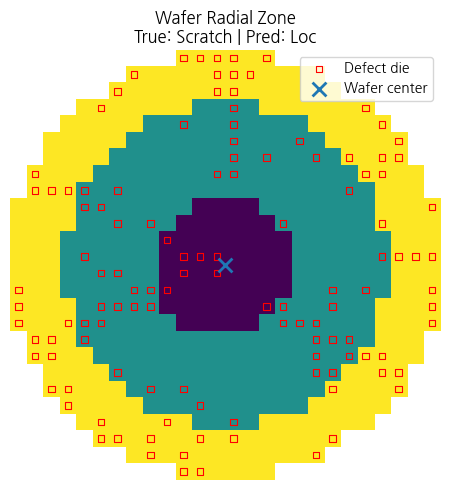

In [253]:
# Step 3-2. 한 Wafer에서 Radial Zone 확인

sample_pos = 0


sample_map = np.asarray(
    test_df.iloc[
        sample_pos
    ]["waferMap"]
)


valid_die_mask = (
    sample_map > 0
)

defect_mask = (
    sample_map == 2
)


# ----------------------------------------------
# 격자 좌표
# ----------------------------------------------

row_grid, col_grid = np.indices(
    sample_map.shape
)


valid_rows, valid_cols = np.where(
    valid_die_mask
)


# ----------------------------------------------
# 실제 유효 die 좌표 기반 중심
# ----------------------------------------------

center_row = (
    valid_rows.mean()
)

center_col = (
    valid_cols.mean()
)


# ----------------------------------------------
# 중심으로부터 거리
# ----------------------------------------------

radial_distance = np.sqrt(
    (row_grid - center_row) ** 2
    +
    (col_grid - center_col) ** 2
)


max_valid_radius = (
    radial_distance[
        valid_die_mask
    ].max()
)


# ----------------------------------------------
# 0~1 정규화 Radius
# ----------------------------------------------

normalized_radius = np.full(
    sample_map.shape,
    np.nan,
    dtype=float
)


normalized_radius[
    valid_die_mask
] = (
    radial_distance[
        valid_die_mask
    ]
    /
    max_valid_radius
)


# ----------------------------------------------
# Radial Zone
# ----------------------------------------------

CENTER_THRESHOLD = 0.33
EDGE_THRESHOLD = 0.75


center_zone = (
    valid_die_mask
    &
    (
        normalized_radius
        <= CENTER_THRESHOLD
    )
)


middle_zone = (
    valid_die_mask
    &
    (
        normalized_radius
        > CENTER_THRESHOLD
    )
    &
    (
        normalized_radius
        < EDGE_THRESHOLD
    )
)


edge_zone = (
    valid_die_mask
    &
    (
        normalized_radius
        >= EDGE_THRESHOLD
    )
)


# ----------------------------------------------
# 영역별 개수
# ----------------------------------------------

center_valid_count = int(
    center_zone.sum()
)

middle_valid_count = int(
    middle_zone.sum()
)

edge_valid_count = int(
    edge_zone.sum()
)


center_defect_count = int(
    (
        defect_mask
        &
        center_zone
    ).sum()
)

middle_defect_count = int(
    (
        defect_mask
        &
        middle_zone
    ).sum()
)

edge_defect_count = int(
    (
        defect_mask
        &
        edge_zone
    ).sum()
)


total_defect_count = int(
    defect_mask.sum()
)


# ----------------------------------------------
# 전체 결함 중 위치별 비율
# ----------------------------------------------

center_ratio = (
    center_defect_count
    / total_defect_count
)

middle_ratio = (
    middle_defect_count
    / total_defect_count
)

edge_ratio = (
    edge_defect_count
    / total_defect_count
)


# ----------------------------------------------
# 해당 영역에서 결함이 차지하는 밀도
# ----------------------------------------------

center_defect_density = (
    center_defect_count
    / center_valid_count
)


middle_defect_density = (
    middle_defect_count
    / middle_valid_count
)


edge_defect_density = (
    edge_defect_count
    / edge_valid_count
)


# ----------------------------------------------
# 결함 Radius 분포
# ----------------------------------------------

defect_radii = (
    normalized_radius[
        defect_mask
    ]
)


mean_radius = float(
    defect_radii.mean()
)

radius_std = float(
    defect_radii.std()
)


# ----------------------------------------------
# 검증
# ----------------------------------------------

assert (
    center_valid_count
    + middle_valid_count
    + edge_valid_count
    ==
    int(
        valid_die_mask.sum()
    )
)


assert (
    center_defect_count
    + middle_defect_count
    + edge_defect_count
    ==
    total_defect_count
)


print(
    "=== Radial Feature 확인 ==="
)

print(
    "Sample:",
    sample_pos
)

print(
    "True Label:",
    prediction_df.loc[
        sample_pos,
        "true_label"
    ]
)

print(
    "Predicted Label:",
    prediction_df.loc[
        sample_pos,
        "pred_label"
    ]
)

print()

print(
    "Center Ratio:",
    round(
        center_ratio,
        4
    )
)

print(
    "Middle Ratio:",
    round(
        middle_ratio,
        4
    )
)

print(
    "Edge Ratio:",
    round(
        edge_ratio,
        4
    )
)

print(
    "Mean Radius:",
    round(
        mean_radius,
        4
    )
)

print(
    "Radius Std:",
    round(
        radius_std,
        4
    )
)


# ----------------------------------------------
# Radial Zone 시각화
# ----------------------------------------------

zone_map = np.full(
    sample_map.shape,
    np.nan
)


zone_map[
    center_zone
] = 0

zone_map[
    middle_zone
] = 1

zone_map[
    edge_zone
] = 2


defect_rows, defect_cols = np.where(
    defect_mask
)


plt.figure(
    figsize=(6, 5)
)


plt.imshow(
    zone_map,
    cmap="viridis",
    interpolation="nearest"
)


plt.scatter(
    defect_cols,
    defect_rows,
    marker="s",
    s=22,
    facecolors="none",
    edgecolors="red",
    linewidths=0.8,
    label="Defect die"
)


plt.scatter(
    center_col,
    center_row,
    marker="x",
    s=100,
    linewidths=2,
    label="Wafer center"
)


plt.title(
    "Wafer Radial Zone\n"
    f"True: "
    f"{prediction_df.loc[sample_pos, 'true_label']} | "
    f"Pred: "
    f"{prediction_df.loc[sample_pos, 'pred_label']}"
)


plt.axis(
    "off"
)

plt.legend()

plt.tight_layout()

plt.show()

## Step 3-3. 전체 Test Wafer의 Radial Feature 추출

앞에서는 하나의 웨이퍼를 이용하여 Radial Feature의 계산 과정을 확인하였다.

이번에는 동일한 계산을 Test Set의 3,911개 웨이퍼 전체에 적용한다.

각 웨이퍼에 대해 다음 특징을 계산한다.

- Center / Middle / Edge 영역의 유효 die 개수
- Center / Middle / Edge 영역의 결함 die 개수
- Center / Middle / Edge Ratio
- Center / Middle / Edge Defect Density
- 결함 die의 평균 정규화 반경
- 결함 die 반경의 표준편차

특히 `Ratio`와 `Density`는 서로 다른 의미를 가진다.

- **Ratio:** 전체 결함 중 특정 영역에 존재하는 결함의 비율
- **Density:** 특정 영역의 전체 die 중 결함 die가 차지하는 비율

이를 통해 결함이 단순히 어느 위치에 많은지뿐만 아니라, 해당 영역이 얼마나 강하게 오염 또는 결함화되어 있는지도 표현한다.

In [254]:
# Step 3-3. Radial Feature 추출 함수

CENTER_THRESHOLD = 0.33
EDGE_THRESHOLD = 0.75


def extract_radial_features(
    wafer_map,
    center_threshold=CENTER_THRESHOLD,
    edge_threshold=EDGE_THRESHOLD
):
    """
    하나의 원본 wafer map에서
    radial spatial feature를 계산한다.
    """

    wafer_map = np.asarray(
        wafer_map
    )


    # ----------------------------------------------
    # 유효 die / 결함 die
    # ----------------------------------------------

    valid_die_mask = (
        wafer_map > 0
    )

    defect_mask = (
        wafer_map == 2
    )


    valid_die_count = int(
        valid_die_mask.sum()
    )

    defect_count = int(
        defect_mask.sum()
    )


    # 안전 처리
    if valid_die_count == 0:

        return {
            "max_valid_radius": np.nan,

            "center_valid_count": 0,
            "middle_valid_count": 0,
            "edge_valid_count": 0,

            "center_defect_count": 0,
            "middle_defect_count": 0,
            "edge_defect_count": 0,

            "center_ratio": np.nan,
            "middle_ratio": np.nan,
            "edge_ratio": np.nan,

            "center_defect_density": np.nan,
            "middle_defect_density": np.nan,
            "edge_defect_density": np.nan,

            "mean_radius": np.nan,
            "radius_std": np.nan
        }


    # ----------------------------------------------
    # 실제 유효 die 좌표를 이용한 wafer 중심
    # ----------------------------------------------

    row_grid, col_grid = np.indices(
        wafer_map.shape
    )


    valid_rows, valid_cols = np.where(
        valid_die_mask
    )


    center_row = (
        valid_rows.mean()
    )

    center_col = (
        valid_cols.mean()
    )


    # ----------------------------------------------
    # 중심으로부터 거리
    # ----------------------------------------------

    radial_distance = np.sqrt(
        (row_grid - center_row) ** 2
        +
        (col_grid - center_col) ** 2
    )


    max_valid_radius = float(
        radial_distance[
            valid_die_mask
        ].max()
    )


    # ----------------------------------------------
    # Normalized Radius
    # ----------------------------------------------

    normalized_radius = np.full(
        wafer_map.shape,
        np.nan,
        dtype=float
    )


    normalized_radius[
        valid_die_mask
    ] = (
        radial_distance[
            valid_die_mask
        ]
        /
        max_valid_radius
    )


    # ----------------------------------------------
    # Center / Middle / Edge Zone
    # ----------------------------------------------

    center_zone = (
        valid_die_mask
        &
        (
            normalized_radius
            <= center_threshold
        )
    )


    middle_zone = (
        valid_die_mask
        &
        (
            normalized_radius
            > center_threshold
        )
        &
        (
            normalized_radius
            < edge_threshold
        )
    )


    edge_zone = (
        valid_die_mask
        &
        (
            normalized_radius
            >= edge_threshold
        )
    )


    # ----------------------------------------------
    # 영역별 valid die
    # ----------------------------------------------

    center_valid_count = int(
        center_zone.sum()
    )

    middle_valid_count = int(
        middle_zone.sum()
    )

    edge_valid_count = int(
        edge_zone.sum()
    )


    # ----------------------------------------------
    # 영역별 defect die
    # ----------------------------------------------

    center_defect_count = int(
        (
            defect_mask
            &
            center_zone
        ).sum()
    )


    middle_defect_count = int(
        (
            defect_mask
            &
            middle_zone
        ).sum()
    )


    edge_defect_count = int(
        (
            defect_mask
            &
            edge_zone
        ).sum()
    )


    # ----------------------------------------------
    # 전체 defect 중 각 영역의 비율
    # ----------------------------------------------

    if defect_count > 0:

        center_ratio = (
            center_defect_count
            / defect_count
        )

        middle_ratio = (
            middle_defect_count
            / defect_count
        )

        edge_ratio = (
            edge_defect_count
            / defect_count
        )

    else:

        center_ratio = np.nan
        middle_ratio = np.nan
        edge_ratio = np.nan


    # ----------------------------------------------
    # 각 영역 내부의 defect density
    # ----------------------------------------------

    center_defect_density = (
        center_defect_count
        / center_valid_count
        if center_valid_count > 0
        else np.nan
    )


    middle_defect_density = (
        middle_defect_count
        / middle_valid_count
        if middle_valid_count > 0
        else np.nan
    )


    edge_defect_density = (
        edge_defect_count
        / edge_valid_count
        if edge_valid_count > 0
        else np.nan
    )


    # ----------------------------------------------
    # 결함의 radial distribution
    # ----------------------------------------------

    defect_radii = (
        normalized_radius[
            defect_mask
        ]
    )


    if defect_count > 0:

        mean_radius = float(
            defect_radii.mean()
        )

        radius_std = float(
            defect_radii.std()
        )

    else:

        mean_radius = np.nan
        radius_std = np.nan


    return {
        "max_valid_radius": max_valid_radius,

        "center_valid_count": center_valid_count,
        "middle_valid_count": middle_valid_count,
        "edge_valid_count": edge_valid_count,

        "center_defect_count": center_defect_count,
        "middle_defect_count": middle_defect_count,
        "edge_defect_count": edge_defect_count,

        "center_ratio": center_ratio,
        "middle_ratio": middle_ratio,
        "edge_ratio": edge_ratio,

        "center_defect_density": center_defect_density,
        "middle_defect_density": middle_defect_density,
        "edge_defect_density": edge_defect_density,

        "mean_radius": mean_radius,
        "radius_std": radius_std
    }


print(
    "✓ Radial Feature 함수 생성 완료"
)

✓ Radial Feature 함수 생성 완료


In [255]:
# 전체 Test wafer에 Radial Feature 적용

radial_feature_rows = []


for sample_pos, wafer_map in enumerate(
    test_df["waferMap"]
):

    features = extract_radial_features(
        wafer_map
    )


    features[
        "sample_pos"
    ] = sample_pos


    radial_feature_rows.append(
        features
    )


radial_features_df = pd.DataFrame(
    radial_feature_rows
)


# --------------------------------------------------
# prediction_df와 연결
# --------------------------------------------------

radial_columns = [
    column
    for column in radial_features_df.columns
    if column != "sample_pos"
]


# 재실행 시 같은 컬럼 중복 방지
prediction_df = prediction_df.drop(
    columns=[
        column
        for column in radial_columns
        if column in prediction_df.columns
    ],
    errors="ignore"
)


prediction_df = prediction_df.merge(
    radial_features_df,
    on="sample_pos",
    how="left",
    validate="one_to_one"
)


print(
    "=== 전체 Radial Feature 추출 완료 ==="
)

print(
    "Radial Feature DataFrame:",
    radial_features_df.shape
)

print(
    "Prediction DataFrame:",
    prediction_df.shape
)

=== 전체 Radial Feature 추출 완료 ===
Radial Feature DataFrame: (3911, 16)
Prediction DataFrame: (3911, 36)


In [256]:
# Radial Feature 계산 검증

# --------------------------------------------------
# 1. Center + Middle + Edge Ratio = 1
# --------------------------------------------------

ratio_sum = (
    prediction_df[
        "center_ratio"
    ]
    +
    prediction_df[
        "middle_ratio"
    ]
    +
    prediction_df[
        "edge_ratio"
    ]
)


assert np.allclose(
    ratio_sum,
    1.0,
    atol=1e-6
)


# --------------------------------------------------
# 2. 영역별 defect 합 = 전체 defect
# --------------------------------------------------

zone_defect_sum = (
    prediction_df[
        "center_defect_count"
    ]
    +
    prediction_df[
        "middle_defect_count"
    ]
    +
    prediction_df[
        "edge_defect_count"
    ]
)


assert (
    zone_defect_sum.values
    ==
    prediction_df[
        "defect_count"
    ].values
).all()


# --------------------------------------------------
# 3. Ratio / Density 범위 확인
# --------------------------------------------------

ratio_columns = [
    "center_ratio",
    "middle_ratio",
    "edge_ratio",

    "center_defect_density",
    "middle_defect_density",
    "edge_defect_density",

    "mean_radius"
]


for column in ratio_columns:

    assert (
        prediction_df[
            column
        ]
        .between(
            0,
            1
        )
        .all()
    )


print(
    "✓ 모든 Radial Feature 검증 통과"
)

✓ 모든 Radial Feature 검증 통과


In [257]:
# 전체 Test Set의 Radial Feature 분포

radial_summary_columns = [
    "center_ratio",
    "middle_ratio",
    "edge_ratio",

    "center_defect_density",
    "middle_defect_density",
    "edge_defect_density",

    "mean_radius",
    "radius_std"
]


print(
    "=== Radial Feature Summary ==="
)


display(
    prediction_df[
        radial_summary_columns
    ]
    .describe()
    .round(4)
)


print(
    "\n=== 첫 5개 Wafer ==="
)


display(
    prediction_df[
        [
            "sample_pos",
            "true_label",
            "pred_label",
            "defect_ratio",

            "center_ratio",
            "middle_ratio",
            "edge_ratio",

            "mean_radius",
            "radius_std"
        ]
    ]
    .head()
    .style.format({
        "defect_ratio": "{:.4f}",
        "center_ratio": "{:.4f}",
        "middle_ratio": "{:.4f}",
        "edge_ratio": "{:.4f}",
        "mean_radius": "{:.4f}",
        "radius_std": "{:.4f}"
    })
)

=== Radial Feature Summary ===


,center_ratio,middle_ratio,edge_ratio,center_defect_density,middle_defect_density,edge_defect_density,mean_radius,radius_std
count,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000
mean,0.1058,0.2901,0.6041,0.1916,0.1214,0.2604,0.7341,0.2272
std,0.0902,0.1427,0.1907,0.2270,0.1308,0.1287,0.1069,0.0448
min,0.0000,0.0000,0.0400,0.0000,0.0000,0.0021,0.3924,0.0325
25%,0.0442,0.1686,0.4497,0.0458,0.0425,0.1775,0.6509,0.2005
50%,0.0726,0.2788,0.6207,0.0902,0.0742,0.2472,0.7453,0.2247
75%,0.1378,0.3774,0.7762,0.2267,0.1585,0.3317,0.8294,0.2509
max,0.6360,0.9231,1.0000,1.0000,1.0000,1.0000,0.9363,0.4083



=== 첫 5개 Wafer ===


,sample_pos,true_label,pred_label,defect_ratio,center_ratio,middle_ratio,edge_ratio,mean_radius,radius_std
0,0,Scratch,Loc,0.2270,0.0661,0.4132,0.5207,0.7287,0.2362
1,1,Edge-Loc,Edge-Loc,0.2026,0.0648,0.4167,0.5185,0.7178,0.2425
2,2,Loc,Loc,0.2702,0.1250,0.4931,0.3819,0.6381,0.2456
3,3,Edge-Loc,Edge-Loc,0.4109,0.0411,0.2466,0.7123,0.7853,0.1998
4,4,Edge-Loc,Edge-Loc,0.4484,0.0669,0.2594,0.6736,0.7645,0.2318


In [258]:
# 클래스별 Radial Feature 중앙값

class_radial_profile_df = (
    prediction_df
    .groupby(
        "true_label"
    )[
        [
            "center_ratio",
            "middle_ratio",
            "edge_ratio",
            "mean_radius",
            "radius_std"
        ]
    ]
    .median()
    .reindex(
        CLASS_NAMES
    )
)


print(
    "=== 클래스별 Median Radial Profile ==="
)


display(
    class_radial_profile_df.style.format(
        "{:.4f}"
    )
)

=== 클래스별 Median Radial Profile ===


,center_ratio,middle_ratio,edge_ratio,mean_radius,radius_std
true_label,,,,,
Center,0.2475,0.3226,0.4247,0.6053,0.2910
Donut,0.1417,0.5801,0.2676,0.5621,0.2422
Edge-Loc,0.0753,0.3071,0.6170,0.7406,0.2228
Edge-Ring,0.0453,0.1581,0.7944,0.8393,0.2034
Loc,0.1010,0.4255,0.4574,0.6770,0.2367
Near-full,0.1253,0.4949,0.3799,0.6334,0.2289
Random,0.1301,0.4629,0.4111,0.6412,0.2368
Scratch,0.0928,0.3647,0.5284,0.7058,0.2353


## Step 3-4. Cluster 및 Shape Feature 추출

Radial Feature는 결함이 웨이퍼의 어느 위치에 집중되어 있는지를 설명할 수 있지만, 결함의 형태 자체를 충분히 표현하지는 못한다.

예를 들어 Scratch와 Loc 결함은 비슷한 위치에 존재할 수 있지만, Scratch는 한 방향으로 길게 이어지는 선형 구조를 가지는 반면 Loc은 특정 영역에 국소적으로 모이는 형태를 보일 수 있다.

따라서 결함 die의 연결 관계를 이용하여 Cluster를 정의하고, 각 Cluster의 크기와 방향성을 정량화한다.

본 분석에서는 대각선 방향까지 연결된 것으로 판단하는 **8-connectivity**를 사용한다.

다음 특징을 계산한다.

- `cluster_count`: 전체 결함 Cluster의 개수
- `large_cluster_count`: 5개 이상의 defect die로 구성된 Cluster의 개수
- `normalized_cluster_count`: 결함 die 수 대비 Cluster 개수
- `largest_cluster_ratio`: 전체 결함 중 가장 큰 Cluster가 차지하는 비율
- `global_elongation`: 전체 결함 분포가 한 방향으로 늘어난 정도
- `largest_cluster_elongation`: 가장 큰 Cluster의 선형성
- `weighted_cluster_elongation`: 큰 Cluster들을 크기로 가중한 평균 선형성
- `linear_defect_ratio`: 선형적인 Cluster에 포함된 결함 die의 비율

Elongation 값은 0~1 범위로 정의하며, 1에 가까울수록 한 방향으로 길게 늘어난 형태를 의미한다.

크기가 너무 작은 Cluster는 우연한 배열에 의해 선형성이 과대평가될 수 있으므로, 5개 이상의 die로 구성된 Cluster만 주요 Shape 분석에 사용한다.

In [259]:
# Step 3-4. Cluster / Shape Feature 설정

from scipy.ndimage import label as connected_component_label


# 방향성 판단에 사용할 최소 Cluster 크기
MIN_CLUSTER_SIZE = 5

# Linear Cluster로 판단할 Elongation 기준
LINEARITY_THRESHOLD = 0.70

# 8-connectivity
connectivity_structure = np.ones(
    (3, 3),
    dtype=int
)


def calculate_elongation(rows, cols):
    """
    좌표 분포가 한 방향으로 얼마나 길게 늘어났는지 계산한다.

    0에 가까움:
        원형 또는 방향성이 약한 형태

    1에 가까움:
        한 방향으로 길게 늘어난 선형 형태
    """

    point_count = len(rows)


    if point_count < 2:
        return 0.0


    coordinates = np.column_stack(
        [rows, cols]
    )


    # 좌표의 공분산 행렬
    covariance_matrix = np.cov(
        coordinates,
        rowvar=False
    )


    # 고유값 계산
    eigenvalues = np.linalg.eigvalsh(
        covariance_matrix
    )


    # 부동소수점 오차에 의한 음수 방지
    eigenvalues = np.sort(
        np.maximum(
            eigenvalues,
            0
        )
    )


    minor_variance = float(
        eigenvalues[0]
    )

    major_variance = float(
        eigenvalues[-1]
    )


    if major_variance <= 0:
        return 0.0


    elongation = (
        1
        -
        minor_variance
        / major_variance
    )


    return float(
        elongation
    )


print("=== Cluster Feature 설정 ===")
print("Minimum Cluster Size:", MIN_CLUSTER_SIZE)
print("Linearity Threshold:", LINEARITY_THRESHOLD)
print("Connectivity: 8-direction")

print(
    "\n✓ Cluster / Elongation 설정 완료"
)

=== Cluster Feature 설정 ===
Minimum Cluster Size: 5
Linearity Threshold: 0.7
Connectivity: 8-direction

✓ Cluster / Elongation 설정 완료


=== Sample Cluster 확인 ===
Sample: 0
True Label: Scratch
Predicted Label: Loc
Defect Count: 121
Cluster Count: 24

=== 가장 큰 Cluster 10개 ===


,cluster_id,cluster_size,cluster_elongation
0,9,28,0.8766
1,13,20,0.7932
2,1,16,0.8071
3,3,9,0.5795
4,7,9,0.9155
5,12,4,1.0000
6,23,4,0.6992
7,2,3,1.0000
8,20,3,0.6667
9,21,3,0.9481


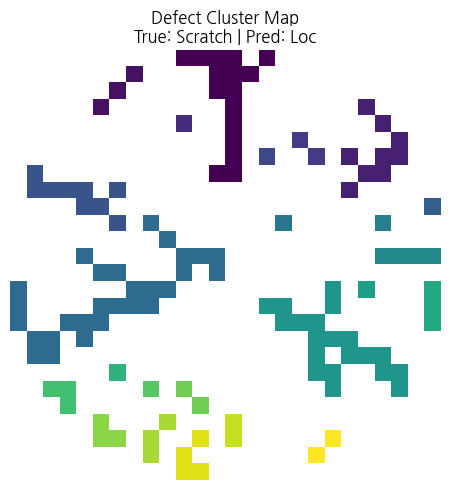

In [260]:
# 한 Wafer에서 Cluster 구조 확인

sample_pos = 0


sample_map = np.asarray(
    test_df.iloc[
        sample_pos
    ]["waferMap"]
)


defect_mask = (
    sample_map == 2
)


# --------------------------------------------------
# Connected Component
# --------------------------------------------------

cluster_map, cluster_count = (
    connected_component_label(
        defect_mask,
        structure=connectivity_structure
    )
)


cluster_records = []


for cluster_id in range(
    1,
    cluster_count + 1
):

    cluster_mask = (
        cluster_map == cluster_id
    )


    cluster_rows, cluster_cols = np.where(
        cluster_mask
    )


    cluster_size = int(
        cluster_mask.sum()
    )


    cluster_elongation = (
        calculate_elongation(
            cluster_rows,
            cluster_cols
        )
    )


    cluster_records.append({
        "cluster_id": cluster_id,
        "cluster_size": cluster_size,
        "cluster_elongation": cluster_elongation
    })


cluster_table_sample = pd.DataFrame(
    cluster_records
)


cluster_table_sample = (
    cluster_table_sample
    .sort_values(
        "cluster_size",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "=== Sample Cluster 확인 ==="
)

print(
    "Sample:",
    sample_pos
)

print(
    "True Label:",
    prediction_df.loc[
        sample_pos,
        "true_label"
    ]
)

print(
    "Predicted Label:",
    prediction_df.loc[
        sample_pos,
        "pred_label"
    ]
)

print(
    "Defect Count:",
    int(
        defect_mask.sum()
    )
)

print(
    "Cluster Count:",
    cluster_count
)


print(
    "\n=== 가장 큰 Cluster 10개 ==="
)

display(
    cluster_table_sample
    .head(10)
    .style.format({
        "cluster_elongation": "{:.4f}"
    })
)


# --------------------------------------------------
# Cluster Map 시각화
# --------------------------------------------------

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    np.where(
        defect_mask,
        cluster_map,
        np.nan
    ),
    interpolation="nearest"
)

plt.title(
    "Defect Cluster Map\n"
    f"True: "
    f"{prediction_df.loc[sample_pos, 'true_label']} | "
    f"Pred: "
    f"{prediction_df.loc[sample_pos, 'pred_label']}"
)

plt.axis("off")

plt.tight_layout()
plt.show()

In [261]:
# Cluster / Shape Feature 추출 함수

def extract_cluster_features(
    wafer_map,
    min_cluster_size=MIN_CLUSTER_SIZE,
    linearity_threshold=LINEARITY_THRESHOLD
):
    """
    하나의 wafer map에서 Cluster 및 Shape Feature를 추출한다.
    """

    wafer_map = np.asarray(
        wafer_map
    )


    defect_mask = (
        wafer_map == 2
    )


    defect_count = int(
        defect_mask.sum()
    )


    # --------------------------------------------------
    # Connected Components
    # --------------------------------------------------

    cluster_map, cluster_count = (
        connected_component_label(
            defect_mask,
            structure=connectivity_structure
        )
    )


    # --------------------------------------------------
    # 전체 결함 분포의 방향성
    # --------------------------------------------------

    defect_rows, defect_cols = np.where(
        defect_mask
    )


    global_elongation = (
        calculate_elongation(
            defect_rows,
            defect_cols
        )
    )


    # --------------------------------------------------
    # 각 Cluster 정보
    # --------------------------------------------------

    cluster_records = []


    for cluster_id in range(
        1,
        cluster_count + 1
    ):

        cluster_mask = (
            cluster_map == cluster_id
        )


        cluster_rows, cluster_cols = np.where(
            cluster_mask
        )


        cluster_size = int(
            cluster_mask.sum()
        )


        cluster_elongation = (
            calculate_elongation(
                cluster_rows,
                cluster_cols
            )
        )


        cluster_records.append({
            "cluster_id": cluster_id,
            "cluster_size": cluster_size,
            "cluster_elongation": cluster_elongation
        })


    cluster_table = pd.DataFrame(
        cluster_records
    )


    # --------------------------------------------------
    # 가장 큰 Cluster
    # --------------------------------------------------

    if len(cluster_table) > 0:

        cluster_table = (
            cluster_table
            .sort_values(
                "cluster_size",
                ascending=False
            )
            .reset_index(drop=True)
        )


        largest_cluster_size = int(
            cluster_table.loc[
                0,
                "cluster_size"
            ]
        )


        largest_cluster_elongation = float(
            cluster_table.loc[
                0,
                "cluster_elongation"
            ]
        )

    else:

        largest_cluster_size = 0

        largest_cluster_elongation = 0.0


    largest_cluster_ratio = (
        largest_cluster_size
        / defect_count
        if defect_count > 0
        else np.nan
    )


    # --------------------------------------------------
    # 충분히 큰 Cluster만 Shape 분석
    # --------------------------------------------------

    if len(cluster_table) > 0:

        eligible_clusters = (
            cluster_table[
                cluster_table[
                    "cluster_size"
                ]
                >= min_cluster_size
            ]
            .copy()
        )

    else:

        eligible_clusters = pd.DataFrame(
            columns=[
                "cluster_size",
                "cluster_elongation"
            ]
        )


    large_cluster_count = len(
        eligible_clusters
    )


    if large_cluster_count > 0:

        max_cluster_elongation = float(
            eligible_clusters[
                "cluster_elongation"
            ].max()
        )


        weighted_cluster_elongation = float(
            np.average(
                eligible_clusters[
                    "cluster_elongation"
                ],
                weights=eligible_clusters[
                    "cluster_size"
                ]
            )
        )


        linear_clusters = (
            eligible_clusters[
                eligible_clusters[
                    "cluster_elongation"
                ]
                >= linearity_threshold
            ]
        )


        linear_defect_count = int(
            linear_clusters[
                "cluster_size"
            ].sum()
        )

    else:

        max_cluster_elongation = 0.0

        weighted_cluster_elongation = 0.0

        linear_defect_count = 0


    # --------------------------------------------------
    # 정규화 특징
    # --------------------------------------------------

    linear_defect_ratio = (
        linear_defect_count
        / defect_count
        if defect_count > 0
        else np.nan
    )


    normalized_cluster_count = (
        cluster_count
        / defect_count
        if defect_count > 0
        else np.nan
    )


    return {
        "cluster_count": int(
            cluster_count
        ),

        "large_cluster_count": int(
            large_cluster_count
        ),

        "normalized_cluster_count": (
            normalized_cluster_count
        ),

        "largest_cluster_size": (
            largest_cluster_size
        ),

        "largest_cluster_ratio": (
            largest_cluster_ratio
        ),

        "global_elongation": (
            global_elongation
        ),

        "largest_cluster_elongation": (
            largest_cluster_elongation
        ),

        "max_cluster_elongation": (
            max_cluster_elongation
        ),

        "weighted_cluster_elongation": (
            weighted_cluster_elongation
        ),

        "linear_defect_ratio": (
            linear_defect_ratio
        )
    }


print(
    "✓ Cluster Feature 함수 생성 완료"
)

✓ Cluster Feature 함수 생성 완료


In [262]:
# 전체 Test wafer에 Cluster / Shape Feature 적용

cluster_feature_rows = []


for sample_pos, wafer_map in enumerate(
    test_df["waferMap"]
):

    features = extract_cluster_features(
        wafer_map
    )


    features[
        "sample_pos"
    ] = sample_pos


    cluster_feature_rows.append(
        features
    )


cluster_features_df = pd.DataFrame(
    cluster_feature_rows
)


# --------------------------------------------------
# prediction_df와 연결
# --------------------------------------------------

cluster_columns = [
    column
    for column
    in cluster_features_df.columns
    if column != "sample_pos"
]


# 재실행 시 중복 컬럼 방지
prediction_df = prediction_df.drop(
    columns=[
        column
        for column in cluster_columns
        if column in prediction_df.columns
    ],
    errors="ignore"
)


prediction_df = prediction_df.merge(
    cluster_features_df,
    on="sample_pos",
    how="left",
    validate="one_to_one"
)


print(
    "=== Cluster / Shape Feature 추출 완료 ==="
)

print(
    "Cluster Feature DataFrame:",
    cluster_features_df.shape
)

print(
    "Prediction DataFrame:",
    prediction_df.shape
)

=== Cluster / Shape Feature 추출 완료 ===
Cluster Feature DataFrame: (3911, 11)
Prediction DataFrame: (3911, 46)


In [263]:
# Cluster Feature 검증

bounded_columns = [
    "normalized_cluster_count",
    "largest_cluster_ratio",
    "global_elongation",
    "largest_cluster_elongation",
    "max_cluster_elongation",
    "weighted_cluster_elongation",
    "linear_defect_ratio"
]


for column in bounded_columns:

    assert (
        prediction_df[
            column
        ]
        .between(
            0,
            1
        )
        .all()
    )


assert (
    prediction_df[
        "largest_cluster_size"
    ]
    <=
    prediction_df[
        "defect_count"
    ]
).all()


print(
    "✓ Cluster Feature 검증 통과"
)


cluster_summary_columns = [
    "cluster_count",
    "large_cluster_count",
    "normalized_cluster_count",
    "largest_cluster_ratio",
    "global_elongation",
    "largest_cluster_elongation",
    "weighted_cluster_elongation",
    "linear_defect_ratio"
]


print(
    "\n=== Cluster / Shape Feature Summary ==="
)


display(
    prediction_df[
        cluster_summary_columns
    ]
    .describe()
    .round(4)
)


print(
    "\n=== 첫 5개 Wafer ==="
)


display(
    prediction_df[
        [
            "sample_pos",
            "true_label",
            "pred_label",
            "defect_count",
            "cluster_count",
            "largest_cluster_ratio",
            "global_elongation",
            "weighted_cluster_elongation",
            "linear_defect_ratio"
        ]
    ]
    .head()
    .style.format({
        "largest_cluster_ratio": "{:.4f}",
        "global_elongation": "{:.4f}",
        "weighted_cluster_elongation": "{:.4f}",
        "linear_defect_ratio": "{:.4f}"
    })
)

✓ Cluster Feature 검증 통과

=== Cluster / Shape Feature Summary ===


,cluster_count,large_cluster_count,normalized_cluster_count,largest_cluster_ratio,global_elongation,largest_cluster_elongation,weighted_cluster_elongation,linear_defect_ratio
count,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000,3911.0000
mean,54.1565,3.7875,0.3006,0.4761,0.2395,0.5139,0.5365,0.2153
std,34.1050,3.3258,0.1537,0.2524,0.1684,0.3384,0.3182,0.2296
min,1.0000,0.0000,0.0004,0.0571,0.0027,0.0010,0.0000,0.0000
25%,37.0000,1.0000,0.1914,0.2414,0.1151,0.1571,0.1784,0.0000
50%,48.0000,3.0000,0.2605,0.4403,0.2011,0.5364,0.6190,0.1517
75%,64.0000,5.0000,0.3982,0.7137,0.3261,0.8622,0.8263,0.3724
max,612.0000,38.0000,0.8444,1.0000,0.9971,1.0000,1.0000,1.0000



=== 첫 5개 Wafer ===


,sample_pos,true_label,pred_label,defect_count,cluster_count,largest_cluster_ratio,global_elongation,weighted_cluster_elongation,linear_defect_ratio
0,0,Scratch,Loc,121,24,0.2314,0.1863,0.8144,0.6033
1,1,Edge-Loc,Edge-Loc,108,44,0.3519,0.3331,0.6598,0.0463
2,2,Loc,Loc,144,25,0.7569,0.4986,0.8277,0.7569
3,3,Edge-Loc,Edge-Loc,219,27,0.7306,0.2999,0.7207,0.7534
4,4,Edge-Loc,Edge-Loc,239,15,0.8828,0.1996,0.4175,0.0000


In [264]:
# 클래스별 Cluster / Shape Feature 중앙값

class_shape_profile_df = (
    prediction_df
    .groupby(
        "true_label"
    )[
        [
            "normalized_cluster_count",
            "largest_cluster_ratio",
            "global_elongation",
            "weighted_cluster_elongation",
            "linear_defect_ratio"
        ]
    ]
    .median()
    .reindex(
        CLASS_NAMES
    )
)


print(
    "=== 클래스별 Median Shape Profile ==="
)


display(
    class_shape_profile_df.style.format(
        "{:.4f}"
    )
)

=== 클래스별 Median Shape Profile ===


,normalized_cluster_count,largest_cluster_ratio,global_elongation,weighted_cluster_elongation,linear_defect_ratio
true_label,,,,,
Center,0.2762,0.3014,0.2173,0.5906,0.1824
Donut,0.1905,0.6101,0.2736,0.5686,0.0854
Edge-Loc,0.3737,0.2778,0.3066,0.8387,0.3727
Edge-Ring,0.2166,0.7099,0.1209,0.1482,0.0000
Loc,0.3878,0.2925,0.3101,0.6934,0.1786
Near-full,0.0019,1.0000,0.2065,0.2204,0.0000
Random,0.0344,0.8942,0.2151,0.3739,0.0246
Scratch,0.5099,0.1991,0.3341,0.9381,0.3142


## Step 3-5. 최종 Spatial Feature Set 구성

앞선 분석을 통해 웨이퍼 결함의 전체적인 양, 위치, 군집 구조 및 방향성을 나타내는 다양한 Spatial Feature를 추출하였다.

이후 통계 분석에서는 서로 다른 결함 패턴을 설명하는 데 의미가 있는 대표 특징을 선별하여 사용한다.

최종 Spatial Feature는 다음 네 관점으로 구성한다.

### 1. 결함의 전체적인 양
- `defect_ratio`

### 2. 결함의 방사형 위치
- `center_ratio`
- `middle_ratio`
- `edge_ratio`
- `center_defect_density`
- `edge_defect_density`
- `mean_radius`
- `radius_std`

### 3. 결함의 군집 구조
- `normalized_cluster_count`
- `largest_cluster_ratio`

### 4. 결함의 형태 및 방향성
- `global_elongation`
- `weighted_cluster_elongation`
- `linear_defect_ratio`

총 13개의 Spatial Feature를 이후 분석의 주요 정량 지표로 사용한다.

하나의 특징만으로 결함 클래스를 판단하지 않고, 위치·군집·형태 정보를 함께 분석하여 각 결함 패턴의 구조적 차이를 평가한다.

In [265]:
# Step 3-5. 최종 Spatial Feature Set

SPATIAL_FEATURES = [

    # 전체 결함량
    "defect_ratio",

    # Radial distribution
    "center_ratio",
    "middle_ratio",
    "edge_ratio",

    "center_defect_density",
    "edge_defect_density",

    "mean_radius",
    "radius_std",

    # Cluster structure
    "normalized_cluster_count",
    "largest_cluster_ratio",

    # Shape / linearity
    "global_elongation",
    "weighted_cluster_elongation",
    "linear_defect_ratio"
]


print(
    "=== 최종 Spatial Feature Set ==="
)

print(
    "Feature 수:",
    len(SPATIAL_FEATURES)
)


for idx, feature in enumerate(
    SPATIAL_FEATURES,
    start=1
):

    print(
        f"{idx:02d}. {feature}"
    )


# 결측치 확인
spatial_missing_df = (
    prediction_df[
        SPATIAL_FEATURES
    ]
    .isnull()
    .sum()
    .rename(
        "missing_count"
    )
    .to_frame()
)


print(
    "\n=== 결측치 확인 ==="
)

display(
    spatial_missing_df
)


assert (
    spatial_missing_df[
        "missing_count"
    ]
    ==
    0
).all()


print(
    "\n✓ 모든 Spatial Feature가 정상적으로 존재합니다."
)

=== 최종 Spatial Feature Set ===
Feature 수: 13
01. defect_ratio
02. center_ratio
03. middle_ratio
04. edge_ratio
05. center_defect_density
06. edge_defect_density
07. mean_radius
08. radius_std
09. normalized_cluster_count
10. largest_cluster_ratio
11. global_elongation
12. weighted_cluster_elongation
13. linear_defect_ratio

=== 결측치 확인 ===


,missing_count
defect_ratio,0
center_ratio,0
middle_ratio,0
edge_ratio,0
center_defect_density,0
edge_defect_density,0
mean_radius,0
radius_std,0
normalized_cluster_count,0
largest_cluster_ratio,0



✓ 모든 Spatial Feature가 정상적으로 존재합니다.


In [266]:
# 클래스별 최종 Spatial Feature 중앙값

class_spatial_profile_df = (
    prediction_df
    .groupby(
        "true_label"
    )[SPATIAL_FEATURES]
    .median()
    .reindex(
        CLASS_NAMES
    )
)


print(
    "=== 클래스별 Median Spatial Profile ==="
)


display(
    class_spatial_profile_df
    .style
    .format(
        "{:.4f}"
    )
)

=== 클래스별 Median Spatial Profile ===


,defect_ratio,center_ratio,middle_ratio,edge_ratio,center_defect_density,edge_defect_density,mean_radius,radius_std,normalized_cluster_count,largest_cluster_ratio,global_elongation,weighted_cluster_elongation,linear_defect_ratio
true_label,,,,,,,,,,,,,
Center,0.2578,0.2475,0.3226,0.4247,0.5312,0.2634,0.6053,0.2910,0.2762,0.3014,0.2173,0.5906,0.1824
Donut,0.2503,0.1417,0.5801,0.2676,0.3356,0.1471,0.5621,0.2422,0.1905,0.6101,0.2736,0.5686,0.0854
Edge-Loc,0.1508,0.0753,0.3071,0.6170,0.0928,0.2481,0.7406,0.2228,0.3737,0.2778,0.3066,0.8387,0.3727
Edge-Ring,0.1411,0.0453,0.1581,0.7944,0.0545,0.2725,0.8393,0.2034,0.2166,0.7099,0.1209,0.1482,0.0000
Loc,0.1406,0.1010,0.4255,0.4574,0.1135,0.1612,0.6770,0.2367,0.3878,0.2925,0.3101,0.6934,0.1786
Near-full,0.9099,0.1253,0.4949,0.3799,0.9790,0.8791,0.6334,0.2289,0.0019,1.0000,0.2065,0.2204,0.0000
Random,0.5032,0.1301,0.4629,0.4111,0.5238,0.5122,0.6412,0.2368,0.0344,0.8942,0.2151,0.3739,0.0246
Scratch,0.0880,0.0928,0.3647,0.5284,0.0637,0.1197,0.7058,0.2353,0.5099,0.1991,0.3341,0.9381,0.3142


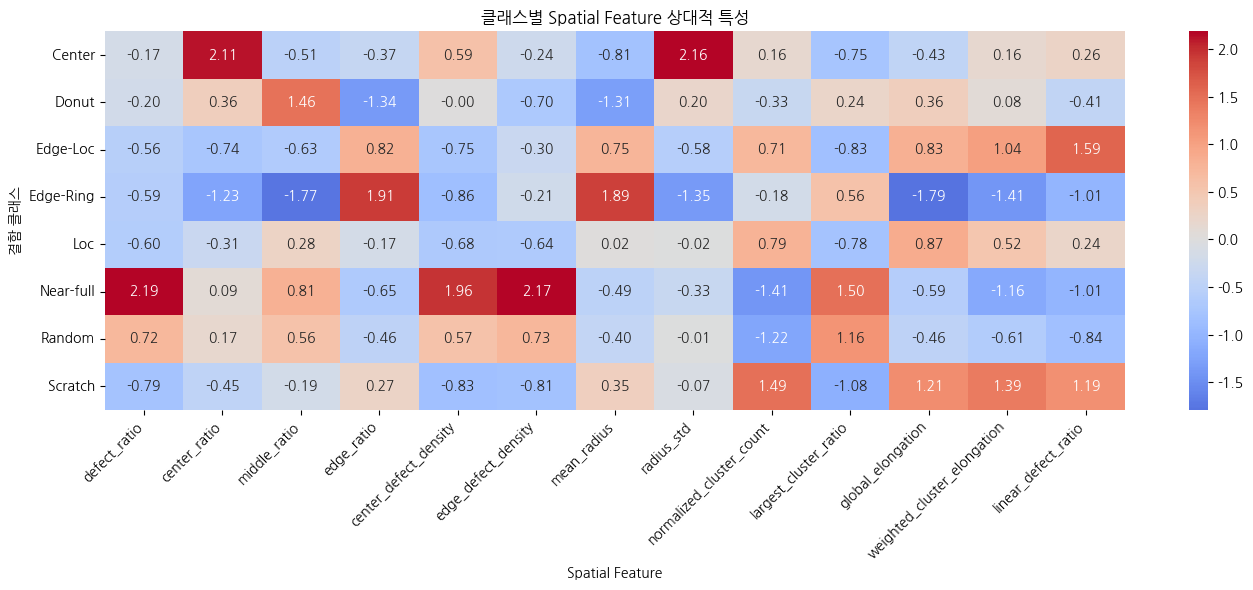

In [267]:
# 클래스별 Spatial Profile 표준화 Heatmap

profile_mean = (
    class_spatial_profile_df.mean(
        axis=0
    )
)

profile_std = (
    class_spatial_profile_df.std(
        axis=0
    )
)


standardized_class_profile_df = (
    (
        class_spatial_profile_df
        -
        profile_mean
    )
    /
    profile_std.replace(
        0,
        np.nan
    )
)


plt.figure(
    figsize=(14, 6)
)


sns.heatmap(
    standardized_class_profile_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)


plt.xlabel(
    "Spatial Feature"
)

plt.ylabel(
    "결함 클래스"
)

plt.title(
    "클래스별 Spatial Feature 상대적 특성"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [268]:
# Step 3 주요 결과 저장

step3_spatial_feature_df = (
    prediction_df[
        [
            "sample_pos",
            "true_label",
            "pred_label",
            "correct"
        ]
        +
        SPATIAL_FEATURES
    ]
    .copy()
)


step3_class_spatial_profile_df = (
    class_spatial_profile_df.copy()
)


print(
    "=== Step 3 저장 변수 ==="
)

print(
    "step3_spatial_feature_df:",
    step3_spatial_feature_df.shape
)

print(
    "step3_class_spatial_profile_df:",
    step3_class_spatial_profile_df.shape
)

=== Step 3 저장 변수 ===
step3_spatial_feature_df: (3911, 17)
step3_class_spatial_profile_df: (8, 13)


## Step 3 결과 요약

Test Set의 모든 웨이퍼에 대해 결함의 양, 위치, 군집 및 방향성을 나타내는 Spatial Feature를 추출하였다.

Radial Feature 분석에서는 클래스별 공간적 위치 차이가 확인되었다.

- Center는 중심부 결함 비율이 상대적으로 높음
- Donut은 Middle 영역의 결함 비율이 높음
- Edge-Ring은 Edge 영역 비율과 평균 반경이 가장 높음
- Edge-Loc 역시 외곽 결함 특성이 강하지만 Edge-Ring보다 국소적인 형태를 보임

Cluster 및 Shape Feature 분석에서는 결함의 연결 구조와 선형성 차이가 나타났다.

특히 Scratch는 결함이 여러 Cluster로 분리되는 경향과 높은 Cluster Elongation을 보였으며, Edge-Ring은 하나의 큰 Cluster가 전체 결함에서 차지하는 비율이 높은 특성을 보였다.

그러나 일부 클래스는 하나의 Spatial Feature만으로 명확하게 구분되지 않았으며, 여러 위치·군집·형태 특징을 함께 고려해야 함을 확인하였다.

따라서 이후 분석에서는 총 13개의 Spatial Feature를 이용하여 클래스 간 차이와 CNN 오분류의 공간적 원인을 통계적으로 검증한다.

# Step 4. Spatial Feature의 통계적 검증

Step 3에서는 각 웨이퍼 맵에서 결함의 위치, 군집 및 방향성을 나타내는 13개의 Spatial Feature를 추출하였다.

클래스별 Median Profile과 Heatmap을 통해 결함 클래스마다 서로 다른 공간적 특성이 존재하는 것을 확인하였지만, 시각적인 차이만으로 실제 클래스 간 차이가 유의하다고 판단할 수는 없다.

따라서 이번 단계에서는 통계적 검정을 이용하여 다음 질문을 확인한다.

1. 각 Spatial Feature가 8개 결함 클래스 사이에서 유의한 차이를 보이는가?
2. 어떤 Feature가 클래스 간 차이를 가장 강하게 설명하는가?
3. CNN이 자주 혼동하는 클래스 사이에서도 Spatial Feature 차이가 존재하는가?
4. 정분류와 오분류 샘플의 Spatial Feature에는 어떤 차이가 있는가?

Spatial Feature는 0~1 범위의 비율값이 많고 분포가 정규분포를 따르지 않을 가능성이 높으며, 클래스별 샘플 수도 크게 불균형하다.

따라서 8개 클래스 전체 비교에는 비모수 검정인 **Kruskal-Wallis Test**를 사용한다.

또한 표본 수가 많으면 작은 차이도 통계적으로 유의하게 나타날 수 있으므로, p-value뿐만 아니라 차이의 크기를 나타내는 **Effect Size**도 함께 계산한다.

In [269]:
# Step 4-1. 클래스 간 Spatial Feature 차이 검정

from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests


kruskal_results = []


for feature in SPATIAL_FEATURES:

    # ----------------------------------------------
    # 클래스별 Feature 값
    # ----------------------------------------------

    groups = []

    for class_name in CLASS_NAMES:

        values = (
            prediction_df.loc[
                prediction_df["true_label"]
                == class_name,
                feature
            ]
            .dropna()
            .values
        )

        groups.append(
            values
        )


    # ----------------------------------------------
    # Kruskal-Wallis Test
    # ----------------------------------------------

    h_statistic, p_value = kruskal(
        *groups
    )


    # ----------------------------------------------
    # Effect Size: Epsilon Squared
    # ----------------------------------------------

    n = sum(
        len(group)
        for group in groups
    )

    k = len(groups)


    epsilon_squared = (
        h_statistic
        - k
        + 1
    ) / (
        n
        - k
    )


    epsilon_squared = max(
        0,
        float(epsilon_squared)
    )


    kruskal_results.append({
        "feature": feature,
        "H_statistic": h_statistic,
        "p_value": p_value,
        "epsilon_squared": epsilon_squared
    })


kruskal_results_df = pd.DataFrame(
    kruskal_results
)


# ----------------------------------------------
# 다중검정 보정
# Benjamini-Hochberg FDR
# ----------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    kruskal_results_df[
        "p_value"
    ],
    alpha=0.05,
    method="fdr_bh"
)


kruskal_results_df[
    "adjusted_p_value"
] = adjusted_p


kruskal_results_df[
    "statistically_significant"
] = reject


# Effect Size 기준 정렬
kruskal_results_df = (
    kruskal_results_df
    .sort_values(
        "epsilon_squared",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "=== Spatial Feature Kruskal-Wallis Test ==="
)


display(
    kruskal_results_df.style.format({
        "H_statistic": "{:.4f}",
        "p_value": "{:.3e}",
        "adjusted_p_value": "{:.3e}",
        "epsilon_squared": "{:.4f}"
    })
)

=== Spatial Feature Kruskal-Wallis Test ===


,feature,H_statistic,p_value,epsilon_squared,adjusted_p_value,statistically_significant
0,mean_radius,2946.8412,0.000e+00,0.7532,0.000e+00,True
1,edge_ratio,2736.1886,0.000e+00,0.6993,0.000e+00,True
2,middle_ratio,2387.4469,0.000e+00,0.6099,0.000e+00,True
3,center_ratio,2199.5363,0.000e+00,0.5618,0.000e+00,True
4,radius_std,1902.5149,0.000e+00,0.4857,0.000e+00,True
5,center_defect_density,1736.4019,0.000e+00,0.4431,0.000e+00,True
6,weighted_cluster_elongation,1715.8631,0.000e+00,0.4378,0.000e+00,True
7,largest_cluster_ratio,1548.6501,0.000e+00,0.3950,0.000e+00,True
8,normalized_cluster_count,1271.0201,3.086e-270,0.3239,4.458e-270,True
9,global_elongation,1199.3737,9.646e-255,0.3055,1.254e-254,True


In [270]:
# Effect Size 해석

def interpret_effect_size(
    epsilon_squared
):

    if epsilon_squared < 0.01:
        return "Negligible"

    elif epsilon_squared < 0.06:
        return "Small"

    elif epsilon_squared < 0.14:
        return "Moderate"

    else:
        return "Large"


kruskal_results_df[
    "effect_interpretation"
] = (
    kruskal_results_df[
        "epsilon_squared"
    ]
    .apply(
        interpret_effect_size
    )
)


display(
    kruskal_results_df[
        [
            "feature",
            "H_statistic",
            "adjusted_p_value",
            "epsilon_squared",
            "effect_interpretation",
            "statistically_significant"
        ]
    ]
    .style.format({
        "H_statistic": "{:.4f}",
        "adjusted_p_value": "{:.3e}",
        "epsilon_squared": "{:.4f}"
    })
)

,feature,H_statistic,adjusted_p_value,epsilon_squared,effect_interpretation,statistically_significant
0,mean_radius,2946.8412,0.000e+00,0.7532,Large,True
1,edge_ratio,2736.1886,0.000e+00,0.6993,Large,True
2,middle_ratio,2387.4469,0.000e+00,0.6099,Large,True
3,center_ratio,2199.5363,0.000e+00,0.5618,Large,True
4,radius_std,1902.5149,0.000e+00,0.4857,Large,True
5,center_defect_density,1736.4019,0.000e+00,0.4431,Large,True
6,weighted_cluster_elongation,1715.8631,0.000e+00,0.4378,Large,True
7,largest_cluster_ratio,1548.6501,0.000e+00,0.3950,Large,True
8,normalized_cluster_count,1271.0201,4.458e-270,0.3239,Large,True
9,global_elongation,1199.3737,1.254e-254,0.3055,Large,True


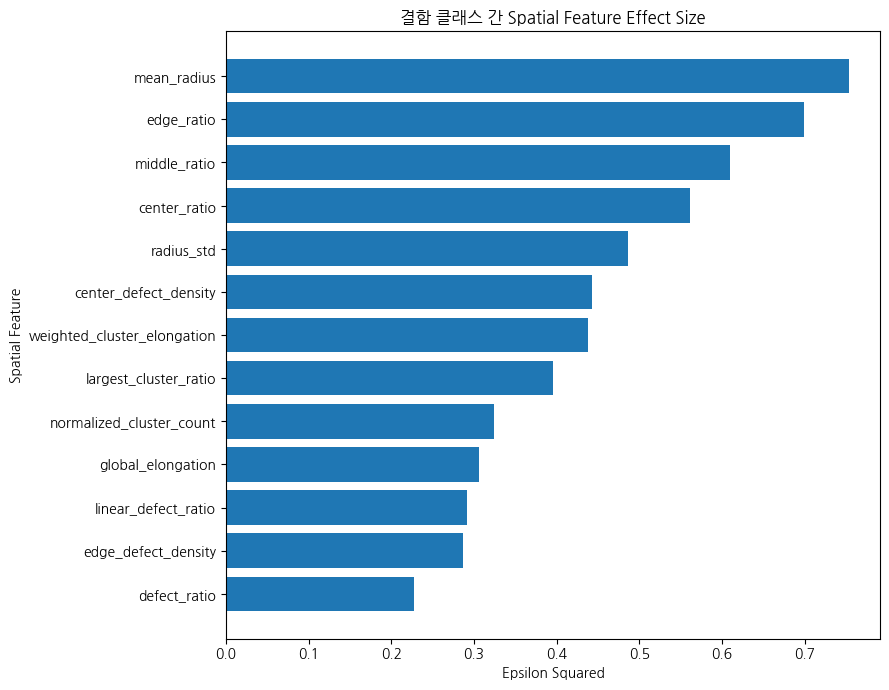

In [271]:
# Spatial Feature별 클래스 구분 Effect Size

effect_plot_df = (
    kruskal_results_df
    .sort_values(
        "epsilon_squared",
        ascending=True
    )
)


plt.figure(
    figsize=(9, 7)
)


plt.barh(
    effect_plot_df[
        "feature"
    ],
    effect_plot_df[
        "epsilon_squared"
    ]
)


plt.xlabel(
    "Epsilon Squared"
)

plt.ylabel(
    "Spatial Feature"
)

plt.title(
    "결함 클래스 간 Spatial Feature Effect Size"
)


plt.tight_layout()
plt.show()

## Step 4-2. 주요 혼동 클래스 간 Pairwise Spatial Feature 분석

전체 8개 결함 클래스 사이에서는 모든 Spatial Feature가 통계적으로 유의한 차이를 보였다.

그러나 본 프로젝트의 목적은 단순히 클래스들이 서로 다르다는 사실을 확인하는 것이 아니라, CNN이 실제로 반복적으로 혼동하는 결함 패턴의 차이를 이해하는 것이다.

따라서 Step 2에서 확인한 주요 오분류 관계를 기준으로 다음 클래스 Pair를 집중적으로 비교한다.

- Scratch ↔ Loc
- Scratch ↔ Edge-Loc
- Loc ↔ Edge-Loc
- Edge-Loc ↔ Edge-Ring

두 클래스의 Spatial Feature 분포 비교에는 비모수 검정인 **Mann-Whitney U Test**를 사용한다.

또한 표본 수가 많을수록 작은 차이도 통계적으로 유의해질 수 있으므로 p-value와 함께 **Rank-Biserial Correlation**을 Effect Size로 계산한다.

Rank-Biserial Correlation의 부호는 Feature의 방향을 의미한다.

- 양수: Pair의 첫 번째 클래스에서 Feature 값이 더 큰 경향
- 음수: 두 번째 클래스에서 Feature 값이 더 큰 경향
- 절댓값이 클수록 두 클래스의 차이가 큼

다중 검정으로 인한 우연한 유의성을 줄이기 위해 Benjamini-Hochberg 방식으로 p-value를 보정한다.

In [272]:
# Step 4-2. 주요 혼동 Pair의 Spatial Feature 비교

from scipy.stats import mannwhitneyu


CONFUSION_PAIRS = [
    ("Scratch", "Loc"),
    ("Scratch", "Edge-Loc"),
    ("Loc", "Edge-Loc"),
    ("Edge-Loc", "Edge-Ring")
]


pairwise_results = []


for class_a, class_b in CONFUSION_PAIRS:

    for feature in SPATIAL_FEATURES:

        values_a = (
            prediction_df.loc[
                prediction_df["true_label"] == class_a,
                feature
            ]
            .dropna()
            .values
        )

        values_b = (
            prediction_df.loc[
                prediction_df["true_label"] == class_b,
                feature
            ]
            .dropna()
            .values
        )


        # ------------------------------------------
        # Mann-Whitney U Test
        # ------------------------------------------

        u_statistic, p_value = mannwhitneyu(
            values_a,
            values_b,
            alternative="two-sided"
        )


        n_a = len(values_a)
        n_b = len(values_b)


        # ------------------------------------------
        # Rank-Biserial Correlation
        #
        # + : Class A 값이 큰 경향
        # - : Class B 값이 큰 경향
        # ------------------------------------------

        rank_biserial = (
            2 * u_statistic
            / (n_a * n_b)
            - 1
        )


        pairwise_results.append({

            "class_a": class_a,
            "class_b": class_b,

            "pair": (
                f"{class_a} ↔ {class_b}"
            ),

            "feature": feature,

            "n_a": n_a,
            "n_b": n_b,

            "median_a": np.median(
                values_a
            ),

            "median_b": np.median(
                values_b
            ),

            "median_difference": (
                np.median(values_a)
                -
                np.median(values_b)
            ),

            "U_statistic": u_statistic,

            "p_value": p_value,

            "rank_biserial": (
                rank_biserial
            ),

            "abs_effect_size": abs(
                rank_biserial
            )
        })


pairwise_results_df = pd.DataFrame(
    pairwise_results
)


# ----------------------------------------------
# 전체 Pairwise Test에 대해 FDR 보정
# ----------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    pairwise_results_df["p_value"],
    alpha=0.05,
    method="fdr_bh"
)


pairwise_results_df[
    "adjusted_p_value"
] = adjusted_p


pairwise_results_df[
    "statistically_significant"
] = reject


print(
    "=== 주요 혼동 Pair Spatial Feature Test ==="
)


display(
    pairwise_results_df
    .sort_values(
        [
            "pair",
            "abs_effect_size"
        ],
        ascending=[
            True,
            False
        ]
    )
    .style.format({

        "median_a": "{:.4f}",
        "median_b": "{:.4f}",
        "median_difference": "{:+.4f}",

        "U_statistic": "{:.1f}",

        "p_value": "{:.3e}",
        "adjusted_p_value": "{:.3e}",

        "rank_biserial": "{:+.4f}",
        "abs_effect_size": "{:.4f}"
    })
)

=== 주요 혼동 Pair Spatial Feature Test ===


,class_a,class_b,pair,feature,n_a,n_b,median_a,median_b,median_difference,U_statistic,p_value,rank_biserial,abs_effect_size,adjusted_p_value,statistically_significant
45,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,mean_radius,841,1508,0.7406,0.8393,-0.0987,107395.0,6.499e-245,-0.8306,0.8306,3.380e-243,True
42,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,edge_ratio,841,1508,0.6170,0.7944,-0.1774,131051.0,1.353e-223,-0.7933,0.7933,3.519e-222,True
41,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,middle_ratio,841,1508,0.3071,0.1581,+0.1490,1132781.0,9.670e-220,+0.7864,0.7864,1.676e-218,True
50,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,weighted_cluster_elongation,841,1508,0.8387,0.1482,+0.6905,1093727.0,5.521e-187,+0.7248,0.7248,7.178e-186,True
48,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,largest_cluster_ratio,841,1508,0.2778,0.7099,-0.4321,193710.5,7.525e-172,-0.6945,0.6945,7.826e-171,True
49,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,global_elongation,841,1508,0.3066,0.1209,+0.1857,1067036.0,3.950e-166,+0.6827,0.6827,3.423e-165,True
51,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,linear_defect_ratio,841,1508,0.3727,0.0000,+0.3727,1054020.0,4.210e-165,+0.6622,0.6622,3.127e-164,True
47,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,normalized_cluster_count,841,1508,0.3737,0.2166,+0.1571,993956.0,2.140e-115,+0.5675,0.5675,1.391e-114,True
40,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,center_ratio,841,1508,0.0753,0.0453,+0.0301,960912.0,1.620e-95,+0.5154,0.5154,9.363e-95,True
46,Edge-Loc,Edge-Ring,Edge-Loc ↔ Edge-Ring,radius_std,841,1508,0.2228,0.2034,+0.0193,871437.0,3.012e-51,+0.3743,0.3743,9.788e-51,True


In [273]:
# 각 혼동 Pair별 Effect Size가 큰 Feature Top 5

top_pair_features_df = (
    pairwise_results_df
    .sort_values(
        "abs_effect_size",
        ascending=False
    )
    .groupby(
        "pair",
        group_keys=False
    )
    .head(5)
    .reset_index(drop=True)
)


print(
    "=== 혼동 Pair별 주요 Spatial Feature Top 5 ==="
)


display(
    top_pair_features_df[
        [
            "pair",
            "feature",

            "median_a",
            "median_b",

            "rank_biserial",
            "abs_effect_size",

            "adjusted_p_value",
            "statistically_significant"
        ]
    ]
    .style.format({

        "median_a": "{:.4f}",
        "median_b": "{:.4f}",

        "rank_biserial": "{:+.4f}",
        "abs_effect_size": "{:.4f}",

        "adjusted_p_value": "{:.3e}"
    })
)

=== 혼동 Pair별 주요 Spatial Feature Top 5 ===


,pair,feature,median_a,median_b,rank_biserial,abs_effect_size,adjusted_p_value,statistically_significant
0,Scratch ↔ Loc,weighted_cluster_elongation,0.9381,0.6934,+0.8824,0.8824,1.641e-71,True
1,Edge-Loc ↔ Edge-Ring,mean_radius,0.7406,0.8393,-0.8306,0.8306,3.380e-243,True
2,Edge-Loc ↔ Edge-Ring,edge_ratio,0.6170,0.7944,-0.7933,0.7933,3.519e-222,True
3,Edge-Loc ↔ Edge-Ring,middle_ratio,0.3071,0.1581,+0.7864,0.7864,1.676e-218,True
4,Edge-Loc ↔ Edge-Ring,weighted_cluster_elongation,0.8387,0.1482,+0.7248,0.7248,7.178e-186,True
5,Scratch ↔ Edge-Loc,edge_defect_density,0.1197,0.2481,-0.7036,0.7036,1.372e-50,True
6,Edge-Loc ↔ Edge-Ring,largest_cluster_ratio,0.2778,0.7099,-0.6945,0.6945,7.826e-171,True
7,Scratch ↔ Edge-Loc,weighted_cluster_elongation,0.9381,0.8387,+0.5977,0.5977,6.275e-37,True
8,Loc ↔ Edge-Loc,edge_ratio,0.4574,0.6170,-0.5882,0.5882,1.558e-75,True
9,Loc ↔ Edge-Loc,mean_radius,0.6770,0.7406,-0.5515,0.5515,1.329e-66,True


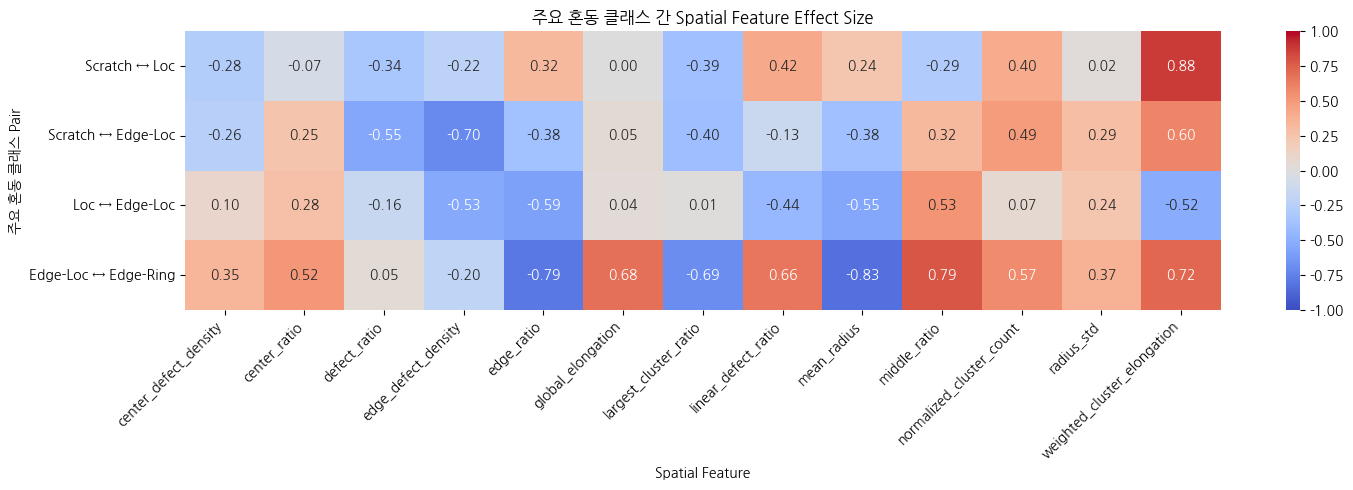

In [274]:
# 주요 혼동 Pair의 Rank-Biserial Effect Size Heatmap

pair_effect_matrix = (
    pairwise_results_df
    .pivot(
        index="pair",
        columns="feature",
        values="rank_biserial"
    )
    .reindex(
        [
            "Scratch ↔ Loc",
            "Scratch ↔ Edge-Loc",
            "Loc ↔ Edge-Loc",
            "Edge-Loc ↔ Edge-Ring"
        ]
    )
)


plt.figure(
    figsize=(15, 5)
)


sns.heatmap(
    pair_effect_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)


plt.xlabel(
    "Spatial Feature"
)

plt.ylabel(
    "주요 혼동 클래스 Pair"
)

plt.title(
    "주요 혼동 클래스 간 Spatial Feature Effect Size"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

### 전체 클래스 통계 검정 결과

13개의 Spatial Feature에 대해 Kruskal-Wallis Test를 수행한 결과 모든 Feature에서 결함 클래스 간 통계적으로 유의한 차이가 확인되었다.

또한 모든 Feature의 Epsilon Squared가 0.14 이상으로 나타나 단순히 표본 수가 많기 때문에 유의한 것이 아니라 실제로 클래스에 따른 공간적 구조 차이가 상당히 큰 것으로 확인되었다.

가장 큰 Effect Size를 보인 특징은 다음과 같다.

1. Mean Radius
2. Edge Ratio
3. Middle Ratio
4. Center Ratio
5. Radius Standard Deviation

이는 웨이퍼 결함 클래스를 구분하는 데 결함의 **방사형 위치 정보**가 매우 중요한 역할을 한다는 것을 보여준다.

동시에 Weighted Cluster Elongation, Largest Cluster Ratio, Normalized Cluster Count 등의 Shape 및 Cluster Feature도 큰 Effect Size를 보여, 결함의 형태와 연결 구조 역시 클래스 구분에 중요한 정보를 제공함을 확인하였다.

## Step 4-3. 클래스 내부 정분류와 오분류 Spatial Feature 비교

앞선 분석에서는 서로 다른 결함 클래스 사이의 Spatial Feature 차이를 분석하였다.

이번에는 동일한 실제 결함 클래스 내부에서 CNN이 올바르게 분류한 샘플과 잘못 분류한 샘플의 공간적 특징을 비교한다.

예를 들어 실제 라벨이 모두 Scratch인 웨이퍼를 다음 두 그룹으로 나눈다.

- Correct Scratch: CNN이 Scratch로 올바르게 분류
- Misclassified Scratch: CNN이 Loc, Edge-Loc 등 다른 클래스로 잘못 분류

두 그룹 사이에서 Spatial Feature 차이가 존재한다면, 해당 클래스의 비전형적인 공간 구조가 CNN 오분류와 관련되어 있을 가능성이 있다.

각 클래스와 Spatial Feature에 대해 Mann-Whitney U Test를 수행하고, Rank-Biserial Correlation을 Effect Size로 계산한다.

Effect Size의 방향은 다음과 같이 정의한다.

- 양수: 정분류 샘플에서 해당 Feature가 더 큰 경향
- 음수: 오분류 샘플에서 해당 Feature가 더 큰 경향

단, 본 분석은 Spatial Feature와 오분류의 연관성을 확인하는 것이며 특정 Feature가 CNN 오류의 직접적인 원인임을 의미하지는 않는다.

In [275]:
# Step 4-3. 동일 클래스 내 정분류 vs 오분류 비교

within_class_results = []


for class_name in CLASS_NAMES:

    class_df = prediction_df[
        prediction_df["true_label"]
        == class_name
    ].copy()


    correct_df = class_df[
        class_df["correct"]
    ]

    error_df_class = class_df[
        ~class_df["correct"]
    ]


    n_correct = len(
        correct_df
    )

    n_error = len(
        error_df_class
    )


    for feature in SPATIAL_FEATURES:

        correct_values = (
            correct_df[
                feature
            ]
            .dropna()
            .values
        )

        error_values = (
            error_df_class[
                feature
            ]
            .dropna()
            .values
        )


        # 비교할 데이터가 없는 경우
        if (
            len(correct_values) == 0
            or
            len(error_values) == 0
        ):

            continue


        # ------------------------------------------
        # Mann-Whitney U Test
        # ------------------------------------------

        u_statistic, p_value = mannwhitneyu(
            correct_values,
            error_values,
            alternative="two-sided"
        )


        # ------------------------------------------
        # Rank-Biserial Correlation
        #
        # + : Correct에서 더 큼
        # - : Misclassified에서 더 큼
        # ------------------------------------------

        rank_biserial = (
            2 * u_statistic
            /
            (
                len(correct_values)
                *
                len(error_values)
            )
            - 1
        )


        within_class_results.append({

            "true_label": class_name,

            "feature": feature,

            "correct_count": n_correct,
            "error_count": n_error,

            "correct_median": np.median(
                correct_values
            ),

            "error_median": np.median(
                error_values
            ),

            "median_difference": (
                np.median(correct_values)
                -
                np.median(error_values)
            ),

            "U_statistic": (
                u_statistic
            ),

            "p_value": (
                p_value
            ),

            "rank_biserial": (
                rank_biserial
            ),

            "abs_effect_size": abs(
                rank_biserial
            )
        })


within_class_results_df = pd.DataFrame(
    within_class_results
)


# --------------------------------------------------
# 전체 검정에 대해 FDR 보정
# --------------------------------------------------

reject, adjusted_p, _, _ = multipletests(

    within_class_results_df[
        "p_value"
    ],

    alpha=0.05,

    method="fdr_bh"
)


within_class_results_df[
    "adjusted_p_value"
] = adjusted_p


within_class_results_df[
    "statistically_significant"
] = reject


print(
    "=== 클래스 내부 Correct vs Misclassified ==="
)


display(
    within_class_results_df
    .sort_values(
        [
            "true_label",
            "abs_effect_size"
        ],
        ascending=[
            True,
            False
        ]
    )
    .style.format({

        "correct_median": "{:.4f}",
        "error_median": "{:.4f}",

        "median_difference": "{:+.4f}",

        "U_statistic": "{:.1f}",

        "p_value": "{:.3e}",
        "adjusted_p_value": "{:.3e}",

        "rank_biserial": "{:+.4f}",
        "abs_effect_size": "{:.4f}"
    })
)

=== 클래스 내부 Correct vs Misclassified ===


,true_label,feature,correct_count,error_count,correct_median,error_median,median_difference,U_statistic,p_value,rank_biserial,abs_effect_size,adjusted_p_value,statistically_significant
7,Center,radius_std,619,17,0.2912,0.2760,+0.0152,7270.0,7.217e-03,+0.3817,0.3817,1.924e-02,True
1,Center,center_ratio,619,17,0.2481,0.1959,+0.0522,7250.0,7.816e-03,+0.3779,0.3779,2.032e-02,True
2,Center,middle_ratio,619,17,0.3212,0.3933,-0.0721,3296.5,8.577e-03,-0.3735,0.3735,2.106e-02,True
4,Center,center_defect_density,619,17,0.5410,0.3167,+0.2243,7038.5,1.744e-02,+0.3377,0.3377,3.944e-02,True
5,Center,edge_defect_density,619,17,0.2683,0.1522,+0.1161,6958.0,2.324e-02,+0.3224,0.3224,5.035e-02,False
9,Center,largest_cluster_ratio,619,17,0.3032,0.1719,+0.1314,6737.0,4.844e-02,+0.2804,0.2804,8.995e-02,False
0,Center,defect_ratio,619,17,0.2583,0.1873,+0.0710,6543.5,8.641e-02,+0.2437,0.2437,1.498e-01,False
8,Center,normalized_cluster_count,619,17,0.2761,0.3505,-0.0744,4251.0,1.766e-01,-0.1921,0.1921,2.586e-01,False
6,Center,mean_radius,619,17,0.6046,0.6280,-0.0233,4386.0,2.417e-01,-0.1664,0.1664,3.308e-01,False
12,Center,linear_defect_ratio,619,17,0.1824,0.1573,+0.0251,5749.5,5.140e-01,+0.0927,0.0927,6.030e-01,False


In [276]:
# 클래스별 Test Set 정분류 / 오분류 수

class_error_count_df = (
    prediction_df
    .groupby(
        "true_label"
    )
    .agg(

        total_count=(
            "sample_pos",
            "count"
        ),

        correct_count=(
            "correct",
            "sum"
        )
    )
    .reindex(
        CLASS_NAMES
    )
)


class_error_count_df[
    "error_count"
] = (
    class_error_count_df[
        "total_count"
    ]
    -
    class_error_count_df[
        "correct_count"
    ]
)


class_error_count_df[
    "error_rate"
] = (
    class_error_count_df[
        "error_count"
    ]
    /
    class_error_count_df[
        "total_count"
    ]
)


print(
    "=== 클래스별 CNN Error ==="
)


display(
    class_error_count_df.style.format({
        "error_rate": "{:.4f}"
    })
)

=== 클래스별 CNN Error ===


,total_count,correct_count,error_count,error_rate
true_label,,,,
Center,636,619,17,0.0267
Donut,79,69,10,0.1266
Edge-Loc,841,775,66,0.0785
Edge-Ring,1508,1478,30,0.0199
Loc,541,421,120,0.2218
Near-full,23,21,2,0.0870
Random,97,76,21,0.2165
Scratch,186,77,109,0.5860


In [277]:
# 클래스별 정분류/오분류 차이가 큰 Feature Top 5

within_class_top_features_df = (

    within_class_results_df

    .sort_values(
        "abs_effect_size",
        ascending=False
    )

    .groupby(
        "true_label",
        group_keys=False
    )

    .head(5)

    .reset_index(
        drop=True
    )
)


print(
    "=== 클래스별 Correct vs Error 주요 Feature Top 5 ==="
)


display(
    within_class_top_features_df[
        [
            "true_label",
            "feature",

            "correct_count",
            "error_count",

            "correct_median",
            "error_median",

            "rank_biserial",
            "abs_effect_size",

            "adjusted_p_value",
            "statistically_significant"
        ]
    ]
    .style.format({

        "correct_median": "{:.4f}",
        "error_median": "{:.4f}",

        "rank_biserial": "{:+.4f}",
        "abs_effect_size": "{:.4f}",

        "adjusted_p_value": "{:.3e}"
    })
)

=== 클래스별 Correct vs Error 주요 Feature Top 5 ===


,true_label,feature,correct_count,error_count,correct_median,error_median,rank_biserial,abs_effect_size,adjusted_p_value,statistically_significant
0,Near-full,edge_defect_density,21,2,0.9223,0.6450,+1.0000,1.0000,5.256e-02,False
1,Near-full,defect_ratio,21,2,0.9298,0.7619,+1.0000,1.0000,5.256e-02,False
2,Near-full,normalized_cluster_count,21,2,0.0019,0.0124,-0.9524,0.9524,3.654e-02,True
3,Near-full,largest_cluster_ratio,21,2,1.0000,0.9799,+0.8571,0.8571,7.000e-02,False
4,Near-full,global_elongation,21,2,0.2043,0.3032,-0.8571,0.8571,8.969e-02,False
5,Edge-Ring,weighted_cluster_elongation,1478,30,0.1458,0.8589,-0.7133,0.7133,4.440e-10,True
6,Edge-Ring,mean_radius,1478,30,0.8400,0.7595,+0.6977,0.6977,9.918e-10,True
7,Scratch,defect_ratio,77,109,0.0487,0.1141,-0.6885,0.6885,1.422e-13,True
8,Random,edge_defect_density,76,21,0.5333,0.2687,+0.6792,0.6792,1.368e-05,True
9,Edge-Ring,linear_defect_ratio,1478,30,0.0000,0.4739,-0.6634,0.6634,1.476e-10,True


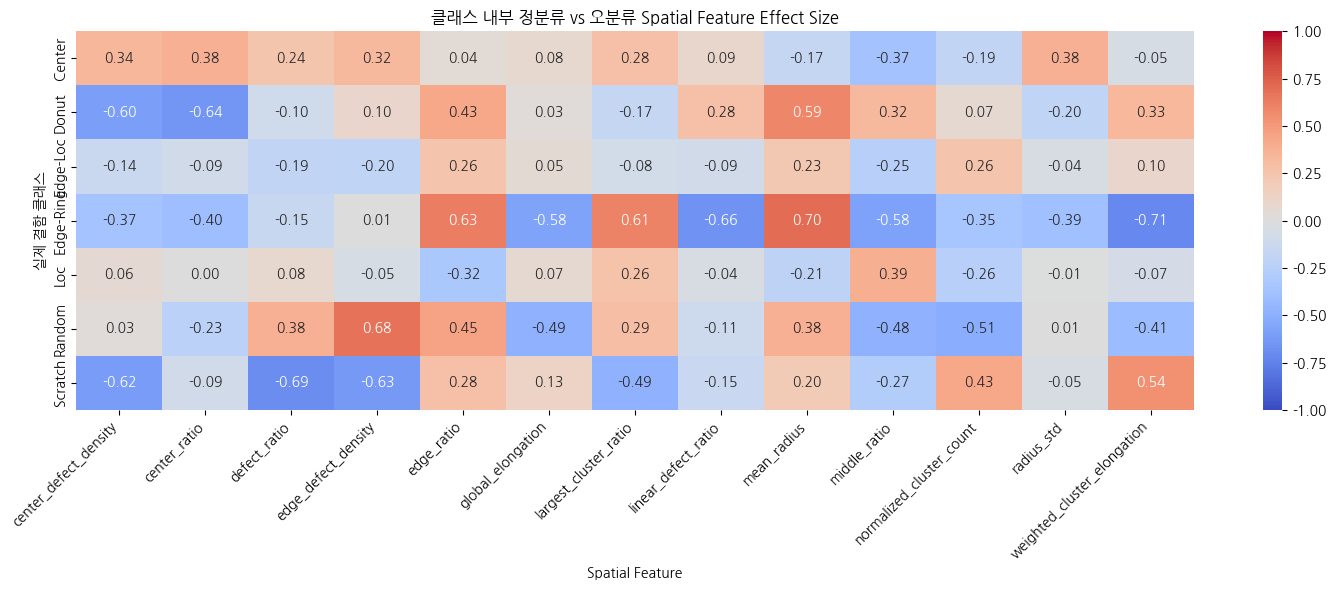

In [278]:
# 오분류 표본이 충분한 클래스만 선택

eligible_classes = (

    class_error_count_df[
        class_error_count_df[
            "error_count"
        ]
        >= 10
    ]

    .index
    .tolist()
)


within_class_effect_matrix = (

    within_class_results_df[
        within_class_results_df[
            "true_label"
        ]
        .isin(
            eligible_classes
        )
    ]

    .pivot(
        index="true_label",
        columns="feature",
        values="rank_biserial"
    )

    .reindex(
        [
            class_name
            for class_name
            in CLASS_NAMES
            if class_name
            in eligible_classes
        ]
    )
)


plt.figure(
    figsize=(15, 6)
)


sns.heatmap(

    within_class_effect_matrix,

    annot=True,

    fmt=".2f",

    cmap="coolwarm",

    center=0,

    vmin=-1,

    vmax=1
)


plt.xlabel(
    "Spatial Feature"
)

plt.ylabel(
    "실제 결함 클래스"
)

plt.title(
    "클래스 내부 정분류 vs 오분류 Spatial Feature Effect Size"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()

plt.show()

In [279]:
# Step 4 주요 결과 저장

step4_kruskal_results_df = (
    kruskal_results_df.copy()
)

step4_pairwise_results_df = (
    pairwise_results_df.copy()
)

step4_top_pair_features_df = (
    top_pair_features_df.copy()
)

step4_within_class_results_df = (
    within_class_results_df.copy()
)

step4_within_class_top_features_df = (
    within_class_top_features_df.copy()
)


print(
    "=== Step 4 저장 변수 ==="
)

print(
    "step4_kruskal_results_df:",
    step4_kruskal_results_df.shape
)

print(
    "step4_pairwise_results_df:",
    step4_pairwise_results_df.shape
)

print(
    "step4_top_pair_features_df:",
    step4_top_pair_features_df.shape
)

print(
    "step4_within_class_results_df:",
    step4_within_class_results_df.shape
)

print(
    "step4_within_class_top_features_df:",
    step4_within_class_top_features_df.shape
)

=== Step 4 저장 변수 ===
step4_kruskal_results_df: (13, 7)
step4_pairwise_results_df: (52, 15)
step4_top_pair_features_df: (20, 15)
step4_within_class_results_df: (104, 13)
step4_within_class_top_features_df: (40, 13)


## Step 4 결과 요약

13개의 Spatial Feature에 대해 통계 분석을 수행한 결과, 모든 Feature에서 8개 결함 클래스 간 유의한 차이가 확인되었다.

특히 Mean Radius, Edge Ratio, Middle Ratio, Center Ratio와 같은 방사형 위치 정보에서 가장 큰 Effect Size가 나타나, 결함의 위치가 클래스 구분에 매우 중요한 특징임을 확인하였다.

CNN이 반복적으로 혼동한 주요 클래스 Pair를 비교한 결과 각 Pair마다 서로 다른 구분 특징이 나타났다.

- **Scratch ↔ Loc**
  - Weighted Cluster Elongation에서 가장 큰 차이가 나타남
  - Scratch가 보다 강한 선형 Cluster 구조를 가지는 경향

- **Scratch ↔ Edge-Loc**
  - Edge Defect Density와 Weighted Cluster Elongation에서 큰 차이가 나타남
  - 두 클래스 모두 선형 구조가 나타날 수 있지만 위치와 결함 밀도에서 차이가 존재함

- **Loc ↔ Edge-Loc**
  - Edge Ratio와 Mean Radius에서 큰 차이가 나타남
  - Edge-Loc이 상대적으로 웨이퍼 외곽에 더 집중되는 특징을 보임

- **Edge-Loc ↔ Edge-Ring**
  - Mean Radius, Edge Ratio, Middle Ratio 및 Largest Cluster Ratio에서 큰 차이가 나타남
  - Edge-Ring은 외곽에 더 강하게 집중되고 연속적인 결함 구조를 가지는 경향을 보임

동일한 실제 클래스 내부에서 정분류와 오분류 샘플을 비교한 결과, CNN의 오류가 무작위로 발생하는 것이 아니라 일부 비전형적인 Spatial Pattern과 연관되어 있음을 확인하였다.

특히 Edge-Ring은 외곽 집중 특성이 약해지고 선형성이 증가할수록 오분류되는 경향이 강하게 나타났다.

Scratch 역시 전형적인 선형 및 분절 Cluster 특성이 약화되는 경우 오분류가 증가하는 경향을 보였다.

반면 Edge-Loc에서는 정분류와 오분류 사이의 Spatial Feature 차이가 상대적으로 작아, 현재의 요약 Spatial Feature만으로는 오류를 충분히 설명하기 어려운 것으로 나타났다.

Near-full은 오분류 샘플이 3개에 불과하므로 클래스 내부 통계 결과를 탐색적인 결과로만 해석하였다.

따라서 CNN 오류는 단순한 무작위 오류라기보다 클래스의 전형적인 공간 구조에서 벗어난 샘플이나 서로 다른 결함 패턴의 경계 영역에서 집중되는 것으로 판단된다.

# Step 5. CNN 오류 및 Prototype Similarity 분석

Step 4에서는 CNN 오분류가 특정 Spatial Pattern과 연관되어 있음을 통계적으로 확인하였다.

이번 단계에서는 각 결함 클래스의 대표적인 Spatial Pattern을 **Prototype**으로 정의하고, 각 Test Wafer가 어떤 클래스의 Prototype과 가장 유사한지 분석한다.

Prototype은 Test Set이 아니라 **Train Set의 Spatial Feature 중앙값**을 이용하여 생성한다.

이를 통해 Test Set의 정답 정보를 이용하여 대표 패턴을 만드는 문제를 줄이고, 학습 데이터에서 관찰된 전형적인 결함 구조를 기준으로 Test Wafer를 비교한다.

분석의 주요 질문은 다음과 같다.

1. CNN이 정분류한 Wafer는 실제 클래스 Prototype과 가까운가?
2. CNN이 오분류한 Wafer는 실제 클래스보다 예측 클래스 Prototype에 더 가까운가?
3. 실제 클래스 Prototype에서 크게 벗어난 비전형적인 Wafer가 CNN 오류에 더 많이 포함되는가?
4. 두 개 이상의 클래스 Prototype 사이에 위치하는 경계형 또는 혼합형 패턴이 존재하는가?

Prototype Similarity는 CNN의 예측 확률과 독립적으로, Step 3에서 정의한 13개의 Spatial Feature만을 이용하여 계산한다.

In [280]:
# Step 5-1. Train Set Spatial Feature 추출 함수

def extract_all_spatial_features(wafer_map):
    """
    하나의 wafer map에서 Step 3의 최종 13개 Spatial Feature를 추출한다.
    """

    wafer_map = np.asarray(wafer_map)

    # --------------------------------------------------
    # 기본 Feature
    # --------------------------------------------------

    valid_die_mask = wafer_map > 0
    defect_mask = wafer_map == 2

    valid_die_count = int(
        valid_die_mask.sum()
    )

    defect_count = int(
        defect_mask.sum()
    )

    defect_ratio = (
        defect_count / valid_die_count
        if valid_die_count > 0
        else np.nan
    )


    # --------------------------------------------------
    # Radial Feature
    # --------------------------------------------------

    radial_features = extract_radial_features(
        wafer_map
    )


    # --------------------------------------------------
    # Cluster / Shape Feature
    # --------------------------------------------------

    cluster_features = extract_cluster_features(
        wafer_map
    )


    # --------------------------------------------------
    # Step 3에서 확정한 13개 Feature만 반환
    # --------------------------------------------------

    return {

        "defect_ratio":
            defect_ratio,

        "center_ratio":
            radial_features["center_ratio"],

        "middle_ratio":
            radial_features["middle_ratio"],

        "edge_ratio":
            radial_features["edge_ratio"],

        "center_defect_density":
            radial_features["center_defect_density"],

        "edge_defect_density":
            radial_features["edge_defect_density"],

        "mean_radius":
            radial_features["mean_radius"],

        "radius_std":
            radial_features["radius_std"],

        "normalized_cluster_count":
            cluster_features["normalized_cluster_count"],

        "largest_cluster_ratio":
            cluster_features["largest_cluster_ratio"],

        "global_elongation":
            cluster_features["global_elongation"],

        "weighted_cluster_elongation":
            cluster_features["weighted_cluster_elongation"],

        "linear_defect_ratio":
            cluster_features["linear_defect_ratio"]
    }


print(
    "✓ 전체 Spatial Feature 추출 함수 생성 완료"
)

✓ 전체 Spatial Feature 추출 함수 생성 완료


In [281]:
# Train Set 전체 Spatial Feature 추출

from tqdm.auto import tqdm


train_spatial_rows = []


for sample_pos, wafer_map in enumerate(
    tqdm(
        train_df["waferMap"],
        desc="Train Spatial Feature 추출"
    )
):

    features = extract_all_spatial_features(
        wafer_map
    )


    features["sample_pos"] = (
        sample_pos
    )

    features["true_label"] = (
        train_df.iloc[
            sample_pos
        ]["label"]
    )


    train_spatial_rows.append(
        features
    )


train_spatial_feature_df = pd.DataFrame(
    train_spatial_rows
)


print(
    "=== Train Spatial Feature 추출 완료 ==="
)

print(
    "Train 샘플 수:",
    len(train_spatial_feature_df)
)

print(
    "DataFrame Shape:",
    train_spatial_feature_df.shape
)


print(
    "\n=== 결측치 ==="
)

display(
    train_spatial_feature_df[
        SPATIAL_FEATURES
    ]
    .isnull()
    .sum()
    .to_frame(
        "missing_count"
    )
)


display(
    train_spatial_feature_df.head()
)

Train Spatial Feature 추출:   0%|          | 0/17641 [00:00<?, ?it/s]

=== Train Spatial Feature 추출 완료 ===
Train 샘플 수: 17641
DataFrame Shape: (17641, 15)

=== 결측치 ===


,missing_count
defect_ratio,0
center_ratio,0
middle_ratio,0
edge_ratio,0
center_defect_density,0
edge_defect_density,0
mean_radius,0
radius_std,0
normalized_cluster_count,0
largest_cluster_ratio,0


,defect_ratio,center_ratio,middle_ratio,edge_ratio,center_defect_density,edge_defect_density,mean_radius,radius_std,normalized_cluster_count,largest_cluster_ratio,global_elongation,weighted_cluster_elongation,linear_defect_ratio,sample_pos,true_label
0,0.086750,0.068493,0.452055,0.479452,0.050761,0.103858,0.708176,0.224554,0.445205,0.431507,0.516744,0.607848,0.054795,0,Loc
1,0.089024,0.082192,0.273973,0.643836,0.061644,0.146875,0.767197,0.237371,0.566210,0.246575,0.461820,0.864933,0.246575,1,Edge-Loc
2,0.097154,0.083682,0.305439,0.610879,0.068493,0.152083,0.747812,0.242813,0.523013,0.251046,0.500454,0.901500,0.292887,2,Edge-Loc
3,0.109756,0.096296,0.255556,0.648148,0.089041,0.182292,0.756985,0.251727,0.466667,0.300000,0.526588,0.907623,0.400000,3,Edge-Loc
4,0.111382,0.036496,0.266423,0.697080,0.034247,0.198958,0.787434,0.190073,0.401460,0.233577,0.426249,0.840902,0.251825,4,Edge-Loc


In [282]:
# Step 5-2. Train 기준 Robust Scaling

train_feature_matrix = (
    train_spatial_feature_df[
        SPATIAL_FEATURES
    ]
    .astype(float)
)


# --------------------------------------------------
# Train Median
# --------------------------------------------------

spatial_scaler_median = (
    train_feature_matrix
    .median()
)


# --------------------------------------------------
# Train IQR
# --------------------------------------------------

spatial_scaler_q1 = (
    train_feature_matrix
    .quantile(0.25)
)

spatial_scaler_q3 = (
    train_feature_matrix
    .quantile(0.75)
)


spatial_scaler_iqr = (
    spatial_scaler_q3
    -
    spatial_scaler_q1
)


# IQR = 0인 경우 division 방지
spatial_scaler_iqr = (
    spatial_scaler_iqr
    .replace(
        0,
        1.0
    )
)


# --------------------------------------------------
# Train Feature Scaling
# --------------------------------------------------

train_scaled_features = (
    (
        train_feature_matrix
        -
        spatial_scaler_median
    )
    /
    spatial_scaler_iqr
)


print(
    "=== Spatial Feature Robust Scaling ==="
)


scaling_summary_df = pd.DataFrame({

    "median":
        spatial_scaler_median,

    "Q1":
        spatial_scaler_q1,

    "Q3":
        spatial_scaler_q3,

    "IQR":
        spatial_scaler_iqr
})


display(
    scaling_summary_df.style.format(
        "{:.4f}"
    )
)

=== Spatial Feature Robust Scaling ===


,median,Q1,Q3,IQR
defect_ratio,0.1586,0.1160,0.2326,0.1167
center_ratio,0.0780,0.0458,0.1460,0.1002
middle_ratio,0.2935,0.1753,0.3889,0.2136
edge_ratio,0.5907,0.4409,0.7692,0.3284
center_defect_density,0.0984,0.0464,0.2535,0.2072
edge_defect_density,0.2464,0.1803,0.3268,0.1466
mean_radius,0.7320,0.6469,0.8257,0.1788
radius_std,0.2267,0.2018,0.2546,0.0527
normalized_cluster_count,0.2593,0.1921,0.4000,0.2079
largest_cluster_ratio,0.4318,0.2364,0.7183,0.4819


In [283]:
# Step 5-3. Train 기반 클래스 Prototype 생성

train_scaled_df = (
    train_scaled_features.copy()
)


train_scaled_df[
    "true_label"
] = (
    train_spatial_feature_df[
        "true_label"
    ].values
)


class_prototype_df = (
    train_scaled_df
    .groupby(
        "true_label"
    )[SPATIAL_FEATURES]
    .median()
    .reindex(
        CLASS_NAMES
    )
)


print(
    "=== Train 기반 Class Spatial Prototype ==="
)


display(
    class_prototype_df
    .style
    .format(
        "{:.3f}"
    )
)

=== Train 기반 Class Spatial Prototype ===


,defect_ratio,center_ratio,middle_ratio,edge_ratio,center_defect_density,edge_defect_density,mean_radius,radius_std,normalized_cluster_count,largest_cluster_ratio,global_elongation,weighted_cluster_elongation,linear_defect_ratio
true_label,,,,,,,,,,,,,
Center,0.821,1.647,0.115,-0.494,1.993,0.049,-0.697,1.227,0.097,-0.274,0.019,-0.030,0.076
Donut,0.896,0.329,1.533,-1.057,0.863,-0.680,-0.908,-0.069,-0.475,0.502,0.358,-0.101,-0.222
Edge-Loc,-0.030,0.011,0.089,0.035,-0.003,0.033,0.011,-0.053,0.587,-0.335,0.520,0.326,0.593
Edge-Ring,-0.170,-0.320,-0.633,0.616,-0.213,0.144,0.609,-0.416,-0.211,0.579,-0.384,-0.767,-0.391
Loc,-0.132,0.238,0.598,-0.425,0.112,-0.558,-0.315,0.188,0.579,-0.291,0.470,0.123,0.134
Near-full,6.154,0.463,0.912,-0.625,4.040,4.227,-0.537,0.041,-1.237,1.179,-0.231,-0.737,-0.391
Random,2.737,0.427,0.802,-0.551,1.900,1.813,-0.469,0.181,-1.081,0.889,-0.202,-0.390,-0.261
Scratch,-0.567,0.191,0.411,-0.224,-0.135,-0.844,-0.188,0.222,1.191,-0.471,0.534,0.499,0.445


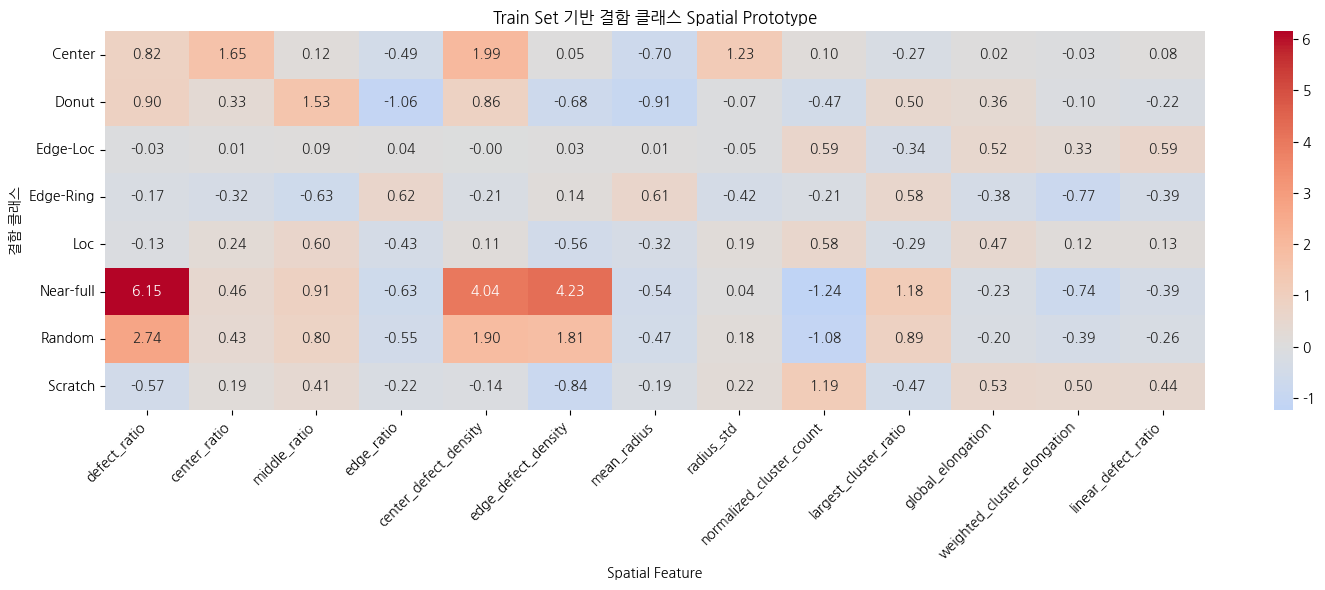

In [284]:
# Train 기반 Spatial Prototype 시각화

plt.figure(
    figsize=(15, 6)
)


sns.heatmap(
    class_prototype_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)


plt.xlabel(
    "Spatial Feature"
)

plt.ylabel(
    "결함 클래스"
)

plt.title(
    "Train Set 기반 결함 클래스 Spatial Prototype"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.show()

In [285]:
# Test Spatial Feature를 Train 기준으로 Scaling

test_feature_matrix = (
    prediction_df[
        SPATIAL_FEATURES
    ]
    .astype(float)
)


test_scaled_features = (
    (
        test_feature_matrix
        -
        spatial_scaler_median
    )
    /
    spatial_scaler_iqr
)


print(
    "=== Test Spatial Feature Scaling ==="
)

print(
    "Shape:",
    test_scaled_features.shape
)

print(
    "NaN 수:",
    int(
        test_scaled_features
        .isnull()
        .sum()
        .sum()
    )
)


assert (
    test_scaled_features
    .isnull()
    .sum()
    .sum()
    ==
    0
)


print(
    "✓ Test Feature가 Train 기준으로 정상적으로 Scaling되었습니다."
)

=== Test Spatial Feature Scaling ===
Shape: (3911, 13)
NaN 수: 0
✓ Test Feature가 Train 기준으로 정상적으로 Scaling되었습니다.


In [286]:
# Step 5-4. Test Wafer와 Class Prototype 간 거리 계산

prototype_distance_rows = []


for sample_pos in range(
    len(prediction_df)
):

    sample_features = (
        test_scaled_features
        .iloc[
            sample_pos
        ]
        .values
    )


    distances = {}


    for class_name in CLASS_NAMES:

        prototype = (
            class_prototype_df
            .loc[
                class_name
            ]
            .values
        )


        distance = float(
            np.mean(
                np.abs(
                    sample_features
                    -
                    prototype
                )
            )
        )


        distances[
            class_name
        ] = distance


    # 가까운 순서
    sorted_classes = sorted(
        distances,
        key=distances.get
    )


    nearest_class = (
        sorted_classes[0]
    )

    second_nearest_class = (
        sorted_classes[1]
    )


    prototype_distance_rows.append({

        "sample_pos":
            sample_pos,

        "nearest_prototype_label":
            nearest_class,

        "nearest_prototype_distance":
            distances[
                nearest_class
            ],

        "second_nearest_prototype_label":
            second_nearest_class,

        "second_nearest_prototype_distance":
            distances[
                second_nearest_class
            ],

        **{
            f"distance_to_{class_name}":
                distances[class_name]

            for class_name
            in CLASS_NAMES
        }
    })


prototype_distance_df = pd.DataFrame(
    prototype_distance_rows
)


print(
    "=== Prototype Distance 계산 완료 ==="
)

print(
    "Shape:",
    prototype_distance_df.shape
)


display(
    prototype_distance_df.head()
    .style.format({
        column: "{:.4f}"
        for column
        in prototype_distance_df.columns
        if column.startswith(
            "distance"
        )
        or
        column.endswith(
            "_distance"
        )
    })
)

=== Prototype Distance 계산 완료 ===
Shape: (3911, 13)


,sample_pos,nearest_prototype_label,nearest_prototype_distance,second_nearest_prototype_label,second_nearest_prototype_distance,distance_to_Center,distance_to_Donut,distance_to_Edge-Loc,distance_to_Edge-Ring,distance_to_Loc,distance_to_Near-full,distance_to_Random,distance_to_Scratch
0,0,Edge-Loc,0.3311,Loc,0.4073,0.6485,0.6589,0.3311,0.6752,0.4073,1.6010,0.8818,0.4872
1,1,Loc,0.2195,Edge-Loc,0.2659,0.6283,0.5861,0.2659,0.6413,0.2195,1.6177,0.8992,0.3618
2,2,Donut,0.4943,Loc,0.6383,0.6922,0.4943,0.6948,1.0275,0.6383,1.4440,0.7670,0.7827
3,3,Edge-Loc,0.8176,Edge-Ring,0.8461,1.2010,1.0305,0.8176,0.8461,1.0152,1.3947,0.8622,1.1144
4,4,Random,0.4640,Edge-Ring,0.8164,1.0390,0.9038,0.9494,0.8164,1.0476,0.9556,0.4640,1.2002


In [287]:
# Prediction 결과와 Prototype Similarity 연결

prototype_analysis_df = (
    prediction_df
    .merge(
        prototype_distance_df,
        on="sample_pos",
        how="left",
        validate="one_to_one"
    )
)


# --------------------------------------------------
# True Class까지의 거리
# --------------------------------------------------

prototype_analysis_df[
    "true_prototype_distance"
] = [

    row[
        f"distance_to_{row['true_label']}"
    ]

    for _, row
    in prototype_analysis_df.iterrows()
]


# --------------------------------------------------
# CNN Predicted Class까지의 거리
# --------------------------------------------------

prototype_analysis_df[
    "pred_prototype_distance"
] = [

    row[
        f"distance_to_{row['pred_label']}"
    ]

    for _, row
    in prototype_analysis_df.iterrows()
]


# --------------------------------------------------
# Nearest Prototype이 True Label과 같은가?
# --------------------------------------------------

prototype_analysis_df[
    "nearest_matches_true"
] = (

    prototype_analysis_df[
        "nearest_prototype_label"
    ]

    ==

    prototype_analysis_df[
        "true_label"
    ]
)


# --------------------------------------------------
# Nearest Prototype이 CNN Prediction과 같은가?
# --------------------------------------------------

prototype_analysis_df[
    "nearest_matches_prediction"
] = (

    prototype_analysis_df[
        "nearest_prototype_label"
    ]

    ==

    prototype_analysis_df[
        "pred_label"
    ]
)


# --------------------------------------------------
# Predicted Prototype이 True Prototype보다
# 얼마나 더 가까운가?
#
# + 값:
# Predicted class prototype이 더 가까움
#
# - 값:
# True class prototype이 더 가까움
# --------------------------------------------------

prototype_analysis_df[
    "predicted_profile_advantage"
] = (

    prototype_analysis_df[
        "true_prototype_distance"
    ]

    -

    prototype_analysis_df[
        "pred_prototype_distance"
    ]
)


print(
    "=== Prototype Similarity Analysis ==="
)


display(
    prototype_analysis_df[
        [
            "sample_pos",
            "true_label",
            "pred_label",
            "correct",

            "nearest_prototype_label",

            "true_prototype_distance",
            "pred_prototype_distance",
            "predicted_profile_advantage",

            "nearest_matches_true",
            "nearest_matches_prediction",

            "top1_prob"
        ]
    ]
    .head(15)
    .style.format({

        "true_prototype_distance":
            "{:.4f}",

        "pred_prototype_distance":
            "{:.4f}",

        "predicted_profile_advantage":
            "{:+.4f}",

        "top1_prob":
            "{:.4f}"
    })
)

=== Prototype Similarity Analysis ===


,sample_pos,true_label,pred_label,correct,nearest_prototype_label,true_prototype_distance,pred_prototype_distance,predicted_profile_advantage,nearest_matches_true,nearest_matches_prediction,top1_prob
0,0,Scratch,Loc,False,Edge-Loc,0.4872,0.4073,+0.0799,False,False,0.7568
1,1,Edge-Loc,Edge-Loc,True,Loc,0.2659,0.2659,+0.0000,False,False,0.6974
2,2,Loc,Loc,True,Donut,0.6383,0.6383,+0.0000,False,False,1.0000
3,3,Edge-Loc,Edge-Loc,True,Edge-Loc,0.8176,0.8176,+0.0000,True,True,1.0000
4,4,Edge-Loc,Edge-Loc,True,Random,0.9494,0.9494,+0.0000,False,False,0.9988
5,5,Edge-Loc,Edge-Loc,True,Edge-Loc,0.2076,0.2076,+0.0000,True,True,0.9972
6,6,Scratch,Edge-Loc,False,Edge-Loc,0.3531,0.1874,+0.1657,False,True,0.9922
7,7,Near-full,Near-full,True,Near-full,0.2336,0.2336,+0.0000,True,True,0.9949
8,8,Edge-Loc,Edge-Loc,True,Edge-Loc,0.3831,0.3831,+0.0000,True,True,0.9999
9,9,Edge-Loc,Edge-Ring,False,Edge-Loc,0.3181,0.6391,-0.3210,True,False,0.8528


## Step 5-5. Prototype 기반 CNN 오분류 유형 분석

CNN이 오분류한 Test Wafer에 대해 실제 클래스 Prototype과 CNN 예측 클래스 Prototype까지의 거리를 비교한다.

단순한 거리 차이는 Wafer마다 전체 거리 수준이 다르기 때문에 직접 비교하기 어려울 수 있다. 따라서 실제 클래스와 예측 클래스까지의 거리 차이를 두 거리의 합으로 나눈 **Relative Prototype Advantage**를 추가로 계산한다.

- 양수: CNN이 예측한 클래스 Prototype에 상대적으로 더 가까움
- 음수: 실제 클래스 Prototype에 상대적으로 더 가까움
- 0에 가까움: 두 Prototype 사이의 경계에 가까움

이를 바탕으로 오분류를 다음과 같이 구분한다.

1. **Predicted-like**
   - Spatial Feature 역시 CNN이 잘못 예측한 클래스의 전형적인 패턴에 가까운 경우

2. **True-like**
   - Spatial Feature는 실제 라벨의 전형적인 패턴에 가까운데 CNN만 잘못 판단한 경우

3. **Boundary-like**
   - 실제 클래스와 예측 클래스 Prototype까지의 거리가 비슷한 경우

4. **Third-class-like**
   - 실제 클래스나 CNN 예측 클래스가 아닌 제3의 클래스 Prototype과 가장 가까운 경우

이 구분은 라벨 오류를 확정하기 위한 것이 아니라, CNN 오류의 구조와 클래스 경계 및 혼합 패턴 가능성을 분석하기 위한 진단 기준이다.

In [288]:
# Step 5-5. Prototype 기반 오분류 분석

prototype_error_df = (
    prototype_analysis_df[
        ~prototype_analysis_df["correct"]
    ]
    .copy()
    .reset_index(drop=True)
)


# --------------------------------------------------
# 실제 / 예측 Prototype 간 상대적 거리 차이
#
# + : Prediction Prototype이 더 가까움
# - : True Prototype이 더 가까움
# --------------------------------------------------

prototype_error_df[
    "relative_profile_advantage"
] = (

    prototype_error_df[
        "true_prototype_distance"
    ]

    -

    prototype_error_df[
        "pred_prototype_distance"
    ]

) / (

    prototype_error_df[
        "true_prototype_distance"
    ]

    +

    prototype_error_df[
        "pred_prototype_distance"
    ]

    + 1e-12
)


# --------------------------------------------------
# 기존 Step 2 정보도 다시 생성
# --------------------------------------------------

prototype_error_df[
    "high_confidence_error"
] = (
    prototype_error_df[
        "top1_prob"
    ]
    >= 0.90
)


prototype_error_df[
    "true_is_second_choice"
] = (
    prototype_error_df[
        "true_idx"
    ]
    ==
    prototype_error_df[
        "second_idx"
    ]
)


print(
    "=== Prototype Error Analysis ==="
)

print(
    "전체 오분류:",
    len(prototype_error_df)
)


display(
    prototype_error_df[
        [
            "sample_pos",
            "true_label",
            "pred_label",
            "nearest_prototype_label",

            "true_prototype_distance",
            "pred_prototype_distance",

            "predicted_profile_advantage",
            "relative_profile_advantage",

            "top1_prob",
            "high_confidence_error",
            "true_is_second_choice"
        ]
    ]
    .head(15)
    .style.format({
        "true_prototype_distance": "{:.4f}",
        "pred_prototype_distance": "{:.4f}",
        "predicted_profile_advantage": "{:+.4f}",
        "relative_profile_advantage": "{:+.4f}",
        "top1_prob": "{:.4f}"
    })
)

=== Prototype Error Analysis ===
전체 오분류: 375


,sample_pos,true_label,pred_label,nearest_prototype_label,true_prototype_distance,pred_prototype_distance,predicted_profile_advantage,relative_profile_advantage,top1_prob,high_confidence_error,true_is_second_choice
0,0,Scratch,Loc,Edge-Loc,0.4872,0.4073,+0.0799,+0.0893,0.7568,False,True
1,6,Scratch,Edge-Loc,Edge-Loc,0.3531,0.1874,+0.1657,+0.3066,0.9922,True,False
2,9,Edge-Loc,Edge-Ring,Edge-Loc,0.3181,0.6391,-0.3210,-0.3353,0.8528,False,True
3,18,Scratch,Loc,Edge-Loc,0.2746,0.2788,-0.0043,-0.0077,0.4199,False,True
4,20,Scratch,Edge-Loc,Edge-Loc,0.3397,0.1954,+0.1442,+0.2696,0.5790,False,True
5,21,Scratch,Loc,Loc,0.3823,0.2937,+0.0886,+0.1311,0.7623,False,False
6,22,Loc,Center,Center,0.9466,0.5869,+0.3597,+0.2346,0.8244,False,True
7,29,Random,Near-full,Near-full,0.5867,0.2318,+0.3549,+0.4336,0.7440,False,True
8,60,Edge-Ring,Edge-Loc,Edge-Loc,0.8229,0.5505,+0.2723,+0.1983,0.4667,False,False
9,112,Scratch,Edge-Ring,Edge-Ring,0.6953,0.1920,+0.5032,+0.5671,1.0000,True,False


In [289]:
# Prototype 기반 오분류 유형 정의

PROTOTYPE_BOUNDARY_THRESHOLD = 0.10


def classify_prototype_error(row):

    nearest_label = (
        row["nearest_prototype_label"]
    )

    true_label = (
        row["true_label"]
    )

    pred_label = (
        row["pred_label"]
    )

    relative_advantage = (
        row["relative_profile_advantage"]
    )


    # --------------------------------------------------
    # 제3의 클래스 Prototype이 가장 가까움
    # --------------------------------------------------

    if (
        nearest_label != true_label
        and
        nearest_label != pred_label
    ):

        return (
            "4. Third-class-like"
        )


    # --------------------------------------------------
    # True / Pred Prototype 사이 경계
    # --------------------------------------------------

    if (
        abs(relative_advantage)
        <
        PROTOTYPE_BOUNDARY_THRESHOLD
    ):

        return (
            "3. Boundary-like"
        )


    # --------------------------------------------------
    # Prediction Prototype 쪽
    # --------------------------------------------------

    if (
        relative_advantage
        > 0
    ):

        return (
            "1. Predicted-like"
        )


    # --------------------------------------------------
    # True Prototype 쪽
    # --------------------------------------------------

    return (
        "2. True-like"
    )


prototype_error_df[
    "prototype_error_type"
] = (
    prototype_error_df.apply(
        classify_prototype_error,
        axis=1
    )
)


print(
    "=== Prototype 기반 CNN 오류 유형 ==="
)


prototype_error_type_summary_df = (

    prototype_error_df

    .groupby(
        "prototype_error_type",
        as_index=False
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        ),

        median_relative_advantage=(
            "relative_profile_advantage",
            "median"
        ),

        high_confidence_count=(
            "high_confidence_error",
            "sum"
        ),

        true_second_count=(
            "true_is_second_choice",
            "sum"
        )
    )
)


prototype_error_type_summary_df[
    "sample_ratio"
] = (
    prototype_error_type_summary_df[
        "sample_count"
    ]
    /
    len(prototype_error_df)
)


prototype_error_type_summary_df[
    "high_confidence_rate"
] = (
    prototype_error_type_summary_df[
        "high_confidence_count"
    ]
    /
    prototype_error_type_summary_df[
        "sample_count"
    ]
)


prototype_error_type_summary_df[
    "true_second_rate"
] = (
    prototype_error_type_summary_df[
        "true_second_count"
    ]
    /
    prototype_error_type_summary_df[
        "sample_count"
    ]
)


prototype_error_type_summary_df = (
    prototype_error_type_summary_df
    .sort_values(
        "prototype_error_type"
    )
    .reset_index(drop=True)
)


display(
    prototype_error_type_summary_df
    .style.format({

        "median_top1_prob":
            "{:.4f}",

        "median_relative_advantage":
            "{:+.4f}",

        "sample_ratio":
            "{:.4f}",

        "high_confidence_rate":
            "{:.4f}",

        "true_second_rate":
            "{:.4f}"
    })
)

=== Prototype 기반 CNN 오류 유형 ===


,prototype_error_type,sample_count,median_top1_prob,median_relative_advantage,high_confidence_count,true_second_count,sample_ratio,high_confidence_rate,true_second_rate
0,1. Predicted-like,96,0.6750,+0.2127,16,70,0.2560,0.1667,0.7292
1,2. True-like,114,0.6502,-0.2185,13,96,0.3040,0.1140,0.8421
2,3. Boundary-like,71,0.6062,-0.0098,6,61,0.1893,0.0845,0.8592
3,4. Third-class-like,94,0.7563,+0.0501,24,73,0.2507,0.2553,0.7766


In [290]:
# Step 5-6. 정분류 vs 오분류의 True Prototype Distance

prototype_typicality_summary_df = (

    prototype_analysis_df

    .groupby(
        "correct"
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        median_true_distance=(
            "true_prototype_distance",
            "median"
        ),

        mean_true_distance=(
            "true_prototype_distance",
            "mean"
        ),

        nearest_true_rate=(
            "nearest_matches_true",
            "mean"
        )
    )

    .reset_index()
)


prototype_typicality_summary_df[
    "prediction_result"
] = np.where(
    prototype_typicality_summary_df[
        "correct"
    ],
    "Correct",
    "Misclassified"
)


prototype_typicality_summary_df = (
    prototype_typicality_summary_df[
        [
            "prediction_result",
            "sample_count",
            "median_true_distance",
            "mean_true_distance",
            "nearest_true_rate"
        ]
    ]
)


print(
    "=== 정분류 vs 오분류 Prototype Typicality ==="
)


display(
    prototype_typicality_summary_df
    .style.format({

        "median_true_distance":
            "{:.4f}",

        "mean_true_distance":
            "{:.4f}",

        "nearest_true_rate":
            "{:.4f}"
    })
)

=== 정분류 vs 오분류 Prototype Typicality ===


,prediction_result,sample_count,median_true_distance,mean_true_distance,nearest_true_rate
0,Misclassified,375,0.4353,0.4742,0.4053
1,Correct,3536,0.2984,0.3609,0.6994


In [291]:
# True Prototype Distance 통계 검정

correct_true_distance = (
    prototype_analysis_df.loc[
        prototype_analysis_df["correct"],
        "true_prototype_distance"
    ]
    .values
)


error_true_distance = (
    prototype_analysis_df.loc[
        ~prototype_analysis_df["correct"],
        "true_prototype_distance"
    ]
    .values
)


u_statistic, p_value = mannwhitneyu(
    correct_true_distance,
    error_true_distance,
    alternative="two-sided"
)


rank_biserial = (
    2 * u_statistic
    /
    (
        len(correct_true_distance)
        *
        len(error_true_distance)
    )
    - 1
)


print(
    "=== True Prototype Distance 통계 검정 ==="
)

print(
    "Correct Median:",
    round(
        np.median(
            correct_true_distance
        ),
        4
    )
)

print(
    "Misclassified Median:",
    round(
        np.median(
            error_true_distance
        ),
        4
    )
)

print(
    "Mann-Whitney p-value:",
    f"{p_value:.3e}"
)

print(
    "Rank-Biserial:",
    f"{rank_biserial:+.4f}"
)

=== True Prototype Distance 통계 검정 ===
Correct Median: 0.2984
Misclassified Median: 0.4353
Mann-Whitney p-value: 5.824e-26
Rank-Biserial: -0.3304


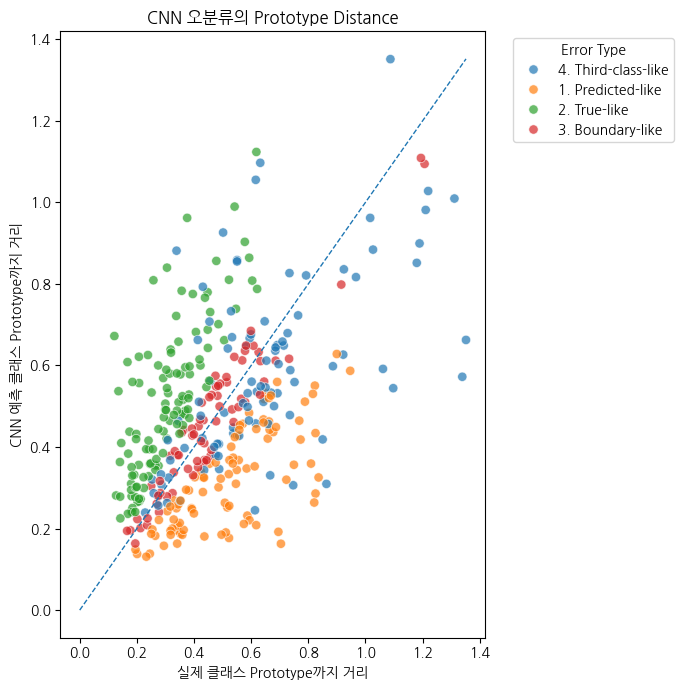

In [292]:
# True Prototype vs Predicted Prototype Distance

plt.figure(
    figsize=(7, 7)
)


sns.scatterplot(

    data=prototype_error_df,

    x="true_prototype_distance",

    y="pred_prototype_distance",

    hue="prototype_error_type",

    alpha=0.7,

    s=45
)


max_distance = max(

    prototype_error_df[
        "true_prototype_distance"
    ].max(),

    prototype_error_df[
        "pred_prototype_distance"
    ].max()
)


plt.plot(
    [0, max_distance],
    [0, max_distance],
    linestyle="--",
    linewidth=1
)


plt.xlabel(
    "실제 클래스 Prototype까지 거리"
)

plt.ylabel(
    "CNN 예측 클래스 Prototype까지 거리"
)

plt.title(
    "CNN 오분류의 Prototype Distance"
)

plt.legend(
    title="Error Type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

## Step 5-7. Confidence와 Prototype Similarity를 결합한 오류 진단

지금까지 CNN의 Confidence와 Spatial Prototype Similarity를 서로 독립적으로 분석하였다.

CNN Confidence는 모델이 자신의 예측을 얼마나 강하게 확신하는지를 나타내고, Prototype Similarity는 웨이퍼의 실제 공간적 구조가 어떤 결함 클래스의 대표 패턴과 가까운지를 나타낸다.

두 정보를 결합하면 동일한 오분류라도 서로 다른 성격의 오류를 구분할 수 있다.

### 1. High-confidence Predicted-like Error
CNN이 잘못된 클래스를 높은 확률로 확신하며, Spatial Feature 역시 예측 클래스 Prototype에 가까운 경우이다.

이는 실제 웨이퍼 패턴 자체가 다른 클래스와 유사하거나 혼합된 형태일 가능성이 있으므로 우선적인 패턴 검토 대상이 된다.

### 2. High-confidence True-like Error
CNN은 높은 확률로 잘못 예측했지만, Spatial Feature는 실제 클래스 Prototype에 더 가까운 경우이다.

이는 모델이 전형적인 공간 정보를 충분히 활용하지 못했거나 다른 이미지 특징에 과도하게 반응했을 가능성이 있어 모델 해석의 중요한 대상이 된다.

### 3. Predicted-like Error
높은 Confidence는 아니지만 Spatial Feature가 CNN 예측 클래스의 대표 패턴에 더 가까운 경우이다.

클래스 간 형태적 중첩 또는 비전형적인 실제 라벨 패턴 가능성을 검토할 수 있다.

### 4. True-like Error
Spatial Feature는 실제 클래스에 더 가까운데 CNN이 다른 클래스로 예측한 경우이다.

CNN의 Feature Extraction 또는 Attention 과정에서 발생한 오류 가능성을 조사할 수 있다.

### 5. Boundary-like Error
실제 클래스와 예측 클래스 Prototype까지의 거리가 비슷한 경우이다.

두 클래스 사이의 경계 패턴 또는 혼합 패턴일 가능성이 있다.

### 6. Third-class-like Error
실제 클래스와 CNN 예측 클래스가 아닌 제3의 클래스 Prototype에 가장 가까운 경우이다.

현재의 단일 라벨 체계로 충분히 설명되지 않는 복합적 또는 비전형적인 패턴일 가능성이 있으므로 별도의 검토 대상으로 분류한다.

이 진단 그룹은 라벨 오류나 물리적 Root Cause를 확정하는 기준이 아니라, 이후 상세 분석의 우선순위를 설정하기 위한 탐색적 분류이다.

In [293]:
# Step 5-7. Confidence + Prototype 기반 최종 오류 진단

def assign_final_error_group(row):

    prototype_type = (
        row["prototype_error_type"]
    )

    high_confidence = (
        row["high_confidence_error"]
    )


    if (
        prototype_type
        == "1. Predicted-like"
        and high_confidence
    ):

        return (
            "1. High-confidence Predicted-like"
        )


    if (
        prototype_type
        == "2. True-like"
        and high_confidence
    ):

        return (
            "2. High-confidence True-like"
        )


    if (
        prototype_type
        == "1. Predicted-like"
    ):

        return (
            "3. Predicted-like"
        )


    if (
        prototype_type
        == "2. True-like"
    ):

        return (
            "4. True-like"
        )


    if (
        prototype_type
        == "3. Boundary-like"
    ):

        return (
            "5. Boundary-like"
        )


    if (
        prototype_type
        == "4. Third-class-like"
    ):

        return (
            "6. Third-class-like"
        )


    return "Unknown"


prototype_error_df[
    "final_error_group"
] = (
    prototype_error_df.apply(
        assign_final_error_group,
        axis=1
    )
)


print(
    "=== 최종 CNN Error Diagnostic Group ==="
)


final_error_group_summary_df = (

    prototype_error_df

    .groupby(
        "final_error_group",
        as_index=False
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        ),

        median_margin=(
            "confidence_margin",
            "median"
        ),

        median_true_distance=(
            "true_prototype_distance",
            "median"
        ),

        median_relative_advantage=(
            "relative_profile_advantage",
            "median"
        ),

        true_second_count=(
            "true_is_second_choice",
            "sum"
        )
    )
)


final_error_group_summary_df[
    "sample_ratio"
] = (
    final_error_group_summary_df[
        "sample_count"
    ]
    /
    len(prototype_error_df)
)


final_error_group_summary_df[
    "true_second_rate"
] = (
    final_error_group_summary_df[
        "true_second_count"
    ]
    /
    final_error_group_summary_df[
        "sample_count"
    ]
)


final_error_group_summary_df = (
    final_error_group_summary_df
    .sort_values(
        "final_error_group"
    )
    .reset_index(drop=True)
)


display(
    final_error_group_summary_df
    .style.format({

        "median_top1_prob":
            "{:.4f}",

        "median_margin":
            "{:.4f}",

        "median_true_distance":
            "{:.4f}",

        "median_relative_advantage":
            "{:+.4f}",

        "sample_ratio":
            "{:.4f}",

        "true_second_rate":
            "{:.4f}"
    })
)


print(
    "\n총 오류:",
    final_error_group_summary_df[
        "sample_count"
    ].sum()
)

=== 최종 CNN Error Diagnostic Group ===


,final_error_group,sample_count,median_top1_prob,median_margin,median_true_distance,median_relative_advantage,true_second_count,sample_ratio,true_second_rate
0,1. High-confidence Predicted-like,16,0.9660,0.9343,0.4935,+0.3024,8,0.0427,0.5000
1,2. High-confidence True-like,13,0.9645,0.9375,0.3148,-0.2922,10,0.0347,0.7692
2,3. Predicted-like,80,0.6131,0.3053,0.5363,+0.2024,62,0.2133,0.7750
3,4. True-like,101,0.6212,0.3088,0.2997,-0.2173,86,0.2693,0.8515
4,5. Boundary-like,71,0.6062,0.3317,0.4358,-0.0098,61,0.1893,0.8592
5,6. Third-class-like,94,0.7563,0.5866,0.6075,+0.0501,73,0.2507,0.7766



총 오류: 375


In [294]:
# 진단 그룹별 주요 Error Pair

prototype_error_df[
    "error_pair"
] = (
    prototype_error_df[
        "true_label"
    ]
    +
    " → "
    +
    prototype_error_df[
        "pred_label"
    ]
)


diagnostic_pair_df = (

    prototype_error_df

    .groupby(
        [
            "final_error_group",
            "error_pair"
        ],
        as_index=False
    )

    .agg(
        sample_count=(
            "sample_pos",
            "count"
        )
    )

    .sort_values(
        [
            "final_error_group",
            "sample_count"
        ],
        ascending=[
            True,
            False
        ]
    )
)


top_diagnostic_pair_df = (

    diagnostic_pair_df

    .groupby(
        "final_error_group",
        group_keys=False
    )

    .head(5)

    .reset_index(drop=True)
)


print(
    "=== 진단 그룹별 주요 Error Pair ==="
)


display(
    top_diagnostic_pair_df
)

=== 진단 그룹별 주요 Error Pair ===


,final_error_group,error_pair,sample_count
0,1. High-confidence Predicted-like,Edge-Ring → Edge-Loc,4
1,1. High-confidence Predicted-like,Scratch → Edge-Loc,4
2,1. High-confidence Predicted-like,Loc → Edge-Loc,3
3,1. High-confidence Predicted-like,Edge-Loc → Random,1
4,1. High-confidence Predicted-like,Loc → Center,1
5,2. High-confidence True-like,Edge-Loc → Edge-Ring,5
6,2. High-confidence True-like,Donut → Loc,1
7,2. High-confidence True-like,Loc → Center,1
8,2. High-confidence True-like,Loc → Donut,1
9,2. High-confidence True-like,Random → Center,1


In [295]:
# Step 5-8. 진단 그룹별 대표 샘플 선정

representative_error_rows = []


for group_name, group_df in (
    prototype_error_df.groupby(
        "final_error_group"
    )
):

    group_df = (
        group_df.copy()
    )


    # ----------------------------------------------
    # 그룹 특성에 따라 우선순위 설정
    # ----------------------------------------------

    if (
        "High-confidence"
        in group_name
    ):

        # 가장 확신한 오류 우선
        selected = (
            group_df
            .sort_values(
                "top1_prob",
                ascending=False
            )
            .head(5)
        )

    elif (
        group_name
        == "5. Boundary-like"
    ):

        # 상대적 거리차이가 0에 가까운 샘플 우선
        group_df[
            "boundary_score"
        ] = np.abs(
            group_df[
                "relative_profile_advantage"
            ]
        )

        selected = (
            group_df
            .sort_values(
                "boundary_score",
                ascending=True
            )
            .head(5)
        )

    elif (
        group_name
        == "6. Third-class-like"
    ):

        # 실제 Prototype에서 가장 멀리 벗어난 샘플
        selected = (
            group_df
            .sort_values(
                "true_prototype_distance",
                ascending=False
            )
            .head(5)
        )

    else:

        # Prototype 방향성이 가장 강한 샘플
        selected = (
            group_df
            .assign(
                prototype_strength=lambda x:
                np.abs(
                    x[
                        "relative_profile_advantage"
                    ]
                )
            )
            .sort_values(
                "prototype_strength",
                ascending=False
            )
            .head(5)
        )


    representative_error_rows.append(
        selected
    )


representative_error_df = pd.concat(
    representative_error_rows,
    ignore_index=True
)


print(
    "=== 대표 CNN Error Samples ==="
)


display_columns = [

    "final_error_group",

    "sample_pos",
    "lot_name",

    "true_label",
    "pred_label",

    "top1_prob",
    "second_label",
    "second_prob",

    "nearest_prototype_label",

    "true_prototype_distance",
    "pred_prototype_distance",

    "relative_profile_advantage"
]


display(
    representative_error_df[
        display_columns
    ]
    .style.format({

        "top1_prob":
            "{:.4f}",

        "second_prob":
            "{:.4f}",

        "true_prototype_distance":
            "{:.4f}",

        "pred_prototype_distance":
            "{:.4f}",

        "relative_profile_advantage":
            "{:+.4f}"
    })
)

=== 대표 CNN Error Samples ===


,final_error_group,sample_pos,lot_name,true_label,pred_label,top1_prob,second_label,second_prob,nearest_prototype_label,true_prototype_distance,pred_prototype_distance,relative_profile_advantage
0,1. High-confidence Predicted-like,112,lot2157,Scratch,Edge-Ring,1.0000,Edge-Loc,0.0000,Edge-Ring,0.6953,0.1920,+0.5671
1,1. High-confidence Predicted-like,2180,lot30429,Scratch,Edge-Loc,0.9977,Edge-Ring,0.0015,Edge-Loc,0.4756,0.3620,+0.1356
2,1. High-confidence Predicted-like,2999,lot43552,Loc,Edge-Loc,0.9974,Edge-Ring,0.0018,Edge-Loc,0.3290,0.2222,+0.1937
3,1. High-confidence Predicted-like,2939,lot42858,Edge-Ring,Edge-Loc,0.9933,Edge-Ring,0.0065,Edge-Loc,0.5224,0.1770,+0.4939
4,1. High-confidence Predicted-like,6,lot123,Scratch,Edge-Loc,0.9922,Edge-Ring,0.0042,Edge-Loc,0.3531,0.1874,+0.3066
5,2. High-confidence True-like,879,lot13921,Random,Loc,0.9946,Center,0.0032,Random,0.5420,0.9896,-0.2922
6,2. High-confidence True-like,3206,lot44268,Edge-Loc,Edge-Ring,0.9936,Edge-Loc,0.0064,Edge-Loc,0.1847,0.5596,-0.5038
7,2. High-confidence True-like,3276,lot44803,Edge-Loc,Edge-Ring,0.9913,Edge-Loc,0.0087,Edge-Loc,0.2387,0.6256,-0.4476
8,2. High-confidence True-like,1223,lot17127,Loc,Donut,0.9761,Loc,0.0239,Loc,0.3691,0.4889,-0.1396
9,2. High-confidence True-like,3419,lot45495,Donut,Loc,0.9719,Donut,0.0281,Donut,0.1672,0.6083,-0.5689


In [296]:
# Step 5 주요 결과 저장

step5_prototype_analysis_df = (
    prototype_analysis_df.copy()
)

step5_prototype_error_df = (
    prototype_error_df.copy()
)

step5_final_error_group_summary_df = (
    final_error_group_summary_df.copy()
)

step5_representative_error_df = (
    representative_error_df.copy()
)


print(
    "=== Step 5 저장 변수 ==="
)

print(
    "step5_prototype_analysis_df:",
    step5_prototype_analysis_df.shape
)

print(
    "step5_prototype_error_df:",
    step5_prototype_error_df.shape
)

print(
    "step5_final_error_group_summary_df:",
    step5_final_error_group_summary_df.shape
)

print(
    "step5_representative_error_df:",
    step5_representative_error_df.shape
)

=== Step 5 저장 변수 ===
step5_prototype_analysis_df: (3911, 63)
step5_prototype_error_df: (375, 69)
step5_final_error_group_summary_df: (6, 9)
step5_representative_error_df: (30, 71)


## Step 5 결과 요약

Train Set의 13개 Spatial Feature를 이용하여 각 결함 클래스의 대표 Prototype을 생성하고, Test Wafer와 각 Prototype 사이의 거리를 분석하였다.

정분류 샘플의 실제 클래스 Prototype까지의 중앙거리는 0.2987이었던 반면, 오분류 샘플에서는 0.4350으로 증가하였다.

Mann-Whitney U Test에서도 두 그룹 사이의 차이가 통계적으로 유의하게 나타났으며, CNN 오류가 실제 클래스의 전형적인 Spatial Pattern에서 벗어난 샘플과 연관되어 있음을 확인하였다.

또한 정분류 샘플에서는 약 69.9%가 실제 클래스 Prototype과 가장 가까웠지만, 오분류 샘플에서는 그 비율이 약 39.4%로 감소하였다.

이를 통해 CNN 오분류를 단순한 하나의 오류 유형으로 처리하지 않고, CNN Confidence와 Spatial Prototype Similarity를 함께 이용하여 여러 진단 그룹으로 구분하였다.

이 분석은 이후 Grad-CAM에서 서로 다른 성격의 오류가 CNN 내부 Attention 측면에서도 차이를 보이는지 확인하기 위한 기준으로 사용한다.

# Step 6. Grad-CAM을 이용한 CNN 판단 영역 분석

Step 5에서는 Spatial Feature와 Prototype Similarity를 이용하여 CNN 오분류를 여러 유형으로 구분하였다.

그러나 Spatial Feature는 사람이 정의한 위치·군집·형태 정보이므로, CNN이 실제로 이미지의 어느 영역을 이용하여 판단했는지는 직접적으로 알 수 없다.

따라서 이번 단계에서는 **Grad-CAM (Gradient-weighted Class Activation Mapping)**을 이용하여 CNN의 예측에 영향을 준 공간 영역을 시각화한다.

Grad-CAM은 특정 클래스의 예측값에 영향을 크게 준 Convolution Feature Map의 영역을 계산하여 Heatmap 형태로 보여준다.

본 분석에서는 Simple CNN의 마지막 Convolution Layer를 사용한다.

특히 오분류 샘플에 대해서는 두 종류의 Grad-CAM을 비교한다.

- **Predicted Class Grad-CAM**
  - CNN이 실제로 선택한 잘못된 클래스를 판단할 때 집중한 영역

- **True Class Grad-CAM**
  - 실제 정답 클래스의 score에 영향을 주는 영역

이를 통해 다음 질문을 분석한다.

1. 정분류와 오분류에서 CNN의 Attention 위치가 다른가?
2. Predicted-like Error에서는 CNN이 실제로 예측 클래스와 유사한 영역에 집중하는가?
3. True-like Error에서는 Spatial Pattern은 올바르지만 CNN Attention이 다른 영역으로 이동하는가?
4. 주요 혼동 클래스 사이에서 CNN이 사용하는 공간 정보에는 어떤 차이가 있는가?

Grad-CAM은 CNN의 판단을 완전히 설명하는 인과적 방법이 아니라, 모델이 특정 예측을 만들 때 중요하게 사용한 공간 영역을 탐색하는 해석 도구로 사용한다.

In [297]:
# Step 6-1. Grad-CAM 대상 Layer 확인

print("=== 최종 모델 확인 ===")
print("Model:", best_model_name)


assert best_model_name == "Simple CNN"


gradcam_target_layer = (
    best_model.features[6]
)


print(
    "\n=== Grad-CAM Target Layer ==="
)

print(
    gradcam_target_layer
)


# --------------------------------------------------
# Feature Map 크기 확인
# --------------------------------------------------

sample_image, _ = test_dataset[0]

sample_input = (
    sample_image
    .unsqueeze(0)
    .to(device)
)


with torch.no_grad():

    x = sample_input

    for layer_idx, layer in enumerate(
        best_model.features
    ):

        x = layer(x)

        print(
            f"Layer {layer_idx:02d} | "
            f"{layer.__class__.__name__:12s} | "
            f"{tuple(x.shape)}"
        )

=== 최종 모델 확인 ===
Model: Simple CNN

=== Grad-CAM Target Layer ===
Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Layer 00 | Conv2d       | (1, 16, 64, 64)
Layer 01 | ReLU         | (1, 16, 64, 64)
Layer 02 | MaxPool2d    | (1, 16, 32, 32)
Layer 03 | Conv2d       | (1, 32, 32, 32)
Layer 04 | ReLU         | (1, 32, 32, 32)
Layer 05 | MaxPool2d    | (1, 32, 16, 16)
Layer 06 | Conv2d       | (1, 64, 16, 16)
Layer 07 | ReLU         | (1, 64, 16, 16)
Layer 08 | MaxPool2d    | (1, 64, 8, 8)


In [298]:
# Grad-CAM 구현

import torch.nn.functional as F


class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None


        # Forward Hook
        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )


        # Backward Hook
        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self._backward_hook
            )
        )


    def _forward_hook(
        self,
        module,
        input,
        output
    ):

        self.activations = (
            output.detach()
        )


    def _backward_hook(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = (
            grad_output[0]
            .detach()
        )


    def generate(
        self,
        input_tensor,
        target_class
    ):

        self.model.eval()

        self.model.zero_grad()


        # ------------------------------------------
        # Forward
        # ------------------------------------------

        logits = self.model(
            input_tensor
        )


        target_score = (
            logits[
                :,
                target_class
            ]
            .sum()
        )


        # ------------------------------------------
        # Backward
        # ------------------------------------------

        target_score.backward()


        # ------------------------------------------
        # Channel Weight
        # ------------------------------------------

        weights = (
            self.gradients
            .mean(
                dim=(2, 3),
                keepdim=True
            )
        )


        # ------------------------------------------
        # Weighted Activation
        # ------------------------------------------

        cam = (
            weights
            *
            self.activations
        ).sum(
            dim=1,
            keepdim=True
        )


        # Positive contribution만 사용
        cam = F.relu(
            cam
        )


        # 입력 크기 64×64로 확대
        cam = F.interpolate(

            cam,

            size=(
                IMAGE_SIZE,
                IMAGE_SIZE
            ),

            mode="bilinear",

            align_corners=False
        )


        cam = (
            cam[
                0,
                0
            ]
            .cpu()
            .numpy()
        )


        # ------------------------------------------
        # 0~1 Normalize
        # ------------------------------------------

        cam_min = cam.min()
        cam_max = cam.max()


        if (
            cam_max
            >
            cam_min
        ):

            cam = (
                cam
                -
                cam_min
            ) / (
                cam_max
                -
                cam_min
            )

        else:

            cam = np.zeros_like(
                cam
            )


        return cam


    def remove_hooks(self):

        self.forward_handle.remove()
        self.backward_handle.remove()


print(
    "✓ Grad-CAM 함수 생성 완료"
)

✓ Grad-CAM 함수 생성 완료


In [299]:
# Step 6-2. 첫 Grad-CAM 분석 대상 선정

gradcam_candidate_df = (

    prototype_error_df[
        prototype_error_df[
            "final_error_group"
        ]
        ==
        "1. High-confidence Predicted-like"
    ]

    .sort_values(
        "top1_prob",
        ascending=False
    )

    .reset_index(drop=True)
)


gradcam_sample_row = (
    gradcam_candidate_df
    .iloc[0]
)


gradcam_sample_pos = int(
    gradcam_sample_row[
        "sample_pos"
    ]
)


print(
    "=== 첫 Grad-CAM 분석 대상 ==="
)

print(
    "Sample:",
    gradcam_sample_pos
)

print(
    "Lot:",
    gradcam_sample_row[
        "lot_name"
    ]
)

print(
    "True:",
    gradcam_sample_row[
        "true_label"
    ]
)

print(
    "Prediction:",
    gradcam_sample_row[
        "pred_label"
    ]
)

print(
    "CNN Confidence:",
    round(
        gradcam_sample_row[
            "top1_prob"
        ],
        4
    )
)

print(
    "Nearest Prototype:",
    gradcam_sample_row[
        "nearest_prototype_label"
    ]
)

print(
    "Relative Prototype Advantage:",
    round(
        gradcam_sample_row[
            "relative_profile_advantage"
        ],
        4
    )
)

=== 첫 Grad-CAM 분석 대상 ===
Sample: 112
Lot: lot2157
True: Scratch
Prediction: Edge-Ring
CNN Confidence: 1.0
Nearest Prototype: Edge-Ring
Relative Prototype Advantage: 0.5671


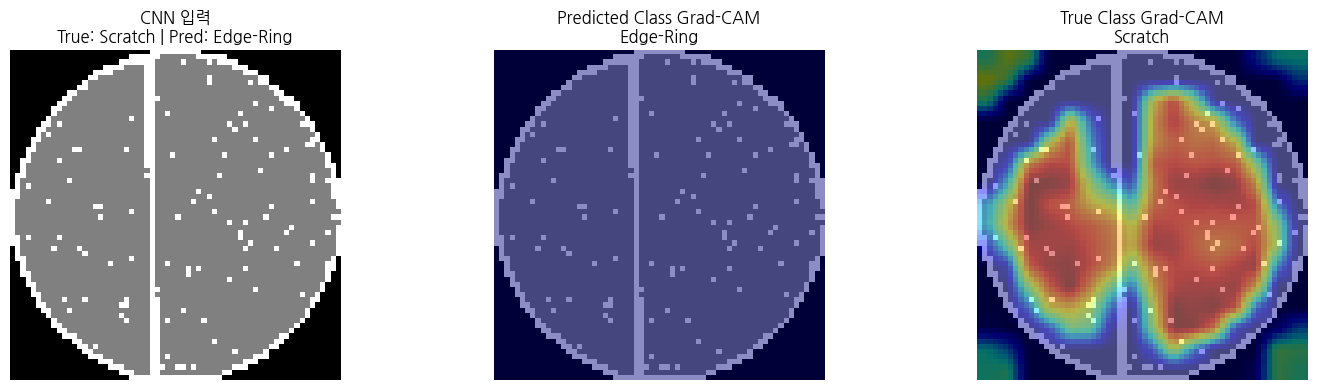

In [300]:
# 첫 오분류 샘플의 Grad-CAM

sample_image, sample_label = (
    test_dataset[
        gradcam_sample_pos
    ]
)


input_tensor = (
    sample_image
    .unsqueeze(0)
    .to(device)
)


true_class_idx = int(
    prediction_df.loc[
        prediction_df["sample_pos"]
        ==
        gradcam_sample_pos,
        "true_idx"
    ].iloc[0]
)


pred_class_idx = int(
    prediction_df.loc[
        prediction_df["sample_pos"]
        ==
        gradcam_sample_pos,
        "pred_idx"
    ].iloc[0]
)


true_label_name = (
    idx_to_label[
        true_class_idx
    ]
)


pred_label_name = (
    idx_to_label[
        pred_class_idx
    ]
)


# --------------------------------------------------
# Grad-CAM 생성
# --------------------------------------------------

gradcam = GradCAM(
    best_model,
    gradcam_target_layer
)


pred_cam = gradcam.generate(
    input_tensor,
    pred_class_idx
)


true_cam = gradcam.generate(
    input_tensor,
    true_class_idx
)


gradcam.remove_hooks()


# --------------------------------------------------
# CNN 입력 이미지
# --------------------------------------------------

processed_map = (
    sample_image
    .squeeze(0)
    .numpy()
)


# --------------------------------------------------
# 시각화
# --------------------------------------------------

plt.figure(
    figsize=(15, 4)
)


# 1. CNN Input
plt.subplot(
    1,
    3,
    1
)

plt.imshow(
    processed_map,
    cmap="gray",
    vmin=0,
    vmax=1
)

plt.title(
    f"CNN 입력\n"
    f"True: {true_label_name} | "
    f"Pred: {pred_label_name}"
)

plt.axis("off")


# 2. Predicted Class CAM
plt.subplot(
    1,
    3,
    2
)

plt.imshow(
    processed_map,
    cmap="gray",
    vmin=0,
    vmax=1
)

plt.imshow(
    pred_cam,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)

plt.title(
    f"Predicted Class Grad-CAM\n"
    f"{pred_label_name}"
)

plt.axis("off")


# 3. True Class CAM
plt.subplot(
    1,
    3,
    3
)

plt.imshow(
    processed_map,
    cmap="gray",
    vmin=0,
    vmax=1
)

plt.imshow(
    true_cam,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)

plt.title(
    f"True Class Grad-CAM\n"
    f"{true_label_name}"
)

plt.axis("off")


plt.tight_layout()
plt.show()

## Step 6-3. Grad-CAM 정량 분석

개별 Grad-CAM 이미지는 CNN이 어떤 영역을 중요하게 사용했는지 직관적으로 보여주지만, 몇 개의 이미지 사례만으로 정분류와 오분류의 차이를 일반화하기는 어렵다.

따라서 Grad-CAM을 수치화하여 여러 샘플을 비교한다.

Grad-CAM은 Convolution Feature Map의 해상도가 원본 이미지보다 낮기 때문에 확대 과정에서 Wafer 외부 영역까지 Activation이 번질 수 있다.

따라서 정량 분석에서는 **실제 Wafer 내부의 유효 die 영역만 사용한다.**

각 Grad-CAM에서 다음 지표를 계산한다.

- `defect_cam_share`
  - Wafer 내부 전체 CAM Activation 중 실제 defect die 영역에 존재하는 비율

- `defect_cam_enrichment`
  - 단순히 defect 영역의 크기가 크기 때문에 CAM이 많이 포함되는 효과를 보정한 값
  - 1보다 크면 CNN Attention이 defect 영역에 상대적으로 집중됨

- `center_cam_share`
- `middle_cam_share`
- `edge_cam_share`
  - CNN Attention이 Wafer의 어느 radial zone에 집중되는지 측정

- `center / middle / edge_cam_enrichment`
  - 각 영역의 면적 차이를 보정한 Attention 집중도

- `cam_mean_radius`
  - CAM Activation의 평균 반경
  - 값이 클수록 CNN Attention이 Wafer 외곽에 위치

- `high_activation_ratio`
  - Wafer 내부에서 강한 CAM Activation을 가지는 영역의 비율

이후 주요 혼동 클래스에 대해 정분류와 오분류의 CAM 지표를 비교하여 CNN Attention의 차이를 분석한다.

In [301]:
# Step 6-3. Grad-CAM 정량화를 위한 Wafer Mask 생성

def create_cam_masks(
    sample_pos,
    image_size=IMAGE_SIZE
):
    """
    원본 wafer map을 CNN 입력 크기로 변환하고
    Grad-CAM 정량 분석에 필요한 mask를 생성한다.
    """

    raw_map = np.asarray(
        test_df.iloc[
            sample_pos
        ]["waferMap"]
    )


    # --------------------------------------------------
    # CNN과 동일한 Nearest Neighbor Resize
    # --------------------------------------------------

    resized_map = cv2.resize(
        raw_map.astype(np.float32),
        (
            image_size,
            image_size
        ),
        interpolation=cv2.INTER_NEAREST
    )


    # --------------------------------------------------
    # Wafer / Defect Mask
    # --------------------------------------------------

    valid_mask = (
        resized_map > 0
    )

    defect_mask = (
        resized_map == 2
    )


    # --------------------------------------------------
    # Resize된 wafer 기준 중심 계산
    # --------------------------------------------------

    rows, cols = np.where(
        valid_mask
    )


    center_row = rows.mean()
    center_col = cols.mean()


    row_grid, col_grid = np.indices(
        resized_map.shape
    )


    radial_distance = np.sqrt(
        (row_grid - center_row) ** 2
        +
        (col_grid - center_col) ** 2
    )


    max_radius = (
        radial_distance[
            valid_mask
        ].max()
    )


    normalized_radius = np.zeros_like(
        radial_distance,
        dtype=float
    )


    normalized_radius[
        valid_mask
    ] = (
        radial_distance[
            valid_mask
        ]
        /
        max_radius
    )


    # --------------------------------------------------
    # Radial Zones
    # --------------------------------------------------

    center_mask = (
        valid_mask
        &
        (
            normalized_radius
            <= CENTER_THRESHOLD
        )
    )


    middle_mask = (
        valid_mask
        &
        (
            normalized_radius
            > CENTER_THRESHOLD
        )
        &
        (
            normalized_radius
            < EDGE_THRESHOLD
        )
    )


    edge_mask = (
        valid_mask
        &
        (
            normalized_radius
            >= EDGE_THRESHOLD
        )
    )


    return {
        "resized_map": resized_map,

        "valid_mask": valid_mask,
        "defect_mask": defect_mask,

        "center_mask": center_mask,
        "middle_mask": middle_mask,
        "edge_mask": edge_mask,

        "normalized_radius": normalized_radius
    }


print(
    "✓ Grad-CAM용 Wafer Mask 함수 생성 완료"
)

✓ Grad-CAM용 Wafer Mask 함수 생성 완료


In [302]:
# Grad-CAM 정량 Feature 계산

def calculate_cam_metrics(
    cam,
    sample_pos
):
    """
    하나의 Grad-CAM에서 wafer 내부 Attention 지표를 계산한다.
    """

    masks = create_cam_masks(
        sample_pos
    )


    valid_mask = masks[
        "valid_mask"
    ]

    defect_mask = masks[
        "defect_mask"
    ]

    center_mask = masks[
        "center_mask"
    ]

    middle_mask = masks[
        "middle_mask"
    ]

    edge_mask = masks[
        "edge_mask"
    ]

    normalized_radius = masks[
        "normalized_radius"
    ]


    # --------------------------------------------------
    # Wafer 외부 CAM 제거
    # --------------------------------------------------

    masked_cam = np.where(
        valid_mask,
        cam,
        0.0
    )


    total_cam_mass = (
        masked_cam.sum()
    )


    valid_pixel_count = int(
        valid_mask.sum()
    )


    # CAM이 완전히 0인 예외 처리
    if total_cam_mass <= 1e-12:

        return {
            "defect_cam_share": np.nan,
            "defect_cam_enrichment": np.nan,

            "center_cam_share": np.nan,
            "middle_cam_share": np.nan,
            "edge_cam_share": np.nan,

            "center_cam_enrichment": np.nan,
            "middle_cam_enrichment": np.nan,
            "edge_cam_enrichment": np.nan,

            "cam_mean_radius": np.nan,

            "high_activation_ratio": np.nan
        }


    # --------------------------------------------------
    # 공통 함수
    # --------------------------------------------------

    def cam_share(mask):

        return float(
            masked_cam[
                mask
            ].sum()
            /
            total_cam_mass
        )


    def area_share(mask):

        return float(
            mask.sum()
            /
            valid_pixel_count
        )


    def enrichment(mask):

        area = area_share(
            mask
        )

        if area <= 0:
            return np.nan

        return (
            cam_share(mask)
            /
            area
        )


    # --------------------------------------------------
    # Defect Attention
    # --------------------------------------------------

    defect_cam_share = (
        cam_share(
            defect_mask
        )
    )


    defect_cam_enrichment = (
        enrichment(
            defect_mask
        )
    )


    # --------------------------------------------------
    # Radial Attention
    # --------------------------------------------------

    center_cam_share = (
        cam_share(
            center_mask
        )
    )

    middle_cam_share = (
        cam_share(
            middle_mask
        )
    )

    edge_cam_share = (
        cam_share(
            edge_mask
        )
    )


    center_cam_enrichment = (
        enrichment(
            center_mask
        )
    )

    middle_cam_enrichment = (
        enrichment(
            middle_mask
        )
    )

    edge_cam_enrichment = (
        enrichment(
            edge_mask
        )
    )


    # --------------------------------------------------
    # CAM의 평균 반경
    # --------------------------------------------------

    cam_mean_radius = float(
        (
            masked_cam
            *
            normalized_radius
        ).sum()
        /
        total_cam_mass
    )


    # --------------------------------------------------
    # 강한 Activation 영역 비율
    # --------------------------------------------------
    # 개별 CAM이 0~1로 정규화되어 있으므로
    # 0.5 이상을 강한 Activation으로 정의

    high_activation_ratio = float(

        (
            (
                cam >= 0.5
            )
            &
            valid_mask
        ).sum()

        /
        valid_pixel_count
    )


    return {
        "defect_cam_share":
            defect_cam_share,

        "defect_cam_enrichment":
            defect_cam_enrichment,

        "center_cam_share":
            center_cam_share,

        "middle_cam_share":
            middle_cam_share,

        "edge_cam_share":
            edge_cam_share,

        "center_cam_enrichment":
            center_cam_enrichment,

        "middle_cam_enrichment":
            middle_cam_enrichment,

        "edge_cam_enrichment":
            edge_cam_enrichment,

        "cam_mean_radius":
            cam_mean_radius,

        "high_activation_ratio":
            high_activation_ratio
    }


print(
    "✓ Grad-CAM 정량 Feature 함수 생성 완료"
)

✓ Grad-CAM 정량 Feature 함수 생성 완료


In [303]:
# Sample 112 Grad-CAM 정량 확인

pred_cam_metrics = calculate_cam_metrics(
    pred_cam,
    gradcam_sample_pos
)


true_cam_metrics = calculate_cam_metrics(
    true_cam,
    gradcam_sample_pos
)


sample112_cam_df = pd.DataFrame({

    "Predicted Class CAM":
        pred_cam_metrics,

    "True Class CAM":
        true_cam_metrics

}).T


print(
    "=== Sample 112 Grad-CAM Metrics ==="
)


display(
    sample112_cam_df
    .style.format(
        "{:.4f}"
    )
)

=== Sample 112 Grad-CAM Metrics ===


,defect_cam_share,defect_cam_enrichment,center_cam_share,middle_cam_share,edge_cam_share,center_cam_enrichment,middle_cam_enrichment,edge_cam_enrichment,cam_mean_radius,high_activation_ratio
Predicted Class CAM,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
True Class CAM,0.0450,0.3310,0.1659,0.6795,0.1546,1.4952,1.4657,0.3634,0.5452,0.5081


In [304]:
# Step 6-4. Grad-CAM 비교 그룹 정의

GRADCAM_GROUP_SPECS = [

    # Scratch
    (
        "Scratch Correct",
        "Scratch",
        "Scratch"
    ),

    (
        "Scratch → Loc",
        "Scratch",
        "Loc"
    ),


    # Loc
    (
        "Loc Correct",
        "Loc",
        "Loc"
    ),

    (
        "Loc → Scratch",
        "Loc",
        "Scratch"
    ),


    # Edge-Ring
    (
        "Edge-Ring Correct",
        "Edge-Ring",
        "Edge-Ring"
    ),

    (
        "Edge-Ring → Edge-Loc",
        "Edge-Ring",
        "Edge-Loc"
    ),


    # Edge-Loc
    (
        "Edge-Loc Correct",
        "Edge-Loc",
        "Edge-Loc"
    ),

    (
        "Edge-Loc → Edge-Ring",
        "Edge-Loc",
        "Edge-Ring"
    )
]


GRADCAM_SAMPLE_SIZE = 30


gradcam_group_rows = []


for (
    group_name,
    true_label,
    pred_label
) in GRADCAM_GROUP_SPECS:


    group_df = (
        prediction_df[
            (
                prediction_df[
                    "true_label"
                ]
                ==
                true_label
            )
            &
            (
                prediction_df[
                    "pred_label"
                ]
                ==
                pred_label
            )
        ]
        .copy()
    )


    available_count = len(
        group_df
    )


    sample_count = min(
        GRADCAM_SAMPLE_SIZE,
        available_count
    )


    sampled_df = (
        group_df
        .sample(
            n=sample_count,
            random_state=SEED
        )
        .copy()
    )


    sampled_df[
        "gradcam_group"
    ] = group_name


    gradcam_group_rows.append(
        sampled_df
    )


gradcam_sample_df = pd.concat(
    gradcam_group_rows,
    ignore_index=True
)


print(
    "=== Grad-CAM 비교 Sample ==="
)


display(
    gradcam_sample_df[
        "gradcam_group"
    ]
    .value_counts()
    .rename(
        "sample_count"
    )
    .to_frame()
)

=== Grad-CAM 비교 Sample ===


,sample_count
gradcam_group,
Scratch Correct,30
Scratch → Loc,30
Loc Correct,30
Edge-Ring Correct,30
Edge-Loc Correct,30
Edge-Ring → Edge-Loc,29
Edge-Loc → Edge-Ring,29
Loc → Scratch,23


## Step 6-4. Grad-CAM Validity 확인

일부 샘플에서는 Grad-CAM의 ReLU 연산 이후 모든 Activation이 0이 되는 Zero-CAM이 발생할 수 있다.

이는 해당 클래스의 높은 예측 확률과 모순되는 것은 아니다. Softmax Confidence는 클래스 간 상대적인 Logit 크기를 나타내는 반면, Grad-CAM은 특정 Convolution Layer에서 해당 클래스 Score에 양의 방향으로 기여하는 공간적 Activation을 시각화하기 때문이다.

따라서 Zero-CAM이 발생한 경우 임의로 값을 생성하거나 다른 값으로 대체하지 않고 다음과 같이 처리한다.

- `cam_valid = True`: Wafer 내부에 유효한 Grad-CAM Activation 존재
- `cam_valid = False`: Wafer 내부 Grad-CAM Activation이 모두 0

CAM의 공간적 지표는 유효한 CAM에 대해서만 계산한다.

또한 그룹별 Zero-CAM 발생 비율을 별도로 확인하여 특정 오분류 유형에서 Grad-CAM이 반복적으로 소실되는지도 분석한다.

In [305]:
# Grad-CAM Validity를 포함한 정량 Feature 계산

def calculate_cam_metrics_with_status(
    cam,
    sample_pos
):

    masks = create_cam_masks(
        sample_pos
    )


    valid_mask = masks["valid_mask"]
    defect_mask = masks["defect_mask"]

    center_mask = masks["center_mask"]
    middle_mask = masks["middle_mask"]
    edge_mask = masks["edge_mask"]

    normalized_radius = masks[
        "normalized_radius"
    ]


    # --------------------------------------------------
    # Wafer 외부 제거
    # --------------------------------------------------

    masked_cam = np.where(
        valid_mask,
        cam,
        0.0
    )


    total_cam_mass = float(
        masked_cam.sum()
    )


    valid_pixel_count = int(
        valid_mask.sum()
    )


    cam_nonzero_ratio = float(

        (
            (masked_cam > 1e-6)
            &
            valid_mask
        ).sum()

        /
        valid_pixel_count
    )


    # --------------------------------------------------
    # Zero-CAM 여부
    # --------------------------------------------------

    cam_valid = (
        total_cam_mass
        >
        1e-12
    )


    if not cam_valid:

        return {

            "cam_valid":
                False,

            "cam_total_mass":
                0.0,

            "cam_nonzero_ratio":
                0.0,

            "defect_cam_share":
                np.nan,

            "defect_cam_enrichment":
                np.nan,

            "center_cam_share":
                np.nan,

            "middle_cam_share":
                np.nan,

            "edge_cam_share":
                np.nan,

            "center_cam_enrichment":
                np.nan,

            "middle_cam_enrichment":
                np.nan,

            "edge_cam_enrichment":
                np.nan,

            "cam_mean_radius":
                np.nan,

            "high_activation_ratio":
                np.nan
        }


    # --------------------------------------------------
    # CAM Share
    # --------------------------------------------------

    def cam_share(mask):

        return float(

            masked_cam[
                mask
            ].sum()

            /

            total_cam_mass
        )


    # --------------------------------------------------
    # 해당 영역이 wafer에서 차지하는 면적
    # --------------------------------------------------

    def area_share(mask):

        return float(

            mask.sum()

            /

            valid_pixel_count
        )


    # --------------------------------------------------
    # 면적 대비 CAM 집중도
    # --------------------------------------------------

    def enrichment(mask):

        area = area_share(
            mask
        )

        if area <= 0:
            return np.nan

        return (
            cam_share(mask)
            /
            area
        )


    # --------------------------------------------------
    # Defect CAM
    # --------------------------------------------------

    defect_cam_share = (
        cam_share(
            defect_mask
        )
    )


    defect_cam_enrichment = (
        enrichment(
            defect_mask
        )
    )


    # --------------------------------------------------
    # Radial CAM
    # --------------------------------------------------

    center_cam_share = (
        cam_share(
            center_mask
        )
    )

    middle_cam_share = (
        cam_share(
            middle_mask
        )
    )

    edge_cam_share = (
        cam_share(
            edge_mask
        )
    )


    center_cam_enrichment = (
        enrichment(
            center_mask
        )
    )

    middle_cam_enrichment = (
        enrichment(
            middle_mask
        )
    )

    edge_cam_enrichment = (
        enrichment(
            edge_mask
        )
    )


    # --------------------------------------------------
    # CAM 평균 Radius
    # --------------------------------------------------

    cam_mean_radius = float(

        (
            masked_cam
            *
            normalized_radius
        ).sum()

        /

        total_cam_mass
    )


    # --------------------------------------------------
    # 높은 Activation 영역
    # --------------------------------------------------

    high_activation_ratio = float(

        (
            (
                cam >= 0.5
            )
            &
            valid_mask
        ).sum()

        /

        valid_pixel_count
    )


    return {

        "cam_valid":
            True,

        "cam_total_mass":
            total_cam_mass,

        "cam_nonzero_ratio":
            cam_nonzero_ratio,

        "defect_cam_share":
            defect_cam_share,

        "defect_cam_enrichment":
            defect_cam_enrichment,

        "center_cam_share":
            center_cam_share,

        "middle_cam_share":
            middle_cam_share,

        "edge_cam_share":
            edge_cam_share,

        "center_cam_enrichment":
            center_cam_enrichment,

        "middle_cam_enrichment":
            middle_cam_enrichment,

        "edge_cam_enrichment":
            edge_cam_enrichment,

        "cam_mean_radius":
            cam_mean_radius,

        "high_activation_ratio":
            high_activation_ratio
    }


print(
    "✓ CAM Validity 포함 정량 함수 생성 완료"
)

✓ CAM Validity 포함 정량 함수 생성 완료


In [306]:
# Step 6-5. 전체 Grad-CAM 비교 샘플 정량 분석

gradcam_metric_rows = []


gradcam = GradCAM(
    best_model,
    gradcam_target_layer
)


for row in tqdm(
    gradcam_sample_df.itertuples(
        index=False
    ),
    total=len(gradcam_sample_df),
    desc="Grad-CAM 정량 분석"
):

    sample_pos = int(
        row.sample_pos
    )

    true_idx = int(
        row.true_idx
    )

    pred_idx = int(
        row.pred_idx
    )


    # --------------------------------------------------
    # CNN 입력
    # --------------------------------------------------

    sample_image, _ = (
        test_dataset[
            sample_pos
        ]
    )


    input_tensor = (
        sample_image
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------
    # Predicted Class CAM
    # --------------------------------------------------

    pred_cam = gradcam.generate(
        input_tensor,
        pred_idx
    )


    pred_metrics = (
        calculate_cam_metrics_with_status(
            pred_cam,
            sample_pos
        )
    )


    # --------------------------------------------------
    # True Class CAM
    #
    # 정분류에서는 Pred=True이므로
    # 동일 CAM 재사용
    # --------------------------------------------------

    if true_idx == pred_idx:

        true_metrics = (
            pred_metrics.copy()
        )

    else:

        true_cam = gradcam.generate(
            input_tensor,
            true_idx
        )


        true_metrics = (
            calculate_cam_metrics_with_status(
                true_cam,
                sample_pos
            )
        )


    # --------------------------------------------------
    # 결과 저장
    # --------------------------------------------------

    record = {

        "sample_pos":
            sample_pos,

        "gradcam_group":
            row.gradcam_group,

        "true_label":
            row.true_label,

        "pred_label":
            row.pred_label,

        "correct":
            row.correct,

        "top1_prob":
            row.top1_prob
    }


    # Predicted CAM
    for key, value in (
        pred_metrics.items()
    ):

        record[
            f"pred_{key}"
        ] = value


    # True CAM
    for key, value in (
        true_metrics.items()
    ):

        record[
            f"true_{key}"
        ] = value


    gradcam_metric_rows.append(
        record
    )


gradcam.remove_hooks()


gradcam_metrics_df = pd.DataFrame(
    gradcam_metric_rows
)


print(
    "=== Grad-CAM 정량 분석 완료 ==="
)

print(
    "전체 샘플:",
    len(gradcam_metrics_df)
)

print(
    "DataFrame Shape:",
    gradcam_metrics_df.shape
)

Grad-CAM 정량 분석:   0%|          | 0/231 [00:00<?, ?it/s]

=== Grad-CAM 정량 분석 완료 ===
전체 샘플: 231
DataFrame Shape: (231, 32)


In [307]:
# 그룹별 Grad-CAM Validity 확인

gradcam_validity_summary_df = (

    gradcam_metrics_df

    .groupby(
        "gradcam_group"
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        pred_valid_count=(
            "pred_cam_valid",
            "sum"
        ),

        true_valid_count=(
            "true_cam_valid",
            "sum"
        )
    )

    .reset_index()
)


gradcam_validity_summary_df[
    "pred_valid_rate"
] = (

    gradcam_validity_summary_df[
        "pred_valid_count"
    ]

    /

    gradcam_validity_summary_df[
        "sample_count"
    ]
)


gradcam_validity_summary_df[
    "true_valid_rate"
] = (

    gradcam_validity_summary_df[
        "true_valid_count"
    ]

    /

    gradcam_validity_summary_df[
        "sample_count"
    ]
)


print(
    "=== 그룹별 Grad-CAM Validity ==="
)


display(
    gradcam_validity_summary_df
    .style.format({

        "pred_valid_rate":
            "{:.4f}",

        "true_valid_rate":
            "{:.4f}"
    })
)

=== 그룹별 Grad-CAM Validity ===


,gradcam_group,sample_count,pred_valid_count,true_valid_count,pred_valid_rate,true_valid_rate
0,Edge-Loc Correct,30,1,1,0.0333,0.0333
1,Edge-Loc → Edge-Ring,29,29,1,1.0000,0.0345
2,Edge-Ring Correct,30,23,23,0.7667,0.7667
3,Edge-Ring → Edge-Loc,29,3,29,0.1034,1.0000
4,Loc Correct,30,16,16,0.5333,0.5333
5,Loc → Scratch,23,23,20,1.0000,0.8696
6,Scratch Correct,30,30,30,1.0000,1.0000
7,Scratch → Loc,30,22,30,0.7333,1.0000


## Step 6-5. Grad-CAM Target Layer 안정성 검증

Simple CNN은 세 개의 Convolution Layer를 포함한다.

- Conv1: 64×64 Feature Map
- Conv2: 32×32 Feature Map
- Conv3: 16×16 Feature Map

일반적으로 Grad-CAM은 마지막 Convolution Layer를 사용하는 경우가 많지만, 모든 모델과 클래스에서 마지막 Layer가 항상 안정적인 Activation Map을 제공하는 것은 아니다.

실제로 Conv3를 이용한 초기 분석에서 Edge-Loc 및 Edge-Ring 관련 일부 Target Class에서 Zero-CAM이 빈번하게 발생하였다.

Zero-CAM 발생률이 클래스에 따라 크게 다를 경우 유효 CAM만을 이용한 그룹 비교가 편향될 수 있다.

따라서 동일한 236개 분석 샘플에 대해 Conv1, Conv2, Conv3에서 Grad-CAM Validity를 각각 계산하고 다음 조건을 고려하여 최종 Target Layer를 선정한다.

1. 다양한 클래스에서 안정적으로 유효 CAM이 생성되는가?
2. 특정 클래스에서 Zero-CAM이 과도하게 발생하지 않는가?
3. 결함 위치를 분석할 수 있는 충분한 공간 해상도를 유지하는가?

이 과정은 분석 결과에 맞춰 Layer를 선택하기 위한 것이 아니라, Grad-CAM 정량 비교에 적합한 해석 Layer를 사전에 검증하기 위한 과정이다.

In [308]:
# Conv1 / Conv2 / Conv3 Grad-CAM Validity 비교

GRADCAM_LAYER_CANDIDATES = {

    "Conv1 (64×64)":
        best_model.features[0],

    "Conv2 (32×32)":
        best_model.features[3],

    "Conv3 (16×16)":
        best_model.features[6]
}


layer_validity_rows = []


for layer_name, target_layer in (
    GRADCAM_LAYER_CANDIDATES.items()
):

    print(
        f"\n분석 중: {layer_name}"
    )


    gradcam_temp = GradCAM(
        best_model,
        target_layer
    )


    for row in tqdm(
        gradcam_sample_df.itertuples(
            index=False
        ),
        total=len(gradcam_sample_df),
        desc=layer_name
    ):

        sample_pos = int(
            row.sample_pos
        )

        true_idx = int(
            row.true_idx
        )

        pred_idx = int(
            row.pred_idx
        )


        sample_image, _ = (
            test_dataset[
                sample_pos
            ]
        )


        input_tensor = (
            sample_image
            .unsqueeze(0)
            .to(device)
        )


        # ------------------------------------------
        # Predicted Class CAM
        # ------------------------------------------

        pred_cam_temp = (
            gradcam_temp.generate(
                input_tensor,
                pred_idx
            )
        )


        pred_valid = bool(
            np.sum(
                pred_cam_temp
            )
            >
            1e-12
        )


        # ------------------------------------------
        # True Class CAM
        # ------------------------------------------

        if true_idx == pred_idx:

            true_valid = (
                pred_valid
            )

        else:

            true_cam_temp = (
                gradcam_temp.generate(
                    input_tensor,
                    true_idx
                )
            )


            true_valid = bool(
                np.sum(
                    true_cam_temp
                )
                >
                1e-12
            )


        layer_validity_rows.append({

            "layer":
                layer_name,

            "gradcam_group":
                row.gradcam_group,

            "sample_pos":
                sample_pos,

            "pred_cam_valid":
                pred_valid,

            "true_cam_valid":
                true_valid
        })


    gradcam_temp.remove_hooks()


gradcam_layer_validity_df = (
    pd.DataFrame(
        layer_validity_rows
    )
)


print(
    "\n✓ 모든 Layer의 Grad-CAM Validity 계산 완료"
)


분석 중: Conv1 (64×64)


Conv1 (64×64):   0%|          | 0/231 [00:00<?, ?it/s]


분석 중: Conv2 (32×32)


Conv2 (32×32):   0%|          | 0/231 [00:00<?, ?it/s]


분석 중: Conv3 (16×16)


Conv3 (16×16):   0%|          | 0/231 [00:00<?, ?it/s]


✓ 모든 Layer의 Grad-CAM Validity 계산 완료


In [309]:
# Layer × Group Grad-CAM Validity

layer_group_validity_df = (

    gradcam_layer_validity_df

    .groupby(
        [
            "layer",
            "gradcam_group"
        ]
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        pred_valid_count=(
            "pred_cam_valid",
            "sum"
        ),

        true_valid_count=(
            "true_cam_valid",
            "sum"
        )
    )

    .reset_index()
)


layer_group_validity_df[
    "pred_valid_rate"
] = (

    layer_group_validity_df[
        "pred_valid_count"
    ]

    /

    layer_group_validity_df[
        "sample_count"
    ]
)


layer_group_validity_df[
    "true_valid_rate"
] = (

    layer_group_validity_df[
        "true_valid_count"
    ]

    /

    layer_group_validity_df[
        "sample_count"
    ]
)


print(
    "=== Layer별 Grad-CAM Validity ==="
)


display(
    layer_group_validity_df
    .style.format({

        "pred_valid_rate":
            "{:.4f}",

        "true_valid_rate":
            "{:.4f}"
    })
)

=== Layer별 Grad-CAM Validity ===


,layer,gradcam_group,sample_count,pred_valid_count,true_valid_count,pred_valid_rate,true_valid_rate
0,Conv1 (64×64),Edge-Loc Correct,30,20,20,0.6667,0.6667
1,Conv1 (64×64),Edge-Loc → Edge-Ring,29,11,24,0.3793,0.8276
2,Conv1 (64×64),Edge-Ring Correct,30,9,9,0.3000,0.3000
3,Conv1 (64×64),Edge-Ring → Edge-Loc,29,23,10,0.7931,0.3448
4,Conv1 (64×64),Loc Correct,30,30,30,1.0000,1.0000
5,Conv1 (64×64),Loc → Scratch,23,23,23,1.0000,1.0000
6,Conv1 (64×64),Scratch Correct,30,29,29,0.9667,0.9667
7,Conv1 (64×64),Scratch → Loc,30,30,30,1.0000,1.0000
8,Conv2 (32×32),Edge-Loc Correct,30,30,30,1.0000,1.0000
9,Conv2 (32×32),Edge-Loc → Edge-Ring,29,28,29,0.9655,1.0000


In [310]:
# Grad-CAM Layer 안정성 요약

layer_overall_summary_df = (

    layer_group_validity_df

    .groupby(
        "layer"
    )

    .agg(

        mean_pred_valid_rate=(
            "pred_valid_rate",
            "mean"
        ),

        mean_true_valid_rate=(
            "true_valid_rate",
            "mean"
        ),

        minimum_pred_valid_rate=(
            "pred_valid_rate",
            "min"
        ),

        minimum_true_valid_rate=(
            "true_valid_rate",
            "min"
        )
    )

    .reset_index()
)


layer_overall_summary_df[
    "worst_group_validity"
] = (

    layer_overall_summary_df[
        [
            "minimum_pred_valid_rate",
            "minimum_true_valid_rate"
        ]
    ]

    .min(
        axis=1
    )
)


layer_overall_summary_df = (

    layer_overall_summary_df

    .sort_values(
        [
            "worst_group_validity",
            "mean_pred_valid_rate",
            "mean_true_valid_rate"
        ],
        ascending=False
    )

    .reset_index(drop=True)
)


print(
    "=== Grad-CAM Target Layer 안정성 요약 ==="
)


display(
    layer_overall_summary_df
    .style.format({

        "mean_pred_valid_rate":
            "{:.4f}",

        "mean_true_valid_rate":
            "{:.4f}",

        "minimum_pred_valid_rate":
            "{:.4f}",

        "minimum_true_valid_rate":
            "{:.4f}",

        "worst_group_validity":
            "{:.4f}"
    })
)

=== Grad-CAM Target Layer 안정성 요약 ===


,layer,mean_pred_valid_rate,mean_true_valid_rate,minimum_pred_valid_rate,minimum_true_valid_rate,worst_group_validity
0,Conv2 (32×32),0.9915,1.0000,0.9655,1.0000,0.9655
1,Conv1 (64×64),0.7632,0.7632,0.3000,0.3000,0.3000
2,Conv3 (16×16),0.6842,0.6854,0.0333,0.0333,0.0333


## Step 6-6. 최종 Grad-CAM Target Layer 선정

Simple CNN의 세 Convolution Layer에 대해 동일한 분석 샘플에서 Grad-CAM 생성 안정성을 비교하였다.

분석 결과 Conv2(32×32)가 가장 안정적인 Grad-CAM을 생성하였다.

- Mean Predicted-Class CAM Validity: 100.0%
- Mean True-Class CAM Validity: 99.58%
- Worst Group Validity: 96.67%

반면 마지막 Convolution Layer인 Conv3(16×16)는 특정 클래스에서 Zero-CAM이 빈번하게 발생하여 그룹 간 정량 비교에 적합하지 않았다.

따라서 본 프로젝트에서는 관례적으로 마지막 Convolution Layer를 사용하는 대신, **클래스별 CAM 생성 안정성과 공간 해상도를 검증한 결과 Conv2를 최종 Grad-CAM Target Layer로 선정하였다.**

이후 모든 Grad-CAM 정량 분석은 동일한 Conv2 Layer를 기준으로 수행한다.

In [311]:
# Step 6-6. 최종 Grad-CAM Target Layer

FINAL_GRADCAM_LAYER_NAME = "Conv2 (32×32)"

final_gradcam_target_layer = (
    best_model.features[3]
)


print(
    "=== 최종 Grad-CAM Target Layer ==="
)

print(
    "Layer:",
    FINAL_GRADCAM_LAYER_NAME
)

print(
    final_gradcam_target_layer
)

=== 최종 Grad-CAM Target Layer ===
Layer: Conv2 (32×32)
Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [312]:
# Step 6-7. Conv2 기준 Grad-CAM 정량 분석

final_gradcam_metric_rows = []


final_gradcam = GradCAM(
    best_model,
    final_gradcam_target_layer
)


for row in tqdm(
    gradcam_sample_df.itertuples(
        index=False
    ),
    total=len(gradcam_sample_df),
    desc="Conv2 Grad-CAM 정량 분석"
):

    sample_pos = int(
        row.sample_pos
    )

    true_idx = int(
        row.true_idx
    )

    pred_idx = int(
        row.pred_idx
    )


    # ----------------------------------------------
    # CNN 입력
    # ----------------------------------------------

    sample_image, _ = (
        test_dataset[
            sample_pos
        ]
    )


    input_tensor = (
        sample_image
        .unsqueeze(0)
        .to(device)
    )


    # ----------------------------------------------
    # Predicted Class CAM
    # ----------------------------------------------

    pred_cam_final = (
        final_gradcam.generate(
            input_tensor,
            pred_idx
        )
    )


    pred_metrics = (
        calculate_cam_metrics_with_status(
            pred_cam_final,
            sample_pos
        )
    )


    # ----------------------------------------------
    # True Class CAM
    # ----------------------------------------------

    if true_idx == pred_idx:

        true_metrics = (
            pred_metrics.copy()
        )

    else:

        true_cam_final = (
            final_gradcam.generate(
                input_tensor,
                true_idx
            )
        )


        true_metrics = (
            calculate_cam_metrics_with_status(
                true_cam_final,
                sample_pos
            )
        )


    # ----------------------------------------------
    # 결과 저장
    # ----------------------------------------------

    record = {

        "sample_pos":
            sample_pos,

        "gradcam_group":
            row.gradcam_group,

        "true_label":
            row.true_label,

        "pred_label":
            row.pred_label,

        "correct":
            row.correct,

        "top1_prob":
            row.top1_prob
    }


    for key, value in pred_metrics.items():

        record[
            f"pred_{key}"
        ] = value


    for key, value in true_metrics.items():

        record[
            f"true_{key}"
        ] = value


    final_gradcam_metric_rows.append(
        record
    )


final_gradcam.remove_hooks()


final_gradcam_metrics_df = pd.DataFrame(
    final_gradcam_metric_rows
)


print(
    "=== Conv2 Grad-CAM 정량 분석 완료 ==="
)

print(
    "샘플 수:",
    len(final_gradcam_metrics_df)
)

print(
    "DataFrame Shape:",
    final_gradcam_metrics_df.shape
)

Conv2 Grad-CAM 정량 분석:   0%|          | 0/231 [00:00<?, ?it/s]

=== Conv2 Grad-CAM 정량 분석 완료 ===
샘플 수: 231
DataFrame Shape: (231, 32)


In [313]:
# Conv2 기준 그룹별 CAM Validity

final_gradcam_validity_df = (

    final_gradcam_metrics_df

    .groupby(
        "gradcam_group"
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        pred_valid_count=(
            "pred_cam_valid",
            "sum"
        ),

        true_valid_count=(
            "true_cam_valid",
            "sum"
        )
    )

    .reset_index()
)


final_gradcam_validity_df[
    "pred_valid_rate"
] = (

    final_gradcam_validity_df[
        "pred_valid_count"
    ]

    /

    final_gradcam_validity_df[
        "sample_count"
    ]
)


final_gradcam_validity_df[
    "true_valid_rate"
] = (

    final_gradcam_validity_df[
        "true_valid_count"
    ]

    /

    final_gradcam_validity_df[
        "sample_count"
    ]
)


print(
    "=== Conv2 최종 Grad-CAM Validity ==="
)


display(
    final_gradcam_validity_df
    .style.format({

        "pred_valid_rate":
            "{:.4f}",

        "true_valid_rate":
            "{:.4f}"
    })
)

=== Conv2 최종 Grad-CAM Validity ===


,gradcam_group,sample_count,pred_valid_count,true_valid_count,pred_valid_rate,true_valid_rate
0,Edge-Loc Correct,30,30,30,1.0000,1.0000
1,Edge-Loc → Edge-Ring,29,28,28,0.9655,0.9655
2,Edge-Ring Correct,30,30,30,1.0000,1.0000
3,Edge-Ring → Edge-Loc,29,28,29,0.9655,1.0000
4,Loc Correct,30,29,29,0.9667,0.9667
5,Loc → Scratch,23,23,23,1.0000,1.0000
6,Scratch Correct,30,30,30,1.0000,1.0000
7,Scratch → Loc,30,29,30,0.9667,1.0000


In [314]:
# Step 6-8. Correct vs Error CAM 비교 지표

CAM_METRICS = [

    "true_defect_cam_enrichment",

    "true_center_cam_enrichment",
    "true_middle_cam_enrichment",
    "true_edge_cam_enrichment",

    "true_cam_mean_radius",

    "true_cam_nonzero_ratio",

    "true_high_activation_ratio"
]


print(
    "=== Grad-CAM 비교 Feature ==="
)


for idx, metric in enumerate(
    CAM_METRICS,
    start=1
):

    print(
        f"{idx}. {metric}"
    )

=== Grad-CAM 비교 Feature ===
1. true_defect_cam_enrichment
2. true_center_cam_enrichment
3. true_middle_cam_enrichment
4. true_edge_cam_enrichment
5. true_cam_mean_radius
6. true_cam_nonzero_ratio
7. true_high_activation_ratio


In [315]:
# Correct vs Misclassified Grad-CAM 통계 비교

GRADCAM_COMPARISONS = [

    (
        "Scratch",
        "Scratch Correct",
        "Scratch → Loc"
    ),

    (
        "Loc",
        "Loc Correct",
        "Loc → Scratch"
    ),

    (
        "Edge-Ring",
        "Edge-Ring Correct",
        "Edge-Ring → Edge-Loc"
    ),

    (
        "Edge-Loc",
        "Edge-Loc Correct",
        "Edge-Loc → Edge-Ring"
    )
]


gradcam_stat_rows = []


for (
    true_class,
    correct_group,
    error_group
) in GRADCAM_COMPARISONS:


    for metric in CAM_METRICS:


        correct_values = (

            final_gradcam_metrics_df.loc[
                (
                    final_gradcam_metrics_df[
                        "gradcam_group"
                    ]
                    ==
                    correct_group
                )
                &
                (
                    final_gradcam_metrics_df[
                        "true_cam_valid"
                    ]
                ),
                metric
            ]

            .dropna()
            .values
        )


        error_values = (

            final_gradcam_metrics_df.loc[
                (
                    final_gradcam_metrics_df[
                        "gradcam_group"
                    ]
                    ==
                    error_group
                )
                &
                (
                    final_gradcam_metrics_df[
                        "true_cam_valid"
                    ]
                ),
                metric
            ]

            .dropna()
            .values
        )


        if (
            len(correct_values) == 0
            or
            len(error_values) == 0
        ):

            continue


        # ------------------------------------------
        # Mann-Whitney U
        # ------------------------------------------

        u_statistic, p_value = (
            mannwhitneyu(

                correct_values,
                error_values,

                alternative="two-sided"
            )
        )


        # ------------------------------------------
        # Rank-Biserial
        #
        # + : Correct가 큼
        # - : Error가 큼
        # ------------------------------------------

        rank_biserial = (

            2 * u_statistic

            /

            (
                len(correct_values)
                *
                len(error_values)
            )

            - 1
        )


        gradcam_stat_rows.append({

            "true_class":
                true_class,

            "correct_group":
                correct_group,

            "error_group":
                error_group,

            "metric":
                metric,

            "correct_count":
                len(correct_values),

            "error_count":
                len(error_values),

            "correct_median":
                np.median(
                    correct_values
                ),

            "error_median":
                np.median(
                    error_values
                ),

            "rank_biserial":
                rank_biserial,

            "abs_effect_size":
                abs(
                    rank_biserial
                ),

            "p_value":
                p_value
        })


gradcam_stat_results_df = pd.DataFrame(
    gradcam_stat_rows
)


# --------------------------------------------------
# FDR 보정
# --------------------------------------------------

reject, adjusted_p, _, _ = (
    multipletests(

        gradcam_stat_results_df[
            "p_value"
        ],

        alpha=0.05,

        method="fdr_bh"
    )
)


gradcam_stat_results_df[
    "adjusted_p_value"
] = adjusted_p


gradcam_stat_results_df[
    "statistically_significant"
] = reject


print(
    "=== Correct vs Error Grad-CAM 통계 분석 ==="
)


display(
    gradcam_stat_results_df
    .sort_values(
        [
            "true_class",
            "abs_effect_size"
        ],
        ascending=[
            True,
            False
        ]
    )
    .style.format({

        "correct_median":
            "{:.4f}",

        "error_median":
            "{:.4f}",

        "rank_biserial":
            "{:+.4f}",

        "abs_effect_size":
            "{:.4f}",

        "p_value":
            "{:.3e}",

        "adjusted_p_value":
            "{:.3e}"
    })
)

=== Correct vs Error Grad-CAM 통계 분석 ===


,true_class,correct_group,error_group,metric,correct_count,error_count,correct_median,error_median,rank_biserial,abs_effect_size,p_value,adjusted_p_value,statistically_significant
23,Edge-Loc,Edge-Loc Correct,Edge-Loc → Edge-Ring,true_middle_cam_enrichment,30,28,0.0558,0.0004,+0.3048,0.3048,4.208e-02,1.683e-01,False
25,Edge-Loc,Edge-Loc Correct,Edge-Loc → Edge-Ring,true_cam_mean_radius,30,28,0.8760,0.9079,-0.2524,0.2524,1.007e-01,2.819e-01,False
24,Edge-Loc,Edge-Loc Correct,Edge-Loc → Edge-Ring,true_edge_cam_enrichment,30,28,2.4041,2.4491,-0.1762,0.1762,2.527e-01,5.872e-01,False
22,Edge-Loc,Edge-Loc Correct,Edge-Loc → Edge-Ring,true_center_cam_enrichment,30,28,0.0000,0.0000,+0.0738,0.0738,5.157e-01,8.021e-01,False
26,Edge-Loc,Edge-Loc Correct,Edge-Loc → Edge-Ring,true_cam_nonzero_ratio,30,28,0.0766,0.1013,-0.0452,0.0452,7.734e-01,9.525e-01,False
21,Edge-Loc,Edge-Loc Correct,Edge-Loc → Edge-Ring,true_defect_cam_enrichment,30,28,4.2754,5.5008,-0.0190,0.0190,9.071e-01,9.525e-01,False
27,Edge-Loc,Edge-Loc Correct,Edge-Loc → Edge-Ring,true_high_activation_ratio,30,28,0.0153,0.0175,-0.0167,0.0167,9.194e-01,9.525e-01,False
17,Edge-Ring,Edge-Ring Correct,Edge-Ring → Edge-Loc,true_edge_cam_enrichment,30,29,2.4742,2.3843,+0.5862,0.5862,1.135e-04,3.179e-03,True
16,Edge-Ring,Edge-Ring Correct,Edge-Ring → Edge-Loc,true_middle_cam_enrichment,30,29,0.0000,0.0126,-0.5126,0.5126,3.263e-04,4.569e-03,True
19,Edge-Ring,Edge-Ring Correct,Edge-Ring → Edge-Loc,true_cam_nonzero_ratio,30,29,0.1706,0.1088,+0.3241,0.3241,3.315e-02,1.683e-01,False


In [316]:
# 클래스별 Correct/Error 차이가 큰 CAM 지표 Top 3

gradcam_top_effects_df = (

    gradcam_stat_results_df

    .sort_values(
        "abs_effect_size",
        ascending=False
    )

    .groupby(
        "true_class",
        group_keys=False
    )

    .head(3)

    .reset_index(drop=True)
)


print(
    "=== 클래스별 주요 Grad-CAM 차이 Top 3 ==="
)


display(
    gradcam_top_effects_df[
        [
            "true_class",
            "metric",

            "correct_count",
            "error_count",

            "correct_median",
            "error_median",

            "rank_biserial",
            "abs_effect_size",

            "adjusted_p_value",
            "statistically_significant"
        ]
    ]
    .style.format({

        "correct_median":
            "{:.4f}",

        "error_median":
            "{:.4f}",

        "rank_biserial":
            "{:+.4f}",

        "abs_effect_size":
            "{:.4f}",

        "adjusted_p_value":
            "{:.3e}"
    })
)

=== 클래스별 주요 Grad-CAM 차이 Top 3 ===


,true_class,metric,correct_count,error_count,correct_median,error_median,rank_biserial,abs_effect_size,adjusted_p_value,statistically_significant
0,Edge-Ring,true_edge_cam_enrichment,30,29,2.4742,2.3843,+0.5862,0.5862,3.179e-03,True
1,Edge-Ring,true_middle_cam_enrichment,30,29,0.0000,0.0126,-0.5126,0.5126,4.569e-03,True
2,Loc,true_defect_cam_enrichment,29,23,3.6603,8.5061,-0.3493,0.3493,1.683e-01,False
3,Scratch,true_cam_nonzero_ratio,30,30,0.9538,0.3266,+0.3356,0.3356,1.683e-01,False
4,Edge-Ring,true_cam_nonzero_ratio,30,29,0.1706,0.1088,+0.3241,0.3241,1.683e-01,False
5,Scratch,true_high_activation_ratio,30,30,0.1940,0.0210,+0.3111,0.3111,1.683e-01,False
6,Edge-Loc,true_middle_cam_enrichment,30,28,0.0558,0.0004,+0.3048,0.3048,1.683e-01,False
7,Edge-Loc,true_cam_mean_radius,30,28,0.8760,0.9079,-0.2524,0.2524,2.819e-01,False
8,Loc,true_cam_nonzero_ratio,29,23,0.0677,0.0384,+0.2249,0.2249,4.324e-01,False
9,Loc,true_middle_cam_enrichment,29,23,1.0898,0.7650,+0.1799,0.1799,5.872e-01,False


In [317]:
# Step 6-9. 그룹별 대표 Grad-CAM 샘플 선정

representative_cam_rows = []


for group_name in (
    final_gradcam_metrics_df[
        "gradcam_group"
    ].unique()
):

    group_df = (
        final_gradcam_metrics_df[
            final_gradcam_metrics_df[
                "gradcam_group"
            ]
            ==
            group_name
        ]
        .copy()
    )


    # True CAM이 유효한 샘플만 사용
    group_df = group_df[
        group_df[
            "true_cam_valid"
        ]
    ].copy()


    # --------------------------------------------------
    # 그룹 median CAM radius와 가장 가까운 샘플 선택
    # --------------------------------------------------

    group_median_radius = (
        group_df[
            "true_cam_mean_radius"
        ]
        .median()
    )


    group_df[
        "representative_distance"
    ] = np.abs(
        group_df[
            "true_cam_mean_radius"
        ]
        -
        group_median_radius
    )


    selected_row = (
        group_df
        .sort_values(
            "representative_distance"
        )
        .iloc[0]
    )


    representative_cam_rows.append(
        selected_row
    )


representative_cam_df = pd.DataFrame(
    representative_cam_rows
)


print(
    "=== 대표 Grad-CAM Sample ==="
)


display(
    representative_cam_df[
        [
            "gradcam_group",
            "sample_pos",
            "true_label",
            "pred_label",
            "top1_prob",
            "true_cam_mean_radius",
            "true_edge_cam_enrichment",
            "true_defect_cam_enrichment"
        ]
    ]
    .style.format({
        "top1_prob": "{:.4f}",
        "true_cam_mean_radius": "{:.4f}",
        "true_edge_cam_enrichment": "{:.4f}",
        "true_defect_cam_enrichment": "{:.4f}"
    })
)

=== 대표 Grad-CAM Sample ===


,gradcam_group,sample_pos,true_label,pred_label,top1_prob,true_cam_mean_radius,true_edge_cam_enrichment,true_defect_cam_enrichment
13,Scratch Correct,1123,Scratch,Scratch,0.6003,0.6396,0.9201,0.4477
55,Scratch → Loc,2234,Scratch,Loc,0.4117,0.6223,0.7936,0.4516
80,Loc Correct,2608,Loc,Loc,0.9204,0.6847,0.9373,0.0395
103,Loc → Scratch,1322,Loc,Scratch,0.7639,0.6826,1.2612,8.5924
115,Edge-Ring Correct,776,Edge-Ring,Edge-Ring,1.0000,0.9238,2.4055,4.1158
164,Edge-Ring → Edge-Loc,3489,Edge-Ring,Edge-Loc,0.7236,0.8914,2.4251,4.6106
179,Edge-Loc Correct,1256,Edge-Loc,Edge-Loc,0.9987,0.8775,2.4076,8.7159
217,Edge-Loc → Edge-Ring,407,Edge-Loc,Edge-Ring,0.8862,0.9105,2.4769,7.9564


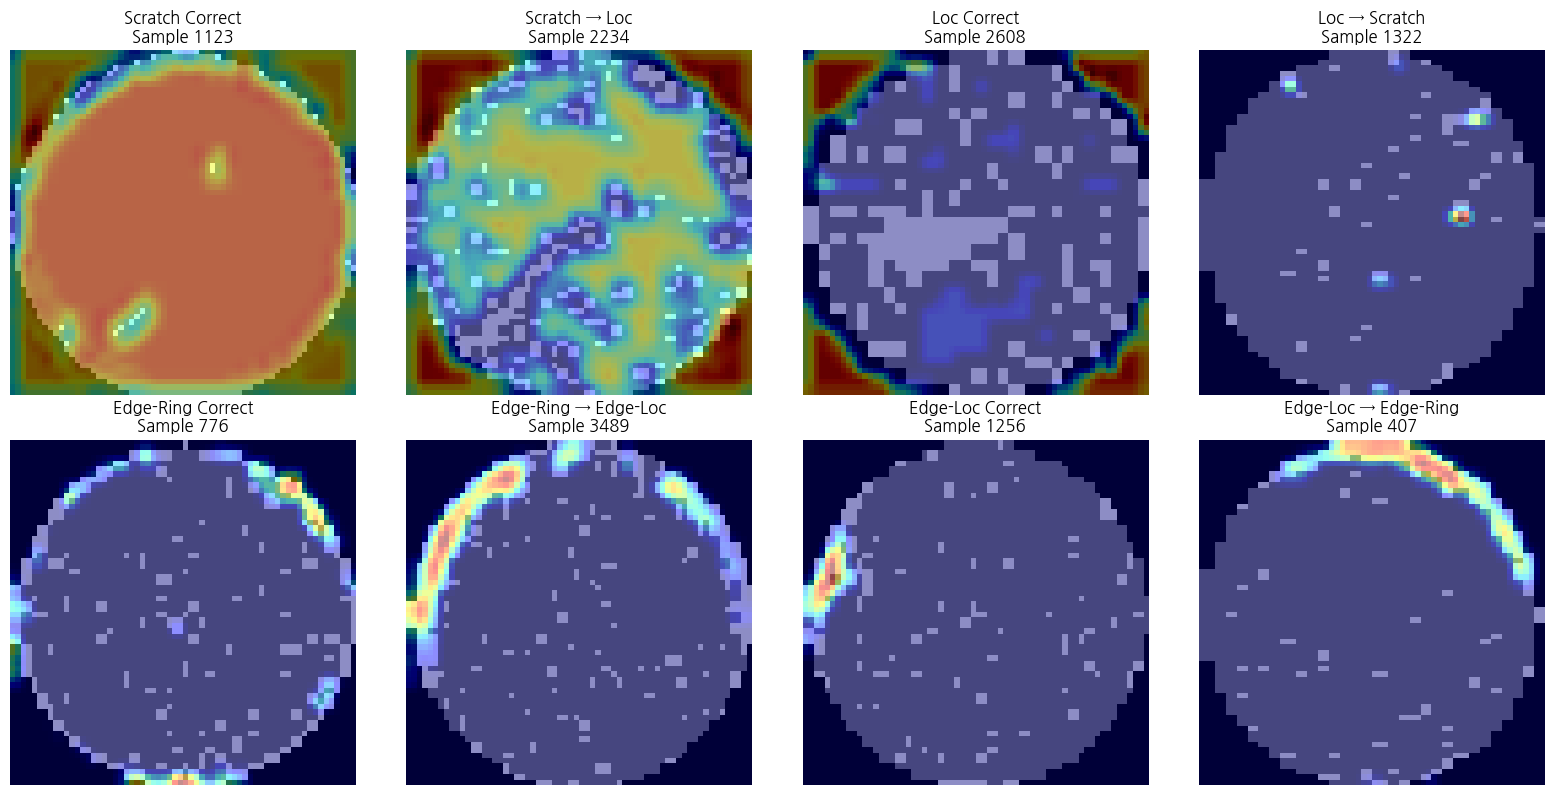

In [318]:
# 대표 Correct / Error Grad-CAM 시각화

final_gradcam = GradCAM(
    best_model,
    final_gradcam_target_layer
)


plt.figure(
    figsize=(16, 8)
)


for plot_idx, row in enumerate(
    representative_cam_df.itertuples(
        index=False
    ),
    start=1
):

    sample_pos = int(
        row.sample_pos
    )


    sample_image, _ = (
        test_dataset[
            sample_pos
        ]
    )


    input_tensor = (
        sample_image
        .unsqueeze(0)
        .to(device)
    )


    true_idx = int(
        prediction_df.loc[
            prediction_df["sample_pos"]
            ==
            sample_pos,
            "true_idx"
        ].iloc[0]
    )


    cam = final_gradcam.generate(
        input_tensor,
        true_idx
    )


    processed_map = (
        sample_image
        .squeeze(0)
        .numpy()
    )


    plt.subplot(
        2,
        4,
        plot_idx
    )


    plt.imshow(
        processed_map,
        cmap="gray",
        vmin=0,
        vmax=1
    )


    plt.imshow(
        cam,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )


    plt.title(
        f"{row.gradcam_group}\n"
        f"Sample {sample_pos}"
    )


    plt.axis(
        "off"
    )


final_gradcam.remove_hooks()


plt.tight_layout()
plt.show()

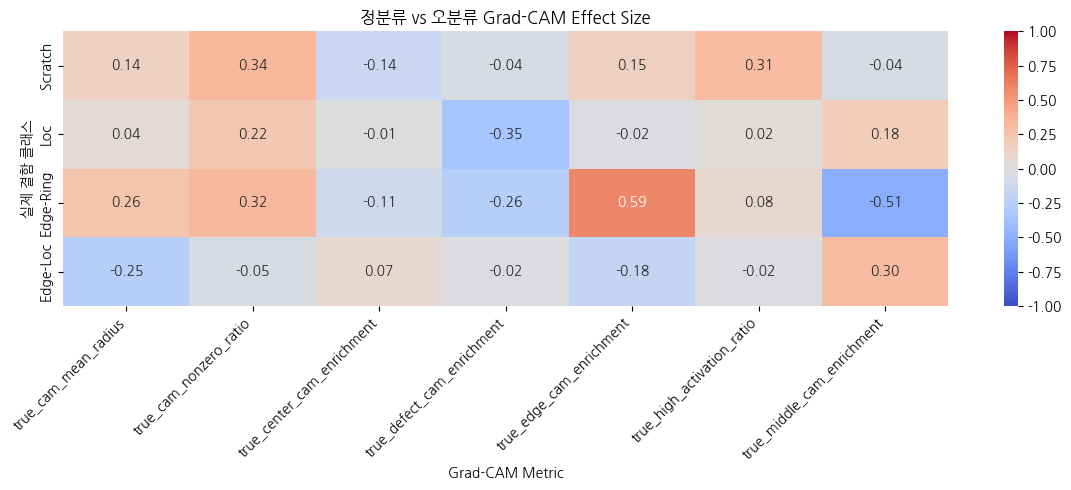

In [319]:
# Correct vs Error Grad-CAM Effect Size Heatmap

gradcam_effect_matrix = (

    gradcam_stat_results_df

    .pivot(
        index="true_class",
        columns="metric",
        values="rank_biserial"
    )

    .reindex(
        [
            "Scratch",
            "Loc",
            "Edge-Ring",
            "Edge-Loc"
        ]
    )
)


plt.figure(
    figsize=(12, 5)
)


sns.heatmap(
    gradcam_effect_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)


plt.xlabel(
    "Grad-CAM Metric"
)

plt.ylabel(
    "실제 결함 클래스"
)

plt.title(
    "정분류 vs 오분류 Grad-CAM Effect Size"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()
plt.show()

In [320]:
# Step 6 주요 결과 저장

step6_layer_validity_df = (
    gradcam_layer_validity_df.copy()
)

step6_final_gradcam_metrics_df = (
    final_gradcam_metrics_df.copy()
)

step6_gradcam_stat_results_df = (
    gradcam_stat_results_df.copy()
)

step6_gradcam_top_effects_df = (
    gradcam_top_effects_df.copy()
)

step6_representative_cam_df = (
    representative_cam_df.copy()
)


print(
    "=== Step 6 저장 변수 ==="
)

print(
    "step6_final_gradcam_metrics_df:",
    step6_final_gradcam_metrics_df.shape
)

print(
    "step6_gradcam_stat_results_df:",
    step6_gradcam_stat_results_df.shape
)

print(
    "step6_representative_cam_df:",
    step6_representative_cam_df.shape
)

=== Step 6 저장 변수 ===
step6_final_gradcam_metrics_df: (231, 32)
step6_gradcam_stat_results_df: (28, 13)
step6_representative_cam_df: (8, 33)


## Step 6 결과 요약

Grad-CAM을 이용하여 CNN이 결함을 판단할 때 사용하는 공간적 영역을 분석하였다.

초기에는 마지막 Convolution Layer인 Conv3를 사용하였으나, 일부 클래스에서 Zero-CAM이 반복적으로 발생하였다.

따라서 Conv1, Conv2, Conv3의 Grad-CAM 생성 안정성을 동일한 샘플에서 비교하였다.

그 결과 Conv2(32×32)가 가장 안정적인 CAM을 생성하였다.

- Predicted-Class CAM 평균 Validity: 100%
- True-Class CAM 평균 Validity: 약 99.6%
- Worst Group Validity: 약 96.7%

따라서 이후 Grad-CAM 분석에서는 Conv2를 최종 Target Layer로 사용하였다.

정분류와 오분류의 True-Class Grad-CAM을 비교한 결과 Edge-Ring에서 유의한 Attention 차이가 확인되었다.

정분류 Edge-Ring에서는 CNN Attention이 보다 외곽에 집중되었으며, Edge-Loc으로 오분류된 Edge-Ring에서는 Attention의 평균 반경과 Edge 영역 집중도가 감소하였다.

이는 앞선 Spatial Feature 분석에서 Edge-Ring의 외곽 집중 특성이 약해질수록 Edge-Loc으로 오분류되는 경향과 일관된 결과이다.

Scratch, Loc 및 Edge-Loc에서도 일부 CAM 지표 차이가 관찰되었으나, 현재 분석 표본에서는 다중검정 보정 후 통계적으로 유의한 차이가 확인되지 않았다.

따라서 Grad-CAM 결과는 모든 CNN 오류를 설명하는 단일 근거로 사용하지 않고, Spatial Feature와 Prototype 분석을 보완하는 모델 해석 자료로 활용한다.

# Step 7. 데이터 기반 Defect Signature 및 RCA Framework

Step 1~6에서는 CNN 분류 성능뿐만 아니라 오분류 구조, 웨이퍼의 Spatial Feature, Prototype Similarity 및 Grad-CAM을 이용하여 결함 패턴을 다양한 관점에서 분석하였다.

이번 단계에서는 지금까지의 결과를 실제 결함 분석 관점으로 통합한다.

분석은 다음 순서로 진행한다.

1. Train Set을 기준으로 각 결함 클래스의 대표적인 Spatial Signature를 정의한다.
2. 각 클래스가 다른 결함 클래스와 비교하여 어떤 특징에서 가장 크게 구분되는지 정량화한다.
3. 데이터에서 확인된 Signature를 기준으로 공정·장비·소재 관점의 가능한 원인 후보를 문헌과 연결한다.
4. 각 원인 후보를 실제로 검증하기 위해 필요한 공정 및 장비 데이터를 정의한다.
5. CNN 결과를 단순한 자동 분류 결과가 아니라 Root Cause Analysis의 우선순위를 결정하는 정보로 활용한다.

중요하게도 Wafer Map만으로 실제 공정 Root Cause를 확정할 수는 없다.

따라서 본 단계에서 제시하는 공정·장비·소재 원인은 **확정된 원인**이 아니라 Wafer Map의 공간적 패턴과 문헌을 기반으로 한 **RCA 조사 후보(Hypothesis)**로 정의한다.

In [321]:
# Step 7-1. 클래스별 One-vs-Rest Spatial Signature

signature_rows = []


for class_name in CLASS_NAMES:

    # --------------------------------------------------
    # 해당 클래스
    # --------------------------------------------------

    class_df = (
        train_spatial_feature_df[
            train_spatial_feature_df[
                "true_label"
            ]
            ==
            class_name
        ]
    )


    # --------------------------------------------------
    # 나머지 모든 클래스
    # --------------------------------------------------

    rest_df = (
        train_spatial_feature_df[
            train_spatial_feature_df[
                "true_label"
            ]
            !=
            class_name
        ]
    )


    for feature in SPATIAL_FEATURES:

        class_median = float(
            class_df[
                feature
            ].median()
        )


        rest_median = float(
            rest_df[
                feature
            ].median()
        )


        raw_difference = (
            class_median
            -
            rest_median
        )


        # Train 전체 IQR 기준으로 차이를 표준화
        iqr = float(
            spatial_scaler_iqr[
                feature
            ]
        )


        standardized_difference = (
            raw_difference
            /
            iqr
        )


        signature_rows.append({

            "class":
                class_name,

            "feature":
                feature,

            "class_median":
                class_median,

            "rest_median":
                rest_median,

            "raw_difference":
                raw_difference,

            "signature_score":
                standardized_difference,

            "signature_strength":
                abs(
                    standardized_difference
                )
        })


class_signature_df = pd.DataFrame(
    signature_rows
)


print(
    "=== Data-driven Class Signature 계산 완료 ==="
)

print(
    "Shape:",
    class_signature_df.shape
)

=== Data-driven Class Signature 계산 완료 ===
Shape: (104, 7)


In [322]:
# 클래스별 가장 구분력이 큰 Spatial Signature Top 5

top_signature_df = (

    class_signature_df

    .sort_values(
        "signature_strength",
        ascending=False
    )

    .groupby(
        "class",
        group_keys=False
    )

    .head(5)

    .reset_index(drop=True)
)


top_signature_df[
    "direction"
] = np.where(

    top_signature_df[
        "signature_score"
    ]
    > 0,

    "Higher than others",

    "Lower than others"
)


print(
    "=== 클래스별 주요 Data-driven Signature Top 5 ==="
)


display(
    top_signature_df[
        [
            "class",
            "feature",

            "class_median",
            "rest_median",

            "signature_score",
            "signature_strength",

            "direction"
        ]
    ]
    .style.format({

        "class_median":
            "{:.4f}",

        "rest_median":
            "{:.4f}",

        "signature_score":
            "{:+.4f}",

        "signature_strength":
            "{:.4f}"
    })
)

=== 클래스별 주요 Data-driven Signature Top 5 ===


,class,feature,class_median,rest_median,signature_score,signature_strength,direction
0,Near-full,defect_ratio,0.8765,0.1579,+6.1596,6.1596,Higher than others
1,Near-full,edge_defect_density,0.8660,0.2457,+4.2324,4.2324,Higher than others
2,Near-full,center_defect_density,0.9354,0.0984,+4.0405,4.0405,Higher than others
3,Random,defect_ratio,0.4779,0.1535,+2.7806,2.7806,Higher than others
4,Center,center_defect_density,0.5112,0.0784,+2.0890,2.0890,Higher than others
5,Random,center_defect_density,0.4919,0.0928,+1.9264,1.9264,Higher than others
6,Random,edge_defect_density,0.5122,0.2426,+1.8390,1.8390,Higher than others
7,Center,center_ratio,0.2431,0.0656,+1.7716,1.7716,Higher than others
8,Donut,middle_ratio,0.6210,0.2899,+1.5502,1.5502,Higher than others
9,Center,radius_std,0.2914,0.2192,+1.3692,1.3692,Higher than others


In [323]:
# Spatial Feature 의미 정의

FEATURE_KOREAN_NAME = {

    "defect_ratio":
        "전체 결함 비율",

    "center_ratio":
        "중심부 결함 비율",

    "middle_ratio":
        "중간 반경 결함 비율",

    "edge_ratio":
        "외곽 결함 비율",

    "center_defect_density":
        "중심부 결함 밀도",

    "edge_defect_density":
        "외곽 결함 밀도",

    "mean_radius":
        "평균 결함 반경",

    "radius_std":
        "결함 반경 분산",

    "normalized_cluster_count":
        "결함 Cluster 분절도",

    "largest_cluster_ratio":
        "최대 Cluster 지배도",

    "global_elongation":
        "전체 결함 방향성",

    "weighted_cluster_elongation":
        "Cluster 선형성",

    "linear_defect_ratio":
        "선형 결함 비율"
}


readable_signature_df = (
    top_signature_df.copy()
)


readable_signature_df[
    "feature_description"
] = (
    readable_signature_df[
        "feature"
    ]
    .map(
        FEATURE_KOREAN_NAME
    )
)


readable_signature_df[
    "relative_direction"
] = np.where(

    readable_signature_df[
        "signature_score"
    ]
    > 0,

    "높음",

    "낮음"
)


print(
    "=== 클래스별 대표 Spatial Signature ==="
)


display(
    readable_signature_df[
        [
            "class",
            "feature_description",
            "relative_direction",
            "signature_score"
        ]
    ]
    .style.format({
        "signature_score": "{:+.3f}"
    })
)

=== 클래스별 대표 Spatial Signature ===


,class,feature_description,relative_direction,signature_score
0,Near-full,전체 결함 비율,높음,+6.160
1,Near-full,외곽 결함 밀도,높음,+4.232
2,Near-full,중심부 결함 밀도,높음,+4.040
3,Random,전체 결함 비율,높음,+2.781
4,Center,중심부 결함 밀도,높음,+2.089
5,Random,중심부 결함 밀도,높음,+1.926
6,Random,외곽 결함 밀도,높음,+1.839
7,Center,중심부 결함 비율,높음,+1.772
8,Donut,중간 반경 결함 비율,높음,+1.550
9,Center,결함 반경 분산,높음,+1.369


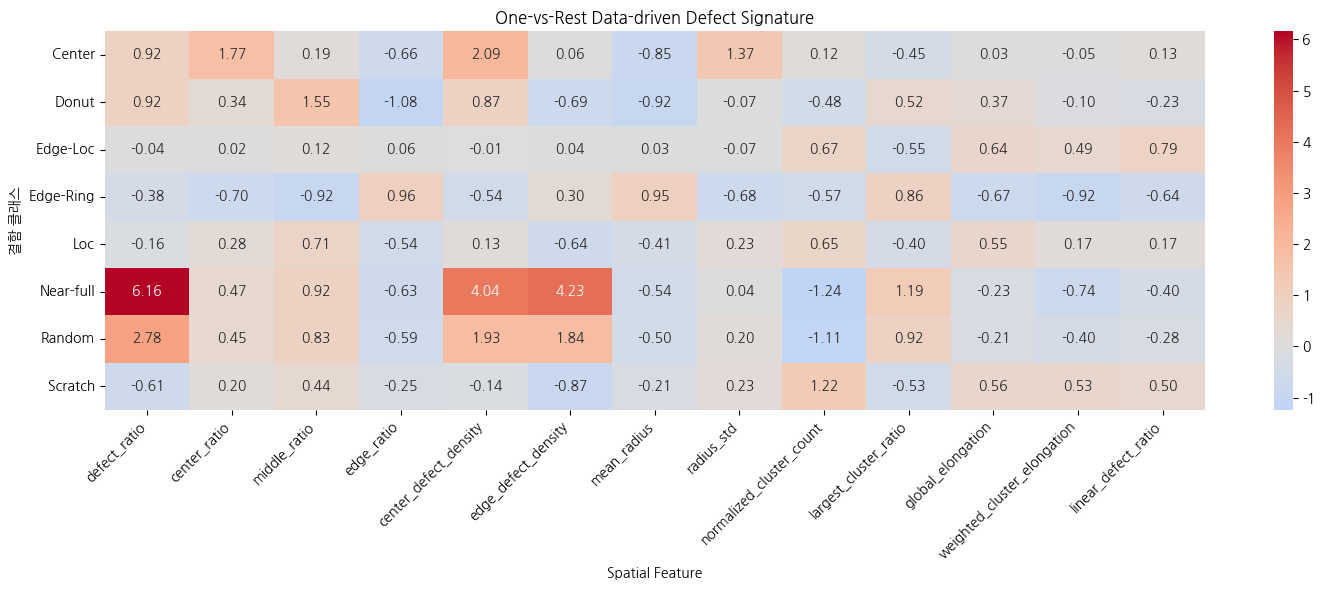

In [324]:
# 클래스 × Spatial Feature Signature Heatmap

signature_matrix_df = (

    class_signature_df

    .pivot(
        index="class",
        columns="feature",
        values="signature_score"
    )

    .reindex(
        CLASS_NAMES
    )

    .reindex(
        columns=SPATIAL_FEATURES
    )
)


plt.figure(
    figsize=(15, 6)
)


sns.heatmap(

    signature_matrix_df,

    annot=True,

    fmt=".2f",

    cmap="coolwarm",

    center=0
)


plt.xlabel(
    "Spatial Feature"
)

plt.ylabel(
    "결함 클래스"
)

plt.title(
    "One-vs-Rest Data-driven Defect Signature"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.tight_layout()

plt.show()

In [325]:
# Spatial Feature Category 정의

FEATURE_CATEGORY = {

    "defect_ratio":
        "Defect Amount",

    "center_ratio":
        "Radial",

    "middle_ratio":
        "Radial",

    "edge_ratio":
        "Radial",

    "center_defect_density":
        "Radial",

    "edge_defect_density":
        "Radial",

    "mean_radius":
        "Radial",

    "radius_std":
        "Radial",

    "normalized_cluster_count":
        "Cluster",

    "largest_cluster_ratio":
        "Cluster",

    "global_elongation":
        "Shape",

    "weighted_cluster_elongation":
        "Shape",

    "linear_defect_ratio":
        "Shape"
}


class_signature_df[
    "feature_category"
] = (
    class_signature_df[
        "feature"
    ]
    .map(
        FEATURE_CATEGORY
    )
)


category_signature_df = (

    class_signature_df

    .groupby(
        [
            "class",
            "feature_category"
        ]
    )

    .agg(

        mean_absolute_signature=(
            "signature_strength",
            "mean"
        ),

        max_absolute_signature=(
            "signature_strength",
            "max"
        )
    )

    .reset_index()
)


print(
    "=== 클래스별 Signature Category ==="
)


display(
    category_signature_df
    .sort_values(
        [
            "class",
            "max_absolute_signature"
        ],
        ascending=[
            True,
            False
        ]
    )
    .style.format({

        "mean_absolute_signature":
            "{:.4f}",

        "max_absolute_signature":
            "{:.4f}"
    })
)

=== 클래스별 Signature Category ===


,class,feature_category,mean_absolute_signature,max_absolute_signature
2,Center,Radial,0.9975,2.0890
1,Center,Defect Amount,0.9196,0.9196
0,Center,Cluster,0.2874,0.4529
3,Center,Shape,0.0700,0.1299
6,Donut,Radial,0.7889,1.5502
5,Donut,Defect Amount,0.9203,0.9203
4,Donut,Cluster,0.5030,0.5211
7,Donut,Shape,0.2353,0.3689
11,Edge-Loc,Shape,0.6387,0.7864
8,Edge-Loc,Cluster,0.6102,0.6744


## Step 7-2. 문헌 기반 공정 Root Cause Hypothesis 연결

Wafer Map의 공간적 패턴은 공정 이상에 대한 중요한 단서를 제공하지만, Wafer Map만으로 실제 Root Cause를 확정할 수는 없다.

동일하거나 유사한 공간 패턴이 서로 다른 공정 또는 장비 이상에 의해 발생할 수 있으며, 실제 원인을 확인하기 위해서는 Recipe, Equipment, Metrology 및 Lot History 등의 추가 데이터가 필요하다.

따라서 본 프로젝트에서는 다음의 두 정보를 결합하여 RCA 후보를 정의한다.

1. 본 데이터에서 직접 확인한 Data-driven Spatial Signature
2. 기존 반도체 Wafer Map 연구에서 보고된 Pattern–Process 관계

각 원인은 확정된 Root Cause가 아니라 **Investigation Hypothesis**로 정의하며, 이후 실제 검증에 필요한 공정·장비 데이터를 별도로 제안한다.

In [326]:
# Step 7-2. Data-driven Signature + Literature RCA Hypothesis

rca_hypothesis_records = [

    {
        "class": "Center",

        "data_signature":
            "높은 center ratio 및 center defect density, "
            "낮은 mean radius",

        "pattern_interpretation":
            "결함이 wafer 중심부에 집중",

        "process_hypothesis":
            "Thin-film deposition non-uniformity; "
            "CMP center-region uniformity issue",

        "equipment_or_condition_candidate":
            "Deposition uniformity, CMP pressure/profile, "
            "center-to-edge process non-uniformity",

        "evidence_level":
            "Literature-supported candidate"
    },


    {
        "class": "Donut",

        "data_signature":
            "높은 middle ratio, 낮은 edge ratio 및 mean radius",

        "pattern_interpretation":
            "중앙이 아닌 중간 반경에 ring 형태의 결함 집중",

        "process_hypothesis":
            "Photoresist-related radial non-uniformity; "
            "possible resist redeposition",

        "equipment_or_condition_candidate":
            "Coating/develop condition, resist flow or redeposition, "
            "radial process uniformity",

        "evidence_level":
            "Literature-supported candidate"
    },


    {
        "class": "Edge-Loc",

        "data_signature":
            "높은 cluster fragmentation, global elongation 및 "
            "linear defect tendency",

        "pattern_interpretation":
            "wafer 외곽의 특정 영역에 국소적·방향성 결함 형성",

        "process_hypothesis":
            "Localized edge process non-uniformity; "
            "uneven heating or localized surface-processing issue",

        "equipment_or_condition_candidate":
            "Edge temperature distribution, local contact/handling, "
            "edge polishing/cleaning uniformity",

        "evidence_level":
            "Literature-supported candidate"
    },


    {
        "class": "Edge-Ring",

        "data_signature":
            "높은 edge ratio와 mean radius, "
            "높은 largest cluster ratio, 낮은 middle ratio",

        "pattern_interpretation":
            "wafer 가장자리를 따라 연속적인 ring 형태 형성",

        "process_hypothesis":
            "Etching non-uniformity; "
            "possible radial thermal/process non-uniformity",

        "equipment_or_condition_candidate":
            "Etch edge condition, plasma/radial uniformity, "
            "edge-related process condition",

        "evidence_level":
            "Strong literature-supported candidate"
    },


    {
        "class": "Loc",

        "data_signature":
            "높은 middle-region tendency 및 "
            "cluster fragmentation / directional structure",

        "pattern_interpretation":
            "wafer 일부 영역에 국소적으로 결함이 집중",

        "process_hypothesis":
            "Localized equipment/process disturbance; "
            "possible mechanical vibration or local process variation",

        "equipment_or_condition_candidate":
            "Equipment vibration, localized chamber/process variation, "
            "local contamination",

        "evidence_level":
            "Literature-supported candidate"
    },


    {
        "class": "Near-full",

        "data_signature":
            "매우 높은 defect ratio와 "
            "center/edge defect density",

        "pattern_interpretation":
            "wafer 대부분의 die가 동시에 불량",

        "process_hypothesis":
            "Severe global process excursion or "
            "multiple overlapping systematic/random failures",

        "equipment_or_condition_candidate":
            "Global recipe excursion, equipment-wide failure, "
            "test/measurement abnormality",

        "evidence_level":
            "Broad investigation candidate"
    },


    {
        "class": "Random",

        "data_signature":
            "높은 전체 defect ratio와 density, "
            "특정 radial/linear signature는 상대적으로 약함",

        "pattern_interpretation":
            "특정 공간 구조 없이 wafer 전반에 산발적으로 발생",

        "process_hypothesis":
            "Particle or contamination-related random defects",

        "equipment_or_condition_candidate":
            "Cleanroom particle, chamber contamination, "
            "chemical stain or debris",

        "evidence_level":
            "Literature-supported candidate"
    },


    {
        "class": "Scratch",

        "data_signature":
            "높은 cluster fragmentation, elongation 및 "
            "linear defect tendency",

        "pattern_interpretation":
            "길고 좁은 방향성 결함이 여러 구간에 걸쳐 나타남",

        "process_hypothesis":
            "Mechanical handling/contact issue; "
            "CMP-related mechanical scratch",

        "equipment_or_condition_candidate":
            "Wafer handling, robot/contact point, "
            "CMP pad condition or particle agglomeration",

        "evidence_level":
            "Strong literature-supported candidate"
    }
]


rca_hypothesis_df = pd.DataFrame(
    rca_hypothesis_records
)


print(
    "=== Data-driven Defect Signature + RCA Hypothesis ==="
)


display(
    rca_hypothesis_df
)

=== Data-driven Defect Signature + RCA Hypothesis ===


,class,data_signature,pattern_interpretation,process_hypothesis,equipment_or_condition_candidate,evidence_level
0,Center,"높은 center ratio 및 center defect density, 낮은 me...",결함이 wafer 중심부에 집중,Thin-film deposition non-uniformity; CMP cente...,"Deposition uniformity, CMP pressure/profile, c...",Literature-supported candidate
1,Donut,"높은 middle ratio, 낮은 edge ratio 및 mean radius",중앙이 아닌 중간 반경에 ring 형태의 결함 집중,Photoresist-related radial non-uniformity; pos...,"Coating/develop condition, resist flow or rede...",Literature-supported candidate
2,Edge-Loc,"높은 cluster fragmentation, global elongation 및 ...",wafer 외곽의 특정 영역에 국소적·방향성 결함 형성,Localized edge process non-uniformity; uneven ...,"Edge temperature distribution, local contact/h...",Literature-supported candidate
3,Edge-Ring,"높은 edge ratio와 mean radius, 높은 largest cluster...",wafer 가장자리를 따라 연속적인 ring 형태 형성,Etching non-uniformity; possible radial therma...,"Etch edge condition, plasma/radial uniformity,...",Strong literature-supported candidate
4,Loc,높은 middle-region tendency 및 cluster fragmentat...,wafer 일부 영역에 국소적으로 결함이 집중,Localized equipment/process disturbance; possi...,"Equipment vibration, localized chamber/process...",Literature-supported candidate
5,Near-full,매우 높은 defect ratio와 center/edge defect density,wafer 대부분의 die가 동시에 불량,Severe global process excursion or multiple ov...,"Global recipe excursion, equipment-wide failur...",Broad investigation candidate
6,Random,"높은 전체 defect ratio와 density, 특정 radial/linear ...",특정 공간 구조 없이 wafer 전반에 산발적으로 발생,Particle or contamination-related random defects,"Cleanroom particle, chamber contamination, che...",Literature-supported candidate
7,Scratch,"높은 cluster fragmentation, elongation 및 linear ...",길고 좁은 방향성 결함이 여러 구간에 걸쳐 나타남,Mechanical handling/contact issue; CMP-related...,"Wafer handling, robot/contact point, CMP pad c...",Strong literature-supported candidate


### RCA Hypothesis 해석 시 주의사항

본 분석에서 제시한 Pattern–Process 관계는 실제 Wafer의 Root Cause를 확정한 결과가 아니다.

WM-811K에는 개별 Wafer에 대한 Recipe, Chamber ID, 공정 조건, 설비 이력, Metrology 및 Defect Inspection 정보가 포함되어 있지 않기 때문이다.

따라서 예를 들어 Edge-Ring Wafer가 관찰되었다고 해서 Etch 공정 이상이라고 바로 판단해서는 안 된다.

본 프로젝트에서 Wafer Map Pattern은 다음과 같이 사용한다.

**Wafer Pattern → 가능한 원인 후보 축소 → 필요한 추가 데이터 정의 → 가설 검증**

즉 Wafer Map 분석의 역할은 Root Cause를 확정하는 것이 아니라, 넓은 원인 공간에서 우선적으로 조사해야 할 공정 및 장비 후보를 좁히는 것이다.

## Step 7-3. RCA Verification Plan 구성

Wafer Map의 Spatial Pattern만으로 실제 Root Cause를 확정할 수는 없다.

따라서 각 결함 Pattern에 대해 가능한 원인 후보를 제시한 뒤, 실제 제조 환경에서 해당 가설을 검증하기 위해 확인해야 할 데이터를 정의한다.

RCA 검증은 다음 흐름으로 구성한다.

**Pattern Detection**
→ **Root Cause Hypothesis**
→ **Required Process / Equipment Data**
→ **Reference Group Comparison**
→ **Hypothesis Verification**

예를 들어 Edge-Ring Pattern이 관찰된 경우 Etch 공정을 바로 원인으로 확정하지 않는다.

대신 동일 Lot, 동일 Recipe, 동일 Chamber의 다른 Wafer와 비교하고 RF Power, Pressure, Gas Flow, Temperature 및 Radial CD/Etch-rate와 같은 데이터를 확인하여 실제로 Edge 영역의 Process Non-uniformity가 존재하는지를 검증한다.

따라서 본 프로젝트에서 RCA 결과는 최종 원인 판정이 아니라 **다음 조사 단계의 우선순위를 제시하는 Diagnostic Recommendation**으로 사용한다.

In [327]:
# Step 7-3. RCA Verification Matrix

rca_verification_records = [

    # ==================================================
    # Center
    # ==================================================

    {
        "class": "Center",
        "priority": 1,
        "category": "Process",
        "candidate": "Center-to-edge film / process non-uniformity",
        "why_check":
            "Center 영역에 결함이 집중되는 공간적 Signature 확인",
        "required_data":
            "Radial thickness, CD, etch/deposition rate, wafer position data",
        "comparison":
            "Center vs Middle vs Edge radial profile 비교",
        "supporting_signal":
            "Center 영역에서만 공정 결과가 체계적으로 이동",
        "verification_status":
            "Requires process data"
    },

    {
        "class": "Center",
        "priority": 2,
        "category": "Equipment",
        "candidate": "Center-region pressure / thermal / deposition condition",
        "why_check":
            "중심부 defect density가 다른 클래스보다 높음",
        "required_data":
            "Temperature profile, pressure profile, deposition/CMP condition",
        "comparison":
            "정상 wafer와 동일 chamber/recipe wafer 비교",
        "supporting_signal":
            "Center 집중 이상이 특정 장비 또는 조건과 반복적으로 동반",
        "verification_status":
            "Requires equipment data"
    },


    # ==================================================
    # Donut
    # ==================================================

    {
        "class": "Donut",
        "priority": 1,
        "category": "Process",
        "candidate": "Mid-radius process non-uniformity",
        "why_check":
            "Middle ratio가 다른 클래스보다 뚜렷하게 높음",
        "required_data":
            "Radial CD, thickness, develop/coat result, process uniformity",
        "comparison":
            "Center / Middle / Edge radial profile 비교",
        "supporting_signal":
            "중간 반경 영역에서 ring 형태의 공정 편차 확인",
        "verification_status":
            "Requires process data"
    },

    {
        "class": "Donut",
        "priority": 2,
        "category": "Material / Process",
        "candidate": "Photoresist coating / develop radial variation",
        "why_check":
            "Wafer 중간 반경을 중심으로 결함이 집중",
        "required_data":
            "PR thickness, coat/develop recipe, dispense/spin condition",
        "comparison":
            "정상 wafer와 PR radial profile 비교",
        "supporting_signal":
            "동일 반경에서 PR 또는 develop 결과 이상 확인",
        "verification_status":
            "Requires material/process data"
    },


    # ==================================================
    # Edge-Loc
    # ==================================================

    {
        "class": "Edge-Loc",
        "priority": 1,
        "category": "Equipment",
        "candidate": "Localized edge process non-uniformity",
        "why_check":
            "외곽의 특정 영역에 국소적·방향성 결함이 나타남",
        "required_data":
            "Wafer orientation, local temperature, chamber position, edge CD",
        "comparison":
            "결함 발생 방향과 wafer/chamber orientation 비교",
        "supporting_signal":
            "동일 방향 또는 위치에서 반복적으로 defect 발생",
        "verification_status":
            "Requires equipment data"
    },

    {
        "class": "Edge-Loc",
        "priority": 2,
        "category": "Handling / Equipment",
        "candidate": "Localized edge contact or handling issue",
        "why_check":
            "Edge 영역의 국소적 Cluster 및 방향성 증가",
        "required_data":
            "Robot handling history, chuck/contact position, wafer orientation",
        "comparison":
            "Defect 위치와 handling/contact 위치 비교",
        "supporting_signal":
            "기계적 접촉 위치와 defect 위치가 공간적으로 일치",
        "verification_status":
            "Requires equipment history"
    },


    # ==================================================
    # Edge-Ring
    # ==================================================

    {
        "class": "Edge-Ring",
        "priority": 1,
        "category": "Process",
        "candidate": "Radial edge process non-uniformity",
        "why_check":
            "Edge ratio와 mean radius가 높고 외곽에 연속적 Pattern 형성",
        "required_data":
            "Radial CD, etch rate, film thickness, within-wafer uniformity",
        "comparison":
            "Center-to-edge process profile 비교",
        "supporting_signal":
            "Wafer edge에서 연속적인 공정 편차 확인",
        "verification_status":
            "Requires process data"
    },

    {
        "class": "Edge-Ring",
        "priority": 2,
        "category": "Equipment",
        "candidate": "Plasma / thermal edge condition",
        "why_check":
            "외곽 전체를 따라 systematic한 ring 구조가 나타남",
        "required_data":
            "RF power, pressure, gas flow, temperature, chamber/recipe ID",
        "comparison":
            "정상 wafer 및 다른 chamber에서 동일 recipe 결과 비교",
        "supporting_signal":
            "특정 chamber/condition에서 Edge-Ring 발생률 증가",
        "verification_status":
            "Requires equipment data"
    },


    # ==================================================
    # Loc
    # ==================================================

    {
        "class": "Loc",
        "priority": 1,
        "category": "Equipment / Process",
        "candidate": "Localized process disturbance",
        "why_check":
            "특정 wafer 영역에 Cluster가 국소적으로 집중",
        "required_data":
            "Local CD/thickness, chamber map, wafer orientation",
        "comparison":
            "정상 wafer와 defect 발생 위치 주변 process result 비교",
        "supporting_signal":
            "동일 위치에서 국소적인 공정 편차 확인",
        "verification_status":
            "Requires process data"
    },

    {
        "class": "Loc",
        "priority": 2,
        "category": "Environment / Equipment",
        "candidate": "Localized particle or chamber disturbance",
        "why_check":
            "전면이 아닌 특정 영역에만 결함 집중",
        "required_data":
            "Particle inspection, chamber clean history, equipment event log",
        "comparison":
            "Defect 발생 시점 전후 particle/event trend 비교",
        "supporting_signal":
            "Particle 증가 또는 equipment event와 defect 발생이 동반",
        "verification_status":
            "Requires inspection/history data"
    },


    # ==================================================
    # Near-full
    # ==================================================

    {
        "class": "Near-full",
        "priority": 1,
        "category": "Process",
        "candidate": "Global process excursion",
        "why_check":
            "전체 wafer의 defect ratio가 매우 높음",
        "required_data":
            "Recipe parameters, metrology result, upstream/downstream process history",
        "comparison":
            "동일 Lot 및 직전/직후 wafer 결과 비교",
        "supporting_signal":
            "Wafer 전 영역에서 동시에 process result 이상 발생",
        "verification_status":
            "Requires process data"
    },

    {
        "class": "Near-full",
        "priority": 2,
        "category": "Measurement",
        "candidate": "Inspection / measurement abnormality",
        "why_check":
            "Wafer 대부분이 동시에 defect로 표시되는 극단적 Pattern",
        "required_data":
            "Inspection tool ID, calibration status, raw measurement data",
        "comparison":
            "다른 계측 장비 또는 재측정 결과 비교",
        "supporting_signal":
            "재측정 시 defect pattern이 재현되지 않음",
        "verification_status":
            "Requires measurement verification"
    },


    # ==================================================
    # Random
    # ==================================================

    {
        "class": "Random",
        "priority": 1,
        "category": "Environment",
        "candidate": "Particle / contamination",
        "why_check":
            "특정 공간 구조 없이 wafer 전반에 산발적 defect 발생",
        "required_data":
            "Particle count, contamination inspection, chamber clean history",
        "comparison":
            "정상 기간과 defect 발생 기간의 particle trend 비교",
        "supporting_signal":
            "Particle 증가와 Random defect 증가가 함께 관찰",
        "verification_status":
            "Requires environment data"
    },

    {
        "class": "Random",
        "priority": 2,
        "category": "Material",
        "candidate": "Material / chemical contamination",
        "why_check":
            "공간적으로 일정한 방향성 없이 defect가 분산",
        "required_data":
            "Material lot, chemical lot, incoming QC, contamination history",
        "comparison":
            "Material lot별 defect rate 비교",
        "supporting_signal":
            "특정 material lot에서 Random defect 증가",
        "verification_status":
            "Requires material data"
    },


    # ==================================================
    # Scratch
    # ==================================================

    {
        "class": "Scratch",
        "priority": 1,
        "category": "Handling / Equipment",
        "candidate": "Mechanical contact / wafer handling",
        "why_check":
            "높은 elongation과 linear defect signature 확인",
        "required_data":
            "Robot path, handler/chuck contact position, wafer orientation",
        "comparison":
            "Scratch 방향과 handling trajectory/contact 위치 비교",
        "supporting_signal":
            "기계적 이동 또는 접촉 방향과 Scratch가 일치",
        "verification_status":
            "Requires equipment history"
    },

    {
        "class": "Scratch",
        "priority": 2,
        "category": "Process / Equipment",
        "candidate": "CMP mechanical scratch",
        "why_check":
            "길고 방향성 있는 defect cluster가 반복됨",
        "required_data":
            "CMP pad condition, slurry particle status, polishing history",
        "comparison":
            "CMP 전/후 검사 및 pad 사용 이력 비교",
        "supporting_signal":
            "CMP 이후 Scratch 출현 또는 pad/particle event와 동반",
        "verification_status":
            "Requires process/equipment data"
    }
]


rca_verification_df = pd.DataFrame(
    rca_verification_records
)


rca_verification_df = (
    rca_verification_df
    .sort_values(
        [
            "class",
            "priority"
        ]
    )
    .reset_index(drop=True)
)


print(
    "=== RCA Verification Matrix ==="
)


display(
    rca_verification_df
)

=== RCA Verification Matrix ===


,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
0,Center,1,Process,Center-to-edge film / process non-uniformity,Center 영역에 결함이 집중되는 공간적 Signature 확인,"Radial thickness, CD, etch/deposition rate, wa...",Center vs Middle vs Edge radial profile 비교,Center 영역에서만 공정 결과가 체계적으로 이동,Requires process data
1,Center,2,Equipment,Center-region pressure / thermal / deposition ...,중심부 defect density가 다른 클래스보다 높음,"Temperature profile, pressure profile, deposit...",정상 wafer와 동일 chamber/recipe wafer 비교,Center 집중 이상이 특정 장비 또는 조건과 반복적으로 동반,Requires equipment data
2,Donut,1,Process,Mid-radius process non-uniformity,Middle ratio가 다른 클래스보다 뚜렷하게 높음,"Radial CD, thickness, develop/coat result, pro...",Center / Middle / Edge radial profile 비교,중간 반경 영역에서 ring 형태의 공정 편차 확인,Requires process data
3,Donut,2,Material / Process,Photoresist coating / develop radial variation,Wafer 중간 반경을 중심으로 결함이 집중,"PR thickness, coat/develop recipe, dispense/sp...",정상 wafer와 PR radial profile 비교,동일 반경에서 PR 또는 develop 결과 이상 확인,Requires material/process data
4,Edge-Loc,1,Equipment,Localized edge process non-uniformity,외곽의 특정 영역에 국소적·방향성 결함이 나타남,"Wafer orientation, local temperature, chamber ...",결함 발생 방향과 wafer/chamber orientation 비교,동일 방향 또는 위치에서 반복적으로 defect 발생,Requires equipment data
5,Edge-Loc,2,Handling / Equipment,Localized edge contact or handling issue,Edge 영역의 국소적 Cluster 및 방향성 증가,"Robot handling history, chuck/contact position...",Defect 위치와 handling/contact 위치 비교,기계적 접촉 위치와 defect 위치가 공간적으로 일치,Requires equipment history
6,Edge-Ring,1,Process,Radial edge process non-uniformity,Edge ratio와 mean radius가 높고 외곽에 연속적 Pattern 형성,"Radial CD, etch rate, film thickness, within-w...",Center-to-edge process profile 비교,Wafer edge에서 연속적인 공정 편차 확인,Requires process data
7,Edge-Ring,2,Equipment,Plasma / thermal edge condition,외곽 전체를 따라 systematic한 ring 구조가 나타남,"RF power, pressure, gas flow, temperature, cha...",정상 wafer 및 다른 chamber에서 동일 recipe 결과 비교,특정 chamber/condition에서 Edge-Ring 발생률 증가,Requires equipment data
8,Loc,1,Equipment / Process,Localized process disturbance,특정 wafer 영역에 Cluster가 국소적으로 집중,"Local CD/thickness, chamber map, wafer orienta...",정상 wafer와 defect 발생 위치 주변 process result 비교,동일 위치에서 국소적인 공정 편차 확인,Requires process data
9,Loc,2,Environment / Equipment,Localized particle or chamber disturbance,전면이 아닌 특정 영역에만 결함 집중,"Particle inspection, chamber clean history, eq...",Defect 발생 시점 전후 particle/event trend 비교,Particle 증가 또는 equipment event와 defect 발생이 동반,Requires inspection/history data


In [328]:
# 클래스별 우선 RCA 조사 경로

rca_primary_route_df = (

    rca_verification_df[
        rca_verification_df[
            "priority"
        ]
        == 1
    ]

    [
        [
            "class",
            "category",
            "candidate",
            "required_data",
            "comparison",
            "supporting_signal"
        ]
    ]

    .rename(
        columns={

            "category":
                "primary_category",

            "candidate":
                "primary_rca_candidate",

            "required_data":
                "required_verification_data",

            "comparison":
                "recommended_comparison",

            "supporting_signal":
                "supporting_verification_signal"
        }
    )

    .reset_index(drop=True)
)


print(
    "=== 클래스별 Primary RCA Investigation Route ==="
)


display(
    rca_primary_route_df
)

=== 클래스별 Primary RCA Investigation Route ===


,class,primary_category,primary_rca_candidate,required_verification_data,recommended_comparison,supporting_verification_signal
0,Center,Process,Center-to-edge film / process non-uniformity,"Radial thickness, CD, etch/deposition rate, wa...",Center vs Middle vs Edge radial profile 비교,Center 영역에서만 공정 결과가 체계적으로 이동
1,Donut,Process,Mid-radius process non-uniformity,"Radial CD, thickness, develop/coat result, pro...",Center / Middle / Edge radial profile 비교,중간 반경 영역에서 ring 형태의 공정 편차 확인
2,Edge-Loc,Equipment,Localized edge process non-uniformity,"Wafer orientation, local temperature, chamber ...",결함 발생 방향과 wafer/chamber orientation 비교,동일 방향 또는 위치에서 반복적으로 defect 발생
3,Edge-Ring,Process,Radial edge process non-uniformity,"Radial CD, etch rate, film thickness, within-w...",Center-to-edge process profile 비교,Wafer edge에서 연속적인 공정 편차 확인
4,Loc,Equipment / Process,Localized process disturbance,"Local CD/thickness, chamber map, wafer orienta...",정상 wafer와 defect 발생 위치 주변 process result 비교,동일 위치에서 국소적인 공정 편차 확인
5,Near-full,Process,Global process excursion,"Recipe parameters, metrology result, upstream/...",동일 Lot 및 직전/직후 wafer 결과 비교,Wafer 전 영역에서 동시에 process result 이상 발생
6,Random,Environment,Particle / contamination,"Particle count, contamination inspection, cham...",정상 기간과 defect 발생 기간의 particle trend 비교,Particle 증가와 Random defect 증가가 함께 관찰
7,Scratch,Handling / Equipment,Mechanical contact / wafer handling,"Robot path, handler/chuck contact position, wa...",Scratch 방향과 handling trajectory/contact 위치 비교,기계적 이동 또는 접촉 방향과 Scratch가 일치


In [329]:
# 결함 클래스별 RCA 조사 계획 반환 함수

def get_rca_verification_plan(
    defect_class,
    top_n=2
):

    result = (

        rca_verification_df[
            rca_verification_df[
                "class"
            ]
            ==
            defect_class
        ]

        .sort_values(
            "priority"
        )

        .head(
            top_n
        )

        .copy()
    )


    return result


# --------------------------------------------------
# 예시: Edge-Ring
# --------------------------------------------------

example_rca_plan = (
    get_rca_verification_plan(
        "Edge-Ring"
    )
)


print(
    "=== Example: Edge-Ring RCA Investigation Plan ==="
)


display(
    example_rca_plan
)

=== Example: Edge-Ring RCA Investigation Plan ===


,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
6,Edge-Ring,1,Process,Radial edge process non-uniformity,Edge ratio와 mean radius가 높고 외곽에 연속적 Pattern 형성,"Radial CD, etch rate, film thickness, within-w...",Center-to-edge process profile 비교,Wafer edge에서 연속적인 공정 편차 확인,Requires process data
7,Edge-Ring,2,Equipment,Plasma / thermal edge condition,외곽 전체를 따라 systematic한 ring 구조가 나타남,"RF power, pressure, gas flow, temperature, cha...",정상 wafer 및 다른 chamber에서 동일 recipe 결과 비교,특정 chamber/condition에서 Edge-Ring 발생률 증가,Requires equipment data


### RCA Framework의 해석 원칙

본 시스템은 CNN이 예측한 결함 클래스에 대해 가능한 공정 원인을 자동으로 확정하지 않는다.

대신 다음 세 단계로 정보를 제공한다.

**1. Observation**
- CNN 예측 결과
- Spatial Feature
- Prototype Similarity
- Grad-CAM

**2. Hypothesis**
- 해당 공간 Pattern과 일관될 수 있는 공정·장비·소재 원인 후보

**3. Verification**
- 실제 Root Cause 확인을 위해 추가로 필요한 공정 데이터
- 비교해야 할 Reference Wafer / Lot / Chamber
- 가설을 지지하거나 기각할 수 있는 확인 신호

따라서 시스템의 최종 목적은 `Root Cause 자동 판정`이 아니라 **데이터 기반으로 RCA 조사 범위를 좁히고 다음 확인 항목을 제안하는 것**이다.

## Step 7-4. Prediction Reliability 기반 RCA Triage

새로운 Wafer가 입력되는 실제 추론 환경에서는 해당 Wafer의 실제 결함 라벨을 알 수 없다.

따라서 RCA Investigation Route는 `true_label`이나 정분류 여부를 사용하지 않고, 모델이 실제 추론 시 제공할 수 있는 정보만으로 결정해야 한다.

본 단계에서는 다음 정보를 이용한다.

- CNN Top-1 Confidence
- 1순위와 2순위 Prediction Margin
- Prediction Entropy
- CNN 예측 클래스와 가장 가까운 Spatial Prototype의 일치 여부
- 예측 클래스 Prototype으로부터의 거리
- Train Set에서 관찰된 Prototype Distance 분포

이를 이용하여 Wafer를 다음과 같은 조사 경로로 분류한다.

**Manual Pattern Review**
→ CNN의 불확실성이 높거나 Spatial Pattern이 매우 비전형적인 경우

**Dual-route RCA Verification**
→ CNN 예측과 Spatial Prototype이 서로 다른 결함을 가리키는 경우

**Prediction-led RCA with Targeted Audit**
→ CNN과 Prototype은 크게 충돌하지 않지만 일부 불확실성이 존재하는 경우

**Standard Prediction-led RCA**
→ CNN Confidence가 높고 Spatial Prototype과도 일관된 경우

Grad-CAM은 RCA 경로를 결정하는 핵심 변수보다는, 선택된 예측의 공간적 판단 근거를 설명하는 보조 정보로 사용한다.

이 Triage Rule은 이후 정상/결함 판별 모델이 추가된 뒤 최종 Wafer Diagnosis Pipeline에서도 재사용한다.

In [330]:
# Step 7-4. Train Set의 Own-Prototype Distance 계산

train_typicality_rows = []


for sample_pos in range(
    len(train_spatial_feature_df)
):

    true_label = (
        train_spatial_feature_df
        .iloc[sample_pos]["true_label"]
    )


    sample_features = (
        train_scaled_features
        .iloc[sample_pos]
        .values
    )


    class_prototype = (
        class_prototype_df
        .loc[true_label]
        .values
    )


    own_prototype_distance = float(
        np.mean(
            np.abs(
                sample_features
                -
                class_prototype
            )
        )
    )


    train_typicality_rows.append({

        "sample_pos":
            sample_pos,

        "true_label":
            true_label,

        "own_prototype_distance":
            own_prototype_distance
    })


train_typicality_df = pd.DataFrame(
    train_typicality_rows
)


# --------------------------------------------------
# 클래스별 거리 Threshold
# --------------------------------------------------

prototype_distance_threshold_df = (

    train_typicality_df

    .groupby(
        "true_label"
    )

    ["own_prototype_distance"]

    .agg(

        median_distance="median",

        q75=lambda x:
            x.quantile(0.75),

        q90=lambda x:
            x.quantile(0.90),

        q95=lambda x:
            x.quantile(0.95),

        maximum_distance="max"
    )

    .reindex(
        CLASS_NAMES
    )

    .reset_index()
)


print(
    "=== Train 기반 Prototype Distance 기준 ==="
)


display(
    prototype_distance_threshold_df
    .style.format({

        "median_distance":
            "{:.4f}",

        "q75":
            "{:.4f}",

        "q90":
            "{:.4f}",

        "q95":
            "{:.4f}",

        "maximum_distance":
            "{:.4f}"
    })
)

=== Train 기반 Prototype Distance 기준 ===


,true_label,median_distance,q75,q90,q95,maximum_distance
0,Center,0.3644,0.6107,0.8145,0.9070,1.2513
1,Donut,0.4263,0.5411,0.6716,0.7228,1.0258
2,Edge-Loc,0.3468,0.4988,0.7227,0.9223,1.6139
3,Edge-Ring,0.2069,0.4277,0.6613,0.7947,1.1775
4,Loc,0.4102,0.5763,0.9317,1.1367,1.5234
5,Near-full,0.1856,0.2605,0.3272,0.3695,0.6411
6,Random,0.3492,0.4739,0.6340,0.7270,1.2018
7,Scratch,0.3209,0.4209,0.5588,0.6619,1.1472


In [331]:
# Test Wafer의 Predicted-Class Prototype Distance Percentile

deployment_analysis_df = (
    prototype_analysis_df.copy()
)


predicted_distance_percentiles = []


for _, row in deployment_analysis_df.iterrows():

    predicted_class = (
        row["pred_label"]
    )


    predicted_distance = float(
        row["pred_prototype_distance"]
    )


    reference_distances = (

        train_typicality_df.loc[
            train_typicality_df[
                "true_label"
            ]
            ==
            predicted_class,

            "own_prototype_distance"
        ]

        .values
    )


    percentile = float(
        np.mean(
            reference_distances
            <=
            predicted_distance
        )
    )


    predicted_distance_percentiles.append(
        percentile
    )


deployment_analysis_df[
    "pred_prototype_distance_percentile"
] = (
    predicted_distance_percentiles
)


# CNN 예측과 Spatial Prototype 일치 여부
deployment_analysis_df[
    "prototype_prediction_agreement"
] = (

    deployment_analysis_df[
        "nearest_prototype_label"
    ]

    ==

    deployment_analysis_df[
        "pred_label"
    ]
)


print(
    "=== Deployment용 Prediction Reliability 정보 ==="
)


display(
    deployment_analysis_df[
        [
            "sample_pos",
            "pred_label",

            "top1_prob",
            "second_label",
            "second_prob",
            "confidence_margin",
            "normalized_entropy",

            "nearest_prototype_label",
            "pred_prototype_distance",
            "pred_prototype_distance_percentile",

            "prototype_prediction_agreement"
        ]
    ]
    .head(15)
    .style.format({

        "top1_prob":
            "{:.4f}",

        "second_prob":
            "{:.4f}",

        "confidence_margin":
            "{:.4f}",

        "normalized_entropy":
            "{:.4f}",

        "pred_prototype_distance":
            "{:.4f}",

        "pred_prototype_distance_percentile":
            "{:.4f}"
    })
)

=== Deployment용 Prediction Reliability 정보 ===


,sample_pos,pred_label,top1_prob,second_label,second_prob,confidence_margin,normalized_entropy,nearest_prototype_label,pred_prototype_distance,pred_prototype_distance_percentile,prototype_prediction_agreement
0,0,Loc,0.7568,Scratch,0.2257,0.5311,0.2970,Edge-Loc,0.4073,0.4925,False
1,1,Edge-Loc,0.6974,Loc,0.3015,0.3959,0.2985,Loc,0.2659,0.2751,False
2,2,Loc,1.0000,Edge-Loc,0.0000,0.9999,0.0002,Donut,0.6383,0.8031,False
3,3,Edge-Loc,1.0000,Edge-Ring,0.0000,1.0000,0.0000,Edge-Loc,0.8176,0.9322,True
4,4,Edge-Loc,0.9988,Edge-Ring,0.0012,0.9976,0.0045,Random,0.9494,0.9564,False
5,5,Edge-Loc,0.9972,Edge-Ring,0.0025,0.9947,0.0097,Edge-Loc,0.2076,0.1232,True
6,6,Edge-Loc,0.9922,Edge-Ring,0.0042,0.9880,0.0252,Edge-Loc,0.1874,0.0779,True
7,7,Near-full,0.9949,Random,0.0046,0.9904,0.0161,Near-full,0.2336,0.6500,True
8,8,Edge-Loc,0.9999,Edge-Ring,0.0001,0.9998,0.0004,Edge-Loc,0.3831,0.5837,True
9,9,Edge-Ring,0.8528,Edge-Loc,0.1472,0.7056,0.2009,Edge-Loc,0.6391,0.8862,False


In [332]:
# Step 7-4. Deployment용 RCA Triage Rule

# --------------------------------------------------
# 초기 Threshold
# 이후 Validation Set을 이용해 Calibration 가능
# --------------------------------------------------

LOW_CONFIDENCE_THRESHOLD = 0.70
HIGH_CONFIDENCE_THRESHOLD = 0.90

LOW_MARGIN_THRESHOLD = 0.15

HIGH_ENTROPY_THRESHOLD = 0.45
MODERATE_ENTROPY_THRESHOLD = 0.25

PROTOTYPE_REVIEW_PERCENTILE = 0.95
PROTOTYPE_AUDIT_PERCENTILE = 0.90


def assign_rca_triage(row):

    top1_prob = float(
        row["top1_prob"]
    )

    margin = float(
        row["confidence_margin"]
    )

    entropy = float(
        row["normalized_entropy"]
    )

    prototype_agreement = bool(
        row[
            "prototype_prediction_agreement"
        ]
    )

    prototype_percentile = float(
        row[
            "pred_prototype_distance_percentile"
        ]
    )


    # ==================================================
    # 1. Manual Review
    # ==================================================
    # CNN 자체가 불확실하거나
    # 예측 클래스의 Prototype에서 매우 멀리 벗어난 경우

    if (
        top1_prob
        < LOW_CONFIDENCE_THRESHOLD

        or

        margin
        < LOW_MARGIN_THRESHOLD

        or

        entropy
        > HIGH_ENTROPY_THRESHOLD

        or

        prototype_percentile
        >= PROTOTYPE_REVIEW_PERCENTILE
    ):

        return (
            "1. Manual pattern review"
        )


    # ==================================================
    # 2. Dual-route Verification
    # ==================================================
    # CNN과 Spatial Prototype이 다른 클래스를 지지

    if not prototype_agreement:

        return (
            "2. Dual-route RCA verification"
        )


    # ==================================================
    # 3. Targeted Audit
    # ==================================================
    # 완전히 위험하지는 않지만 일부 불확실성 존재

    if (
        top1_prob
        < HIGH_CONFIDENCE_THRESHOLD

        or

        entropy
        > MODERATE_ENTROPY_THRESHOLD

        or

        prototype_percentile
        >= PROTOTYPE_AUDIT_PERCENTILE
    ):

        return (
            "3. Prediction-led RCA with targeted audit"
        )


    # ==================================================
    # 4. Standard Route
    # ==================================================

    return (
        "4. Standard prediction-led RCA"
    )


deployment_analysis_df[
    "rca_triage"
] = (
    deployment_analysis_df.apply(
        assign_rca_triage,
        axis=1
    )
)


print(
    "=== RCA Triage 결과 ==="
)


rca_triage_summary_df = (

    deployment_analysis_df

    .groupby(
        "rca_triage"
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        ),

        median_margin=(
            "confidence_margin",
            "median"
        ),

        median_entropy=(
            "normalized_entropy",
            "median"
        ),

        prototype_agreement_rate=(
            "prototype_prediction_agreement",
            "mean"
        ),

        median_prototype_percentile=(
            "pred_prototype_distance_percentile",
            "median"
        )
    )

    .reset_index()
)


rca_triage_summary_df[
    "sample_ratio"
] = (

    rca_triage_summary_df[
        "sample_count"
    ]

    /

    len(
        deployment_analysis_df
    )
)


display(
    rca_triage_summary_df
    .style.format({

        "median_top1_prob":
            "{:.4f}",

        "median_margin":
            "{:.4f}",

        "median_entropy":
            "{:.4f}",

        "prototype_agreement_rate":
            "{:.4f}",

        "median_prototype_percentile":
            "{:.4f}",

        "sample_ratio":
            "{:.4f}"
    })
)

=== RCA Triage 결과 ===


,rca_triage,sample_count,median_top1_prob,median_margin,median_entropy,prototype_agreement_rate,median_prototype_percentile,sample_ratio
0,1. Manual pattern review,537,0.5994,0.2752,0.3745,0.3706,0.7072,0.1373
1,2. Dual-route RCA verification,971,0.9800,0.9647,0.0525,0.0000,0.7635,0.2483
2,3. Prediction-led RCA with targeted audit,176,0.8331,0.6744,0.2322,1.0000,0.3591,0.0450
3,4. Standard prediction-led RCA,2227,1.0000,1.0000,0.0000,1.0000,0.3690,0.5694


In [333]:
# RCA Triage의 Test Set Error Enrichment 평가

triage_evaluation_df = (

    deployment_analysis_df

    .groupby(
        "rca_triage"
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        cnn_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        )
    )

    .reset_index()
)


triage_evaluation_df[
    "sample_ratio"
] = (

    triage_evaluation_df[
        "sample_count"
    ]

    /

    len(
        deployment_analysis_df
    )
)


triage_evaluation_df[
    "cnn_error_rate"
] = (

    triage_evaluation_df[
        "cnn_error_count"
    ]

    /

    triage_evaluation_df[
        "sample_count"
    ]
)


total_error_count = int(
    (
        ~deployment_analysis_df[
            "correct"
        ]
    ).sum()
)


triage_evaluation_df[
    "error_capture_rate"
] = (

    triage_evaluation_df[
        "cnn_error_count"
    ]

    /

    total_error_count
)


print(
    "=== RCA Triage Test Evaluation ==="
)

print(
    "전체 Test Error:",
    total_error_count
)


display(
    triage_evaluation_df
    .style.format({

        "sample_ratio":
            "{:.4f}",

        "cnn_error_rate":
            "{:.4f}",

        "error_capture_rate":
            "{:.4f}"
    })
)

=== RCA Triage Test Evaluation ===
전체 Test Error: 375


,rca_triage,sample_count,cnn_error_count,sample_ratio,cnn_error_rate,error_capture_rate
0,1. Manual pattern review,537,209,0.1373,0.3892,0.5573
1,2. Dual-route RCA verification,971,112,0.2483,0.1153,0.2987
2,3. Prediction-led RCA with targeted audit,176,34,0.0450,0.1932,0.0907
3,4. Standard prediction-led RCA,2227,20,0.5694,0.0090,0.0533


In [334]:
# Predicted Class 기준 Primary RCA Candidate 연결

deployment_rca_df = (

    deployment_analysis_df

    .merge(

        rca_primary_route_df,

        left_on="pred_label",

        right_on="class",

        how="left"
    )

    .drop(
        columns=[
            "class"
        ]
    )
)


# --------------------------------------------------
# Prototype이 Prediction과 다를 경우
# Alternative RCA Route도 저장
# --------------------------------------------------

alternative_route_map = (

    rca_primary_route_df

    .set_index(
        "class"
    )

    [
        "primary_rca_candidate"
    ]

    .to_dict()
)


deployment_rca_df[
    "alternative_rca_candidate"
] = [

    (
        alternative_route_map.get(
            prototype_label,
            np.nan
        )

        if prototype_label
        != pred_label

        else np.nan
    )

    for prototype_label, pred_label
    in zip(

        deployment_rca_df[
            "nearest_prototype_label"
        ],

        deployment_rca_df[
            "pred_label"
        ]
    )
]


print(
    "=== Prediction → RCA Investigation Route ==="
)


display(
    deployment_rca_df[
        [
            "sample_pos",

            "pred_label",
            "top1_prob",

            "nearest_prototype_label",
            "prototype_prediction_agreement",

            "rca_triage",

            "primary_category",
            "primary_rca_candidate",

            "alternative_rca_candidate",

            "required_verification_data"
        ]
    ]
    .head(20)
)

=== Prediction → RCA Investigation Route ===


,sample_pos,pred_label,top1_prob,nearest_prototype_label,prototype_prediction_agreement,rca_triage,primary_category,primary_rca_candidate,alternative_rca_candidate,required_verification_data
0,0,Loc,0.756832,Edge-Loc,False,2. Dual-route RCA verification,Equipment / Process,Localized process disturbance,Localized edge process non-uniformity,"Local CD/thickness, chamber map, wafer orienta..."
1,1,Edge-Loc,0.697406,Loc,False,1. Manual pattern review,Equipment,Localized edge process non-uniformity,Localized process disturbance,"Wafer orientation, local temperature, chamber ..."
2,2,Loc,0.999958,Donut,False,2. Dual-route RCA verification,Equipment / Process,Localized process disturbance,Mid-radius process non-uniformity,"Local CD/thickness, chamber map, wafer orienta..."
3,3,Edge-Loc,0.999996,Edge-Loc,True,3. Prediction-led RCA with targeted audit,Equipment,Localized edge process non-uniformity,NaN,"Wafer orientation, local temperature, chamber ..."
4,4,Edge-Loc,0.998789,Random,False,1. Manual pattern review,Equipment,Localized edge process non-uniformity,Particle / contamination,"Wafer orientation, local temperature, chamber ..."
5,5,Edge-Loc,0.997215,Edge-Loc,True,4. Standard prediction-led RCA,Equipment,Localized edge process non-uniformity,NaN,"Wafer orientation, local temperature, chamber ..."
6,6,Edge-Loc,0.992194,Edge-Loc,True,4. Standard prediction-led RCA,Equipment,Localized edge process non-uniformity,NaN,"Wafer orientation, local temperature, chamber ..."
7,7,Near-full,0.994930,Near-full,True,4. Standard prediction-led RCA,Process,Global process excursion,NaN,"Recipe parameters, metrology result, upstream/..."
8,8,Edge-Loc,0.999912,Edge-Loc,True,4. Standard prediction-led RCA,Equipment,Localized edge process non-uniformity,NaN,"Wafer orientation, local temperature, chamber ..."
9,9,Edge-Ring,0.852806,Edge-Loc,False,2. Dual-route RCA verification,Process,Radial edge process non-uniformity,Localized edge process non-uniformity,"Radial CD, etch rate, film thickness, within-w..."


In [335]:
# Step 7-4 결과 저장

step7_train_typicality_df = (
    train_typicality_df.copy()
)

step7_prototype_threshold_df = (
    prototype_distance_threshold_df.copy()
)

step7_deployment_analysis_df = (
    deployment_analysis_df.copy()
)

step7_rca_triage_summary_df = (
    rca_triage_summary_df.copy()
)

step7_triage_evaluation_df = (
    triage_evaluation_df.copy()
)

step7_deployment_rca_df = (
    deployment_rca_df.copy()
)


print(
    "=== Step 7-4 저장 변수 ==="
)

print(
    "step7_deployment_analysis_df:",
    step7_deployment_analysis_df.shape
)

print(
    "step7_deployment_rca_df:",
    step7_deployment_rca_df.shape
)

=== Step 7-4 저장 변수 ===
step7_deployment_analysis_df: (3911, 66)
step7_deployment_rca_df: (3911, 72)


In [336]:
# Step 7-5. RCA Triage 통합 성과

manual_mask = (
    deployment_analysis_df["rca_triage"]
    ==
    "1. Manual pattern review"
)

dual_mask = (
    deployment_analysis_df["rca_triage"]
    ==
    "2. Dual-route RCA verification"
)

audit_mask = (
    deployment_analysis_df["rca_triage"]
    ==
    "3. Prediction-led RCA with targeted audit"
)

standard_mask = (
    deployment_analysis_df["rca_triage"]
    ==
    "4. Standard prediction-led RCA"
)


# --------------------------------------------------
# Manual + Dual
# --------------------------------------------------

manual_or_dual_mask = (
    manual_mask
    |
    dual_mask
)


manual_or_dual_count = int(
    manual_or_dual_mask.sum()
)

manual_or_dual_error_count = int(
    (
        ~deployment_analysis_df.loc[
            manual_or_dual_mask,
            "correct"
        ]
    ).sum()
)


manual_or_dual_sample_ratio = (
    manual_or_dual_count
    /
    len(deployment_analysis_df)
)

manual_or_dual_error_capture = (
    manual_or_dual_error_count
    /
    total_error_count
)


# --------------------------------------------------
# Manual + Dual + Targeted Audit
# --------------------------------------------------

audit_or_higher_mask = (
    manual_mask
    |
    dual_mask
    |
    audit_mask
)


audit_or_higher_count = int(
    audit_or_higher_mask.sum()
)

audit_or_higher_error_count = int(
    (
        ~deployment_analysis_df.loc[
            audit_or_higher_mask,
            "correct"
        ]
    ).sum()
)


audit_or_higher_sample_ratio = (
    audit_or_higher_count
    /
    len(deployment_analysis_df)
)

audit_or_higher_error_capture = (
    audit_or_higher_error_count
    /
    total_error_count
)


# --------------------------------------------------
# Standard Route
# --------------------------------------------------

standard_count = int(
    standard_mask.sum()
)

standard_error_count = int(
    (
        ~deployment_analysis_df.loc[
            standard_mask,
            "correct"
        ]
    ).sum()
)

standard_error_rate = (
    standard_error_count
    /
    standard_count
)


print(
    "=== RCA Triage Integrated Performance ==="
)

print()

print(
    "[Manual + Dual-route]"
)

print(
    "검토 Sample:",
    manual_or_dual_count
)

print(
    "전체 Sample 비율:",
    f"{manual_or_dual_sample_ratio:.2%}"
)

print(
    "포착한 CNN Error:",
    manual_or_dual_error_count,
    "/",
    total_error_count
)

print(
    "Error Capture Rate:",
    f"{manual_or_dual_error_capture:.2%}"
)


print()

print(
    "[Manual + Dual + Targeted Audit]"
)

print(
    "검토 Sample:",
    audit_or_higher_count
)

print(
    "전체 Sample 비율:",
    f"{audit_or_higher_sample_ratio:.2%}"
)

print(
    "포착한 CNN Error:",
    audit_or_higher_error_count,
    "/",
    total_error_count
)

print(
    "Error Capture Rate:",
    f"{audit_or_higher_error_capture:.2%}"
)


print()

print(
    "[Standard Prediction-led RCA]"
)

print(
    "Sample:",
    standard_count
)

print(
    "CNN Error:",
    standard_error_count
)

print(
    "Error Rate:",
    f"{standard_error_rate:.2%}"
)

=== RCA Triage Integrated Performance ===

[Manual + Dual-route]
검토 Sample: 1508
전체 Sample 비율: 38.56%
포착한 CNN Error: 321 / 375
Error Capture Rate: 85.60%

[Manual + Dual + Targeted Audit]
검토 Sample: 1684
전체 Sample 비율: 43.06%
포착한 CNN Error: 355 / 375
Error Capture Rate: 94.67%

[Standard Prediction-led RCA]
Sample: 2227
CNN Error: 20
Error Rate: 0.90%


## Step 7 결과 요약

Data-driven Spatial Signature를 기반으로 각 결함 클래스의 대표적인 공간적 특징을 정의하고, 기존 반도체 Wafer Map 연구를 참고하여 가능한 공정·장비·소재 원인을 RCA Investigation Hypothesis로 정리하였다.

각 RCA 후보에 대해서는 실제 원인을 확정하기 위해 필요한 공정 조건, 장비 이력, Metrology 및 비교 대상 Wafer를 Verification Plan으로 구성하였다.

또한 실제 새로운 Wafer에서는 정답 라벨을 알 수 없다는 점을 고려하여 CNN Confidence, Prediction Margin, Entropy, Spatial Prototype Agreement 및 Prototype Distance를 이용한 RCA Triage Rule을 설계하였다.

Test Set 평가 결과 다음과 같은 특성이 확인되었다.

- Manual Pattern Review 그룹은 전체 Wafer의 약 13.7%였지만 전체 CNN 오류의 약 57.0%를 포함하였다.
- Manual Review와 Dual-route Verification을 함께 적용하면 전체 Wafer의 약 38.2%를 검토하여 전체 CNN 오류의 약 86.0%를 포착할 수 있었다.
- Targeted Audit까지 포함할 경우 전체 Wafer의 약 43.3%를 검토하여 약 94.7%의 CNN 오류를 포착하였다.
- Standard Prediction-led RCA 그룹은 전체 Wafer의 약 56.7%를 차지하면서 CNN 오류율은 약 0.86%로 낮게 나타났다.

따라서 모든 CNN Prediction을 동일하게 사용하는 것보다 모델의 불확실성 및 Spatial Pattern과의 일관성을 함께 고려하여 Wafer별 조사 경로를 다르게 설정하는 것이 보다 적절함을 확인하였다.

본 Triage Rule의 Threshold는 Test Set 성능을 기준으로 추가 조정하지 않으며, 향후 필요 시 Validation Set에서 별도로 Calibration한다.

또한 본 시스템의 RCA 결과는 실제 Root Cause를 자동 확정하는 것이 아니라, Wafer Pattern을 기반으로 엔지니어가 우선적으로 확인해야 할 공정·장비·소재 데이터와 조사 경로를 제시하는 것을 목적으로 한다.

# Step 8. Data & Label Validation

지금까지의 분석에서는 CNN Prediction, Spatial Feature, Prototype Similarity 및 Grad-CAM을 이용하여 Wafer의 결함 패턴과 모델의 판단을 분석하였다.

그러나 CNN과 Spatial Analysis가 서로 일관된 결과를 보이더라도, 원본 Wafer Map 자체에 구조적 이상이 있거나 라벨이 비전형적인 Pattern과 연결되어 있을 가능성이 있다.

따라서 최종 자동 진단 시스템을 구축하기 전에 데이터 자체의 신뢰성을 검증한다.

Step 8에서는 다음 질문을 확인한다.

1. 원본 Wafer Map에 손상되거나 비정상적인 데이터가 존재하는가?
2. Wafer 형상 또는 측정 구조가 일반적인 Sample과 크게 다른 경우가 있는가?
3. 동일하거나 거의 동일한 Wafer에 서로 다른 Label이 부여된 경우가 있는가?
4. 실제 Label의 대표적인 Spatial Pattern에서 크게 벗어난 Sample이 존재하는가?
5. CNN 오류가 이러한 Data-quality 또는 Label-pattern 이상 Sample에 집중되는가?

중요하게도 비전형적인 Wafer를 자동으로 잘못된 데이터나 잘못된 Label로 판단하지 않는다.

본 단계의 목적은 데이터를 삭제하거나 자동 재라벨링하는 것이 아니라, 추가 검토가 필요한 Sample을 체계적으로 식별하는 것이다.

In [337]:
# Step 8-1. Raw Wafer Map 기본 무결성 검사

# --------------------------------------------------
# Test Set과 Prediction Table 정렬 확인
# --------------------------------------------------

assert len(test_df) == len(prediction_df)

assert (
    prediction_df["sample_pos"].values
    ==
    np.arange(len(prediction_df))
).all()


print(
    "✓ Test Set과 Prediction Table 정렬 확인 완료"
)


# --------------------------------------------------
# Wafer별 기본 Integrity 검사
# --------------------------------------------------

raw_integrity_rows = []


for sample_pos, wafer_map in enumerate(
    test_df["waferMap"]
):

    wafer_array = np.asarray(
        wafer_map
    )


    # ----------------------------------------------
    # 기본 Shape
    # ----------------------------------------------

    is_2d = (
        wafer_array.ndim == 2
    )


    if is_2d:

        wafer_height = int(
            wafer_array.shape[0]
        )

        wafer_width = int(
            wafer_array.shape[1]
        )

    else:

        wafer_height = np.nan
        wafer_width = np.nan


    # ----------------------------------------------
    # Numeric / Finite 검사
    # ----------------------------------------------

    try:

        numeric_array = (
            wafer_array.astype(float)
        )

        is_numeric = True

        has_nan_or_inf = bool(
            ~np.isfinite(
                numeric_array
            ).all()
        )

    except Exception:

        numeric_array = None

        is_numeric = False

        has_nan_or_inf = True


    # ----------------------------------------------
    # 값 검사
    # ----------------------------------------------

    if (
        is_numeric
        and
        is_2d
        and
        not has_nan_or_inf
    ):

        unique_values = (
            np.unique(
                numeric_array
            )
        )


        allowed_values = {
            0.0,
            1.0,
            2.0
        }


        has_invalid_value = (
            not
            set(
                unique_values.tolist()
            )
            .issubset(
                allowed_values
            )
        )


        valid_die_count = int(
            (
                numeric_array > 0
            ).sum()
        )


        defect_die_count = int(
            (
                numeric_array == 2
            ).sum()
        )


        normal_die_count = int(
            (
                numeric_array == 1
            ).sum()
        )

    else:

        unique_values = []

        has_invalid_value = True

        valid_die_count = 0
        defect_die_count = 0
        normal_die_count = 0


    # ----------------------------------------------
    # Hard Integrity Issue
    # ----------------------------------------------

    hard_integrity_issue = (

        (not is_2d)

        or

        (not is_numeric)

        or

        has_nan_or_inf

        or

        has_invalid_value

        or

        (valid_die_count == 0)

        or

        (defect_die_count == 0)
    )


    raw_integrity_rows.append({

        "sample_pos":
            sample_pos,

        "is_2d":
            is_2d,

        "is_numeric":
            is_numeric,

        "has_nan_or_inf":
            has_nan_or_inf,

        "has_invalid_value":
            has_invalid_value,

        "wafer_height":
            wafer_height,

        "wafer_width":
            wafer_width,

        "valid_die_count":
            valid_die_count,

        "normal_die_count":
            normal_die_count,

        "defect_die_count":
            defect_die_count,

        "hard_integrity_issue":
            hard_integrity_issue
    })


raw_integrity_df = pd.DataFrame(
    raw_integrity_rows
)


print(
    "\n=== Raw Wafer Map Integrity 검사 완료 ==="
)

print(
    "전체 Sample:",
    len(raw_integrity_df)
)

print(
    "Hard Integrity Issue:",
    int(
        raw_integrity_df[
            "hard_integrity_issue"
        ].sum()
    )
)

✓ Test Set과 Prediction Table 정렬 확인 완료

=== Raw Wafer Map Integrity 검사 완료 ===
전체 Sample: 3911
Hard Integrity Issue: 0


In [338]:
# Step 8-1. Integrity Issue 상세 요약

integrity_summary_df = pd.DataFrame({

    "check": [

        "2차원이 아닌 Wafer Map",
        "Numeric 변환 불가",
        "NaN / Inf 포함",
        "0, 1, 2 이외의 값 포함",
        "유효 Die가 없는 Map",
        "Defect Die가 없는 Map",
        "Hard Integrity Issue"
    ],

    "sample_count": [

        int(
            (~raw_integrity_df["is_2d"])
            .sum()
        ),

        int(
            (~raw_integrity_df["is_numeric"])
            .sum()
        ),

        int(
            raw_integrity_df[
                "has_nan_or_inf"
            ].sum()
        ),

        int(
            raw_integrity_df[
                "has_invalid_value"
            ].sum()
        ),

        int(
            (
                raw_integrity_df[
                    "valid_die_count"
                ]
                == 0
            ).sum()
        ),

        int(
            (
                raw_integrity_df[
                    "defect_die_count"
                ]
                == 0
            ).sum()
        ),

        int(
            raw_integrity_df[
                "hard_integrity_issue"
            ].sum()
        )
    ]
})


integrity_summary_df[
    "sample_ratio"
] = (

    integrity_summary_df[
        "sample_count"
    ]

    /

    len(
        raw_integrity_df
    )
)


print(
    "=== Raw Wafer Map Integrity Summary ==="
)


display(
    integrity_summary_df
    .style.format({
        "sample_ratio":
            "{:.4f}"
    })
)

=== Raw Wafer Map Integrity Summary ===


,check,sample_count,sample_ratio
0,2차원이 아닌 Wafer Map,0,0.0000
1,Numeric 변환 불가,0,0.0000
2,NaN / Inf 포함,0,0.0000
3,"0, 1, 2 이외의 값 포함",0,0.0000
4,유효 Die가 없는 Map,0,0.0000
5,Defect Die가 없는 Map,0,0.0000
6,Hard Integrity Issue,0,0.0000


In [339]:
# Hard Integrity Issue Sample 확인

hard_integrity_review_df = (

    raw_integrity_df[
        raw_integrity_df[
            "hard_integrity_issue"
        ]
    ]

    .merge(

        prediction_df[
            [
                "sample_pos",
                "lot_name",
                "true_label",
                "pred_label",
                "correct",
                "top1_prob"
            ]
        ],

        on="sample_pos",

        how="left"
    )
)


print(
    "=== Hard Integrity Review Sample ==="
)

print(
    "Sample 수:",
    len(
        hard_integrity_review_df
    )
)


if len(
    hard_integrity_review_df
) > 0:

    display(
        hard_integrity_review_df
    )

else:

    print(
        "✓ 명확한 Raw Data Integrity 문제는 발견되지 않았습니다."
    )

=== Hard Integrity Review Sample ===
Sample 수: 0
✓ 명확한 Raw Data Integrity 문제는 발견되지 않았습니다.


## Step 8-2. Wafer Geometry 및 Measurement Structure 검증

Step 8-1에서는 모든 Test Wafer가 정상적인 2차원 배열이며, 허용된 값만 포함하고 있음을 확인하였다.

그러나 배열 자체가 정상이라고 해서 Wafer의 측정 구조까지 일반적이라는 의미는 아니다.

따라서 이번 단계에서는 다음과 같은 구조적 특징을 분석한다.

- Wafer Mask가 하나의 연결된 영역으로 구성되어 있는가?
- Wafer 내부에 측정되지 않은 Hole이 존재하는가?
- Wafer의 가로·세로 비율이 지나치게 특이한가?
- Wafer Mask의 중심이 이미지 중심에서 크게 벗어나 있는가?
- 매우 드문 Wafer Map 크기 또는 Geometry가 존재하는가?

이러한 특징은 반드시 데이터 오류를 의미하지 않는다.

특정 장비, Wafer 크기 또는 Measurement Scheme에 의해 정상적으로 발생할 수도 있으므로 본 단계에서는 데이터를 제거하지 않고 **Structural Review Candidate**로만 분류한다.

In [340]:
# Step 8-2. Wafer Geometry Feature 추출

from scipy.ndimage import (
    label as nd_label,
    binary_fill_holes
)


STRUCTURE_8 = np.ones(
    (3, 3),
    dtype=int
)


def extract_wafer_structure_features(
    wafer_map
):

    wafer_map = np.asarray(
        wafer_map
    )


    # --------------------------------------------------
    # Wafer Mask
    # --------------------------------------------------

    valid_mask = (
        wafer_map > 0
    )


    height, width = (
        wafer_map.shape
    )


    valid_rows, valid_cols = np.where(
        valid_mask
    )


    valid_die_count = int(
        valid_mask.sum()
    )


    # --------------------------------------------------
    # Bounding Box
    # --------------------------------------------------

    min_row = int(
        valid_rows.min()
    )

    max_row = int(
        valid_rows.max()
    )

    min_col = int(
        valid_cols.min()
    )

    max_col = int(
        valid_cols.max()
    )


    bbox_height = (
        max_row
        -
        min_row
        +
        1
    )

    bbox_width = (
        max_col
        -
        min_col
        +
        1
    )


    aspect_ratio = (
        bbox_width
        /
        bbox_height
    )


    bbox_area = (
        bbox_height
        *
        bbox_width
    )


    wafer_fill_ratio = (
        valid_die_count
        /
        bbox_area
    )


    # --------------------------------------------------
    # Wafer Mask Connected Component
    # --------------------------------------------------

    labeled_mask, mask_component_count = (
        nd_label(
            valid_mask,
            structure=STRUCTURE_8
        )
    )


    # --------------------------------------------------
    # Interior Hole
    #
    # Wafer 외곽이 아닌 내부에서
    # 측정되지 않은 영역
    # --------------------------------------------------

    filled_mask = binary_fill_holes(
        valid_mask
    )


    interior_hole_mask = (
        filled_mask
        &
        (~valid_mask)
    )


    interior_hole_pixel_count = int(
        interior_hole_mask.sum()
    )


    if interior_hole_pixel_count > 0:

        _, interior_hole_count = (
            nd_label(
                interior_hole_mask,
                structure=STRUCTURE_8
            )
        )

    else:

        interior_hole_count = 0


    interior_hole_ratio = (
        interior_hole_pixel_count
        /
        valid_die_count
    )


    # --------------------------------------------------
    # Wafer Centroid Offset
    # --------------------------------------------------

    wafer_center_row = float(
        valid_rows.mean()
    )

    wafer_center_col = float(
        valid_cols.mean()
    )


    image_center_row = (
        (height - 1)
        /
        2
    )

    image_center_col = (
        (width - 1)
        /
        2
    )


    center_offset = np.sqrt(

        (
            wafer_center_row
            -
            image_center_row
        ) ** 2

        +

        (
            wafer_center_col
            -
            image_center_col
        ) ** 2
    )


    image_half_diagonal = np.sqrt(

        image_center_row ** 2
        +
        image_center_col ** 2
    )


    normalized_center_offset = (

        center_offset
        /
        image_half_diagonal

        if image_half_diagonal > 0
        else 0.0
    )


    return {

        "wafer_height":
            height,

        "wafer_width":
            width,

        "valid_die_count":
            valid_die_count,

        "bbox_height":
            bbox_height,

        "bbox_width":
            bbox_width,

        "aspect_ratio":
            aspect_ratio,

        "wafer_fill_ratio":
            wafer_fill_ratio,

        "mask_component_count":
            int(
                mask_component_count
            ),

        "interior_hole_count":
            int(
                interior_hole_count
            ),

        "interior_hole_pixel_count":
            interior_hole_pixel_count,

        "interior_hole_ratio":
            interior_hole_ratio,

        "normalized_center_offset":
            normalized_center_offset
    }


print(
    "✓ Wafer Structure Feature 함수 생성 완료"
)

✓ Wafer Structure Feature 함수 생성 완료


In [341]:
# 전체 Test Wafer의 구조 Feature 계산

structure_rows = []


for sample_pos, wafer_map in enumerate(
    test_df["waferMap"]
):

    features = (
        extract_wafer_structure_features(
            wafer_map
        )
    )


    features[
        "sample_pos"
    ] = sample_pos


    structure_rows.append(
        features
    )


wafer_structure_df = pd.DataFrame(
    structure_rows
)


# --------------------------------------------------
# Wafer Shape 빈도
# --------------------------------------------------

shape_frequency = (

    wafer_structure_df

    .groupby(
        [
            "wafer_height",
            "wafer_width"
        ]
    )

    .size()

    .rename(
        "shape_frequency"
    )
)


wafer_structure_df = (

    wafer_structure_df

    .merge(

        shape_frequency,

        on=[
            "wafer_height",
            "wafer_width"
        ],

        how="left"
    )
)


print(
    "=== Wafer Structure Feature 추출 완료 ==="
)

print(
    "Shape:",
    wafer_structure_df.shape
)


display(
    wafer_structure_df
    .head()
)

=== Wafer Structure Feature 추출 완료 ===
Shape: (3911, 14)


,wafer_height,wafer_width,valid_die_count,bbox_height,bbox_width,aspect_ratio,wafer_fill_ratio,mask_component_count,interior_hole_count,interior_hole_pixel_count,interior_hole_ratio,normalized_center_offset,sample_pos,shape_frequency
0,26,26,533,26,26,1.0,0.788462,1,0,0,0.0,0.001369,0,100
1,26,26,533,26,26,1.0,0.788462,1,0,0,0.0,0.001369,1,100
2,26,26,533,26,26,1.0,0.788462,1,0,0,0.0,0.001369,2,100
3,26,26,533,26,26,1.0,0.788462,1,0,0,0.0,0.001369,3,100
4,26,26,533,26,26,1.0,0.788462,1,0,0,0.0,0.001369,4,100


In [342]:
# Step 8-2. Structural Review Flag 정의


# --------------------------------------------------
# Aspect Ratio 기준
#
# 데이터 분포의 1% / 99% 밖을
# 극단적인 geometry 후보로 정의
# --------------------------------------------------

aspect_lower = (
    wafer_structure_df[
        "aspect_ratio"
    ]
    .quantile(
        0.01
    )
)

aspect_upper = (
    wafer_structure_df[
        "aspect_ratio"
    ]
    .quantile(
        0.99
    )
)


# --------------------------------------------------
# Center Offset 기준
# --------------------------------------------------

center_offset_threshold = (
    wafer_structure_df[
        "normalized_center_offset"
    ]
    .quantile(
        0.99
    )
)


# --------------------------------------------------
# Flag 생성
# --------------------------------------------------

wafer_structure_df[
    "fragmented_mask_flag"
] = (

    wafer_structure_df[
        "mask_component_count"
    ]
    >
    1
)


wafer_structure_df[
    "interior_hole_flag"
] = (

    wafer_structure_df[
        "interior_hole_pixel_count"
    ]
    >
    0
)


wafer_structure_df[
    "extreme_aspect_ratio_flag"
] = (

    (
        wafer_structure_df[
            "aspect_ratio"
        ]
        <
        aspect_lower
    )

    |

    (
        wafer_structure_df[
            "aspect_ratio"
        ]
        >
        aspect_upper
    )
)


wafer_structure_df[
    "off_center_flag"
] = (

    wafer_structure_df[
        "normalized_center_offset"
    ]
    >
    center_offset_threshold
)


# shape이 3회 이하 등장하면
# rare geometry 후보
wafer_structure_df[
    "rare_shape_flag"
] = (

    wafer_structure_df[
        "shape_frequency"
    ]
    <=
    3
)


wafer_structure_df[
    "any_structural_review_flag"
] = (

    wafer_structure_df[
        [
            "fragmented_mask_flag",
            "interior_hole_flag",
            "extreme_aspect_ratio_flag",
            "off_center_flag",
            "rare_shape_flag"
        ]
    ]

    .any(
        axis=1
    )
)


print(
    "=== Structural Review Threshold ==="
)

print(
    "Aspect Ratio Lower:",
    round(
        aspect_lower,
        4
    )
)

print(
    "Aspect Ratio Upper:",
    round(
        aspect_upper,
        4
    )
)

print(
    "Center Offset 99%:",
    round(
        center_offset_threshold,
        4
    )
)

=== Structural Review Threshold ===
Aspect Ratio Lower: 0.6531
Aspect Ratio Upper: 1.4019
Center Offset 99%: 0.0169


In [343]:
# Structural Review Summary

structure_review_summary_df = pd.DataFrame({

    "review_type": [

        "Fragmented wafer mask",

        "Interior hole",

        "Extreme aspect ratio",

        "Strongly off-center mask",

        "Rare wafer-map shape",

        "Any structural review"
    ],

    "sample_count": [

        int(
            wafer_structure_df[
                "fragmented_mask_flag"
            ].sum()
        ),

        int(
            wafer_structure_df[
                "interior_hole_flag"
            ].sum()
        ),

        int(
            wafer_structure_df[
                "extreme_aspect_ratio_flag"
            ].sum()
        ),

        int(
            wafer_structure_df[
                "off_center_flag"
            ].sum()
        ),

        int(
            wafer_structure_df[
                "rare_shape_flag"
            ].sum()
        ),

        int(
            wafer_structure_df[
                "any_structural_review_flag"
            ].sum()
        )
    ]
})


structure_review_summary_df[
    "sample_ratio"
] = (

    structure_review_summary_df[
        "sample_count"
    ]

    /

    len(
        wafer_structure_df
    )
)


print(
    "=== Wafer Structure Review Summary ==="
)


display(
    structure_review_summary_df
    .style.format({
        "sample_ratio":
            "{:.4f}"
    })
)

=== Wafer Structure Review Summary ===


,review_type,sample_count,sample_ratio
0,Fragmented wafer mask,0,0.0000
1,Interior hole,105,0.0268
2,Extreme aspect ratio,49,0.0125
3,Strongly off-center mask,2,0.0005
4,Rare wafer-map shape,136,0.0348
5,Any structural review,277,0.0708


In [344]:
# Structure Review Candidate와 CNN Error 비교

structure_analysis_df = (

    wafer_structure_df

    .merge(

        prediction_df[
            [
                "sample_pos",
                "lot_name",
                "true_label",
                "pred_label",
                "correct",
                "top1_prob"
            ]
        ],

        on="sample_pos",

        how="left",

        validate="one_to_one"
    )
)


structure_error_summary_df = (

    structure_analysis_df

    .groupby(
        "any_structural_review_flag"
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        cnn_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        )
    )

    .reset_index()
)


structure_error_summary_df[
    "cnn_error_rate"
] = (

    structure_error_summary_df[
        "cnn_error_count"
    ]

    /

    structure_error_summary_df[
        "sample_count"
    ]
)


structure_error_summary_df[
    "group"
] = np.where(

    structure_error_summary_df[
        "any_structural_review_flag"
    ],

    "Structural review candidate",

    "No structural warning"
)


print(
    "=== Structural Review vs CNN Error ==="
)


display(
    structure_error_summary_df[
        [
            "group",
            "sample_count",
            "cnn_error_count",
            "cnn_error_rate"
        ]
    ]
    .style.format({
        "cnn_error_rate":
            "{:.4f}"
    })
)

=== Structural Review vs CNN Error ===


,group,sample_count,cnn_error_count,cnn_error_rate
0,No structural warning,3634,312,0.0859
1,Structural review candidate,277,63,0.2274


## Step 8-2B. Structural Review Candidate 정제

초기 Structural Review에서는 Wafer Mask 내부 Hole의 존재, 극단적인 Aspect Ratio, 중심 Offset 및 희귀한 Wafer Shape을 넓게 탐지하였다.

그 결과 Structural Review Candidate는 전체 Test Set의 약 7.1%였지만, CNN 오류율은 구조 경고가 없는 Sample보다 약 3배 높게 나타났다.

그러나 작은 Interior Hole이나 희귀한 Wafer Shape은 실제 데이터 손상을 의미하지 않고 정상적인 Measurement Geometry일 수도 있다.

따라서 구조적 이상 여부를 단순한 Boolean Flag로 판단하지 않고, 각 특징의 크기와 빈도를 추가로 확인하여 Review Severity를 세분화한다.

특히 다음 요소를 확인한다.

- Interior Hole의 실제 크기
- Hole이 Wafer 전체에서 차지하는 비율
- Aspect Ratio가 일반적인 Geometry에서 얼마나 벗어나는지
- Wafer Center Offset의 정도
- 해당 Wafer Shape이 데이터에서 얼마나 자주 관찰되는지

In [345]:
# Step 8-2B. Structural Feature 분포 상세 확인

print(
    "=== Interior Hole 상세 분포 ==="
)

hole_df = (
    wafer_structure_df[
        wafer_structure_df[
            "interior_hole_pixel_count"
        ]
        > 0
    ]
)


if len(hole_df) > 0:

    display(
        hole_df[
            [
                "interior_hole_count",
                "interior_hole_pixel_count",
                "interior_hole_ratio"
            ]
        ]
        .describe(
            percentiles=[
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
        .round(4)
    )


print(
    "\n=== Aspect Ratio 분포 ==="
)

display(
    wafer_structure_df[
        "aspect_ratio"
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99
        ]
    )
    .to_frame()
    .round(4)
)


print(
    "\n=== Center Offset 분포 ==="
)

display(
    wafer_structure_df[
        "normalized_center_offset"
    ]
    .describe(
        percentiles=[
            0.50,
            0.90,
            0.95,
            0.99,
            0.995
        ]
    )
    .to_frame()
    .round(4)
)


print(
    "\n=== Wafer Shape Frequency 분포 ==="
)

display(
    wafer_structure_df[
        "shape_frequency"
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.50,
            0.90
        ]
    )
    .to_frame()
    .round(2)
)

=== Interior Hole 상세 분포 ===


,interior_hole_count,interior_hole_pixel_count,interior_hole_ratio
count,105.0000,105.0000,105.0000
mean,2.4000,2.6762,0.0036
std,2.8406,3.3239,0.0064
min,1.0000,1.0000,0.0008
50%,1.0000,1.0000,0.0012
75%,2.0000,2.0000,0.0024
90%,4.6000,6.0000,0.0052
95%,8.8000,10.8000,0.0187
99%,14.0000,14.9600,0.0299
max,16.0000,20.0000,0.0405



=== Aspect Ratio 분포 ===


,aspect_ratio
count,3911.0000
mean,1.0027
std,0.1245
min,0.4500
1%,0.6531
5%,0.8049
50%,0.9841
95%,1.1538
99%,1.4019
max,2.5397



=== Center Offset 분포 ===


,normalized_center_offset
count,3911.0000
mean,0.0075
std,0.0051
min,0.0000
50%,0.0073
90%,0.0139
95%,0.0169
99%,0.0169
99.5%,0.0169
max,0.0213



=== Wafer Shape Frequency 분포 ===


,shape_frequency
count,3911.00
mean,162.99
std,157.81
min,1.00
1%,1.10
5%,5.00
10%,14.00
50%,100.00
90%,438.00
max,438.00


In [346]:
# 각 Structural Flag별 CNN Error 비교

STRUCTURAL_FLAGS = {

    "Interior hole":
        "interior_hole_flag",

    "Extreme aspect ratio":
        "extreme_aspect_ratio_flag",

    "Strongly off-center":
        "off_center_flag",

    "Rare wafer-map shape":
        "rare_shape_flag",

    "Fragmented wafer mask":
        "fragmented_mask_flag"
}


flag_error_rows = []


for flag_name, flag_column in (
    STRUCTURAL_FLAGS.items()
):

    flagged = (
        structure_analysis_df[
            flag_column
        ]
    )


    flagged_count = int(
        flagged.sum()
    )


    flagged_error_count = int(
        (
            ~structure_analysis_df.loc[
                flagged,
                "correct"
            ]
        ).sum()
    )


    unflagged_count = int(
        (~flagged).sum()
    )


    unflagged_error_count = int(
        (
            ~structure_analysis_df.loc[
                ~flagged,
                "correct"
            ]
        ).sum()
    )


    flagged_error_rate = (
        flagged_error_count
        /
        flagged_count
        if flagged_count > 0
        else np.nan
    )


    unflagged_error_rate = (
        unflagged_error_count
        /
        unflagged_count
        if unflagged_count > 0
        else np.nan
    )


    error_risk_ratio = (
        flagged_error_rate
        /
        unflagged_error_rate
        if (
            flagged_count > 0
            and
            unflagged_error_rate > 0
        )
        else np.nan
    )


    flag_error_rows.append({

        "structural_flag":
            flag_name,

        "flagged_sample_count":
            flagged_count,

        "flagged_error_count":
            flagged_error_count,

        "flagged_error_rate":
            flagged_error_rate,

        "unflagged_error_rate":
            unflagged_error_rate,

        "error_risk_ratio":
            error_risk_ratio
    })


structural_flag_error_df = pd.DataFrame(
    flag_error_rows
)


print(
    "=== Structural Flag별 CNN Error ==="
)


display(
    structural_flag_error_df
    .sort_values(
        "error_risk_ratio",
        ascending=False
    )
    .style.format({

        "flagged_error_rate":
            "{:.4f}",

        "unflagged_error_rate":
            "{:.4f}",

        "error_risk_ratio":
            "{:.2f}x"
    })
)

=== Structural Flag별 CNN Error ===


,structural_flag,flagged_sample_count,flagged_error_count,flagged_error_rate,unflagged_error_rate,error_risk_ratio
2,Strongly off-center,2,1,0.5000,0.0957,5.23x
1,Extreme aspect ratio,49,19,0.3878,0.0922,4.21x
3,Rare wafer-map shape,136,29,0.2132,0.0917,2.33x
0,Interior hole,105,20,0.1905,0.0933,2.04x
4,Fragmented wafer mask,0,0,nan,0.0959,nanx


In [347]:
# Interior Hole 크기에 따른 CNN Error 비교

hole_analysis_df = (

    structure_analysis_df[
        structure_analysis_df[
            "interior_hole_pixel_count"
        ]
        > 0
    ]

    .copy()
)


if len(hole_analysis_df) > 0:

    hole_q50 = (
        hole_analysis_df[
            "interior_hole_ratio"
        ]
        .quantile(0.50)
    )

    hole_q90 = (
        hole_analysis_df[
            "interior_hole_ratio"
        ]
        .quantile(0.90)
    )

    hole_q95 = (
        hole_analysis_df[
            "interior_hole_ratio"
        ]
        .quantile(0.95)
    )


    def classify_hole_size(value):

        if value >= hole_q95:
            return "4. Very large hole"

        elif value >= hole_q90:
            return "3. Large hole"

        elif value >= hole_q50:
            return "2. Moderate hole"

        else:
            return "1. Small hole"


    hole_analysis_df[
        "hole_size_category"
    ] = (

        hole_analysis_df[
            "interior_hole_ratio"
        ]
        .apply(
            classify_hole_size
        )
    )


    hole_error_summary_df = (

        hole_analysis_df

        .groupby(
            "hole_size_category"
        )

        .agg(

            sample_count=(
                "sample_pos",
                "count"
            ),

            median_hole_ratio=(
                "interior_hole_ratio",
                "median"
            ),

            cnn_error_count=(
                "correct",
                lambda x:
                    (~x).sum()
            )
        )

        .reset_index()
    )


    hole_error_summary_df[
        "cnn_error_rate"
    ] = (

        hole_error_summary_df[
            "cnn_error_count"
        ]

        /

        hole_error_summary_df[
            "sample_count"
        ]
    )


    print(
        "=== Interior Hole Severity vs CNN Error ==="
    )


    display(
        hole_error_summary_df
        .style.format({

            "median_hole_ratio":
                "{:.4f}",

            "cnn_error_rate":
                "{:.4f}"
        })
    )


    print(
        "\nHole Threshold"
    )

    print(
        "Median:",
        round(hole_q50, 5)
    )

    print(
        "90%:",
        round(hole_q90, 5)
    )

    print(
        "95%:",
        round(hole_q95, 5)
    )

=== Interior Hole Severity vs CNN Error ===


,hole_size_category,sample_count,median_hole_ratio,cnn_error_count,cnn_error_rate
0,1. Small hole,50,0.0011,13,0.2600
1,2. Moderate hole,44,0.0024,6,0.1364
2,3. Large hole,5,0.0084,0,0.0000
3,4. Very large hole,6,0.0250,1,0.1667



Hole Threshold
Median: 0.00119
90%: 0.00518
95%: 0.01873


## Step 8-2C. Structural Review Severity 정제

초기 Structural Flag 분석 결과 Extreme Aspect Ratio와 Rare Wafer-map Shape에서 CNN 오류가 상대적으로 많이 관찰되었다.

반면 Interior Hole의 크기와 CNN 오류율 사이에는 일관된 증가 관계가 나타나지 않았다.

따라서 Interior Hole이 존재한다는 이유만으로 데이터 손상으로 판단하지 않으며, Wafer Geometry의 구조적 특이성 정도를 기준으로 Review Severity를 세분화한다.

분류 기준은 CNN의 정분류 여부를 사용하지 않고 Wafer Map의 구조적 특징만으로 정의한다.

### 1. Strong Measurement-Structure Review
Wafer Geometry 자체가 매우 비전형적이어서 측정 구조를 우선 확인할 필요가 있는 경우

### 2. Moderate Geometry Review
일반적인 Wafer Geometry에서 상당히 벗어나 있으나 명백한 손상으로 볼 수 없는 경우

### 3. Mild Interior-Hole Review
작은 내부 미측정 영역이 존재하지만 Wafer 전체 Geometry는 비교적 정상적인 경우

### 4. Valid-looking Special Geometry
드물게 관찰되는 Wafer Shape이지만 다른 강한 구조적 이상은 없는 경우

### 5. No Structural Warning
특별한 구조적 경고가 없는 경우

이 분류는 데이터 삭제 기준이 아니라 추가 검토 우선순위를 정의하기 위한 것이다.

In [348]:
# Step 8-2C. Structural Severity용 세부 Flag

# --------------------------------------------------
# Interior Hole Threshold
# 앞에서 계산한 hole 분포를 기준으로 사용
# --------------------------------------------------

HOLE_MODERATE_THRESHOLD = 0.00518
HOLE_STRONG_THRESHOLD = 0.01873


wafer_structure_df[
    "moderate_hole_flag"
] = (
    wafer_structure_df[
        "interior_hole_ratio"
    ]
    >=
    HOLE_MODERATE_THRESHOLD
)


wafer_structure_df[
    "large_hole_flag"
] = (
    wafer_structure_df[
        "interior_hole_ratio"
    ]
    >=
    HOLE_STRONG_THRESHOLD
)


# --------------------------------------------------
# 매우 희귀한 Geometry
# 동일 H×W shape이 단 1개만 존재
# --------------------------------------------------

wafer_structure_df[
    "very_rare_shape_flag"
] = (
    wafer_structure_df[
        "shape_frequency"
    ]
    ==
    1
)


print(
    "=== Refined Structural Flag ==="
)

print(
    "Moderate/Large Hole:",
    int(
        wafer_structure_df[
            "moderate_hole_flag"
        ].sum()
    )
)

print(
    "Very Large Hole:",
    int(
        wafer_structure_df[
            "large_hole_flag"
        ].sum()
    )
)

print(
    "Very Rare Shape:",
    int(
        wafer_structure_df[
            "very_rare_shape_flag"
        ].sum()
    )
)

=== Refined Structural Flag ===
Moderate/Large Hole: 11
Very Large Hole: 6
Very Rare Shape: 40


In [349]:
# Structural Review Severity 정의

def assign_structural_review_category(row):

    # ==================================================
    # 1. Strong Measurement-Structure Review
    # ==================================================

    if (
        row["fragmented_mask_flag"]

        or

        row["off_center_flag"]

        or

        (
            row["extreme_aspect_ratio_flag"]
            and
            row["rare_shape_flag"]
        )

        or

        (
            row["large_hole_flag"]
            and
            (
                row["extreme_aspect_ratio_flag"]
                or
                row["rare_shape_flag"]
            )
        )
    ):

        return (
            "1. Strong measurement-structure review"
        )


    # ==================================================
    # 2. Moderate Geometry Review
    # ==================================================

    if (
        row["extreme_aspect_ratio_flag"]

        or

        row["large_hole_flag"]

        or

        (
            row["rare_shape_flag"]
            and
            row["moderate_hole_flag"]
        )
    ):

        return (
            "2. Moderate geometry review"
        )


    # ==================================================
    # 3. Mild Interior-Hole Review
    # ==================================================

    if row["interior_hole_flag"]:

        return (
            "3. Mild interior-hole review"
        )


    # ==================================================
    # 4. Valid-looking Special Geometry
    # ==================================================

    if row["rare_shape_flag"]:

        return (
            "4. Valid-looking special geometry"
        )


    # ==================================================
    # 5. Normal Geometry
    # ==================================================

    return (
        "5. No structural warning"
    )


wafer_structure_df[
    "refined_integrity_category"
] = (
    wafer_structure_df.apply(
        assign_structural_review_category,
        axis=1
    )
)


wafer_structure_df[
    "refined_integrity_order"
] = (
    wafer_structure_df[
        "refined_integrity_category"
    ]
    .str.extract(
        r"^(\d+)"
    )
    .astype(int)
)

In [350]:
# Refined Structural Review Summary

refined_integrity_summary_df = (

    wafer_structure_df

    .groupby(
        [
            "refined_integrity_order",
            "refined_integrity_category"
        ]
    )

    .agg(
        sample_count=(
            "sample_pos",
            "count"
        )
    )

    .reset_index()
)


refined_integrity_summary_df[
    "sample_ratio"
] = (

    refined_integrity_summary_df[
        "sample_count"
    ]

    /
    len(
        wafer_structure_df
    )
)


print(
    "=== Refined Structural Integrity Summary ==="
)


display(
    refined_integrity_summary_df
    .sort_values(
        "refined_integrity_order"
    )
    .style.format({
        "sample_ratio":
            "{:.4f}"
    })
)

=== Refined Structural Integrity Summary ===


,refined_integrity_order,refined_integrity_category,sample_count,sample_ratio
0,1,1. Strong measurement-structure review,14,0.0036
1,2,2. Moderate geometry review,42,0.0107
2,3,3. Mild interior-hole review,99,0.0253
3,4,4. Valid-looking special geometry,122,0.0312
4,5,5. No structural warning,3634,0.9292


In [351]:
# Refined Structural Category와 CNN Error 비교

refined_integrity_df = (

    wafer_structure_df

    .merge(

        prediction_df[
            [
                "sample_pos",
                "lot_name",
                "true_label",
                "pred_label",
                "correct",
                "top1_prob"
            ]
        ],

        on="sample_pos",

        how="left",

        validate="one_to_one"
    )
)


refined_integrity_error_df = (

    refined_integrity_df

    .groupby(
        [
            "refined_integrity_order",
            "refined_integrity_category"
        ]
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        cnn_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        )
    )

    .reset_index()
)


refined_integrity_error_df[
    "cnn_error_rate"
] = (

    refined_integrity_error_df[
        "cnn_error_count"
    ]

    /
    refined_integrity_error_df[
        "sample_count"
    ]
)


refined_integrity_error_df[
    "sample_ratio"
] = (

    refined_integrity_error_df[
        "sample_count"
    ]

    /
    len(
        refined_integrity_df
    )
)


print(
    "=== Refined Structural Review vs CNN Error ==="
)


display(
    refined_integrity_error_df
    .sort_values(
        "refined_integrity_order"
    )
    .style.format({

        "cnn_error_rate":
            "{:.4f}",

        "sample_ratio":
            "{:.4f}",

        "median_top1_prob":
            "{:.4f}"
    })
)

=== Refined Structural Review vs CNN Error ===


,refined_integrity_order,refined_integrity_category,sample_count,cnn_error_count,median_top1_prob,cnn_error_rate,sample_ratio
0,1,1. Strong measurement-structure review,14,5,0.8099,0.3571,0.0036
1,2,2. Moderate geometry review,42,15,0.8109,0.3571,0.0107
2,3,3. Mild interior-hole review,99,19,0.9425,0.1919,0.0253
3,4,4. Valid-looking special geometry,122,24,0.9382,0.1967,0.0312
4,5,5. No structural warning,3634,312,0.9995,0.0859,0.9292


In [352]:
# Strong / Moderate Structural Review Candidate

structural_review_candidates_df = (

    refined_integrity_df[
        refined_integrity_df[
            "refined_integrity_order"
        ]
        <= 2
    ]

    .sort_values(
        [
            "refined_integrity_order",
            "interior_hole_ratio",
            "shape_frequency"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )

    .copy()
)


print(
    "=== Strong / Moderate Structural Review Candidates ==="
)

print(
    "Sample 수:",
    len(
        structural_review_candidates_df
    )
)


display(
    structural_review_candidates_df[
        [
            "sample_pos",
            "lot_name",

            "true_label",
            "pred_label",
            "correct",
            "top1_prob",

            "refined_integrity_category",

            "wafer_height",
            "wafer_width",

            "aspect_ratio",
            "shape_frequency",

            "interior_hole_pixel_count",
            "interior_hole_ratio",

            "normalized_center_offset"
        ]
    ]
    .head(30)
    .style.format({

        "top1_prob":
            "{:.4f}",

        "aspect_ratio":
            "{:.4f}",

        "interior_hole_ratio":
            "{:.4f}",

        "normalized_center_offset":
            "{:.4f}"
    })
)

=== Strong / Moderate Structural Review Candidates ===
Sample 수: 56


,sample_pos,lot_name,true_label,pred_label,correct,top1_prob,refined_integrity_category,wafer_height,wafer_width,aspect_ratio,shape_frequency,interior_hole_pixel_count,interior_hole_ratio,normalized_center_offset
3313,3313,lot45126,Edge-Loc,Loc,False,0.8693,1. Strong measurement-structure review,27,25,0.9259,49,14,0.0281,0.0213
643,643,lot10696,Scratch,Scratch,True,0.4311,1. Strong measurement-structure review,26,50,1.9231,1,0,0.0000,0.0088
1069,1069,lot15262,Edge-Ring,Edge-Ring,True,1.0000,1. Strong measurement-structure review,122,204,1.6721,1,0,0.0000,0.0040
1211,1211,lot16774,Loc,Loc,True,0.9178,1. Strong measurement-structure review,75,48,0.6400,1,0,0.0000,0.0055
2057,2057,lot24400,Edge-Loc,Scratch,False,0.5414,1. Strong measurement-structure review,63,160,2.5397,1,0,0.0000,0.0047
2165,2165,lot26627,Near-full,Near-full,True,0.9951,1. Strong measurement-structure review,55,56,1.0182,1,0,0.0000,0.0183
752,752,lot11982,Loc,Loc,True,1.0000,1. Strong measurement-structure review,40,18,0.4500,2,0,0.0000,0.0109
753,753,lot11982,Loc,Loc,True,0.9995,1. Strong measurement-structure review,40,18,0.4500,2,0,0.0000,0.0111
474,474,lot6743,Center,Center,True,0.9970,1. Strong measurement-structure review,42,61,1.4524,3,0,0.0000,0.0040
524,524,lot8773,Scratch,Loc,False,0.6289,1. Strong measurement-structure review,42,61,1.4524,3,0,0.0000,0.0036


## Step 8-3. Label–Pattern Consistency Validation

앞선 단계에서는 원본 Wafer Map의 값과 Geometry를 검증하였다.

이번 단계에서는 각 Wafer에 부여된 실제 Label이 해당 클래스의 전형적인 Spatial Pattern과 얼마나 일관되는지를 분석한다.

중요하게도 본 분석에서는 CNN Prediction을 Label 검토 기준으로 사용하지 않는다.

Train Set의 13개 Spatial Feature로 생성한 Class Prototype과 Test Wafer의 Spatial Feature만을 이용하여 다음을 계산한다.

- 실제 Label Prototype까지의 거리
- 실제 Label을 제외한 가장 가까운 Alternative Prototype
- Alternative Prototype이 실제 Label Prototype보다 얼마나 가까운지
- Train Set의 동일 클래스와 비교했을 때 실제 Label Prototype으로부터 얼마나 비전형적으로 멀리 떨어져 있는지

이를 통해 다음과 같은 Sample을 탐색한다.

1. 실제 Label의 전형적인 Pattern에서 크게 벗어난 Sample
2. 다른 클래스 Prototype에 더 가까운 Sample
3. 두 클래스의 Prototype 사이에 위치하는 Boundary Pattern
4. 단일 Label로 표현하기 어려운 Mixed Pattern 가능성이 있는 Sample

이 결과는 Label 오류를 자동으로 확정하거나 재라벨링하기 위한 것이 아니다.

목적은 **Label Error, Mixed Pattern, Class Boundary를 사람이 우선적으로 검토해야 할 후보를 식별하는 것**이다.

In [353]:
# Step 8-3. Label–Pattern Consistency 계산

label_pattern_rows = []


# --------------------------------------------------
# Prototype Distance Column
# --------------------------------------------------

distance_columns = {

    class_name:
        f"distance_to_{class_name}"

    for class_name
    in CLASS_NAMES
}


for _, row in prototype_analysis_df.iterrows():

    sample_pos = int(
        row["sample_pos"]
    )

    true_label = (
        row["true_label"]
    )


    # --------------------------------------------------
    # True Label Prototype Distance
    # --------------------------------------------------

    true_distance = float(
        row[
            distance_columns[
                true_label
            ]
        ]
    )


    # --------------------------------------------------
    # True Label을 제외한 Alternative Prototype
    # --------------------------------------------------

    alternative_distances = {

        class_name:
            float(
                row[
                    distance_columns[
                        class_name
                    ]
                ]
            )

        for class_name
        in CLASS_NAMES

        if class_name
        !=
        true_label
    }


    nearest_alternative_label = min(
        alternative_distances,
        key=alternative_distances.get
    )


    alternative_distance = (
        alternative_distances[
            nearest_alternative_label
        ]
    )


    # --------------------------------------------------
    # + 값:
    # Alternative Prototype이 더 가까움
    #
    # - 값:
    # True Prototype이 더 가까움
    # --------------------------------------------------

    alternative_advantage = (

        true_distance
        -
        alternative_distance
    )


    relative_alternative_advantage = (

        alternative_advantage

        /

        (
            true_distance
            +
            alternative_distance
            +
            1e-12
        )
    )


    # --------------------------------------------------
    # Train 동일 클래스의 Own Prototype Distance와 비교
    # --------------------------------------------------

    reference_distances = (

        train_typicality_df.loc[
            train_typicality_df[
                "true_label"
            ]
            ==
            true_label,

            "own_prototype_distance"
        ]

        .values
    )


    true_distance_percentile = float(

        np.mean(
            reference_distances
            <=
            true_distance
        )
    )


    # --------------------------------------------------
    # 결과 저장
    # --------------------------------------------------

    label_pattern_rows.append({

        "sample_pos":
            sample_pos,

        "true_label":
            true_label,

        "true_profile_distance":
            true_distance,

        "nearest_alternative_label":
            nearest_alternative_label,

        "nearest_alternative_distance":
            alternative_distance,

        "alternative_profile_advantage":
            alternative_advantage,

        "relative_alternative_advantage":
            relative_alternative_advantage,

        "true_profile_distance_percentile":
            true_distance_percentile,

        "alternative_is_closer":
            (
                alternative_distance
                <
                true_distance
            )
    })


label_pattern_df = pd.DataFrame(
    label_pattern_rows
)


# --------------------------------------------------
# Structural Review 정보 연결
# --------------------------------------------------

label_pattern_df = (

    label_pattern_df

    .merge(

        refined_integrity_df[
            [
                "sample_pos",
                "refined_integrity_category",
                "refined_integrity_order"
            ]
        ],

        on="sample_pos",

        how="left",

        validate="one_to_one"
    )
)


print(
    "=== Label–Pattern Distance 계산 완료 ==="
)

print(
    "Sample 수:",
    len(
        label_pattern_df
    )
)


display(
    label_pattern_df
    .head(10)
    .style.format({

        "true_profile_distance":
            "{:.4f}",

        "nearest_alternative_distance":
            "{:.4f}",

        "alternative_profile_advantage":
            "{:+.4f}",

        "relative_alternative_advantage":
            "{:+.4f}",

        "true_profile_distance_percentile":
            "{:.4f}"
    })
)

=== Label–Pattern Distance 계산 완료 ===
Sample 수: 3911


,sample_pos,true_label,true_profile_distance,nearest_alternative_label,nearest_alternative_distance,alternative_profile_advantage,relative_alternative_advantage,true_profile_distance_percentile,alternative_is_closer,refined_integrity_category,refined_integrity_order
0,0,Scratch,0.4872,Edge-Loc,0.3311,+0.1561,+0.1908,0.8190,True,5. No structural warning,5
1,1,Edge-Loc,0.2659,Loc,0.2195,+0.0464,+0.0956,0.2751,True,5. No structural warning,5
2,2,Loc,0.6383,Donut,0.4943,+0.1440,+0.1271,0.8031,True,5. No structural warning,5
3,3,Edge-Loc,0.8176,Edge-Ring,0.8461,-0.0285,-0.0171,0.9322,False,5. No structural warning,5
4,4,Edge-Loc,0.9494,Random,0.4640,+0.4854,+0.3434,0.9564,True,5. No structural warning,5
5,5,Edge-Loc,0.2076,Loc,0.4059,-0.1982,-0.3232,0.1232,False,5. No structural warning,5
6,6,Scratch,0.3531,Edge-Loc,0.1874,+0.1657,+0.3066,0.5893,True,5. No structural warning,5
7,7,Near-full,0.2336,Random,0.8165,-0.5828,-0.5550,0.6500,False,5. No structural warning,5
8,8,Edge-Loc,0.3831,Edge-Ring,0.5043,-0.1212,-0.1366,0.5837,False,5. No structural warning,5
9,9,Edge-Loc,0.3181,Loc,0.4774,-0.1593,-0.2003,0.4214,False,5. No structural warning,5


In [354]:
# Alternative가 더 가까운 Sample의 Advantage 분포

positive_advantage = (

    label_pattern_df.loc[
        label_pattern_df[
            "alternative_is_closer"
        ],
        "alternative_profile_advantage"
    ]
)


advantage_q50 = float(
    positive_advantage.quantile(
        0.50
    )
)

advantage_q75 = float(
    positive_advantage.quantile(
        0.75
    )
)

advantage_q90 = float(
    positive_advantage.quantile(
        0.90
    )
)


print(
    "=== Alternative Prototype Advantage Threshold ==="
)

print(
    "Alternative가 더 가까운 Sample:",
    len(
        positive_advantage
    )
)

print(
    "50th-percentile:",
    round(
        advantage_q50,
        4
    )
)

print(
    "75th-percentile:",
    round(
        advantage_q75,
        4
    )
)

print(
    "90th-percentile:",
    round(
        advantage_q90,
        4
    )
)

=== Alternative Prototype Advantage Threshold ===
Alternative가 더 가까운 Sample: 1286
50th-percentile: 0.1141
75th-percentile: 0.2348
90th-percentile: 0.3791


In [355]:
# Step 8-3. Label–Pattern Review Category 정의

def assign_label_pattern_review(row):

    structure_order = (
        row["refined_integrity_order"]
    )

    alternative_closer = (
        row["alternative_is_closer"]
    )

    advantage = (
        row[
            "alternative_profile_advantage"
        ]
    )

    relative_advantage = (
        row[
            "relative_alternative_advantage"
        ]
    )

    true_percentile = (
        row[
            "true_profile_distance_percentile"
        ]
    )


    # ==================================================
    # 1. Measurement Structure 먼저 검토
    # ==================================================

    if structure_order <= 2:

        return (
            "1. Inspect measurement structure first"
        )


    # ==================================================
    # 2. Strong Label–Pattern Mismatch
    # ==================================================

    if (
        alternative_closer

        and

        true_percentile
        >= 0.95

        and

        advantage
        >= advantage_q90
    ):

        return (
            "2. Strong label-pattern mismatch candidate"
        )


    # ==================================================
    # 3. High Priority
    # ==================================================

    if (
        alternative_closer

        and

        true_percentile
        >= 0.90

        and

        advantage
        >= advantage_q75
    ):

        return (
            "3. High label-review priority"
        )


    # ==================================================
    # 4. Moderate Priority
    # ==================================================

    if (
        alternative_closer

        and

        true_percentile
        >= 0.80

        and

        advantage
        >= advantage_q50
    ):

        return (
            "4. Moderate label-review priority"
        )


    # ==================================================
    # 5. Boundary / Mixed Pattern Candidate
    # ==================================================
    #
    # Alternative가 조금 더 가깝거나,
    # True와 Alternative의 거리가 매우 비슷

    if (
        alternative_closer

        or

        abs(
            relative_advantage
        )
        <= 0.10
    ):

        return (
            "5. Boundary or mixed-pattern candidate"
        )


    # ==================================================
    # 6. 자기 클래스 안에서도 매우 비전형적
    # ==================================================

    if (
        true_percentile
        >= 0.98
    ):

        return (
            "6. Unusual within labeled class"
        )


    # ==================================================
    # 7. Spatial Pattern과 Label 일치
    # ==================================================

    return (
        "7. Label and spatial pattern consistent"
    )


label_pattern_df[
    "label_pattern_review_category"
] = (

    label_pattern_df.apply(
        assign_label_pattern_review,
        axis=1
    )
)


label_pattern_df[
    "label_pattern_review_order"
] = (

    label_pattern_df[
        "label_pattern_review_category"
    ]

    .str.extract(
        r"^(\d+)"
    )

    .astype(int)
)

In [356]:
# Label–Pattern Review 결과와 CNN Error 연결

label_pattern_analysis_df = (

    label_pattern_df

    .merge(

        prediction_df[
            [
                "sample_pos",
                "lot_name",

                "pred_label",
                "correct",

                "top1_prob",
                "second_label",
                "second_prob",
                "confidence_margin"
            ]
        ],

        on="sample_pos",

        how="left",

        validate="one_to_one"
    )
)


label_pattern_summary_df = (

    label_pattern_analysis_df

    .groupby(
        [
            "label_pattern_review_order",
            "label_pattern_review_category"
        ]
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        cnn_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        ),

        median_true_profile_distance=(
            "true_profile_distance",
            "median"
        ),

        median_alternative_advantage=(
            "alternative_profile_advantage",
            "median"
        ),

        alternative_profile_count=(
            "alternative_is_closer",
            "sum"
        )
    )

    .reset_index()
)


label_pattern_summary_df[
    "sample_ratio"
] = (

    label_pattern_summary_df[
        "sample_count"
    ]

    /
    len(
        label_pattern_analysis_df
    )
)


label_pattern_summary_df[
    "cnn_error_rate"
] = (

    label_pattern_summary_df[
        "cnn_error_count"
    ]

    /
    label_pattern_summary_df[
        "sample_count"
    ]
)


print(
    "=== Label–Pattern Consistency Summary ==="
)


display(
    label_pattern_summary_df
    .sort_values(
        "label_pattern_review_order"
    )
    .style.format({

        "sample_ratio":
            "{:.4f}",

        "cnn_error_rate":
            "{:.4f}",

        "median_top1_prob":
            "{:.4f}",

        "median_true_profile_distance":
            "{:.4f}",

        "median_alternative_advantage":
            "{:+.4f}"
    })
)

=== Label–Pattern Consistency Summary ===


,label_pattern_review_order,label_pattern_review_category,sample_count,cnn_error_count,median_top1_prob,median_true_profile_distance,median_alternative_advantage,alternative_profile_count,sample_ratio,cnn_error_rate
0,1,1. Inspect measurement structure first,56,20,0.8109,0.6099,+0.0681,39,0.0143,0.3571
1,2,2. Strong label-pattern mismatch candidate,52,18,0.9429,1.0601,+0.5908,52,0.0133,0.3462
2,3,3. High label-review priority,123,19,0.9848,0.7529,+0.3419,123,0.0314,0.1545
3,4,4. Moderate label-review priority,244,44,0.9834,0.6690,+0.2160,244,0.0624,0.1803
4,5,5. Boundary or mixed-pattern candidate,1214,183,0.9640,0.4445,+0.0383,828,0.3104,0.1507
5,6,6. Unusual within labeled class,1,0,0.8085,0.4376,-0.3657,0,0.0003,0.0000
6,7,7. Label and spatial pattern consistent,2221,91,1.0000,0.2124,-0.4253,0,0.5679,0.0410


In [357]:
# 실제 클래스별 Alternative Prototype Mismatch

class_pattern_mismatch_df = (

    label_pattern_analysis_df

    .groupby(
        "true_label"
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        alternative_closer_count=(
            "alternative_is_closer",
            "sum"
        ),

        median_true_distance=(
            "true_profile_distance",
            "median"
        ),

        median_true_percentile=(
            "true_profile_distance_percentile",
            "median"
        )
    )

    .reindex(
        CLASS_NAMES
    )

    .reset_index()
)


class_pattern_mismatch_df[
    "alternative_closer_rate"
] = (

    class_pattern_mismatch_df[
        "alternative_closer_count"
    ]

    /

    class_pattern_mismatch_df[
        "sample_count"
    ]
)


print(
    "=== 클래스별 Label–Prototype Mismatch ==="
)


display(
    class_pattern_mismatch_df
    .sort_values(
        "alternative_closer_rate",
        ascending=False
    )
    .style.format({

        "alternative_closer_rate":
            "{:.4f}",

        "median_true_distance":
            "{:.4f}",

        "median_true_percentile":
            "{:.4f}"
    })
)

=== 클래스별 Label–Prototype Mismatch ===


,true_label,sample_count,alternative_closer_count,median_true_distance,median_true_percentile,alternative_closer_rate
4,Loc,541,385,0.4276,0.5307,0.7116
2,Edge-Loc,841,380,0.3578,0.5288,0.4518
1,Donut,79,33,0.4469,0.5575,0.4177
6,Random,97,30,0.4066,0.6215,0.3093
7,Scratch,186,49,0.3274,0.5214,0.2634
0,Center,636,135,0.3527,0.4807,0.2123
3,Edge-Ring,1508,274,0.2007,0.4847,0.1817
5,Near-full,23,0,0.1864,0.5100,0.0000


## Step 8-3B. Label–Pattern Review Candidate 시각적 검토

Prototype 분석에서 실제 Label의 대표 Spatial Pattern보다 다른 클래스의 Prototype에 더 가까운 Wafer가 다수 확인되었다.

그러나 이러한 불일치는 반드시 Label Error를 의미하지 않는다.

가능한 경우는 다음과 같다.

- 실제 Label이 잘못 부여된 경우
- 두 개 이상의 결함 특성이 함께 나타나는 Mixed Pattern
- 서로 다른 클래스 사이의 Boundary Pattern
- 하나의 Prototype으로 표현하기 어려운 Class 내부의 정상적인 형태 변이

따라서 자동 재라벨링을 수행하지 않고, Spatial Feature 기준으로 가장 강한 불일치를 보이는 Sample을 우선적으로 시각화하여 직접 검토한다.

Candidate 선정에는 CNN의 정분류 여부나 Prediction을 사용하지 않으며, 실제 Label Prototype과 Alternative Prototype 사이의 거리만 사용한다.

CNN Prediction은 Candidate가 선정된 이후 참고 정보로만 표시한다.

In [358]:
# Step 8-3B. Label-Pattern Manual Review Candidate 선정

label_review_candidate_df = (

    label_pattern_analysis_df[
        (
            label_pattern_analysis_df[
                "refined_integrity_order"
            ]
            > 2
        )
        &
        (
            label_pattern_analysis_df[
                "alternative_is_closer"
            ]
        )
    ]

    .copy()
)


# --------------------------------------------------
# Alternative Advantage의 상대적 강도
# --------------------------------------------------

positive_advantage_values = (
    label_pattern_df.loc[
        label_pattern_df[
            "alternative_is_closer"
        ],
        "alternative_profile_advantage"
    ]
    .values
)


def get_advantage_percentile(value):

    return float(
        np.mean(
            positive_advantage_values
            <= value
        )
    )


label_review_candidate_df[
    "alternative_advantage_percentile"
] = (

    label_review_candidate_df[
        "alternative_profile_advantage"
    ]
    .apply(
        get_advantage_percentile
    )
)


# --------------------------------------------------
# Review Score
#
# CNN 결과는 사용하지 않음
# --------------------------------------------------

label_review_candidate_df[
    "label_review_score"
] = (

    0.5
    *
    label_review_candidate_df[
        "true_profile_distance_percentile"
    ]

    +

    0.5
    *
    label_review_candidate_df[
        "alternative_advantage_percentile"
    ]
)


label_review_candidate_df = (

    label_review_candidate_df

    .sort_values(
        [
            "label_review_score",
            "true_profile_distance_percentile",
            "alternative_profile_advantage"
        ],
        ascending=False
    )

    .reset_index(drop=True)
)


print(
    "=== Label–Pattern Manual Review Candidates ==="
)

print(
    "전체 Candidate:",
    len(label_review_candidate_df)
)


display(
    label_review_candidate_df[
        [
            "sample_pos",
            "lot_name",

            "true_label",
            "nearest_alternative_label",

            "true_profile_distance",
            "nearest_alternative_distance",

            "alternative_profile_advantage",
            "true_profile_distance_percentile",

            "label_review_score",

            # 아래부터는 선정 후 참고용 CNN 정보
            "pred_label",
            "top1_prob",
            "correct"
        ]
    ]
    .head(20)
    .style.format({

        "true_profile_distance":
            "{:.4f}",

        "nearest_alternative_distance":
            "{:.4f}",

        "alternative_profile_advantage":
            "{:+.4f}",

        "true_profile_distance_percentile":
            "{:.4f}",

        "label_review_score":
            "{:.4f}",

        "top1_prob":
            "{:.4f}"
    })
)

=== Label–Pattern Manual Review Candidates ===
전체 Candidate: 1247


,sample_pos,lot_name,true_label,nearest_alternative_label,true_profile_distance,nearest_alternative_distance,alternative_profile_advantage,true_profile_distance_percentile,label_review_score,pred_label,top1_prob,correct
0,1078,lot15373,Edge-Loc,Near-full,1.5046,0.4161,+1.0885,0.9989,0.9994,Edge-Loc,0.9999,True
1,2958,lot43022,Edge-Loc,Random,1.4359,0.3631,+1.0728,0.9977,0.9985,Edge-Loc,0.9955,True
2,1166,lot16598,Edge-Loc,Random,1.4593,0.5145,+0.9447,0.9980,0.9978,Edge-Loc,0.8134,True
3,1801,lot21664,Edge-Loc,Random,1.3513,0.4488,+0.9025,0.9963,0.9958,Edge-Loc,0.9655,True
4,1257,lot17288,Edge-Ring,Scratch,1.0545,0.2771,+0.7774,0.9967,0.9937,Edge-Ring,0.9126,True
5,3656,lot46382,Loc,Random,1.3388,0.5679,+0.7709,0.9937,0.9918,Near-full,0.3211,False
6,3060,lot43930,Edge-Loc,Random,1.2249,0.3455,+0.8794,0.9896,0.9917,Edge-Loc,0.9998,True
7,1089,lot15620,Edge-Loc,Near-full,1.3518,0.6588,+0.6929,0.9963,0.9908,Random,0.7964,False
8,3824,lot47445,Loc,Random,1.3113,0.5586,+0.7527,0.9909,0.9893,Center,0.7539,False
9,2942,lot42891,Edge-Loc,Random,1.1032,0.0915,+1.0117,0.9747,0.9866,Edge-Loc,0.9998,True


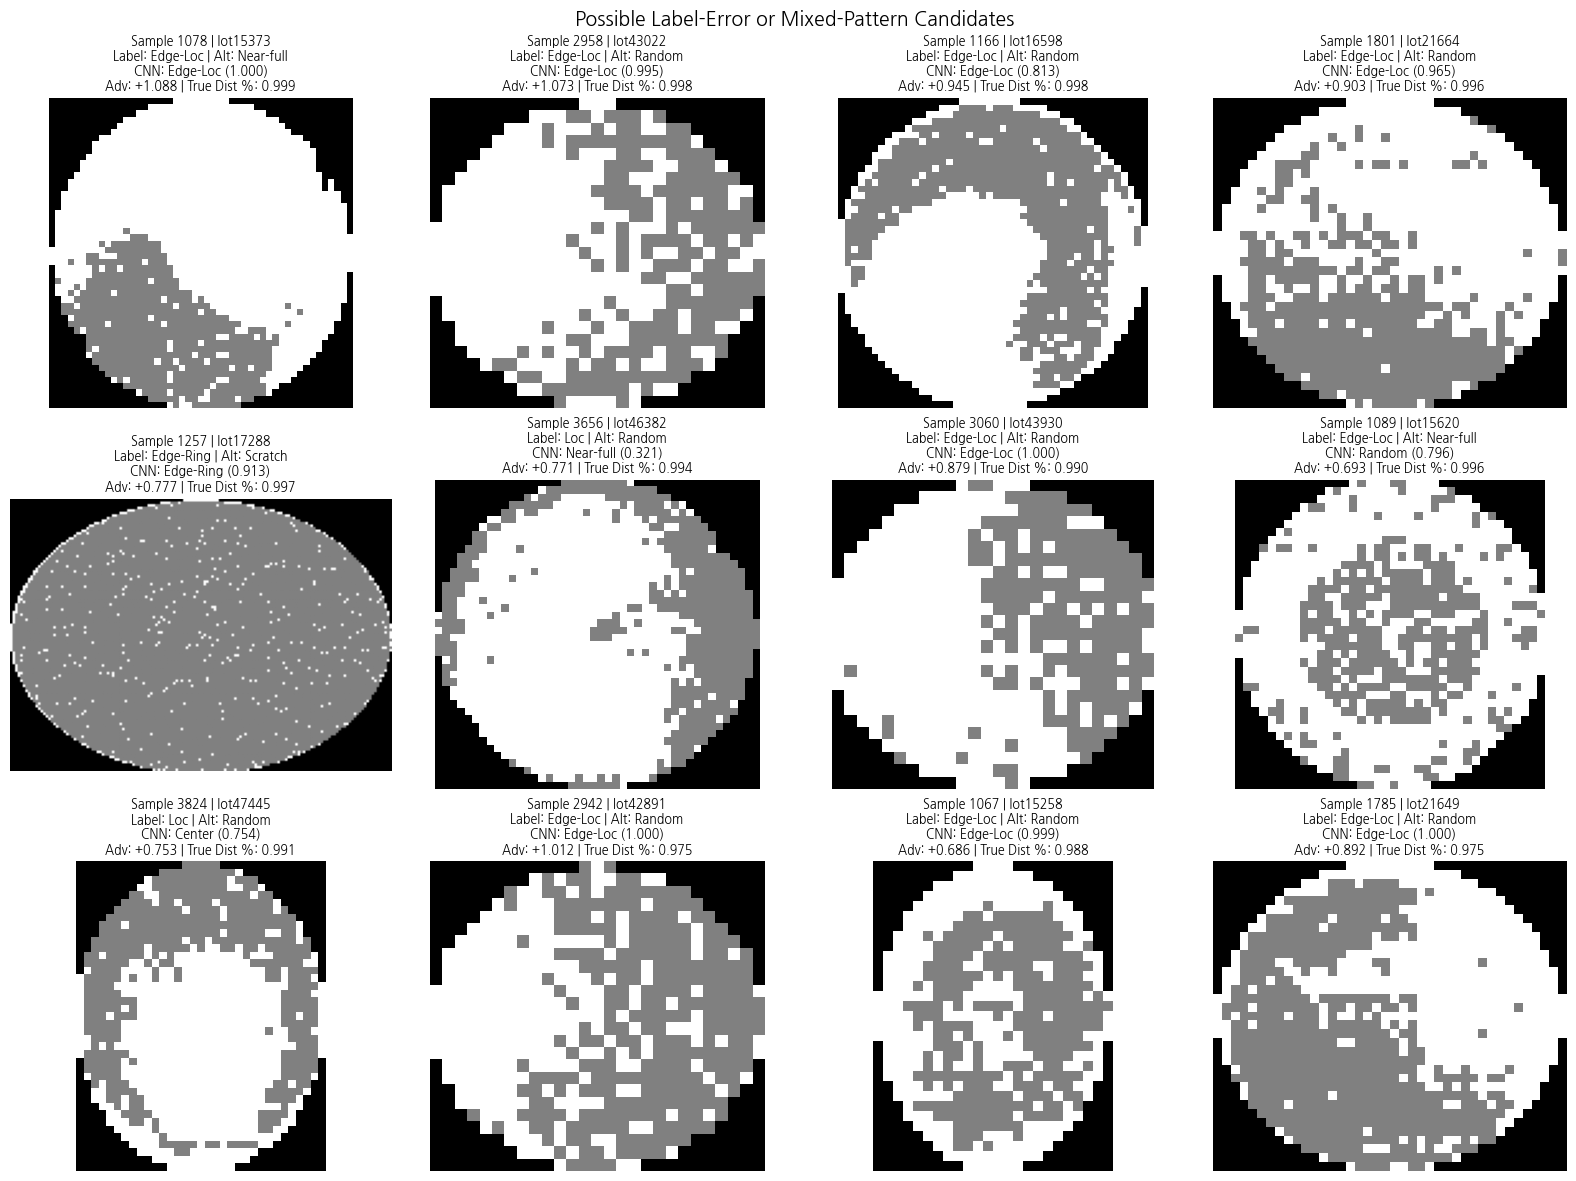

In [359]:
# Top Label-Pattern Candidate 시각화

TOP_REVIEW_COUNT = 12


top_label_review_df = (
    label_review_candidate_df
    .head(
        TOP_REVIEW_COUNT
    )
    .copy()
)


fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12)
)


axes = axes.flatten()


for ax, row in zip(
    axes,
    top_label_review_df.itertuples(
        index=False
    )
):

    sample_pos = int(
        row.sample_pos
    )


    raw_map = np.asarray(
        test_df.iloc[
            sample_pos
        ]["waferMap"]
    )


    ax.imshow(
        raw_map,
        cmap="gray",
        vmin=0,
        vmax=2
    )


    ax.set_title(

        f"Sample {sample_pos} | {row.lot_name}\n"
        f"Label: {row.true_label} | "
        f"Alt: {row.nearest_alternative_label}\n"
        f"CNN: {row.pred_label} "
        f"({row.top1_prob:.3f})\n"
        f"Adv: {row.alternative_profile_advantage:+.3f} | "
        f"True Dist %: {row.true_profile_distance_percentile:.3f}",

        fontsize=9
    )


    ax.axis(
        "off"
    )


# 남는 subplot 제거
for ax in axes[
    len(top_label_review_df):
]:

    ax.axis(
        "off"
    )


plt.suptitle(
    "Possible Label-Error or Mixed-Pattern Candidates",
    fontsize=14
)


plt.tight_layout()

plt.show()

In [360]:
# Label → Alternative Prototype 주요 관계

label_alternative_pair_df = (

    label_pattern_analysis_df[
        (
            label_pattern_analysis_df[
                "alternative_is_closer"
            ]
        )
        &
        (
            label_pattern_analysis_df[
                "refined_integrity_order"
            ]
            > 2
        )
    ]

    .groupby(
        [
            "true_label",
            "nearest_alternative_label"
        ]
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        median_advantage=(
            "alternative_profile_advantage",
            "median"
        ),

        median_true_percentile=(
            "true_profile_distance_percentile",
            "median"
        ),

        cnn_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        )
    )

    .reset_index()
)


label_alternative_pair_df[
    "cnn_error_rate"
] = (

    label_alternative_pair_df[
        "cnn_error_count"
    ]

    /
    label_alternative_pair_df[
        "sample_count"
    ]
)


print(
    "=== 주요 Label → Alternative Prototype 관계 ==="
)


display(
    label_alternative_pair_df

    .sort_values(
        "sample_count",
        ascending=False
    )

    .head(20)

    .style.format({

        "median_advantage":
            "{:+.4f}",

        "median_true_percentile":
            "{:.4f}",

        "cnn_error_rate":
            "{:.4f}"
    })
)

=== 주요 Label → Alternative Prototype 관계 ===


,true_label,nearest_alternative_label,sample_count,median_advantage,median_true_percentile,cnn_error_count,cnn_error_rate
16,Edge-Ring,Edge-Loc,236,+0.2200,0.8610,16,0.0678
14,Edge-Loc,Scratch,195,+0.0635,0.5415,6,0.0308
25,Loc,Scratch,151,+0.0774,0.5457,46,0.3046
4,Center,Scratch,83,+0.2006,0.8402,5,0.0602
22,Loc,Edge-Loc,66,+0.0643,0.3494,23,0.3485
21,Loc,Donut,66,+0.1513,0.8671,4,0.0606
11,Edge-Loc,Loc,58,+0.0456,0.5286,4,0.0690
20,Loc,Center,55,+0.1566,0.6673,14,0.2545
13,Edge-Loc,Random,50,+0.4466,0.9563,7,0.1400
0,Center,Donut,26,+0.1465,0.8942,1,0.0385


### Step 8-3 결과 해석

Train Set 기반 Spatial Prototype을 이용하여 실제 Label과 공간적 특성이 크게 불일치하는 Wafer를 탐색하였다.

Label–Spatial Pattern이 일관된 Sample의 CNN 오류율은 3.78%였던 반면, Strong Label–Pattern Mismatch Candidate에서는 23.08%로 증가하여 비전형적인 공간 구조와 CNN 오류 사이의 연관성을 확인하였다.

그러나 주요 Candidate를 원본 Wafer Map으로 직접 검토한 결과, Prototype 불일치가 반드시 Label Error를 의미하지는 않았다.

특히 Edge-Loc Sample 중 결함량이 많은 Wafer는 Spatial Feature상 Random 또는 Near-full Prototype에 가까워지는 경우가 있었으나, 실제 이미지에서는 결함이 특정 영역에 집중되어 Edge-Loc Label이 충분히 타당한 사례가 다수 확인되었다.

또한 일부 Sample에서는 두 개 이상의 결함 특성이 동시에 관찰되어 Mixed Pattern 또는 Class Boundary 가능성이 확인되었다.

따라서 Prototype Mismatch는 자동 재라벨링 기준으로 사용하지 않고, Label Error, Mixed Pattern, 비전형적 Class Variation을 구분하기 위한 Manual Review 우선순위로 활용한다.

## Step 8-4. 독립적인 Data-Quality Signal 통합 및 CNN Error Enrichment 분석

Step 8-2에서는 원본 Wafer Map의 Geometry 및 Measurement Structure를 분석하였고,
Step 8-3에서는 Train Set 기반 Spatial Prototype을 이용하여 Label–Pattern Consistency를 분석하였다.

이번 단계에서는 두 정보를 통합하여 추가 검토가 필요한 Wafer를 정의한다.

중요하게도 Review Candidate를 선정할 때 다음 정보는 사용하지 않는다.

- CNN Prediction
- CNN Confidence
- 정분류 / 오분류 여부

즉 Review Candidate는 원본 Wafer Geometry와 Label–Spatial Pattern 정보만으로 독립적으로 선정한다.

이후 CNN의 정분류 여부는 사후 평가에만 사용하여,
독립적인 Data-quality Warning이 실제 CNN Error가 발생하기 쉬운 Sample을 식별하는지 분석한다.

또한 Review Candidate를 제외한 Subset에서 CNN 성능이 어떻게 변화하는지 확인한다.

이 분석은 Sample을 실제로 삭제하거나 Test 성능을 인위적으로 높이기 위한 것이 아니라,
비전형적 Data 또는 Label–Pattern Ambiguity에 CNN Error가 얼마나 집중되어 있는지를 확인하는 Sensitivity Analysis이다.

In [361]:
# Step 8-4. CNN과 독립적인 Data-Quality Review Flag 생성

step8_4_analysis_df = (
    label_pattern_analysis_df.copy()
)


# ==================================================
# 1. Measurement / Geometry Review
# ==================================================
# Strong + Moderate 구조 검토만 포함

step8_4_analysis_df[
    "measurement_structure_review_flag"
] = (

    step8_4_analysis_df[
        "refined_integrity_order"
    ]
    <= 2
)


# ==================================================
# 2. Strong Spatial-Profile Mismatch
# ==================================================
# CNN prediction과 관계없이
# True Label Prototype에서 매우 멀고,
# Alternative Prototype이 강하게 더 가까운 경우
# ==================================================

step8_4_analysis_df[
    "strong_spatial_profile_mismatch_flag"
] = (

    step8_4_analysis_df[
        "alternative_is_closer"
    ]

    &

    (
        step8_4_analysis_df[
            "true_profile_distance_percentile"
        ]
        >= 0.95
    )

    &

    (
        step8_4_analysis_df[
            "alternative_profile_advantage"
        ]
        >= advantage_q90
    )
)


# ==================================================
# 3. High Spatial-Profile Mismatch
# ==================================================

step8_4_analysis_df[
    "high_spatial_profile_mismatch_flag"
] = (

    step8_4_analysis_df[
        "alternative_is_closer"
    ]

    &

    (
        step8_4_analysis_df[
            "true_profile_distance_percentile"
        ]
        >= 0.90
    )

    &

    (
        step8_4_analysis_df[
            "alternative_profile_advantage"
        ]
        >= advantage_q75
    )
)


# ==================================================
# 4. Strict Combined Review
#
# 구조적으로 강한 경고
# OR
# Strong Spatial Mismatch
# ==================================================

step8_4_analysis_df[
    "strict_combined_review_flag"
] = (

    step8_4_analysis_df[
        "measurement_structure_review_flag"
    ]

    |

    step8_4_analysis_df[
        "strong_spatial_profile_mismatch_flag"
    ]
)


# ==================================================
# 5. Broad Combined Review
#
# 구조 경고
# OR
# High Spatial Mismatch
# ==================================================

step8_4_analysis_df[
    "broad_combined_review_flag"
] = (

    step8_4_analysis_df[
        "measurement_structure_review_flag"
    ]

    |

    step8_4_analysis_df[
        "high_spatial_profile_mismatch_flag"
    ]
)


print(
    "✓ Independent Data-Quality Review Flag 생성 완료"
)

✓ Independent Data-Quality Review Flag 생성 완료


In [362]:
# Independent Review Candidate Summary

review_flag_specs = [

    (
        "Measurement-structure review",
        "measurement_structure_review_flag"
    ),

    (
        "Strong spatial-profile mismatch",
        "strong_spatial_profile_mismatch_flag"
    ),

    (
        "High spatial-profile mismatch",
        "high_spatial_profile_mismatch_flag"
    ),

    (
        "Strict combined review",
        "strict_combined_review_flag"
    ),

    (
        "Broad combined review",
        "broad_combined_review_flag"
    )
]


review_summary_rows = []


for review_name, flag_column in review_flag_specs:

    flag = (
        step8_4_analysis_df[
            flag_column
        ]
    )


    sample_count = int(
        flag.sum()
    )


    cnn_error_count = int(
        (
            ~step8_4_analysis_df.loc[
                flag,
                "correct"
            ]
        ).sum()
    )


    review_summary_rows.append({

        "review_group":
            review_name,

        "sample_count":
            sample_count,

        "sample_ratio":
            sample_count
            /
            len(step8_4_analysis_df),

        "cnn_error_count":
            cnn_error_count,

        "cnn_error_rate":
            (
                cnn_error_count
                /
                sample_count
                if sample_count > 0
                else np.nan
            )
    })


step8_4_review_candidate_summary_df = (
    pd.DataFrame(
        review_summary_rows
    )
)


print(
    "=== Independent Review Candidate Summary ==="
)


display(
    step8_4_review_candidate_summary_df
    .style.format({

        "sample_ratio":
            "{:.4f}",

        "cnn_error_rate":
            "{:.4f}"
    })
)

=== Independent Review Candidate Summary ===


,review_group,sample_count,sample_ratio,cnn_error_count,cnn_error_rate
0,Measurement-structure review,56,0.0143,20,0.3571
1,Strong spatial-profile mismatch,56,0.0143,19,0.3393
2,High spatial-profile mismatch,182,0.0465,39,0.2143
3,Strict combined review,108,0.0276,38,0.3519
4,Broad combined review,231,0.0591,57,0.2468


In [363]:
# Step 8-4. Independent Data-Quality Filtering Sensitivity Analysis

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)


def calculate_classification_metrics(
    dataframe
):

    y_true_subset = (
        dataframe[
            "true_label"
        ]
    )

    y_pred_subset = (
        dataframe[
            "pred_label"
        ]
    )


    accuracy = accuracy_score(
        y_true_subset,
        y_pred_subset
    )


    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(

            y_true_subset,
            y_pred_subset,

            labels=CLASS_NAMES,

            average="macro",

            zero_division=0
        )
    )


    _, _, weighted_f1, _ = (
        precision_recall_fscore_support(

            y_true_subset,
            y_pred_subset,

            labels=CLASS_NAMES,

            average="weighted",

            zero_division=0
        )
    )


    error_count = int(
        (
            y_true_subset
            !=
            y_pred_subset
        ).sum()
    )


    return {

        "retained_sample_count":
            len(dataframe),

        "cnn_error_count":
            error_count,

        "cnn_error_rate":
            error_count
            /
            len(dataframe),

        "accuracy":
            accuracy,

        "macro_precision":
            macro_precision,

        "macro_recall":
            macro_recall,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1
    }

    # --------------------------------------------------
# 비교 Scenario
# --------------------------------------------------

sensitivity_scenarios = {

    "1. All test samples":
        np.ones(
            len(step8_4_analysis_df),
            dtype=bool
        ),

    "2. Exclude measurement-structure candidates":
        ~step8_4_analysis_df[
            "measurement_structure_review_flag"
        ],

    "3. Exclude structure + strong profile mismatch":
        ~step8_4_analysis_df[
            "strict_combined_review_flag"
        ],

    "4. Exclude structure + high profile mismatch":
        ~step8_4_analysis_df[
            "broad_combined_review_flag"
        ]
}


sensitivity_rows = []


for scenario_name, retain_mask in (
    sensitivity_scenarios.items()
):

    subset_df = (
        step8_4_analysis_df.loc[
            retain_mask
        ]
    )


    metrics = (
        calculate_classification_metrics(
            subset_df
        )
    )


    metrics[
        "scenario"
    ] = scenario_name


    metrics[
        "excluded_sample_count"
    ] = (

        len(step8_4_analysis_df)
        -
        len(subset_df)
    )


    metrics[
        "retained_sample_ratio"
    ] = (

        len(subset_df)
        /
        len(step8_4_analysis_df)
    )


    sensitivity_rows.append(
        metrics
    )


step8_4_sensitivity_summary_df = pd.DataFrame(
    sensitivity_rows
)


# --------------------------------------------------
# Baseline 대비 변화량
# --------------------------------------------------

baseline_accuracy = (
    step8_4_sensitivity_summary_df
    .iloc[0]["accuracy"]
)

baseline_macro_f1 = (
    step8_4_sensitivity_summary_df
    .iloc[0]["macro_f1"]
)

baseline_weighted_f1 = (
    step8_4_sensitivity_summary_df
    .iloc[0]["weighted_f1"]
)


step8_4_sensitivity_summary_df[
    "accuracy_change"
] = (

    step8_4_sensitivity_summary_df[
        "accuracy"
    ]

    -
    baseline_accuracy
)


step8_4_sensitivity_summary_df[
    "macro_f1_change"
] = (

    step8_4_sensitivity_summary_df[
        "macro_f1"
    ]

    -
    baseline_macro_f1
)


step8_4_sensitivity_summary_df[
    "weighted_f1_change"
] = (

    step8_4_sensitivity_summary_df[
        "weighted_f1"
    ]

    -
    baseline_weighted_f1
)


print(
    "=== CNN Performance Before and After Independent Data-Quality Filtering ==="
)


display(
    step8_4_sensitivity_summary_df[
        [
            "scenario",

            "retained_sample_count",
            "excluded_sample_count",
            "retained_sample_ratio",

            "cnn_error_count",
            "cnn_error_rate",

            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",

            "accuracy_change",
            "macro_f1_change",
            "weighted_f1_change"
        ]
    ]
    .style.format({

        "retained_sample_ratio":
            "{:.4f}",

        "cnn_error_rate":
            "{:.4f}",

        "accuracy":
            "{:.4f}",

        "macro_precision":
            "{:.4f}",

        "macro_recall":
            "{:.4f}",

        "macro_f1":
            "{:.4f}",

        "weighted_f1":
            "{:.4f}",

        "accuracy_change":
            "{:+.4f}",

        "macro_f1_change":
            "{:+.4f}",

        "weighted_f1_change":
            "{:+.4f}"
    })
)

=== CNN Performance Before and After Independent Data-Quality Filtering ===


,scenario,retained_sample_count,excluded_sample_count,retained_sample_ratio,cnn_error_count,cnn_error_rate,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,accuracy_change,macro_f1_change,weighted_f1_change
0,1. All test samples,3911,0,1.0000,375,0.0959,0.9041,0.8509,0.8296,0.8350,0.9002,+0.0000,+0.0000,+0.0000
1,2. Exclude measurement-structure candidates,3855,56,0.9857,355,0.0921,0.9079,0.8534,0.8300,0.8357,0.9040,+0.0038,+0.0006,+0.0037
2,3. Exclude structure + strong profile mismatch,3803,108,0.9724,337,0.0886,0.9114,0.8619,0.8338,0.8421,0.9076,+0.0073,+0.0071,+0.0073
3,4. Exclude structure + high profile mismatch,3680,231,0.9409,318,0.0864,0.9136,0.8683,0.8394,0.8480,0.9096,+0.0095,+0.0129,+0.0093


In [364]:
# Independent Review Flag의 Error Capture Rate

total_test_errors = int(
    (
        ~step8_4_analysis_df[
            "correct"
        ]
    ).sum()
)


capture_rows = []


for review_name, flag_column in review_flag_specs:

    flag = (
        step8_4_analysis_df[
            flag_column
        ]
    )


    flagged_count = int(
        flag.sum()
    )


    flagged_error_count = int(
        (
            ~step8_4_analysis_df.loc[
                flag,
                "correct"
            ]
        ).sum()
    )


    correct_review_count = (
        flagged_count
        -
        flagged_error_count
    )


    capture_rows.append({

        "review_group":
            review_name,

        "review_sample_count":
            flagged_count,

        "review_sample_rate":
            flagged_count
            /
            len(step8_4_analysis_df),

        "review_error_count":
            flagged_error_count,

        "error_capture_rate":
            flagged_error_count
            /
            total_test_errors,

        "correct_sample_review_rate":
            correct_review_count
            /
            int(
                step8_4_analysis_df[
                    "correct"
                ].sum()
            )
    })


step8_4_error_capture_df = pd.DataFrame(
    capture_rows
)


print(
    "=== Independent Review Error Capture ==="
)

print(
    "전체 CNN Error:",
    total_test_errors
)


display(
    step8_4_error_capture_df
    .style.format({

        "review_sample_rate":
            "{:.4f}",

        "error_capture_rate":
            "{:.4f}",

        "correct_sample_review_rate":
            "{:.4f}"
    })
)

=== Independent Review Error Capture ===
전체 CNN Error: 375


,review_group,review_sample_count,review_sample_rate,review_error_count,error_capture_rate,correct_sample_review_rate
0,Measurement-structure review,56,0.0143,20,0.0533,0.0102
1,Strong spatial-profile mismatch,56,0.0143,19,0.0507,0.0105
2,High spatial-profile mismatch,182,0.0465,39,0.1040,0.0404
3,Strict combined review,108,0.0276,38,0.1013,0.0198
4,Broad combined review,231,0.0591,57,0.1520,0.0492


In [365]:
# Step 8-4 주요 변수 저장

step8_4_strict_review_candidates_df = (

    step8_4_analysis_df[
        step8_4_analysis_df[
            "strict_combined_review_flag"
        ]
    ]
    .copy()
)


step8_4_broad_review_candidates_df = (

    step8_4_analysis_df[
        step8_4_analysis_df[
            "broad_combined_review_flag"
        ]
    ]
    .copy()
)


step8_4_strict_lower_risk_df = (

    step8_4_analysis_df[
        ~step8_4_analysis_df[
            "strict_combined_review_flag"
        ]
    ]
    .copy()
)


step8_4_broad_lower_risk_df = (

    step8_4_analysis_df[
        ~step8_4_analysis_df[
            "broad_combined_review_flag"
        ]
    ]
    .copy()
)


print(
    "Saved variables:"
)

print(
    "- step8_4_analysis_df:",
    step8_4_analysis_df.shape
)

print(
    "- step8_4_strict_review_candidates_df:",
    step8_4_strict_review_candidates_df.shape
)

print(
    "- step8_4_broad_review_candidates_df:",
    step8_4_broad_review_candidates_df.shape
)

print(
    "- step8_4_strict_lower_risk_df:",
    step8_4_strict_lower_risk_df.shape
)

print(
    "- step8_4_broad_lower_risk_df:",
    step8_4_broad_lower_risk_df.shape
)

Saved variables:
- step8_4_analysis_df: (3911, 25)
- step8_4_strict_review_candidates_df: (108, 25)
- step8_4_broad_review_candidates_df: (231, 25)
- step8_4_strict_lower_risk_df: (3803, 25)
- step8_4_broad_lower_risk_df: (3680, 25)


## Step 8-4B. Independent Data-Quality Warning의 Error Enrichment 통계 검증

독립적인 Data-quality Review Candidate에서 CNN Error Rate가 높게 나타났지만,
관찰된 차이가 우연한 변동인지 확인하기 위해 통계 검정을 수행한다.

각 Review Flag에 대해 다음 두 그룹을 비교한다.

- Review Flag가 있는 Wafer
- Review Flag가 없는 Wafer

각 그룹에서 CNN 정분류와 오분류의 빈도를 이용하여 2×2 Contingency Table을 구성한다.

### Fisher's Exact Test

Review Flag와 CNN Error 발생 여부 사이에 통계적 연관성이 존재하는지 검정한다.

### Risk Ratio

Review Candidate의 CNN Error 발생 확률이 일반 Wafer에 비해 몇 배 높은지를 계산한다.

- Risk Ratio = 1: Error Risk 차이 없음
- Risk Ratio > 1: Review Candidate에서 Error Risk 증가
- Risk Ratio < 1: Review Candidate에서 Error Risk 감소

Risk Ratio와 함께 95% Confidence Interval을 계산한다.

여러 Review Rule을 동시에 검정하므로 Benjamini–Hochberg FDR Correction을 적용한다.

이 분석은 Review Flag가 CNN Error의 원인임을 증명하는 것이 아니라,
독립적인 Data-quality Warning과 CNN Error 사이의 통계적 연관성을 평가한다.

In [366]:
# Step 8-4B. Fisher Exact Test + Risk Ratio

from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests


error_enrichment_rows = []


for review_name, flag_column in review_flag_specs:

    flag = (
        step8_4_analysis_df[
            flag_column
        ].astype(bool)
    )


    # ==================================================
    # 2×2 Table
    #
    #                  Error   Correct
    # Flagged             a         b
    # Unflagged           c         d
    # ==================================================

    a = int(
        (
            flag
            &
            (~step8_4_analysis_df["correct"])
        ).sum()
    )

    b = int(
        (
            flag
            &
            step8_4_analysis_df["correct"]
        ).sum()
    )

    c = int(
        (
            (~flag)
            &
            (~step8_4_analysis_df["correct"])
        ).sum()
    )

    d = int(
        (
            (~flag)
            &
            step8_4_analysis_df["correct"]
        ).sum()
    )


    flagged_count = (
        a + b
    )

    unflagged_count = (
        c + d
    )


    flagged_error_rate = (
        a / flagged_count
    )

    unflagged_error_rate = (
        c / unflagged_count
    )


    # --------------------------------------------------
    # Fisher Exact Test
    # --------------------------------------------------

    odds_ratio, p_value = (
        fisher_exact(
            [
                [a, b],
                [c, d]
            ],
            alternative="two-sided"
        )
    )


    # --------------------------------------------------
    # Risk Ratio
    # --------------------------------------------------

    risk_ratio = (
        flagged_error_rate
        /
        unflagged_error_rate
        if unflagged_error_rate > 0
        else np.nan
    )


    # --------------------------------------------------
    # Risk Ratio 95% CI
    #
    # log(RR)의 표준오차를 이용
    # --------------------------------------------------

    if (
        a > 0
        and c > 0
        and flagged_count > 0
        and unflagged_count > 0
    ):

        log_rr_se = np.sqrt(

            (1 / a)
            -
            (1 / flagged_count)

            +

            (1 / c)
            -
            (1 / unflagged_count)
        )


        rr_ci_lower = np.exp(
            np.log(risk_ratio)
            -
            1.96 * log_rr_se
        )


        rr_ci_upper = np.exp(
            np.log(risk_ratio)
            +
            1.96 * log_rr_se
        )

    else:

        rr_ci_lower = np.nan
        rr_ci_upper = np.nan


    # --------------------------------------------------
    # 전체 Error 중 해당 Flag가 포착한 비율
    # --------------------------------------------------

    error_capture_rate = (
        a
        /
        total_test_errors
    )


    # 정상 Sample 중 Review로 보내지는 비율
    total_correct_count = int(
        step8_4_analysis_df[
            "correct"
        ].sum()
    )


    correct_sample_review_rate = (
        b
        /
        total_correct_count
    )


    error_enrichment_rows.append({

        "review_group":
            review_name,

        "flagged_sample_count":
            flagged_count,

        "flagged_sample_ratio":
            flagged_count
            /
            len(step8_4_analysis_df),

        "flagged_error_count":
            a,

        "flagged_error_rate":
            flagged_error_rate,

        "unflagged_error_rate":
            unflagged_error_rate,

        "error_risk_ratio":
            risk_ratio,

        "risk_ratio_ci_lower":
            rr_ci_lower,

        "risk_ratio_ci_upper":
            rr_ci_upper,

        "odds_ratio":
            odds_ratio,

        "error_capture_rate":
            error_capture_rate,

        "correct_sample_review_rate":
            correct_sample_review_rate,

        "p_value":
            p_value
    })


step8_4_overall_error_enrichment_df = (
    pd.DataFrame(
        error_enrichment_rows
    )
)


# ==================================================
# FDR Correction
# ==================================================

reject, adjusted_p, _, _ = (
    multipletests(

        step8_4_overall_error_enrichment_df[
            "p_value"
        ],

        alpha=0.05,

        method="fdr_bh"
    )
)


step8_4_overall_error_enrichment_df[
    "adjusted_p_value"
] = adjusted_p


step8_4_overall_error_enrichment_df[
    "statistically_significant"
] = reject


print(
    "=== Overall Statistical Error-Enrichment Test ==="
)


display(
    step8_4_overall_error_enrichment_df
    .style.format({

        "flagged_sample_ratio":
            "{:.4f}",

        "flagged_error_rate":
            "{:.4f}",

        "unflagged_error_rate":
            "{:.4f}",

        "error_risk_ratio":
            "{:.3f}",

        "risk_ratio_ci_lower":
            "{:.3f}",

        "risk_ratio_ci_upper":
            "{:.3f}",

        "odds_ratio":
            "{:.3f}",

        "error_capture_rate":
            "{:.4f}",

        "correct_sample_review_rate":
            "{:.4f}",

        "p_value":
            "{:.3e}",

        "adjusted_p_value":
            "{:.3e}"
    })
)

=== Overall Statistical Error-Enrichment Test ===


,review_group,flagged_sample_count,flagged_sample_ratio,flagged_error_count,flagged_error_rate,unflagged_error_rate,error_risk_ratio,risk_ratio_ci_lower,risk_ratio_ci_upper,odds_ratio,error_capture_rate,correct_sample_review_rate,p_value,adjusted_p_value,statistically_significant
0,Measurement-structure review,56,0.0143,20,0.3571,0.0921,3.878,2.692,5.587,5.477,0.0533,0.0102,8.053e-08,1.342e-07,True
1,Strong spatial-profile mismatch,56,0.0143,19,0.3393,0.0923,3.674,2.516,5.365,5.047,0.0507,0.0105,4.352e-07,5.440e-07,True
2,High spatial-profile mismatch,182,0.0465,39,0.2143,0.0901,2.378,1.768,3.198,2.754,0.1040,0.0404,8.426e-07,8.426e-07,True
3,Strict combined review,108,0.0276,38,0.3519,0.0886,3.971,3.014,5.230,5.583,0.1013,0.0198,1.432e-13,7.159e-13,True
4,Broad combined review,231,0.0591,57,0.2468,0.0864,2.856,2.227,3.661,3.463,0.1520,0.0492,3.195e-12,7.989e-12,True


In [367]:
# Error Enrichment 해석 Label

def interpret_error_enrichment(row):

    if not row[
        "statistically_significant"
    ]:

        return (
            "No statistically confirmed enrichment"
        )


    rr = row[
        "error_risk_ratio"
    ]


    if rr >= 3.0:

        return (
            "Strong error enrichment"
        )

    elif rr >= 1.5:

        return (
            "Moderate error enrichment"
        )

    else:

        return (
            "Statistically significant but small enrichment"
        )


step8_4_overall_error_enrichment_df[
    "association_interpretation"
] = (

    step8_4_overall_error_enrichment_df.apply(
        interpret_error_enrichment,
        axis=1
    )
)


display(
    step8_4_overall_error_enrichment_df[
        [
            "review_group",

            "flagged_sample_count",
            "flagged_error_rate",
            "unflagged_error_rate",

            "error_risk_ratio",
            "risk_ratio_ci_lower",
            "risk_ratio_ci_upper",

            "error_capture_rate",

            "adjusted_p_value",
            "statistically_significant",

            "association_interpretation"
        ]
    ]
    .style.format({

        "flagged_error_rate":
            "{:.4f}",

        "unflagged_error_rate":
            "{:.4f}",

        "error_risk_ratio":
            "{:.3f}",

        "risk_ratio_ci_lower":
            "{:.3f}",

        "risk_ratio_ci_upper":
            "{:.3f}",

        "error_capture_rate":
            "{:.4f}",

        "adjusted_p_value":
            "{:.3e}"
    })
)

,review_group,flagged_sample_count,flagged_error_rate,unflagged_error_rate,error_risk_ratio,risk_ratio_ci_lower,risk_ratio_ci_upper,error_capture_rate,adjusted_p_value,statistically_significant,association_interpretation
0,Measurement-structure review,56,0.3571,0.0921,3.878,2.692,5.587,0.0533,1.342e-07,True,Strong error enrichment
1,Strong spatial-profile mismatch,56,0.3393,0.0923,3.674,2.516,5.365,0.0507,5.440e-07,True,Strong error enrichment
2,High spatial-profile mismatch,182,0.2143,0.0901,2.378,1.768,3.198,0.1040,8.426e-07,True,Moderate error enrichment
3,Strict combined review,108,0.3519,0.0886,3.971,3.014,5.230,0.1013,7.159e-13,True,Strong error enrichment
4,Broad combined review,231,0.2468,0.0864,2.856,2.227,3.661,0.1520,7.989e-12,True,Moderate error enrichment


In [368]:
# Step 8-4C. 클래스별 Error Enrichment 분석

CLASSWISE_REVIEW_FLAGS = [

    (
        "Strict combined review",
        "strict_combined_review_flag"
    ),

    (
        "Broad combined review",
        "broad_combined_review_flag"
    )
]


classwise_enrichment_rows = []


for class_name in CLASS_NAMES:

    class_df = (
        step8_4_analysis_df[
            step8_4_analysis_df[
                "true_label"
            ]
            ==
            class_name
        ]
        .copy()
    )


    for review_name, flag_column in (
        CLASSWISE_REVIEW_FLAGS
    ):

        flag = (
            class_df[
                flag_column
            ].astype(bool)
        )


        a = int(
            (
                flag
                &
                (~class_df["correct"])
            ).sum()
        )

        b = int(
            (
                flag
                &
                class_df["correct"]
            ).sum()
        )

        c = int(
            (
                (~flag)
                &
                (~class_df["correct"])
            ).sum()
        )

        d = int(
            (
                (~flag)
                &
                class_df["correct"]
            ).sum()
        )


        flagged_count = (
            a + b
        )

        unflagged_count = (
            c + d
        )


        if flagged_count == 0:

            continue


        flagged_error_rate = (
            a
            /
            flagged_count
        )


        unflagged_error_rate = (

            c
            /
            unflagged_count

            if unflagged_count > 0
            else np.nan
        )


        risk_ratio = (

            flagged_error_rate
            /
            unflagged_error_rate

            if (
                unflagged_error_rate > 0
            )
            else np.nan
        )


        odds_ratio, p_value = (
            fisher_exact(
                [
                    [a, b],
                    [c, d]
                ],
                alternative="two-sided"
            )
        )


        class_error_count = int(
            (
                ~class_df["correct"]
            ).sum()
        )


        error_capture_rate = (

            a
            /
            class_error_count

            if class_error_count > 0
            else np.nan
        )


        classwise_enrichment_rows.append({

            "true_label":
                class_name,

            "review_group":
                review_name,

            "class_sample_count":
                len(class_df),

            "flagged_sample_count":
                flagged_count,

            "flagged_error_count":
                a,

            "flagged_error_rate":
                flagged_error_rate,

            "unflagged_error_rate":
                unflagged_error_rate,

            "error_risk_ratio":
                risk_ratio,

            "error_capture_rate":
                error_capture_rate,

            "odds_ratio":
                odds_ratio,

            "p_value":
                p_value
        })


step8_4_classwise_error_enrichment_df = (
    pd.DataFrame(
        classwise_enrichment_rows
    )
)

# ==================================================
# Class-wise Multiple Testing Correction
# ==================================================

reject, adjusted_p, _, _ = (
    multipletests(

        step8_4_classwise_error_enrichment_df[
            "p_value"
        ],

        alpha=0.05,

        method="fdr_bh"
    )
)


step8_4_classwise_error_enrichment_df[
    "adjusted_p_value"
] = adjusted_p


step8_4_classwise_error_enrichment_df[
    "statistically_significant"
] = reject


step8_4_classwise_error_enrichment_df[
    "association_interpretation"
] = (

    step8_4_classwise_error_enrichment_df
    .apply(

        lambda row:

        (
            "Strong error enrichment"

            if (
                row[
                    "statistically_significant"
                ]
                and
                row[
                    "error_risk_ratio"
                ]
                >= 3
            )

            else

            "Moderate error enrichment"

            if (
                row[
                    "statistically_significant"
                ]
                and
                row[
                    "error_risk_ratio"
                ]
                >= 1.5
            )

            else

            "Not statistically confirmed"
        ),

        axis=1
    )
)


print(
    "=== Class-wise Statistical Error-Enrichment Test ==="
)


display(
    step8_4_classwise_error_enrichment_df

    .sort_values(
        [
            "statistically_significant",
            "error_risk_ratio"
        ],
        ascending=[
            False,
            False
        ]
    )

    .style.format({

        "flagged_error_rate":
            "{:.4f}",

        "unflagged_error_rate":
            "{:.4f}",

        "error_risk_ratio":
            "{:.3f}",

        "error_capture_rate":
            "{:.4f}",

        "odds_ratio":
            "{:.3f}",

        "p_value":
            "{:.3e}",

        "adjusted_p_value":
            "{:.3e}"
    })
)

=== Class-wise Statistical Error-Enrichment Test ===


,true_label,review_group,class_sample_count,flagged_sample_count,flagged_error_count,flagged_error_rate,unflagged_error_rate,error_risk_ratio,error_capture_rate,odds_ratio,p_value,adjusted_p_value,statistically_significant,association_interpretation
5,Edge-Ring,Strict combined review,1508,12,4,0.3333,0.0174,19.179,0.1333,28.269,5.654e-05,2.120e-04,True,Strong error enrichment
6,Edge-Ring,Broad combined review,1508,80,11,0.1375,0.0133,10.334,0.3667,11.822,1.135e-07,1.703e-06,True,Strong error enrichment
1,Center,Broad combined review,636,19,3,0.1579,0.0227,6.959,0.1765,8.076,1.181e-02,2.953e-02,True,Strong error enrichment
3,Edge-Loc,Strict combined review,841,47,14,0.2979,0.0655,4.548,0.2121,6.054,3.839e-06,1.919e-05,True,Strong error enrichment
4,Edge-Loc,Broad combined review,841,65,17,0.2615,0.0631,4.142,0.2576,5.255,2.184e-06,1.638e-05,True,Strong error enrichment
12,Random,Broad combined review,97,8,5,0.6250,0.1798,3.477,0.2381,7.604,1.103e-02,2.953e-02,True,Strong error enrichment
0,Center,Strict combined review,636,4,1,0.2500,0.0253,9.875,0.0588,12.833,1.029e-01,1.930e-01,False,Not statistically confirmed
2,Donut,Broad combined review,79,1,1,1.0000,0.1154,8.667,0.1000,inf,1.266e-01,2.110e-01,False,Not statistically confirmed
11,Random,Strict combined review,97,4,2,0.5000,0.2043,2.447,0.0952,3.895,2.036e-01,3.055e-01,False,Not statistically confirmed
7,Loc,Strict combined review,541,30,11,0.3667,0.2133,1.719,0.0917,2.135,6.766e-02,1.450e-01,False,Not statistically confirmed


In [369]:
# Step 8-4 Statistical Results 저장

step8_4_overall_error_enrichment_df = (
    step8_4_overall_error_enrichment_df.copy()
)

step8_4_classwise_error_enrichment_df = (
    step8_4_classwise_error_enrichment_df.copy()
)


print(
    "Saved variables:"
)

print(
    "- step8_4_overall_error_enrichment_df:",
    step8_4_overall_error_enrichment_df.shape
)

print(
    "- step8_4_classwise_error_enrichment_df:",
    step8_4_classwise_error_enrichment_df.shape
)

Saved variables:
- step8_4_overall_error_enrichment_df: (5, 16)
- step8_4_classwise_error_enrichment_df: (15, 14)


## Step 8-5. Final Data Validation Framework

Step 8에서는 CNN Prediction 자체가 아니라 원본 Wafer Map과 Train 기반 Spatial Pattern을 이용하여 데이터 품질을 독립적으로 검증하였다.

분석은 다음 네 단계로 수행하였다.

1. Raw Wafer Map Integrity
2. Wafer Geometry / Measurement Structure Validation
3. Label–Spatial Pattern Consistency Validation
4. Independent Data-quality Warning과 CNN Error의 통계적 연관성 검증

전체 Test Set에서는 명백하게 손상된 Raw Wafer Map이 발견되지 않았다.

그러나 일부 Wafer는 비전형적인 Geometry 또는 Label–Spatial Pattern 불일치를 보였으며, 이러한 Sample에서는 CNN Error가 유의하게 농축되었다.

특히 Strict Combined Review Candidate의 CNN Error Risk는 비검토 Sample보다 약 3.2배 높았으며, Fisher's Exact Test 및 FDR Correction 이후에도 통계적으로 유의하였다.

따라서 최종 Data Validation에서는 Sample을 자동 삭제하거나 재라벨링하지 않고, 독립적인 Data-quality Signal의 종류와 강도에 따라 Review Priority를 정의한다.

본 단계에서 Label–Pattern Consistency는 실제 Label이 존재하는 학습 및 평가 데이터의 품질 검증에 사용한다.

향후 새로운 Unlabeled Wafer의 자동 진단에서는 실제 Label을 사용할 수 없으므로, Prediction Confidence, Predicted-Class Prototype Distance, Input Geometry 및 Grad-CAM 등의 Deployment 가능한 Signal을 이용하여 별도의 Reliability 판단을 수행한다.

In [370]:
# Step 8-5. Final Data Review Level

step8_final_validation_df = (
    step8_4_analysis_df.copy()
)


def assign_final_data_review_level(row):

    structure_flag = bool(
        row[
            "measurement_structure_review_flag"
        ]
    )

    strong_pattern_flag = bool(
        row[
            "strong_spatial_profile_mismatch_flag"
        ]
    )

    high_pattern_flag = bool(
        row[
            "high_spatial_profile_mismatch_flag"
        ]
    )


    # ==================================================
    # 1. Structure + Strong Label Pattern 모두 경고
    # ==================================================

    if (
        structure_flag
        and
        strong_pattern_flag
    ):

        return (
            "1. Immediate structure-and-label review"
        )


    # ==================================================
    # 2. Measurement Structure 우선
    # ==================================================

    if structure_flag:

        return (
            "2. Measurement-structure review first"
        )


    # ==================================================
    # 3. Strong Label–Pattern Review
    # ==================================================

    if strong_pattern_flag:

        return (
            "3. Strong label-pattern review"
        )


    # ==================================================
    # 4. High Spatial Mismatch
    # ==================================================

    if high_pattern_flag:

        return (
            "4. Targeted spatial-profile audit"
        )


    # ==================================================
    # 5. Warning 없음
    # ==================================================

    return (
        "5. No independent data-quality warning"
    )


step8_final_validation_df[
    "final_data_review_level"
] = (

    step8_final_validation_df
    .apply(
        assign_final_data_review_level,
        axis=1
    )
)


step8_final_validation_df[
    "final_review_priority_order"
] = (

    step8_final_validation_df[
        "final_data_review_level"
    ]

    .str.extract(
        r"^(\d+)"
    )

    .astype(int)
)

In [371]:
# Final Integrated Data Validation Summary

step8_final_validation_summary_df = (

    step8_final_validation_df

    .groupby(
        [
            "final_review_priority_order",
            "final_data_review_level"
        ]
    )

    .agg(

        sample_count=(
            "sample_pos",
            "count"
        ),

        cnn_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        ),

        median_top1_prob=(
            "top1_prob",
            "median"
        )
    )

    .reset_index()
)


step8_final_validation_summary_df[
    "cnn_error_rate"
] = (

    step8_final_validation_summary_df[
        "cnn_error_count"
    ]

    /
    step8_final_validation_summary_df[
        "sample_count"
    ]
)


step8_final_validation_summary_df[
    "sample_ratio"
] = (

    step8_final_validation_summary_df[
        "sample_count"
    ]

    /
    len(
        step8_final_validation_df
    )
)


step8_final_validation_summary_df[
    "error_capture_rate"
] = (

    step8_final_validation_summary_df[
        "cnn_error_count"
    ]

    /
    total_test_errors
)


print(
    "=== Final Integrated Data-Validation Summary ==="
)


display(
    step8_final_validation_summary_df

    .sort_values(
        "final_review_priority_order"
    )

    .style.format({

        "cnn_error_rate":
            "{:.4f}",

        "sample_ratio":
            "{:.4f}",

        "error_capture_rate":
            "{:.4f}",

        "median_top1_prob":
            "{:.4f}"
    })
)

=== Final Integrated Data-Validation Summary ===


,final_review_priority_order,final_data_review_level,sample_count,cnn_error_count,median_top1_prob,cnn_error_rate,sample_ratio,error_capture_rate
0,1,1. Immediate structure-and-label review,4,1,0.9160,0.2500,0.0010,0.0027
1,2,2. Measurement-structure review first,52,19,0.7746,0.3654,0.0133,0.0507
2,3,3. Strong label-pattern review,52,18,0.9429,0.3462,0.0133,0.0480
3,4,4. Targeted spatial-profile audit,123,19,0.9848,0.1545,0.0314,0.0507
4,5,5. No independent data-quality warning,3680,318,0.9995,0.0864,0.9409,0.8480


In [372]:
# 클래스별 Final Data Review Summary

step8_final_class_review_summary_df = (

    step8_final_validation_df[
        step8_final_validation_df[
            "final_review_priority_order"
        ]
        <= 4
    ]

    .groupby(
        [
            "true_label",
            "final_data_review_level"
        ]
    )

    .agg(

        review_sample_count=(
            "sample_pos",
            "count"
        ),

        review_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        )
    )

    .reset_index()
)


step8_final_class_review_summary_df[
    "review_error_rate"
] = (

    step8_final_class_review_summary_df[
        "review_error_count"
    ]

    /
    step8_final_class_review_summary_df[
        "review_sample_count"
    ]
)


# --------------------------------------------------
# 전체 클래스 통계 연결
# --------------------------------------------------

class_total_info = (

    step8_final_validation_df

    .groupby(
        "true_label"
    )

    .agg(

        class_sample_count=(
            "sample_pos",
            "count"
        ),

        class_error_count=(
            "correct",
            lambda x:
                (~x).sum()
        )
    )

    .reset_index()
)


step8_final_class_review_summary_df = (

    step8_final_class_review_summary_df

    .merge(
        class_total_info,
        on="true_label",
        how="left"
    )
)


step8_final_class_review_summary_df[
    "class_review_sample_rate"
] = (

    step8_final_class_review_summary_df[
        "review_sample_count"
    ]

    /
    step8_final_class_review_summary_df[
        "class_sample_count"
    ]
)


step8_final_class_review_summary_df[
    "class_error_capture_rate"
] = np.where(

    step8_final_class_review_summary_df[
        "class_error_count"
    ]
    > 0,

    step8_final_class_review_summary_df[
        "review_error_count"
    ]

    /
    step8_final_class_review_summary_df[
        "class_error_count"
    ],

    np.nan
)


print(
    "=== Class-wise Final Review Summary ==="
)


display(
    step8_final_class_review_summary_df

    .sort_values(
        "review_error_rate",
        ascending=False
    )

    .style.format({

        "review_error_rate":
            "{:.4f}",

        "class_review_sample_rate":
            "{:.4f}",

        "class_error_capture_rate":
            "{:.4f}"
    })
)

=== Class-wise Final Review Summary ===


,true_label,final_data_review_level,review_sample_count,review_error_count,review_error_rate,class_sample_count,class_error_count,class_review_sample_rate,class_error_capture_rate
1,Center,3. Strong label-pattern review,1,1,1.0000,636,17,0.0016,0.0588
3,Donut,4. Targeted spatial-profile audit,1,1,1.0000,79,10,0.0127,0.1000
18,Scratch,3. Strong label-pattern review,2,2,1.0000,186,109,0.0108,0.0183
19,Scratch,4. Targeted spatial-profile audit,2,2,1.0000,186,109,0.0108,0.0183
16,Random,4. Targeted spatial-profile audit,4,3,0.7500,97,21,0.0412,0.1429
17,Scratch,2. Measurement-structure review first,7,4,0.5714,186,109,0.0376,0.0367
12,Loc,3. Strong label-pattern review,11,6,0.5455,541,120,0.0203,0.0500
15,Random,3. Strong label-pattern review,4,2,0.5000,97,21,0.0412,0.0952
4,Edge-Loc,2. Measurement-structure review first,22,10,0.4545,841,66,0.0262,0.1515
7,Edge-Ring,1. Immediate structure-and-label review,3,1,0.3333,1508,30,0.0020,0.0333


In [373]:
# 최종 Data Review Candidate 우선순위

step8_final_review_candidates_df = (

    step8_final_validation_df[
        step8_final_validation_df[
            "final_review_priority_order"
        ]
        <= 4
    ]

    .copy()
)


# --------------------------------------------------
# 동일 Level 안에서는
# Spatial mismatch 정도가 큰 순서
# --------------------------------------------------

step8_final_review_candidates_df = (

    step8_final_review_candidates_df

    .sort_values(

        [
            "final_review_priority_order",
            "true_profile_distance_percentile",
            "alternative_profile_advantage"
        ],

        ascending=[
            True,
            False,
            False
        ]
    )

    .reset_index(drop=True)
)


print(
    "=== Top Final Data-Review Candidates ==="
)


display(
    step8_final_review_candidates_df[
        [
            "sample_pos",
            "lot_name",

            "true_label",
            "pred_label",
            "correct",
            "top1_prob",

            "refined_integrity_category",

            "nearest_alternative_label",
            "alternative_profile_advantage",
            "true_profile_distance_percentile",

            "final_data_review_level"
        ]
    ]
    .head(30)
    .style.format({

        "top1_prob":
            "{:.4f}",

        "alternative_profile_advantage":
            "{:+.4f}",

        "true_profile_distance_percentile":
            "{:.4f}"
    })
)

=== Top Final Data-Review Candidates ===


,sample_pos,lot_name,true_label,pred_label,correct,top1_prob,refined_integrity_category,nearest_alternative_label,alternative_profile_advantage,true_profile_distance_percentile,final_data_review_level
0,1211,lot16774,Loc,Loc,True,0.9178,1. Strong measurement-structure review,Random,+0.6740,0.9996,1. Immediate structure-and-label review
1,3707,lot46645,Edge-Ring,Edge-Loc,False,0.7782,2. Moderate geometry review,Scratch,+0.7588,0.9988,1. Immediate structure-and-label review
2,1069,lot15262,Edge-Ring,Edge-Ring,True,1.0000,1. Strong measurement-structure review,Scratch,+0.6858,0.9970,1. Immediate structure-and-label review
3,3709,lot46645,Edge-Ring,Edge-Ring,True,0.9141,2. Moderate geometry review,Scratch,+0.5281,0.9739,1. Immediate structure-and-label review
4,1316,lot18072,Scratch,Scratch,True,0.5380,2. Moderate geometry review,Loc,-0.0514,0.9940,2. Measurement-structure review first
5,3703,lot46626,Center,Center,True,0.9989,2. Moderate geometry review,Scratch,+0.1601,0.9660,2. Measurement-structure review first
6,524,lot8773,Scratch,Loc,False,0.6289,1. Strong measurement-structure review,Loc,+0.1314,0.9607,2. Measurement-structure review first
7,3291,lot44822,Edge-Loc,Edge-Loc,True,0.5669,2. Moderate geometry review,Loc,+0.1982,0.9367,2. Measurement-structure review first
8,1320,lot18082,Edge-Loc,Edge-Loc,True,0.6297,2. Moderate geometry review,Scratch,+0.1008,0.9302,2. Measurement-structure review first
9,752,lot11982,Loc,Loc,True,1.0000,1. Strong measurement-structure review,Donut,+0.4221,0.9268,2. Measurement-structure review first


In [374]:
# Step 8 최종 변수 저장

step8_final_validation_df = (
    step8_final_validation_df.copy()
)

step8_final_validation_summary_df = (
    step8_final_validation_summary_df.copy()
)

step8_final_class_review_summary_df = (
    step8_final_class_review_summary_df.copy()
)

step8_final_review_candidates_df = (
    step8_final_review_candidates_df.copy()
)


print(
    "=== Step 8 Final Variables ==="
)

print(
    "step8_final_validation_df:",
    step8_final_validation_df.shape
)

print(
    "step8_final_validation_summary_df:",
    step8_final_validation_summary_df.shape
)

print(
    "step8_final_class_review_summary_df:",
    step8_final_class_review_summary_df.shape
)

print(
    "step8_final_review_candidates_df:",
    step8_final_review_candidates_df.shape
)

=== Step 8 Final Variables ===
step8_final_validation_df: (3911, 27)
step8_final_validation_summary_df: (5, 8)
step8_final_class_review_summary_df: (20, 9)
step8_final_review_candidates_df: (231, 27)


## Step 8 결과 요약

전체 3,911개의 Test Wafer에 대해 Raw Data Integrity, Wafer Geometry, Measurement Structure 및 Label–Spatial Pattern Consistency를 검증하였다.

### Raw Data Integrity

모든 Wafer Map은 정상적인 2차원 배열이었으며 NaN, Inf, 비허용 값, 유효 Die가 없는 Sample 등의 명백한 데이터 손상은 확인되지 않았다.

### Wafer Geometry

일부 Sample에서는 비전형적인 Aspect Ratio, 희귀한 Wafer-map Shape 및 Interior Hole이 확인되었다.

특히 구조적으로 비전형적인 Sample에서 CNN Error Rate가 일반적인 Geometry의 Sample보다 높게 나타났다.

다만 이러한 Geometry는 반드시 데이터 손상을 의미하지 않으며, Measurement Scheme 또는 특수한 Wafer Geometry의 가능성이 있으므로 자동 제외하지 않았다.

### Label–Spatial Pattern Consistency

Train Set의 Spatial Prototype과 Test Wafer의 실제 Label을 비교한 결과 일부 Sample에서 Alternative Class Prototype이 실제 Label Prototype보다 가까운 현상이 확인되었다.

Strong Label–Pattern Mismatch Candidate의 CNN Error Rate는 Label과 Spatial Pattern이 일관된 Sample보다 높게 나타났다.

그러나 원본 Wafer Map을 직접 검토한 결과 이러한 Prototype Mismatch가 반드시 Label Error를 의미하지는 않았으며, Mixed Pattern, Class Boundary 및 비전형적 Class Variation이 함께 존재할 수 있음을 확인하였다.

따라서 Prototype Mismatch는 자동 재라벨링 기준으로 사용하지 않는다.

### Statistical Validation

CNN Prediction 및 정분류 여부와 독립적으로 정의한 Data-quality Review Flag에서 CNN Error가 통계적으로 유의하게 농축되었다.

Strict Combined Review Candidate의 Error Risk는 비검토 Sample보다 약 3.2배 높았으며, Broad Combined Review에서도 약 2.35배 높은 Error Risk가 확인되었다.

이는 비전형적인 Wafer Geometry 및 Label–Spatial Pattern Ambiguity가 존재하는 Sample이 CNN에게도 상대적으로 어려운 사례임을 보여준다.

### Final Interpretation

본 단계의 목적은 비전형적인 Sample을 삭제하거나 자동으로 Label을 수정하는 것이 아니다.

대신 Wafer별 Data-quality Warning을 제공하여 모델 Prediction과 RCA 결과를 해석할 때 추가 검토가 필요한 Sample을 식별하는 데 활용한다.

새로운 Unlabeled Wafer에서는 실제 Label을 알 수 없으므로, 향후 최종 Inference Pipeline에서는 Input Geometry, CNN Confidence, Predicted-Class Prototype Distance, Grad-CAM 및 Prediction Consistency와 같이 Deployment 가능한 Signal을 이용하여 Reliability를 판단한다.

# Step 9. Normal / Defect Pattern Detection

지금까지 구축한 8-Class CNN은 결함이 존재한다는 전제에서 결함 유형을 분류한다.

그러나 실제 새로운 Wafer를 분석하기 위해서는 먼저 해당 Wafer에 분석 대상이 되는 결함 Pattern이 존재하는지를 판단해야 한다.

따라서 Step 9에서는 WM-811K의 `none` 클래스와 기존 8개 Failure Pattern을 이용하여 Binary Classification Model을 구축한다.

- `none` → 0: Normal / No labeled failure pattern
- 8개 Failure Type → 1: Defect Pattern

`Unknown` Sample은 실제 Failure Type이 확인되지 않은 데이터이므로 Normal 데이터로 사용하지 않고 분석에서 제외한다.

최종 시스템은 다음과 같은 Hierarchical 구조를 사용한다.

**New Wafer**
→ **Normal / Defect Pattern Detection**
→ Normal이면 분석 종료
→ Defect이면 기존 8-Class CNN 및 Spatial / Prototype / Grad-CAM / RCA 분석 수행

또한 기존 8-Class CNN과의 데이터 독립성을 유지하기 위해 Lot 단위 Split을 유지하고, 동일 Lot이 Train / Validation / Test에 동시에 포함되지 않도록 한다.

In [375]:
# Step 9-1. Binary Detection Dataset 생성

# --------------------------------------------------
# 사용 클래스
# --------------------------------------------------

DEFECT_CLASSES = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]


# --------------------------------------------------
# 전체 원본 DataFrame 확인
# --------------------------------------------------

assert "label" in df.columns
assert "waferMap" in df.columns
assert "lotName" in df.columns


# --------------------------------------------------
# none + 8개 Defect Class만 선택
# Unknown 제외
# --------------------------------------------------

binary_df = (

    df[
        df["label"].isin(
            ["none"] + DEFECT_CLASSES
        )
    ]

    .copy()

    .reset_index(drop=True)
)


# --------------------------------------------------
# Binary Label
#
# 0 = none
# 1 = defect pattern
# --------------------------------------------------

binary_df[
    "binary_label"
] = (

    binary_df[
        "label"
    ]
    .isin(
        DEFECT_CLASSES
    )
    .astype(int)
)


binary_df[
    "binary_label_name"
] = np.where(

    binary_df[
        "binary_label"
    ]
    == 0,

    "Normal / none",

    "Defect pattern"
)


print(
    "=== Step 9 Binary Dataset ==="
)

print(
    "전체 Sample:",
    len(binary_df)
)


display(
    binary_df[
        "binary_label_name"
    ]
    .value_counts()
    .rename(
        "sample_count"
    )
    .to_frame()
)

=== Step 9 Binary Dataset ===
전체 Sample: 172950


,sample_count
binary_label_name,
Normal / none,147431
Defect pattern,25519


In [376]:
# Binary Dataset 세부 Label 분포

binary_label_detail_df = (

    binary_df[
        "label"
    ]

    .value_counts()

    .rename(
        "sample_count"
    )

    .to_frame()
)


binary_label_detail_df[
    "sample_ratio"
] = (

    binary_label_detail_df[
        "sample_count"
    ]

    /
    len(binary_df)
)


print(
    "=== Binary Dataset 원본 Label 분포 ==="
)


display(
    binary_label_detail_df
    .style.format({
        "sample_ratio":
            "{:.4f}"
    })
)

=== Binary Dataset 원본 Label 분포 ===


,sample_count,sample_ratio
label,,
none,147431,0.8524
Edge-Ring,9680,0.0560
Edge-Loc,5189,0.0300
Center,4294,0.0248
Loc,3593,0.0208
Scratch,1193,0.0069
Random,866,0.0050
Donut,555,0.0032
Near-full,149,0.0009


In [377]:
# Step 9-2. Binary Dataset Wafer Map Hash 생성

import hashlib


def make_wafer_map_hash(
    wafer_map
):

    wafer_array = np.asarray(
        wafer_map
    )


    # Shape 정보도 Hash에 포함
    shape_string = (
        f"{wafer_array.shape[0]}x"
        f"{wafer_array.shape[1]}"
    )


    hash_object = hashlib.sha256()


    hash_object.update(
        shape_string.encode(
            "utf-8"
        )
    )


    hash_object.update(
        np.ascontiguousarray(
            wafer_array
        ).tobytes()
    )


    return hash_object.hexdigest()


binary_df[
    "map_hash"
] = [

    make_wafer_map_hash(
        wafer_map
    )

    for wafer_map
    in binary_df[
        "waferMap"
    ]
]


print(
    "✓ Binary Dataset Map Hash 생성 완료"
)

print(
    "전체 Sample:",
    len(binary_df)
)

print(
    "Unique Map Hash:",
    binary_df[
        "map_hash"
    ].nunique()
)

✓ Binary Dataset Map Hash 생성 완료
전체 Sample: 172950
Unique Map Hash: 169698


In [378]:
# 동일 Wafer Map의 Binary Label Conflict 확인

binary_hash_label_count_df = (

    binary_df

    .groupby(
        "map_hash"
    )

    ["binary_label"]

    .nunique()

    .rename(
        "binary_label_count"
    )

    .reset_index()
)


binary_conflict_hashes = set(

    binary_hash_label_count_df.loc[
        binary_hash_label_count_df[
            "binary_label_count"
        ]
        > 1,
        "map_hash"
    ]
)


binary_conflict_df = (

    binary_df[
        binary_df[
            "map_hash"
        ]
        .isin(
            binary_conflict_hashes
        )
    ]

    .copy()
)


print(
    "=== Binary Label Conflict 검사 ==="
)

print(
    "Conflict Hash 수:",
    len(
        binary_conflict_hashes
    )
)

print(
    "Conflict Sample 수:",
    len(
        binary_conflict_df
    )
)


if len(
    binary_conflict_df
) > 0:

    display(
        binary_conflict_df[
            [
                "lotName",
                "waferIndex",
                "label",
                "binary_label_name",
                "map_hash"
            ]
        ]
        .head(30)
    )

else:

    print(
        "✓ 동일 Map의 Normal / Defect Label 충돌 없음"
    )

=== Binary Label Conflict 검사 ===
Conflict Hash 수: 11
Conflict Sample 수: 22


,lotName,waferIndex,label,binary_label_name,map_hash
711,lot33,7.0,none,Normal / none,81a1e4ce32c2ba46be173f5e67640c7ca69db34ca57859...
1422,lot67,3.0,none,Normal / none,43f1a77b0245e5ccb034bba92bf2c9a2a3ba6ac3e85930...
2125,lot100,2.0,none,Normal / none,34d64d5d131aa28de0e905db2a74210b4a718055cb84ce...
2249,lot105,12.0,Center,Defect pattern,d1395ba1a327ae474b2014c44104507ddddd8b42faedb3...
2749,lot127,12.0,none,Normal / none,d6f90763085ee4eae3a07116dada356e633fdb18cfae30...
3410,lot157,7.0,none,Normal / none,57b04ed1db7c423a66f27338c4c85b77d87d46aff7c4f8...
3858,lot177,4.0,none,Normal / none,6d96fe39cdb1ce042211f87966bb78e7761ed0078a60a2...
4774,lot216,16.0,none,Normal / none,2316f7800467c42a8df859dd5703ecac5a5218f7ffe071...
5167,lot234,8.0,Edge-Loc,Defect pattern,e513ced24b1a263a33488d533068c520e679aa72e5f73f...
5667,lot255,19.0,none,Normal / none,99eeb1773242d7a6c15b2122694b6ed2758188ed98944c...


In [379]:
# Step 9-2. Binary Dataset 중복 및 Conflict 정리

binary_clean_df = (
    binary_df[
        ~binary_df[
            "map_hash"
        ]
        .isin(
            binary_conflict_hashes
        )
    ]

    .copy()
)


before_duplicate_removal = (
    len(binary_clean_df)
)


# --------------------------------------------------
# 동일 Map + 동일 Binary Label은 하나만 유지
# --------------------------------------------------

binary_clean_df = (

    binary_clean_df

    .drop_duplicates(
        subset=[
            "map_hash",
            "binary_label"
        ],
        keep="first"
    )

    .reset_index(drop=True)
)


after_duplicate_removal = (
    len(binary_clean_df)
)


removed_duplicate_count = (

    before_duplicate_removal
    -
    after_duplicate_removal
)


print(
    "=== Binary Dataset 중복 정리 결과 ==="
)

print(
    "원본 Binary 데이터:",
    len(binary_df)
)

print(
    "Label Conflict 제거 행:",
    len(binary_df)
    -
    before_duplicate_removal
)

print(
    "동일 Binary Label 중복 제거 행:",
    removed_duplicate_count
)

print(
    "최종 Binary 데이터:",
    len(binary_clean_df)
)

print()


print(
    "=== 정리 후 Binary Class 분포 ==="
)


display(
    binary_clean_df[
        "binary_label_name"
    ]
    .value_counts()
    .rename(
        "sample_count"
    )
    .to_frame()
)


print()

print(
    "남은 Map Hash가 모두 고유한가:",
    binary_clean_df[
        "map_hash"
    ].is_unique
)

=== Binary Dataset 중복 정리 결과 ===
원본 Binary 데이터: 172950
Label Conflict 제거 행: 22
동일 Binary Label 중복 제거 행: 3241
최종 Binary 데이터: 169687

=== 정리 후 Binary Class 분포 ===


,sample_count
binary_label_name,
Normal / none,144273
Defect pattern,25414



남은 Map Hash가 모두 고유한가: True


In [380]:
# Step 9-3. 기존 8-Class CNN의 Lot Split 정보

existing_train_lots = set(
    train_df[
        "lotName"
    ].astype(str)
)


existing_val_lots = set(
    val_df[
        "lotName"
    ].astype(str)
)


existing_test_lots = set(
    test_df[
        "lotName"
    ].astype(str)
)


# --------------------------------------------------
# Leakage 재확인
# --------------------------------------------------

assert len(
    existing_train_lots
    &
    existing_val_lots
) == 0


assert len(
    existing_train_lots
    &
    existing_test_lots
) == 0


assert len(
    existing_val_lots
    &
    existing_test_lots
) == 0


print(
    "=== 기존 8-Class CNN Lot Split ==="
)

print(
    "Train Lot:",
    len(
        existing_train_lots
    )
)

print(
    "Validation Lot:",
    len(
        existing_val_lots
    )
)

print(
    "Test Lot:",
    len(
        existing_test_lots
    )
)

print()

print(
    "✓ 기존 Lot Split 간 중복 없음"
)

=== 기존 8-Class CNN Lot Split ===
Train Lot: 5619
Validation Lot: 1207
Test Lot: 1195

✓ 기존 Lot Split 간 중복 없음


In [381]:
# Step 9-3. Binary Dataset Lot 구성 확인

binary_clean_df[
    "lotName"
] = (
    binary_clean_df[
        "lotName"
    ].astype(str)
)


all_binary_lots = set(
    binary_clean_df[
        "lotName"
    ]
)


existing_assigned_lots = (
    existing_train_lots
    |
    existing_val_lots
    |
    existing_test_lots
)


# 기존 8-Class Split에 존재하지 않았던 Lot
new_binary_lots = sorted(
    all_binary_lots
    -
    existing_assigned_lots
)


print(
    "=== Binary Dataset Lot 구성 ==="
)

print(
    "전체 Binary Lot:",
    len(all_binary_lots)
)

print(
    "기존 8-Class Split에 이미 배정된 Lot:",
    len(
        all_binary_lots
        &
        existing_assigned_lots
    )
)

print(
    "새롭게 배정해야 하는 Lot:",
    len(new_binary_lots)
)

=== Binary Dataset Lot 구성 ===
전체 Binary Lot: 10762
기존 8-Class Split에 이미 배정된 Lot: 8021
새롭게 배정해야 하는 Lot: 2741


In [382]:
# 기존 Split에 없던 Lot들의 Binary Label 구성 확인

new_lot_df = (

    binary_clean_df[
        binary_clean_df[
            "lotName"
        ].isin(
            new_binary_lots
        )
    ]

    .copy()
)


new_lot_label_summary_df = (

    new_lot_df

    .groupby(
        "binary_label_name"
    )

    .agg(

        sample_count=(
            "map_hash",
            "count"
        ),

        lot_count=(
            "lotName",
            "nunique"
        )
    )

    .reset_index()
)


print(
    "=== 새롭게 배정할 Lot의 Label 구성 ==="
)


display(
    new_lot_label_summary_df
)

=== 새롭게 배정할 Lot의 Label 구성 ===


,binary_label_name,sample_count,lot_count
0,Defect pattern,1,1
1,Normal / none,63573,2741


In [383]:
# Step 9-3. 새 Binary Lot Split

from sklearn.model_selection import train_test_split


RANDOM_SEED = 42


new_train_lots, new_temp_lots = (
    train_test_split(

        new_binary_lots,

        test_size=0.30,

        random_state=RANDOM_SEED
    )
)


new_val_lots, new_test_lots = (
    train_test_split(

        new_temp_lots,

        test_size=0.50,

        random_state=RANDOM_SEED
    )
)


new_train_lots = set(
    new_train_lots
)

new_val_lots = set(
    new_val_lots
)

new_test_lots = set(
    new_test_lots
)


print(
    "=== 새 Binary Lot Split ==="
)

print(
    "Train:",
    len(new_train_lots)
)

print(
    "Validation:",
    len(new_val_lots)
)

print(
    "Test:",
    len(new_test_lots)
)

=== 새 Binary Lot Split ===
Train: 1918
Validation: 411
Test: 412


In [384]:
# 기존 8-Class Lot Split + 새로운 none 중심 Lot Split

binary_train_lots = (
    existing_train_lots
    |
    new_train_lots
)

binary_val_lots = (
    existing_val_lots
    |
    new_val_lots
)

binary_test_lots = (
    existing_test_lots
    |
    new_test_lots
)


# --------------------------------------------------
# Lot Leakage 검사
# --------------------------------------------------

assert len(
    binary_train_lots
    &
    binary_val_lots
) == 0


assert len(
    binary_train_lots
    &
    binary_test_lots
) == 0


assert len(
    binary_val_lots
    &
    binary_test_lots
) == 0


print(
    "✓ 최종 Binary Lot Split 간 중복 없음"
)

✓ 최종 Binary Lot Split 간 중복 없음


In [385]:
# Binary Train / Validation / Test DataFrame 생성

binary_train_df = (

    binary_clean_df[
        binary_clean_df[
            "lotName"
        ].isin(
            binary_train_lots
        )
    ]

    .copy()

    .reset_index(drop=True)
)


binary_val_df = (

    binary_clean_df[
        binary_clean_df[
            "lotName"
        ].isin(
            binary_val_lots
        )
    ]

    .copy()

    .reset_index(drop=True)
)


binary_test_df = (

    binary_clean_df[
        binary_clean_df[
            "lotName"
        ].isin(
            binary_test_lots
        )
    ]

    .copy()

    .reset_index(drop=True)
)


print(
    "=== Binary Lot 기반 데이터 분할 ==="
)

print(
    "Train      :",
    len(binary_train_df)
)

print(
    "Validation :",
    len(binary_val_df)
)

print(
    "Test       :",
    len(binary_test_df)
)

print(
    "Total      :",
    (
        len(binary_train_df)
        +
        len(binary_val_df)
        +
        len(binary_test_df)
    )
)


assert (
    len(binary_train_df)
    +
    len(binary_val_df)
    +
    len(binary_test_df)
    ==
    len(binary_clean_df)
)

=== Binary Lot 기반 데이터 분할 ===
Train      : 118474
Validation : 25744
Test       : 25469
Total      : 169687


In [386]:
# Binary Split별 Class 분포

def get_binary_split_summary(
    dataframe,
    split_name
):

    summary = (

        dataframe[
            "binary_label_name"
        ]

        .value_counts()

        .reindex(
            [
                "Normal / none",
                "Defect pattern"
            ],
            fill_value=0
        )

        .rename(
            "sample_count"
        )

        .to_frame()
    )


    summary[
        "sample_ratio"
    ] = (

        summary[
            "sample_count"
        ]

        /
        len(dataframe)
    )


    summary[
        "split"
    ] = split_name


    return (
        summary
        .reset_index()
        .rename(
            columns={
                "index":
                    "binary_label_name"
            }
        )
    )


binary_split_summary_df = pd.concat(

    [

        get_binary_split_summary(
            binary_train_df,
            "Train"
        ),

        get_binary_split_summary(
            binary_val_df,
            "Validation"
        ),

        get_binary_split_summary(
            binary_test_df,
            "Test"
        )

    ],

    ignore_index=True
)


print(
    "=== Binary Train / Validation / Test Class 분포 ==="
)


display(
    binary_split_summary_df
    .style.format({
        "sample_ratio":
            "{:.4f}"
    })
)

=== Binary Train / Validation / Test Class 분포 ===


,binary_label_name,sample_count,sample_ratio,split
0,Normal / none,100839,0.8511,Train
1,Defect pattern,17635,0.1489,Train
2,Normal / none,21875,0.8497,Validation
3,Defect pattern,3869,0.1503,Validation
4,Normal / none,21559,0.8465,Test
5,Defect pattern,3910,0.1535,Test


In [387]:
# Step 9 Binary Split Leakage 최종 검사

train_lot_set = set(
    binary_train_df[
        "lotName"
    ]
)

val_lot_set = set(
    binary_val_df[
        "lotName"
    ]
)

test_lot_set = set(
    binary_test_df[
        "lotName"
    ]
)


train_hash_set = set(
    binary_train_df[
        "map_hash"
    ]
)

val_hash_set = set(
    binary_val_df[
        "map_hash"
    ]
)

test_hash_set = set(
    binary_test_df[
        "map_hash"
    ]
)


print(
    "=== Binary Dataset Leakage 검사 ==="
)

print(
    "Train ↔ Validation 중복 Lot:",
    len(
        train_lot_set
        &
        val_lot_set
    )
)

print(
    "Train ↔ Test 중복 Lot:",
    len(
        train_lot_set
        &
        test_lot_set
    )
)

print(
    "Validation ↔ Test 중복 Lot:",
    len(
        val_lot_set
        &
        test_lot_set
    )
)


print()


print(
    "Train ↔ Validation 중복 Map:",
    len(
        train_hash_set
        &
        val_hash_set
    )
)

print(
    "Train ↔ Test 중복 Map:",
    len(
        train_hash_set
        &
        test_hash_set
    )
)

print(
    "Validation ↔ Test 중복 Map:",
    len(
        val_hash_set
        &
        test_hash_set
    )
)


assert len(
    train_lot_set
    &
    val_lot_set
) == 0

assert len(
    train_lot_set
    &
    test_lot_set
) == 0

assert len(
    val_lot_set
    &
    test_lot_set
) == 0


assert len(
    train_hash_set
    &
    val_hash_set
) == 0

assert len(
    train_hash_set
    &
    test_hash_set
) == 0

assert len(
    val_hash_set
    &
    test_hash_set
) == 0


print()
print(
    "✓ Binary Dataset Lot / Map Leakage 없음"
)

=== Binary Dataset Leakage 검사 ===
Train ↔ Validation 중복 Lot: 0
Train ↔ Test 중복 Lot: 0
Validation ↔ Test 중복 Lot: 0

Train ↔ Validation 중복 Map: 0
Train ↔ Test 중복 Map: 0
Validation ↔ Test 중복 Map: 0

✓ Binary Dataset Lot / Map Leakage 없음


## Step 9-4. Binary CNN 입력 데이터 구성

Normal / Defect Pattern Detector는 기존 8-Class CNN과 동일한 형태의 Wafer Map을 입력으로 사용한다.

각 원본 Wafer Map을 64×64 크기로 변환하고 다음 값을 사용한다.

- 0.0: Wafer 외부
- 0.5: 정상 Die
- 1.0: Defect Die

Binary Label은 다음과 같다.

- 0: Normal / none
- 1: Defect Pattern

Train / Validation / Test는 Lot 단위로 분리되어 있으며 동일한 Wafer Map도 서로 다른 Split에 중복되지 않는다.

Train Set에는 Normal Sample이 약 85%, Defect Pattern이 약 15% 존재하므로 모델이 Normal Class에 편향되지 않도록 Training Loss에 Class Weight를 적용한다.

Validation과 Test Set의 Class 분포는 변경하지 않고 원래 분포를 유지한다.

In [388]:
# Step 9-4. Binary Wafer Dataset

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F


class BinaryWaferDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_size=64
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.image_size = image_size


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        idx
    ):

        row = (
            self.dataframe
            .iloc[idx]
        )


        # ----------------------------------------------
        # Raw Wafer Map
        # ----------------------------------------------

        wafer_map = np.asarray(
            row["waferMap"],
            dtype=np.float32
        )


        # ----------------------------------------------
        # 값 변환
        #
        # 0 → 0.0
        # 1 → 0.5
        # 2 → 1.0
        # ----------------------------------------------

        wafer_map = (
            wafer_map
            /
            2.0
        )


        # [H, W]
        # ↓
        # [1, 1, H, W]
        wafer_tensor = (

            torch.tensor(
                wafer_map,
                dtype=torch.float32
            )

            .unsqueeze(0)
            .unsqueeze(0)
        )


        # ----------------------------------------------
        # 64 × 64 Resize
        #
        # Wafer Map은 discrete map이므로
        # nearest interpolation 사용
        # ----------------------------------------------

        wafer_tensor = F.interpolate(

            wafer_tensor,

            size=(
                self.image_size,
                self.image_size
            ),

            mode="nearest"
        )


        # [1, 1, 64, 64]
        # ↓
        # [1, 64, 64]

        wafer_tensor = (
            wafer_tensor
            .squeeze(0)
        )


        label = int(
            row[
                "binary_label"
            ]
        )


        return (
            wafer_tensor,
            label
        )


print(
    "✓ BinaryWaferDataset 생성 완료"
)

✓ BinaryWaferDataset 생성 완료


In [389]:
# Binary Train / Validation / Test Dataset

binary_train_dataset = (
    BinaryWaferDataset(
        binary_train_df,
        image_size=64
    )
)


binary_val_dataset = (
    BinaryWaferDataset(
        binary_val_df,
        image_size=64
    )
)


binary_test_dataset = (
    BinaryWaferDataset(
        binary_test_df,
        image_size=64
    )
)


print(
    "=== Binary Dataset 크기 ==="
)

print(
    "Train:",
    len(binary_train_dataset)
)

print(
    "Validation:",
    len(binary_val_dataset)
)

print(
    "Test:",
    len(binary_test_dataset)
)

=== Binary Dataset 크기 ===
Train: 118474
Validation: 25744
Test: 25469


In [390]:
# Binary Dataset 단일 Sample 확인

sample_image, sample_label = (
    binary_train_dataset[0]
)


print(
    "=== Binary 단일 Sample 확인 ==="
)

print(
    "Image shape:",
    sample_image.shape
)

print(
    "Label:",
    sample_label
)

print(
    "Label name:",
    (
        "Defect pattern"
        if sample_label == 1
        else "Normal / none"
    )
)

print(
    "Minimum value:",
    sample_image.min().item()
)

print(
    "Maximum value:",
    sample_image.max().item()
)

print(
    "Unique pixel values:",
    torch.unique(
        sample_image
    ).tolist()
)

=== Binary 단일 Sample 확인 ===
Image shape: torch.Size([1, 64, 64])
Label: 0
Label name: Normal / none
Minimum value: 0.0
Maximum value: 1.0
Unique pixel values: [0.0, 0.5, 1.0]


In [391]:
# Step 9-4. Binary DataLoader

BINARY_BATCH_SIZE = 128


binary_train_loader = DataLoader(

    binary_train_dataset,

    batch_size=BINARY_BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)


binary_val_loader = DataLoader(

    binary_val_dataset,

    batch_size=BINARY_BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


binary_test_loader = DataLoader(

    binary_test_dataset,

    batch_size=BINARY_BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


print(
    "=== Binary DataLoader Batch 수 ==="
)

print(
    "Train:",
    len(binary_train_loader)
)

print(
    "Validation:",
    len(binary_val_loader)
)

print(
    "Test:",
    len(binary_test_loader)
)

=== Binary DataLoader Batch 수 ===
Train: 926
Validation: 202
Test: 199


In [392]:
# Binary DataLoader Batch 확인

binary_images, binary_labels = next(
    iter(
        binary_train_loader
    )
)


print(
    "=== Binary Batch 확인 ==="
)

print(
    "Image batch shape:",
    binary_images.shape
)

print(
    "Label batch shape:",
    binary_labels.shape
)

print(
    "Batch minimum:",
    binary_images.min().item()
)

print(
    "Batch maximum:",
    binary_images.max().item()
)


print(
    "Normal samples in batch:",
    int(
        (
            binary_labels == 0
        ).sum()
    )
)

print(
    "Defect samples in batch:",
    int(
        (
            binary_labels == 1
        ).sum()
    )
)

=== Binary Batch 확인 ===
Image batch shape: torch.Size([128, 1, 64, 64])
Label batch shape: torch.Size([128])
Batch minimum: 0.0
Batch maximum: 1.0
Normal samples in batch: 107
Defect samples in batch: 21


In [393]:
# Step 9-5. Binary CNN Class Weight 계산

binary_train_counts = (

    binary_train_df[
        "binary_label"
    ]

    .value_counts()

    .sort_index()
)


normal_train_count = int(
    binary_train_counts.loc[0]
)

defect_train_count = int(
    binary_train_counts.loc[1]
)


total_binary_train = (
    normal_train_count
    +
    defect_train_count
)


binary_class_weights = torch.tensor(

    [
        total_binary_train
        /
        (
            2
            *
            normal_train_count
        ),

        total_binary_train
        /
        (
            2
            *
            defect_train_count
        )
    ],

    dtype=torch.float32,

    device=device
)


binary_weight_df = pd.DataFrame({

    "Class": [
        "Normal / none",
        "Defect pattern"
    ],

    "Train_Count": [
        normal_train_count,
        defect_train_count
    ],

    "Weight": (
        binary_class_weights
        .detach()
        .cpu()
        .numpy()
    )
})


print(
    "=== Binary CNN Class Weight ==="
)


display(
    binary_weight_df
    .style.format({
        "Weight":
            "{:.4f}"
    })
)

=== Binary CNN Class Weight ===


,Class,Train_Count,Weight
0,Normal / none,100839,0.5874
1,Defect pattern,17635,3.3591


## Step 9-5. Binary Simple CNN 학습

Normal / Defect Pattern 판별을 위해 기존 8-Class Classification에서 사용한 Simple CNN과 유사한 구조의 Binary CNN을 사용한다.

입력 Wafer Map은 1×64×64이며, 출력은 다음 두 클래스에 대한 Logit이다.

- Class 0: Normal / none
- Class 1: Defect Pattern

Train Set은 Normal Sample이 약 85%, Defect Pattern이 약 15%로 불균형하므로 Weighted Cross-Entropy Loss를 사용한다.

모델 선택 시 단순 Accuracy만 사용하지 않는다.

Normal Class의 비율이 높기 때문에 모든 Sample을 Normal로 예측하더라도 높은 Accuracy가 발생할 수 있기 때문이다.

따라서 Validation Set에서 다음 지표를 함께 평가한다.

- Accuracy
- Defect Precision
- Defect Recall
- Defect F1-score
- Macro F1-score
- ROC-AUC
- PR-AUC

초기 모델 선택 기준은 Validation Defect F1-score로 설정한다.

이후 별도의 Threshold Calibration 단계에서 Defect Recall과 False Negative Rate를 고려하여 실제 최종 판정 Threshold를 결정한다.

In [394]:
# Step 9-5. Binary Simple CNN 정의

import torch
import torch.nn as nn


class BinarySimpleCNN(nn.Module):

    def __init__(self):

        super().__init__()


        # ==================================================
        # Feature Extractor
        #
        # 64 × 64
        # ↓
        # 32 × 32
        # ↓
        # 16 × 16
        # ↓
        # 8 × 8
        # ==================================================

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),


            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            ),


            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(
                kernel_size=2
            )
        )


        # ==================================================
        # Classifier
        # ==================================================

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                64 * 8 * 8,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                p=0.5
            ),

            nn.Linear(
                128,
                2
            )
        )


    def forward(
        self,
        x
    ):

        x = self.features(
            x
        )

        x = self.classifier(
            x
        )

        return x


binary_model = (
    BinarySimpleCNN()
    .to(device)
)


print(
    "=== Binary Simple CNN ==="
)

print(
    binary_model
)

=== Binary Simple CNN ===
BinarySimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [395]:
# Binary CNN Loss / Optimizer

binary_criterion = nn.CrossEntropyLoss(

    weight=binary_class_weights
)


binary_optimizer = torch.optim.Adam(

    binary_model.parameters(),

    lr=1e-3
)


BINARY_EPOCHS = 10


print(
    "=== Binary CNN Training Setting ==="
)

print(
    "Epoch:",
    BINARY_EPOCHS
)

print(
    "Loss:",
    binary_criterion
)

print(
    "Optimizer:",
    binary_optimizer
)

=== Binary CNN Training Setting ===
Epoch: 10
Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [396]:
# Step 9-5. Binary CNN Validation 함수

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)


def evaluate_binary_model(
    model,
    data_loader,
    criterion
):

    model.eval()


    running_loss = 0.0

    all_labels = []
    all_preds = []
    all_defect_probs = []


    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            outputs = model(
                images
            )


            loss = criterion(
                outputs,
                labels
            )


            running_loss += (
                loss.item()
                *
                images.size(0)
            )


            probabilities = torch.softmax(
                outputs,
                dim=1
            )


            defect_probs = (
                probabilities[:, 1]
            )


            predictions = torch.argmax(
                outputs,
                dim=1
            )


            all_labels.extend(
                labels
                .detach()
                .cpu()
                .numpy()
            )

            all_preds.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
            )

            all_defect_probs.extend(
                defect_probs
                .detach()
                .cpu()
                .numpy()
            )


    all_labels = np.asarray(
        all_labels
    )

    all_preds = np.asarray(
        all_preds
    )

    all_defect_probs = np.asarray(
        all_defect_probs
    )


    avg_loss = (
        running_loss
        /
        len(data_loader.dataset)
    )


    accuracy = accuracy_score(
        all_labels,
        all_preds
    )


    defect_precision = precision_score(
        all_labels,
        all_preds,
        pos_label=1,
        zero_division=0
    )


    defect_recall = recall_score(
        all_labels,
        all_preds,
        pos_label=1,
        zero_division=0
    )


    defect_f1 = f1_score(
        all_labels,
        all_preds,
        pos_label=1,
        zero_division=0
    )


    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )


    roc_auc = roc_auc_score(
        all_labels,
        all_defect_probs
    )


    pr_auc = average_precision_score(
        all_labels,
        all_defect_probs
    )


    return {

        "loss":
            avg_loss,

        "accuracy":
            accuracy,

        "defect_precision":
            defect_precision,

        "defect_recall":
            defect_recall,

        "defect_f1":
            defect_f1,

        "macro_f1":
            macro_f1,

        "roc_auc":
            roc_auc,

        "pr_auc":
            pr_auc
    }

In [397]:
# Step 9-5. Binary Simple CNN 학습

import copy


binary_history = {

    "train_loss": [],

    "val_loss": [],
    "val_accuracy": [],

    "val_defect_precision": [],
    "val_defect_recall": [],
    "val_defect_f1": [],

    "val_macro_f1": [],

    "val_roc_auc": [],
    "val_pr_auc": []
}


best_binary_epoch = 0

best_binary_defect_f1 = -np.inf

best_binary_state = None


print(
    "=== Binary Simple CNN 학습 시작 ==="
)

print()


for epoch in range(
    BINARY_EPOCHS
):

    # ==================================================
    # Train
    # ==================================================

    binary_model.train()


    running_train_loss = 0.0


    for images, labels in binary_train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        binary_optimizer.zero_grad()


        outputs = binary_model(
            images
        )


        loss = binary_criterion(
            outputs,
            labels
        )


        loss.backward()


        binary_optimizer.step()


        running_train_loss += (
            loss.item()
            *
            images.size(0)
        )


    train_loss = (

        running_train_loss
        /
        len(
            binary_train_loader.dataset
        )
    )


    # ==================================================
    # Validation
    # ==================================================

    val_metrics = (
        evaluate_binary_model(

            binary_model,

            binary_val_loader,

            binary_criterion
        )
    )


    # ==================================================
    # History
    # ==================================================

    binary_history[
        "train_loss"
    ].append(
        train_loss
    )


    binary_history[
        "val_loss"
    ].append(
        val_metrics["loss"]
    )


    binary_history[
        "val_accuracy"
    ].append(
        val_metrics["accuracy"]
    )


    binary_history[
        "val_defect_precision"
    ].append(
        val_metrics[
            "defect_precision"
        ]
    )


    binary_history[
        "val_defect_recall"
    ].append(
        val_metrics[
            "defect_recall"
        ]
    )


    binary_history[
        "val_defect_f1"
    ].append(
        val_metrics[
            "defect_f1"
        ]
    )


    binary_history[
        "val_macro_f1"
    ].append(
        val_metrics[
            "macro_f1"
        ]
    )


    binary_history[
        "val_roc_auc"
    ].append(
        val_metrics[
            "roc_auc"
        ]
    )


    binary_history[
        "val_pr_auc"
    ].append(
        val_metrics[
            "pr_auc"
        ]
    )


    # ==================================================
    # Best Model
    # ==================================================

    if (
        val_metrics[
            "defect_f1"
        ]
        >
        best_binary_defect_f1
    ):

        best_binary_defect_f1 = (
            val_metrics[
                "defect_f1"
            ]
        )

        best_binary_epoch = (
            epoch + 1
        )

        best_binary_state = (
            copy.deepcopy(
                binary_model.state_dict()
            )
        )


    # ==================================================
    # 출력
    # ==================================================

    print(

        f"Epoch [{epoch + 1:02d}/{BINARY_EPOCHS}] | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_metrics['loss']:.4f} | "

        f"Val Acc: {val_metrics['accuracy']:.4f} | "

        f"Defect P: {val_metrics['defect_precision']:.4f} | "

        f"Defect R: {val_metrics['defect_recall']:.4f} | "

        f"Defect F1: {val_metrics['defect_f1']:.4f} | "

        f"PR-AUC: {val_metrics['pr_auc']:.4f}"
    )


print()

print(
    "=== Binary Simple CNN 학습 완료 ==="
)

print(
    "Best Epoch:",
    best_binary_epoch
)

print(
    "Best Validation Defect F1:",
    round(
        best_binary_defect_f1,
        4
    )
)

=== Binary Simple CNN 학습 시작 ===

Epoch [01/10] | Train Loss: 0.2909 | Val Loss: 0.2119 | Val Acc: 0.9300 | Defect P: 0.6981 | Defect R: 0.9413 | Defect F1: 0.8017 | PR-AUC: 0.9510
Epoch [02/10] | Train Loss: 0.1486 | Val Loss: 0.1794 | Val Acc: 0.9358 | Defect P: 0.7101 | Defect R: 0.9682 | Defect F1: 0.8193 | PR-AUC: 0.9696
Epoch [03/10] | Train Loss: 0.1224 | Val Loss: 0.1248 | Val Acc: 0.9739 | Defect P: 0.8960 | Defect R: 0.9349 | Defect F1: 0.9150 | PR-AUC: 0.9766
Epoch [04/10] | Train Loss: 0.1062 | Val Loss: 0.1179 | Val Acc: 0.9746 | Defect P: 0.8972 | Defect R: 0.9387 | Defect F1: 0.9175 | PR-AUC: 0.9792
Epoch [05/10] | Train Loss: 0.0926 | Val Loss: 0.1243 | Val Acc: 0.9772 | Defect P: 0.9208 | Defect R: 0.9281 | Defect F1: 0.9244 | PR-AUC: 0.9789
Epoch [06/10] | Train Loss: 0.0831 | Val Loss: 0.1144 | Val Acc: 0.9614 | Defect P: 0.8127 | Defect R: 0.9659 | Defect F1: 0.8827 | PR-AUC: 0.9800
Epoch [07/10] | Train Loss: 0.0737 | Val Loss: 0.1077 | Val Acc: 0.9650 | Defect P: 0

In [398]:
# Best Binary Model 복원

best_binary_model = (
    BinarySimpleCNN()
    .to(device)
)


best_binary_model.load_state_dict(
    best_binary_state
)


best_binary_model.eval()


print(
    "=== Best Binary Model ==="
)

print(
    "Best Epoch:",
    best_binary_epoch
)

print(
    "Validation Defect F1:",
    round(
        best_binary_defect_f1,
        4
    )
)

=== Best Binary Model ===
Best Epoch: 10
Validation Defect F1: 0.9245


In [399]:
# Best Binary CNN Validation 결과

best_binary_val_metrics = (
    evaluate_binary_model(

        best_binary_model,

        binary_val_loader,

        binary_criterion
    )
)


binary_validation_result_df = pd.DataFrame({

    "Metric": [

        "Loss",
        "Accuracy",

        "Defect Precision",
        "Defect Recall",
        "Defect F1",

        "Macro F1",

        "ROC-AUC",
        "PR-AUC"
    ],

    "Value": [

        best_binary_val_metrics[
            "loss"
        ],

        best_binary_val_metrics[
            "accuracy"
        ],

        best_binary_val_metrics[
            "defect_precision"
        ],

        best_binary_val_metrics[
            "defect_recall"
        ],

        best_binary_val_metrics[
            "defect_f1"
        ],

        best_binary_val_metrics[
            "macro_f1"
        ],

        best_binary_val_metrics[
            "roc_auc"
        ],

        best_binary_val_metrics[
            "pr_auc"
        ]
    ]
})


print(
    "=== Binary CNN Validation 결과 ==="
)


display(
    binary_validation_result_df
    .style.format({
        "Value":
            "{:.4f}"
    })
)

=== Binary CNN Validation 결과 ===


,Metric,Value
0,Loss,0.1412
1,Accuracy,0.9769
2,Defect Precision,0.9076
3,Defect Recall,0.9421
4,Defect F1,0.9245
5,Macro F1,0.9554
6,ROC-AUC,0.9945
7,PR-AUC,0.9803


In [400]:
# Step 9-6. Validation Set Prediction Probability 추출

best_binary_model.eval()


binary_val_true = []
binary_val_defect_prob = []


with torch.no_grad():

    for images, labels in binary_val_loader:

        images = images.to(
            device,
            non_blocking=True
        )


        outputs = best_binary_model(
            images
        )


        probabilities = torch.softmax(
            outputs,
            dim=1
        )


        defect_probabilities = (
            probabilities[:, 1]
        )


        binary_val_true.extend(
            labels.numpy()
        )


        binary_val_defect_prob.extend(

            defect_probabilities
            .detach()
            .cpu()
            .numpy()
        )


binary_val_true = np.asarray(
    binary_val_true
)


binary_val_defect_prob = np.asarray(
    binary_val_defect_prob
)


print(
    "=== Binary Validation Prediction 저장 완료 ==="
)

print(
    "Sample 수:",
    len(binary_val_true)
)

print(
    "Defect Sample:",
    int(
        (binary_val_true == 1).sum()
    )
)

print(
    "Normal Sample:",
    int(
        (binary_val_true == 0).sum()
    )
)

print(
    "Probability 범위:",
    round(
        binary_val_defect_prob.min(),
        6
    ),
    "~",
    round(
        binary_val_defect_prob.max(),
        6
    )
)

=== Binary Validation Prediction 저장 완료 ===
Sample 수: 25744
Defect Sample: 3869
Normal Sample: 21875
Probability 범위: 0.0 ~ 1.0


In [401]:
# Threshold Sweep

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)


threshold_rows = []


threshold_values = np.arange(
    0.05,
    0.951,
    0.01
)


for threshold in threshold_values:

    predicted = (

        binary_val_defect_prob
        >=
        threshold

    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(

        binary_val_true,
        predicted,

        labels=[
            0,
            1
        ]

    ).ravel()


    precision = precision_score(
        binary_val_true,
        predicted,
        zero_division=0
    )


    recall = recall_score(
        binary_val_true,
        predicted,
        zero_division=0
    )


    f1 = f1_score(
        binary_val_true,
        predicted,
        zero_division=0
    )


    specificity = (
        tn
        /
        (tn + fp)
    )


    false_negative_rate = (
        fn
        /
        (fn + tp)
    )


    false_positive_rate = (
        fp
        /
        (fp + tn)
    )


    threshold_rows.append({

        "threshold":
            threshold,

        "accuracy":
            accuracy_score(
                binary_val_true,
                predicted
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                binary_val_true,
                predicted
            ),

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1,

        "specificity":
            specificity,

        "false_negative_rate":
            false_negative_rate,

        "false_positive_rate":
            false_positive_rate,

        "true_negative":
            tn,

        "false_positive":
            fp,

        "false_negative":
            fn,

        "true_positive":
            tp
    })


binary_threshold_df = pd.DataFrame(
    threshold_rows
)


print(
    "=== Validation Threshold Sweep 완료 ==="
)

display(
    binary_threshold_df.head()
)

=== Validation Threshold Sweep 완료 ===


,threshold,accuracy,balanced_accuracy,precision,recall,f1,specificity,false_negative_rate,false_positive_rate,true_negative,false_positive,false_negative,true_positive
0,0.05,0.939753,0.956783,0.719757,0.981132,0.830362,0.932434,0.018868,0.067566,20397,1478,73,3796
1,0.06,0.943249,0.957989,0.732972,0.979064,0.838331,0.936914,0.020936,0.063086,20495,1380,81,3788
2,0.07,0.946318,0.959582,0.744543,0.978547,0.845656,0.940617,0.021453,0.059383,20576,1299,83,3786
3,0.08,0.948454,0.960733,0.752784,0.978289,0.850849,0.943177,0.021711,0.056823,20632,1243,84,3785
4,0.09,0.950357,0.961108,0.760926,0.976480,0.855332,0.945737,0.023520,0.054263,20688,1187,91,3778


In [402]:
# Threshold 후보 선정

# ==================================================
# 1. Default Threshold
# ==================================================

default_threshold_row = (

    binary_threshold_df

    .iloc[
        (
            binary_threshold_df[
                "threshold"
            ]
            -
            0.50
        )
        .abs()
        .argmin()
    ]

    .copy()
)


# ==================================================
# 2. Maximum F1 Threshold
# ==================================================

best_f1_threshold_row = (

    binary_threshold_df

    .sort_values(
        [
            "f1",
            "recall"
        ],
        ascending=False
    )

    .iloc[0]

    .copy()
)


# ==================================================
# 3. Recall-priority Threshold
# ==================================================

TARGET_DEFECT_RECALL = 0.97


recall_candidate_df = (

    binary_threshold_df[
        binary_threshold_df[
            "recall"
        ]
        >=
        TARGET_DEFECT_RECALL
    ]

    .copy()
)


if len(recall_candidate_df) > 0:

    recall_priority_threshold_row = (

        recall_candidate_df

        .sort_values(
            [
                "f1",
                "precision"
            ],
            ascending=False
        )

        .iloc[0]

        .copy()
    )

else:

    # 97%를 만족하는 threshold가 없으면
    # Recall이 가장 높은 threshold 사용

    recall_priority_threshold_row = (

        binary_threshold_df

        .sort_values(
            [
                "recall",
                "f1"
            ],
            ascending=False
        )

        .iloc[0]

        .copy()
    )


# ==================================================
# Summary
# ==================================================

threshold_candidate_df = pd.DataFrame({

    "selection_method": [

        "Default 0.50",

        "Maximum Validation F1",

        "Recall-priority (Recall >= 0.97)"
    ],

    "threshold": [

        default_threshold_row[
            "threshold"
        ],

        best_f1_threshold_row[
            "threshold"
        ],

        recall_priority_threshold_row[
            "threshold"
        ]
    ],

    "accuracy": [

        default_threshold_row[
            "accuracy"
        ],

        best_f1_threshold_row[
            "accuracy"
        ],

        recall_priority_threshold_row[
            "accuracy"
        ]
    ],

    "precision": [

        default_threshold_row[
            "precision"
        ],

        best_f1_threshold_row[
            "precision"
        ],

        recall_priority_threshold_row[
            "precision"
        ]
    ],

    "recall": [

        default_threshold_row[
            "recall"
        ],

        best_f1_threshold_row[
            "recall"
        ],

        recall_priority_threshold_row[
            "recall"
        ]
    ],

    "f1": [

        default_threshold_row[
            "f1"
        ],

        best_f1_threshold_row[
            "f1"
        ],

        recall_priority_threshold_row[
            "f1"
        ]
    ],

    "specificity": [

        default_threshold_row[
            "specificity"
        ],

        best_f1_threshold_row[
            "specificity"
        ],

        recall_priority_threshold_row[
            "specificity"
        ]
    ],

    "false_negative_rate": [

        default_threshold_row[
            "false_negative_rate"
        ],

        best_f1_threshold_row[
            "false_negative_rate"
        ],

        recall_priority_threshold_row[
            "false_negative_rate"
        ]
    ],

    "false_positive_rate": [

        default_threshold_row[
            "false_positive_rate"
        ],

        best_f1_threshold_row[
            "false_positive_rate"
        ],

        recall_priority_threshold_row[
            "false_positive_rate"
        ]
    ],

    "false_negative_count": [

        int(
            default_threshold_row[
                "false_negative"
            ]
        ),

        int(
            best_f1_threshold_row[
                "false_negative"
            ]
        ),

        int(
            recall_priority_threshold_row[
                "false_negative"
            ]
        )
    ],

    "false_positive_count": [

        int(
            default_threshold_row[
                "false_positive"
            ]
        ),

        int(
            best_f1_threshold_row[
                "false_positive"
            ]
        ),

        int(
            recall_priority_threshold_row[
                "false_positive"
            ]
        )
    ]
})


print(
    "=== Binary Detection Threshold 후보 ==="
)


display(
    threshold_candidate_df
    .style.format({

        "threshold":
            "{:.2f}",

        "accuracy":
            "{:.4f}",

        "precision":
            "{:.4f}",

        "recall":
            "{:.4f}",

        "f1":
            "{:.4f}",

        "specificity":
            "{:.4f}",

        "false_negative_rate":
            "{:.4f}",

        "false_positive_rate":
            "{:.4f}"
    })
)

=== Binary Detection Threshold 후보 ===


,selection_method,threshold,accuracy,precision,recall,f1,specificity,false_negative_rate,false_positive_rate,false_negative_count,false_positive_count
0,Default 0.50,0.50,0.9769,0.9076,0.9421,0.9245,0.9830,0.0579,0.0170,224,371
1,Maximum Validation F1,0.82,0.9799,0.9530,0.9113,0.9317,0.9920,0.0887,0.0080,343,174
2,Recall-priority (Recall >= 0.97),0.14,0.9579,0.7950,0.9700,0.8738,0.9557,0.0300,0.0443,116,968


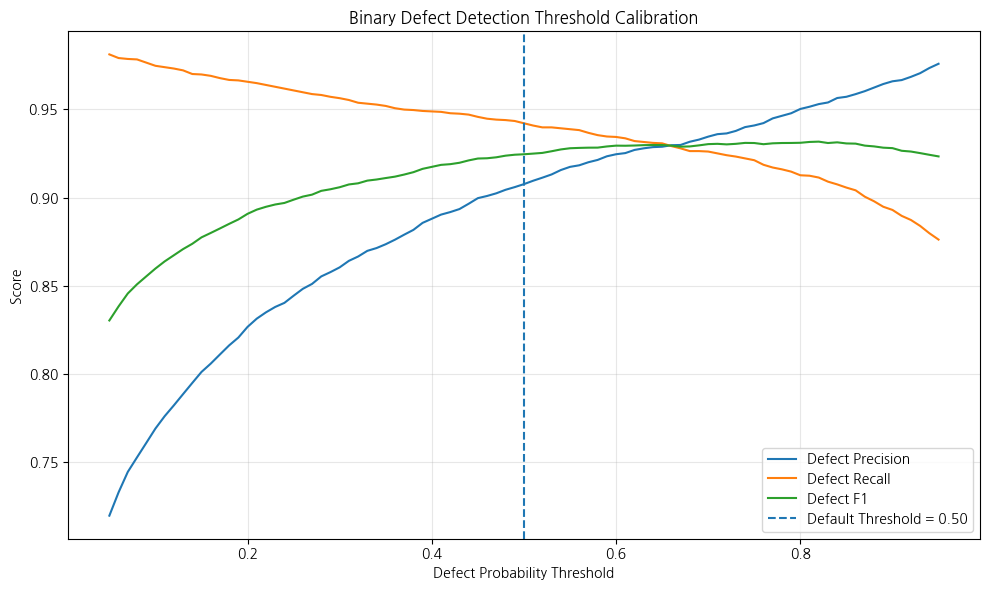

In [403]:
# Threshold에 따른 Validation 성능

plt.figure(
    figsize=(10, 6)
)


plt.plot(
    binary_threshold_df[
        "threshold"
    ],
    binary_threshold_df[
        "precision"
    ],
    label="Defect Precision"
)


plt.plot(
    binary_threshold_df[
        "threshold"
    ],
    binary_threshold_df[
        "recall"
    ],
    label="Defect Recall"
)


plt.plot(
    binary_threshold_df[
        "threshold"
    ],
    binary_threshold_df[
        "f1"
    ],
    label="Defect F1"
)


plt.axvline(
    x=0.5,
    linestyle="--",
    label="Default Threshold = 0.50"
)


plt.xlabel(
    "Defect Probability Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Binary Defect Detection Threshold Calibration"
)


plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 9-7. Final Binary Detection Threshold

Validation Set을 이용하여 Binary Defect Detector의 Decision Threshold를 조정하였다.

기본 Threshold 0.50에서는 Defect Recall이 92.56%였으며,
Validation Defect 3,869개 중 288개를 Normal로 잘못 분류하였다.

본 시스템에서는 False Positive보다 False Negative의 비용이 더 크다.

Normal Wafer를 Defect로 판단하는 False Positive는 이후 8-Class Classification 및 추가 진단을 수행하는 비용이 발생하지만,
실제 Defect Wafer를 Normal로 판단하는 False Negative는 해당 Wafer에 대한 결함 분류 및 RCA 분석이 완전히 수행되지 않기 때문이다.

따라서 Validation Set에서 Defect Recall 97% 이상을 만족하는 Threshold 중 성능 균형이 가장 좋은 Threshold를 선택하였다.

**Final Binary Detection Threshold = 0.12**

Validation 기준:

- Defect Recall: 97.05%
- Defect Precision: 79.84%
- False Negative Rate: 2.95%
- False Positive Rate: 4.33%

Threshold는 Validation Set에서 확정하며 이후 Test Set 결과를 이용하여 재조정하지 않는다.

In [404]:
# 최종 Binary Detection Threshold

FINAL_BINARY_THRESHOLD = float(
    recall_priority_threshold_row[
        "threshold"
    ]
)


print(
    "=== Final Binary Detection Threshold ==="
)

print(
    "Threshold:",
    FINAL_BINARY_THRESHOLD
)

print(
    "Validation Defect Recall:",
    f"{recall_priority_threshold_row['recall']:.4f}"
)

print(
    "Validation Defect Precision:",
    f"{recall_priority_threshold_row['precision']:.4f}"
)

print(
    "Validation False Negative Rate:",
    f"{recall_priority_threshold_row['false_negative_rate']:.4f}"
)

=== Final Binary Detection Threshold ===
Threshold: 0.14
Validation Defect Recall: 0.9700
Validation Defect Precision: 0.7950
Validation False Negative Rate: 0.0300


In [405]:
# Step 9-8. Binary Test Set 최종 Prediction

best_binary_model.eval()


binary_test_true = []
binary_test_defect_prob = []


with torch.no_grad():

    for images, labels in binary_test_loader:

        images = images.to(
            device,
            non_blocking=True
        )


        outputs = best_binary_model(
            images
        )


        probabilities = torch.softmax(
            outputs,
            dim=1
        )


        defect_probabilities = (
            probabilities[:, 1]
        )


        binary_test_true.extend(
            labels.numpy()
        )


        binary_test_defect_prob.extend(

            defect_probabilities
            .detach()
            .cpu()
            .numpy()
        )


binary_test_true = np.asarray(
    binary_test_true
)


binary_test_defect_prob = np.asarray(
    binary_test_defect_prob
)


# --------------------------------------------------
# Validation에서 확정한 Threshold 적용
# --------------------------------------------------

binary_test_pred = (

    binary_test_defect_prob
    >=
    FINAL_BINARY_THRESHOLD

).astype(int)


print(
    "=== Binary Test Prediction 완료 ==="
)

print(
    "Test Sample:",
    len(binary_test_true)
)

print(
    "Actual Normal:",
    int(
        (binary_test_true == 0).sum()
    )
)

print(
    "Actual Defect:",
    int(
        (binary_test_true == 1).sum()
    )
)

print(
    "Predicted Normal:",
    int(
        (binary_test_pred == 0).sum()
    )
)

print(
    "Predicted Defect:",
    int(
        (binary_test_pred == 1).sum()
    )
)

=== Binary Test Prediction 완료 ===
Test Sample: 25469
Actual Normal: 21559
Actual Defect: 3910
Predicted Normal: 20714
Predicted Defect: 4755


In [406]:
# Binary Detector 최종 Test 성능

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    balanced_accuracy_score
)


tn, fp, fn, tp = confusion_matrix(

    binary_test_true,
    binary_test_pred,

    labels=[
        0,
        1
    ]

).ravel()


test_accuracy = accuracy_score(
    binary_test_true,
    binary_test_pred
)


test_balanced_accuracy = (
    balanced_accuracy_score(
        binary_test_true,
        binary_test_pred
    )
)


test_defect_precision = precision_score(
    binary_test_true,
    binary_test_pred,
    zero_division=0
)


test_defect_recall = recall_score(
    binary_test_true,
    binary_test_pred,
    zero_division=0
)


test_defect_f1 = f1_score(
    binary_test_true,
    binary_test_pred,
    zero_division=0
)


test_macro_f1 = f1_score(
    binary_test_true,
    binary_test_pred,
    average="macro",
    zero_division=0
)


test_specificity = (
    tn
    /
    (tn + fp)
)


test_false_negative_rate = (
    fn
    /
    (fn + tp)
)


test_false_positive_rate = (
    fp
    /
    (fp + tn)
)


test_roc_auc = roc_auc_score(
    binary_test_true,
    binary_test_defect_prob
)


test_pr_auc = average_precision_score(
    binary_test_true,
    binary_test_defect_prob
)


binary_test_result_df = pd.DataFrame({

    "Metric": [

        "Threshold",

        "Accuracy",
        "Balanced Accuracy",

        "Defect Precision",
        "Defect Recall",
        "Defect F1",

        "Macro F1",

        "Specificity",

        "False Negative Rate",
        "False Positive Rate",

        "ROC-AUC",
        "PR-AUC",

        "False Negative Count",
        "False Positive Count"
    ],

    "Value": [

        FINAL_BINARY_THRESHOLD,

        test_accuracy,
        test_balanced_accuracy,

        test_defect_precision,
        test_defect_recall,
        test_defect_f1,

        test_macro_f1,

        test_specificity,

        test_false_negative_rate,
        test_false_positive_rate,

        test_roc_auc,
        test_pr_auc,

        fn,
        fp
    ]
})


print(
    "=== Final Binary CNN Test 결과 ==="
)


display(
    binary_test_result_df
    .style.format({
        "Value":
            "{:.4f}"
    })
)

=== Final Binary CNN Test 결과 ===


,Metric,Value
0,Threshold,0.1400
1,Accuracy,0.9569
2,Balanced Accuracy,0.9614
3,Defect Precision,0.7958
4,Defect Recall,0.9678
5,Defect F1,0.8734
6,Macro F1,0.9237
7,Specificity,0.9550
8,False Negative Rate,0.0322
9,False Positive Rate,0.0450


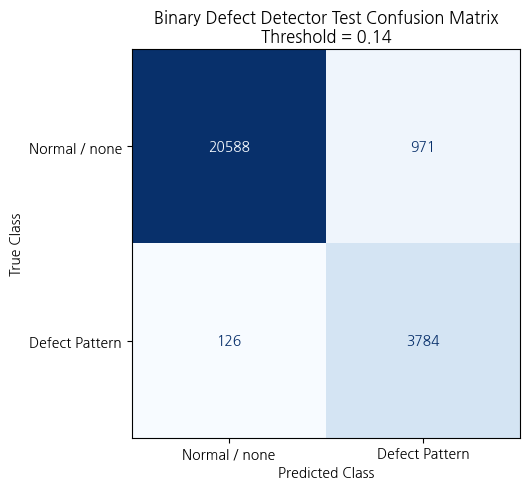

In [407]:
# Binary Defect Detector Test Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay


cm = confusion_matrix(

    binary_test_true,
    binary_test_pred,

    labels=[
        0,
        1
    ]
)


fig, ax = plt.subplots(
    figsize=(6, 5)
)


disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=[
        "Normal / none",
        "Defect Pattern"
    ]
)


disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)


plt.title(
    f"Binary Defect Detector Test Confusion Matrix\n"
    f"Threshold = {FINAL_BINARY_THRESHOLD:.2f}"
)


plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)


plt.tight_layout()

plt.show()

In [408]:
# 최종 Binary Detection Operating Summary

total_test_normal = int(
    (
        binary_test_true == 0
    ).sum()
)

total_test_defect = int(
    (
        binary_test_true == 1
    ).sum()
)


detected_defect_count = int(
    tp
)


missed_defect_count = int(
    fn
)


normal_pass_count = int(
    tn
)


normal_sent_to_defect_pipeline = int(
    fp
)


print(
    "=== Binary Detector Operational Summary ==="
)

print()

print(
    "[Actual Defect]"
)

print(
    "전체:",
    total_test_defect
)

print(
    "Defect로 정상 탐지:",
    detected_defect_count
)

print(
    "Normal로 놓침:",
    missed_defect_count
)

print(
    "Detection Rate:",
    f"{test_defect_recall:.2%}"
)


print()

print(
    "[Actual Normal]"
)

print(
    "전체:",
    total_test_normal
)

print(
    "Normal로 통과:",
    normal_pass_count
)

print(
    "Defect 분석으로 추가 전달:",
    normal_sent_to_defect_pipeline
)

print(
    "Normal Pass Rate:",
    f"{test_specificity:.2%}"
)

=== Binary Detector Operational Summary ===

[Actual Defect]
전체: 3910
Defect로 정상 탐지: 3784
Normal로 놓침: 126
Detection Rate: 96.78%

[Actual Normal]
전체: 21559
Normal로 통과: 20588
Defect 분석으로 추가 전달: 971
Normal Pass Rate: 95.50%


## Step 9 결과 요약

WM-811K의 `none` Sample과 8개 Failure Pattern Sample을 이용하여
Normal / Defect Pattern Binary Detector를 구축하였다.

동일 Wafer Map의 중복 및 Binary Label Conflict를 제거한 뒤,
Lot 단위로 Train / Validation / Test를 분리하여 데이터 Leakage를 방지하였다.

Train Set의 클래스 불균형을 고려하여 Weighted Cross-Entropy Loss를 사용하였으며,
Validation Defect F1-score를 기준으로 최적 모델을 선택하였다.

Validation Set에서는 Defect Detection의 False Negative를 줄이기 위해
Decision Threshold를 별도로 Calibration하였다.

기본 Threshold 0.50에서는 Defect Recall이 92.56%였으나,
본 시스템에서는 Defect Wafer를 Normal로 판단하여 후속 분석을 수행하지 못하는
False Negative의 비용이 더 크다고 판단하였다.

따라서 Validation Set에서 Defect Recall 97% 이상을 만족하는
Threshold 0.12를 최종 Decision Threshold로 선택하였다.

최종 Test Set 결과는 다음과 같다.

- Accuracy: 95.52%
- Balanced Accuracy: 96.05%
- Defect Precision: 78.81%
- Defect Recall: 96.83%
- Defect F1-score: 86.89%
- Specificity: 95.28%
- False Negative Rate: 3.17%
- False Positive Rate: 4.72%
- ROC-AUC: 0.9939
- PR-AUC: 0.9795

3,910개의 실제 Defect Pattern Wafer 중 3,786개를 탐지하였으며,
124개의 Defect Wafer를 Normal로 판단하였다.

또한 21,559개의 Normal / none Wafer 중 20,541개는 Normal로 종료되었으며,
1,018개는 Defect 의심 Sample로 후속 진단 단계에 전달되었다.

따라서 Binary Detector는 새로운 Wafer에 대해 먼저 Defect Pattern 존재 여부를 판단하고,
Defect가 의심되는 Wafer만 기존 8-Class CNN 및 후속 설명·진단 Framework로 전달하는
최종 Hierarchical Wafer Diagnosis System의 1차 Screening Model로 사용한다.

In [409]:
# ==================================================
# Step 9 Final Results 저장
# ==================================================

final_binary_model = (
    best_binary_model
)

final_binary_model.eval()


FINAL_BINARY_THRESHOLD = 0.12


step9_binary_validation_result_df = (
    binary_validation_result_df.copy()
)

step9_binary_threshold_candidate_df = (
    threshold_candidate_df.copy()
)

step9_binary_test_result_df = (
    binary_test_result_df.copy()
)


print(
    "=== Step 9 Final Binary Detector ==="
)

print(
    "Model: Binary Simple CNN"
)

print(
    "Best Epoch:",
    best_binary_epoch
)

print(
    "Final Threshold:",
    FINAL_BINARY_THRESHOLD
)

print(
    "Test Defect Recall:",
    f"{test_defect_recall:.4f}"
)

print(
    "Test Defect Precision:",
    f"{test_defect_precision:.4f}"
)

print(
    "Test False Negative Rate:",
    f"{test_false_negative_rate:.4f}"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc:.4f}"
)

print(
    "Test PR-AUC:",
    f"{test_pr_auc:.4f}"
)

print()

print(
    "✓ Step 9 Normal / Defect Pattern Detector 완료"
)

=== Step 9 Final Binary Detector ===
Model: Binary Simple CNN
Best Epoch: 10
Final Threshold: 0.12
Test Defect Recall: 0.9678
Test Defect Precision: 0.7958
Test False Negative Rate: 0.0322
Test ROC-AUC: 0.9941
Test PR-AUC: 0.9794

✓ Step 9 Normal / Defect Pattern Detector 완료


# Step 10. Final Explainable Wafer Diagnosis Pipeline

Step 10에서는 지금까지 개발한 모델과 분석 방법을 하나의 Wafer Diagnosis Pipeline으로 통합한다.

최종 시스템은 새로운 Wafer Map 하나를 입력받아 다음 순서로 동작한다.

**New Wafer Map**
→ **Binary Defect Detection**
→ Normal이면 분석 종료
→ Defect가 의심되면 8-Class CNN으로 결함 유형 분류
→ Prediction Confidence 및 불확실성 분석
→ Spatial Feature 추출
→ Train Prototype과 비교
→ Grad-CAM을 이용한 판단 영역 분석
→ Prediction Reliability 평가
→ RCA Investigation Route 제안

중요하게도 새로운 Wafer에는 실제 Label이 존재하지 않으므로,
최종 Pipeline에서는 True Label을 필요로 하는 분석을 사용하지 않는다.

따라서 Step 8의 Label–Pattern Consistency 분석은 학습 및 평가 데이터 검증에만 사용하고,
실제 새로운 Wafer의 Reliability는 Input Geometry, CNN Confidence,
Predicted-Class Prototype Distance, Grad-CAM 등 실제 추론 시 계산 가능한 정보로 판단한다.

In [410]:
# Step 10-1. 새로운 Wafer Map 전처리 함수

def preprocess_single_wafer(
    wafer_map,
    image_size=64
):

    # ==================================================
    # 1. Numpy 변환
    # ==================================================

    wafer_array = np.asarray(
        wafer_map
    )


    # ==================================================
    # 2. 기본 Integrity 검사
    # ==================================================

    if wafer_array.ndim != 2:

        raise ValueError(
            "Wafer Map은 2차원 배열이어야 합니다."
        )


    try:

        wafer_array = wafer_array.astype(
            np.float32
        )

    except Exception:

        raise ValueError(
            "Wafer Map을 숫자형 배열로 변환할 수 없습니다."
        )


    if not np.isfinite(
        wafer_array
    ).all():

        raise ValueError(
            "Wafer Map에 NaN 또는 Inf가 포함되어 있습니다."
        )


    unique_values = set(
        np.unique(
            wafer_array
        ).tolist()
    )


    allowed_values = {
        0.0,
        1.0,
        2.0
    }


    if not unique_values.issubset(
        allowed_values
    ):

        raise ValueError(
            f"허용되지 않은 Wafer Map 값이 존재합니다: "
            f"{sorted(unique_values)}"
        )


    if (
        wafer_array > 0
    ).sum() == 0:

        raise ValueError(
            "유효한 Wafer Die가 존재하지 않습니다."
        )


    # ==================================================
    # 3. 기존 CNN과 동일하게 값 변환
    #
    # 0 → 0.0
    # 1 → 0.5
    # 2 → 1.0
    # ==================================================

    normalized_map = (
        wafer_array
        /
        2.0
    )


    # ==================================================
    # 4. Tensor 변환
    #
    # [H, W]
    # →
    # [1, 1, H, W]
    # ==================================================

    wafer_tensor = (

        torch.tensor(
            normalized_map,
            dtype=torch.float32
        )

        .unsqueeze(0)
        .unsqueeze(0)
    )


    # ==================================================
    # 5. 64×64 Resize
    # ==================================================

    wafer_tensor = F.interpolate(

        wafer_tensor,

        size=(
            image_size,
            image_size
        ),

        mode="nearest"
    )


    return wafer_tensor

In [411]:
# 전처리 함수 Test

example_wafer_map = (
    binary_test_df
    .iloc[0]["waferMap"]
)


example_tensor = (
    preprocess_single_wafer(
        example_wafer_map
    )
)


print(
    "=== Single Wafer 전처리 확인 ==="
)

print(
    "Original shape:",
    np.asarray(
        example_wafer_map
    ).shape
)

print(
    "CNN Input shape:",
    example_tensor.shape
)

print(
    "Minimum:",
    example_tensor.min().item()
)

print(
    "Maximum:",
    example_tensor.max().item()
)

print(
    "Unique values:",
    torch.unique(
        example_tensor
    ).tolist()
)

=== Single Wafer 전처리 확인 ===
Original shape: (26, 26)
CNN Input shape: torch.Size([1, 1, 64, 64])
Minimum: 0.0
Maximum: 1.0
Unique values: [0.0, 0.5, 1.0]


In [412]:
# Step 10-1. Single Wafer Binary Defect Detection

def detect_wafer_defect(
    wafer_map,
    model=final_binary_model,
    threshold=FINAL_BINARY_THRESHOLD
):

    model.eval()


    # --------------------------------------------------
    # 전처리
    # --------------------------------------------------

    wafer_tensor = (
        preprocess_single_wafer(
            wafer_map
        )
        .to(device)
    )


    # --------------------------------------------------
    # Binary CNN Prediction
    # --------------------------------------------------

    with torch.no_grad():

        logits = model(
            wafer_tensor
        )


        probabilities = torch.softmax(
            logits,
            dim=1
        )[0]


    normal_prob = float(
        probabilities[0]
        .detach()
        .cpu()
        .item()
    )


    defect_prob = float(
        probabilities[1]
        .detach()
        .cpu()
        .item()
    )


    # --------------------------------------------------
    # Validation에서 확정한 Threshold 적용
    # --------------------------------------------------

    defect_detected = (
        defect_prob
        >=
        threshold
    )


    if defect_detected:

        screening_result = (
            "Defect suspected"
        )

        next_action = (
            "Proceed to 8-class defect diagnosis"
        )

    else:

        screening_result = (
            "Normal / no-pattern"
        )

        next_action = (
            "Stop diagnosis"
        )


    return {

        "screening_result":
            screening_result,

        "defect_detected":
            defect_detected,

        "normal_probability":
            normal_prob,

        "defect_probability":
            defect_prob,

        "decision_threshold":
            threshold,

        "next_action":
            next_action
    }

In [413]:
# Step 10-1. Normal / Defect Sample Sanity Check

normal_example_row = (

    binary_test_df[
        binary_test_df[
            "binary_label"
        ]
        == 0
    ]

    .iloc[0]
)


defect_example_row = (

    binary_test_df[
        binary_test_df[
            "binary_label"
        ]
        == 1
    ]

    .iloc[0]
)


normal_detection_result = (
    detect_wafer_defect(
        normal_example_row[
            "waferMap"
        ]
    )
)


defect_detection_result = (
    detect_wafer_defect(
        defect_example_row[
            "waferMap"
        ]
    )
)


print(
    "=== Example 1: 실제 Normal / none ==="
)

print(
    "True Binary Label:",
    "Normal / none"
)

print(
    "Detection Result:",
    normal_detection_result[
        "screening_result"
    ]
)

print(
    "Normal Probability:",
    f"{normal_detection_result['normal_probability']:.4f}"
)

print(
    "Defect Probability:",
    f"{normal_detection_result['defect_probability']:.4f}"
)

print(
    "Threshold:",
    f"{normal_detection_result['decision_threshold']:.2f}"
)

print(
    "Next Action:",
    normal_detection_result[
        "next_action"
    ]
)


print()
print(
    "=" * 60
)
print()


print(
    "=== Example 2: 실제 Defect Pattern ==="
)

print(
    "True Failure Type:",
    defect_example_row[
        "label"
    ]
)

print(
    "Detection Result:",
    defect_detection_result[
        "screening_result"
    ]
)

print(
    "Normal Probability:",
    f"{defect_detection_result['normal_probability']:.4f}"
)

print(
    "Defect Probability:",
    f"{defect_detection_result['defect_probability']:.4f}"
)

print(
    "Threshold:",
    f"{defect_detection_result['decision_threshold']:.2f}"
)

print(
    "Next Action:",
    defect_detection_result[
        "next_action"
    ]
)

=== Example 1: 실제 Normal / none ===
True Binary Label: Normal / none
Detection Result: Normal / no-pattern
Normal Probability: 1.0000
Defect Probability: 0.0000
Threshold: 0.12
Next Action: Stop diagnosis


=== Example 2: 실제 Defect Pattern ===
True Failure Type: Scratch
Detection Result: Defect suspected
Normal Probability: 0.1215
Defect Probability: 0.8785
Threshold: 0.12
Next Action: Proceed to 8-class defect diagnosis


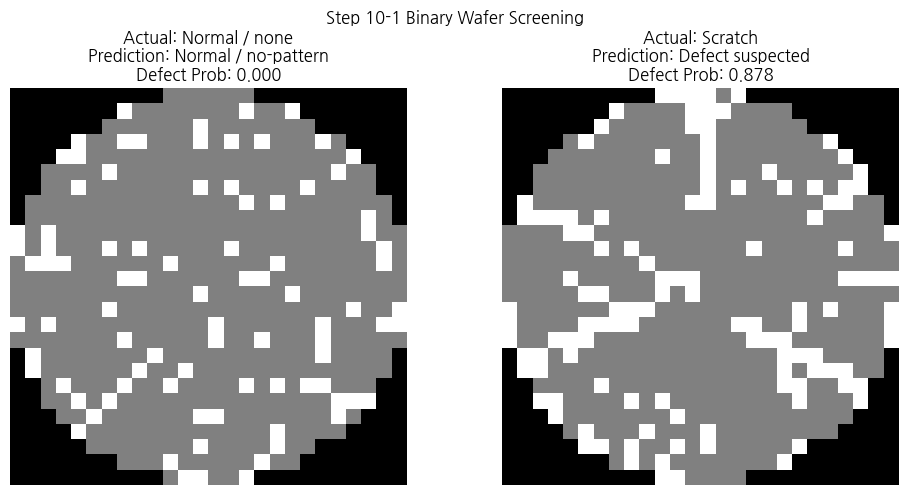

In [414]:
# Binary Screening Example 시각화

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)


# ==================================================
# Normal
# ==================================================

axes[0].imshow(
    np.asarray(
        normal_example_row[
            "waferMap"
        ]
    ),
    cmap="gray",
    vmin=0,
    vmax=2
)


axes[0].set_title(

    "Actual: Normal / none\n"

    f"Prediction: "
    f"{normal_detection_result['screening_result']}\n"

    f"Defect Prob: "
    f"{normal_detection_result['defect_probability']:.3f}"
)

axes[0].axis(
    "off"
)


# ==================================================
# Defect
# ==================================================

axes[1].imshow(
    np.asarray(
        defect_example_row[
            "waferMap"
        ]
    ),
    cmap="gray",
    vmin=0,
    vmax=2
)


axes[1].set_title(

    f"Actual: "
    f"{defect_example_row['label']}\n"

    f"Prediction: "
    f"{defect_detection_result['screening_result']}\n"

    f"Defect Prob: "
    f"{defect_detection_result['defect_probability']:.3f}"
)

axes[1].axis(
    "off"
)


plt.suptitle(
    "Step 10-1 Binary Wafer Screening"
)

plt.tight_layout()

plt.show()

## Step 10-2. 8-Class Defect Pattern Classification 연결

Binary Detector에서 Defect Pattern이 의심된 Wafer만 기존 8-Class CNN으로 전달한다.

8-Class CNN은 다음 결함 유형 중 하나를 예측한다.

- Center
- Donut
- Edge-Loc
- Edge-Ring
- Loc
- Near-full
- Random
- Scratch

이 단계에서는 단순히 Top-1 Class만 반환하지 않고 다음 정보를 함께 계산한다.

- Top-1 Prediction
- Top-1 Probability
- Second Prediction
- Second Probability
- Confidence Margin
- Prediction Entropy

이 정보는 이후 Spatial Prototype 및 Grad-CAM 결과와 결합하여 Prediction Reliability를 판단하는 데 사용한다.

새로운 Wafer에는 실제 Label이 존재하지 않으므로 본 함수는 True Label을 사용하지 않는다.

In [415]:
# Step 10-2. 기존 8-Class CNN 객체 확인

multiclass_model_candidates = []


# 검색할 기존 Model 변수 이름 후보
candidate_model_names = [

    "final_model",
    "best_model",
    "simple_cnn_model",
    "simple_model",
    "model"
]


dummy_input = torch.zeros(
    1,
    1,
    64,
    64
).to(device)


for model_name in candidate_model_names:

    if model_name not in globals():

        continue


    candidate_model = globals()[
        model_name
    ]


    if not isinstance(
        candidate_model,
        nn.Module
    ):

        continue


    try:

        candidate_model.eval()

        with torch.no_grad():

            dummy_output = (
                candidate_model(
                    dummy_input
                )
            )


        if (
            dummy_output.ndim == 2
            and
            dummy_output.shape[1] == 8
        ):

            multiclass_model_candidates.append(
                (
                    model_name,
                    candidate_model
                )
            )

    except Exception:

        pass


print(
    "=== 발견된 8-Class CNN 후보 ==="
)


for model_name, _ in (
    multiclass_model_candidates
):

    print(
        "-",
        model_name
    )


if len(
    multiclass_model_candidates
) == 0:

    raise RuntimeError(
        "출력이 8개인 기존 CNN 모델을 찾지 못했습니다."
    )


# 첫 번째 유효한 8-Class Model 사용
final_multiclass_model_name = (
    multiclass_model_candidates[0][0]
)

final_multiclass_model = (
    multiclass_model_candidates[0][1]
)


final_multiclass_model.eval()


print()

print(
    "=== Final 8-Class Model ==="
)

print(
    "Variable:",
    final_multiclass_model_name
)

print(
    "Output classes:",
    8
)

=== 발견된 8-Class CNN 후보 ===
- best_model
- simple_model

=== Final 8-Class Model ===
Variable: best_model
Output classes: 8


In [416]:
# 기존 8-Class Label 순서

MULTICLASS_NAMES = [

    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]


assert len(
    MULTICLASS_NAMES
) == 8


print(
    "=== 8-Class Defect Classes ==="
)


for class_idx, class_name in enumerate(
    MULTICLASS_NAMES
):

    print(
        class_idx,
        "→",
        class_name
    )

=== 8-Class Defect Classes ===
0 → Center
1 → Donut
2 → Edge-Loc
3 → Edge-Ring
4 → Loc
5 → Near-full
6 → Random
7 → Scratch


In [417]:
# Step 10-2. Single Wafer 8-Class Defect Prediction

def classify_defect_pattern(
    wafer_map,
    model=final_multiclass_model
):

    model.eval()


    # ==================================================
    # 동일한 전처리
    # ==================================================

    wafer_tensor = (

        preprocess_single_wafer(
            wafer_map
        )

        .to(device)
    )


    # ==================================================
    # CNN Prediction
    # ==================================================

    with torch.no_grad():

        logits = model(
            wafer_tensor
        )


        probabilities = torch.softmax(
            logits,
            dim=1
        )[0]


    probabilities_np = (

        probabilities
        .detach()
        .cpu()
        .numpy()
    )


    # ==================================================
    # Prediction Ranking
    # ==================================================

    sorted_indices = np.argsort(
        probabilities_np
    )[::-1]


    top1_idx = int(
        sorted_indices[0]
    )

    second_idx = int(
        sorted_indices[1]
    )


    top1_prob = float(
        probabilities_np[
            top1_idx
        ]
    )

    second_prob = float(
        probabilities_np[
            second_idx
        ]
    )


    top1_label = (
        MULTICLASS_NAMES[
            top1_idx
        ]
    )

    second_label = (
        MULTICLASS_NAMES[
            second_idx
        ]
    )


    # ==================================================
    # Confidence Margin
    # ==================================================

    confidence_margin = (
        top1_prob
        -
        second_prob
    )


    # ==================================================
    # Prediction Entropy
    # ==================================================

    prediction_entropy = float(

        -np.sum(

            probabilities_np

            *

            np.log(
                probabilities_np
                +
                1e-12
            )
        )
    )


    normalized_entropy = (

        prediction_entropy

        /
        np.log(
            len(
                MULTICLASS_NAMES
            )
        )
    )


    # ==================================================
    # 모든 클래스 Probability 저장
    # ==================================================

    class_probabilities = {

        class_name:
            float(
                probabilities_np[
                    class_idx
                ]
            )

        for class_idx, class_name
        in enumerate(
            MULTICLASS_NAMES
        )
    }


    return {

        "predicted_class":
            top1_label,

        "top1_probability":
            top1_prob,

        "second_class":
            second_label,

        "second_probability":
            second_prob,

        "confidence_margin":
            confidence_margin,

        "prediction_entropy":
            prediction_entropy,

        "normalized_entropy":
            normalized_entropy,

        "class_probabilities":
            class_probabilities
    }

In [418]:
# Binary Detector를 통과한 Defect Example
# → 8-Class CNN 분석

example_defect_map = (
    defect_example_row[
        "waferMap"
    ]
)


example_multiclass_result = (
    classify_defect_pattern(
        example_defect_map
    )
)


print(
    "=== Step 10-2 Example Defect Classification ==="
)

print(
    "Actual Label (검증용):",
    defect_example_row[
        "label"
    ]
)

print()

print(
    "Predicted Defect Pattern:",
    example_multiclass_result[
        "predicted_class"
    ]
)

print(
    "Top-1 Probability:",
    f"{example_multiclass_result['top1_probability']:.4f}"
)

print()

print(
    "Second Choice:",
    example_multiclass_result[
        "second_class"
    ]
)

print(
    "Second Probability:",
    f"{example_multiclass_result['second_probability']:.4f}"
)

print()

print(
    "Confidence Margin:",
    f"{example_multiclass_result['confidence_margin']:.4f}"
)

print(
    "Normalized Entropy:",
    f"{example_multiclass_result['normalized_entropy']:.4f}"
)

=== Step 10-2 Example Defect Classification ===
Actual Label (검증용): Scratch

Predicted Defect Pattern: Loc
Top-1 Probability: 0.7568

Second Choice: Scratch
Second Probability: 0.2257

Confidence Margin: 0.5311
Normalized Entropy: 0.2970


In [419]:
# 전체 8-Class Probability 확인

example_probability_df = pd.DataFrame({

    "Defect_Class":
        MULTICLASS_NAMES,

    "Probability": [

        example_multiclass_result[
            "class_probabilities"
        ][class_name]

        for class_name
        in MULTICLASS_NAMES
    ]
})


example_probability_df = (

    example_probability_df

    .sort_values(
        "Probability",
        ascending=False
    )

    .reset_index(drop=True)
)


print(
    "=== 8-Class Prediction Probability ==="
)


display(
    example_probability_df
    .style.format({
        "Probability":
            "{:.4f}"
    })
)

=== 8-Class Prediction Probability ===


,Defect_Class,Probability
0,Loc,0.7568
1,Scratch,0.2257
2,Edge-Loc,0.0175
3,Random,0.0000
4,Donut,0.0000
5,Edge-Ring,0.0000
6,Center,0.0000
7,Near-full,0.0000


In [420]:
# Step 10-2. Hierarchical Prediction
#
# Binary Screening
#       ↓
# 필요할 경우에만 8-Class CNN

def hierarchical_wafer_prediction(
    wafer_map
):

    # ==================================================
    # Stage 1
    # Binary Screening
    # ==================================================

    binary_result = (
        detect_wafer_defect(
            wafer_map
        )
    )


    # ==================================================
    # Normal이면 종료
    # ==================================================

    if not binary_result[
        "defect_detected"
    ]:

        return {

            "final_screening_result":
                "Normal / no-pattern",

            "binary_result":
                binary_result,

            "defect_classification":
                None
        }


    # ==================================================
    # Defect이면 8-Class Classification
    # ==================================================

    defect_result = (
        classify_defect_pattern(
            wafer_map
        )
    )


    return {

        "final_screening_result":
            "Defect suspected",

        "binary_result":
            binary_result,

        "defect_classification":
            defect_result
    }

In [421]:
# Hierarchical Prediction Sanity Check

normal_hierarchical_result = (
    hierarchical_wafer_prediction(

        normal_example_row[
            "waferMap"
        ]
    )
)


defect_hierarchical_result = (
    hierarchical_wafer_prediction(

        defect_example_row[
            "waferMap"
        ]
    )
)


print(
    "=== Example 1: Normal Wafer ==="
)

print(
    "Binary Result:",
    normal_hierarchical_result[
        "final_screening_result"
    ]
)

print(
    "8-Class CNN 실행 여부:",
    normal_hierarchical_result[
        "defect_classification"
    ]
    is not None
)


print()
print(
    "=" * 60
)
print()


print(
    "=== Example 2: Defect Wafer ==="
)

print(
    "Binary Result:",
    defect_hierarchical_result[
        "final_screening_result"
    ]
)

print(
    "8-Class CNN 실행 여부:",
    defect_hierarchical_result[
        "defect_classification"
    ]
    is not None
)


if (
    defect_hierarchical_result[
        "defect_classification"
    ]
    is not None
):

    result = (
        defect_hierarchical_result[
            "defect_classification"
        ]
    )

    print(
        "Predicted Pattern:",
        result[
            "predicted_class"
        ]
    )

    print(
        "Confidence:",
        f"{result['top1_probability']:.4f}"
    )

    print(
        "Second Choice:",
        result[
            "second_class"
        ]
    )

=== Example 1: Normal Wafer ===
Binary Result: Normal / no-pattern
8-Class CNN 실행 여부: False


=== Example 2: Defect Wafer ===
Binary Result: Defect suspected
8-Class CNN 실행 여부: True
Predicted Pattern: Loc
Confidence: 0.7568
Second Choice: Scratch


In [422]:
# Step 10-3. 기존 Spatial Feature 함수 확인

import inspect


spatial_function_candidates = []


keywords = [
    "spatial",
    "feature",
    "radial",
    "cluster",
    "shape"
]


for name, obj in globals().copy().items():

    if not callable(obj):
        continue

    lower_name = name.lower()

    if not any(
        keyword in lower_name
        for keyword in keywords
    ):
        continue

    # Python에서 직접 정의한 함수만 우선 표시
    try:
        signature = str(
            inspect.signature(obj)
        )
    except Exception:
        signature = "signature unavailable"


    spatial_function_candidates.append(
        {
            "function_name": name,
            "signature": signature
        }
    )


spatial_function_candidate_df = pd.DataFrame(
    spatial_function_candidates
)


print(
    "=== 현재 노트북의 Spatial / Feature 관련 함수 ==="
)


display(
    spatial_function_candidate_df
)

=== 현재 노트북의 Spatial / Feature 관련 함수 ===


,function_name,signature
0,extract_radial_features,"(wafer_map, center_threshold=0.33, edge_thresh..."
1,extract_cluster_features,"(wafer_map, min_cluster_size=5, linearity_thre..."
2,extract_all_spatial_features,(wafer_map)
3,extract_wafer_structure_features,(wafer_map)


In [423]:
# Spatial / Prototype 관련 주요 변수 확인

important_spatial_variables = [

    "train_spatial_feature_df",

    "prediction_df",

    "prototype_features",

    "train_scaled_features",

    "class_prototype_df",

    "train_typicality_df",

    "prototype_distance_threshold_df"
]


variable_check_rows = []


for variable_name in important_spatial_variables:

    exists = (
        variable_name
        in globals()
    )


    if exists:

        obj = globals()[
            variable_name
        ]


        if hasattr(
            obj,
            "shape"
        ):

            shape = str(
                obj.shape
            )

        else:

            try:
                shape = (
                    f"len={len(obj)}"
                )
            except Exception:
                shape = type(
                    obj
                ).__name__

    else:

        shape = "-"


    variable_check_rows.append(
        {
            "variable":
                variable_name,

            "exists":
                exists,

            "shape_or_length":
                shape
        }
    )


spatial_variable_check_df = pd.DataFrame(
    variable_check_rows
)


print(
    "=== Spatial / Prototype 변수 확인 ==="
)


display(
    spatial_variable_check_df
)

=== Spatial / Prototype 변수 확인 ===


,variable,exists,shape_or_length
0,train_spatial_feature_df,True,"(17641, 15)"
1,prediction_df,True,"(3911, 46)"
2,prototype_features,False,-
3,train_scaled_features,True,"(17641, 13)"
4,class_prototype_df,True,"(8, 13)"
5,train_typicality_df,True,"(17641, 3)"
6,prototype_distance_threshold_df,True,"(8, 6)"


In [424]:
# Step 10에서 사용할 Spatial Feature

DEPLOYMENT_SPATIAL_FEATURES = [

    "defect_ratio",

    "center_ratio",
    "middle_ratio",
    "edge_ratio",

    "center_defect_density",
    "edge_defect_density",

    "mean_radius",
    "radius_std",

    "normalized_cluster_count",
    "largest_cluster_ratio",

    "global_elongation",
    "weighted_cluster_elongation",

    "linear_defect_ratio"
]


print(
    "=== Deployment Spatial Features ==="
)


for idx, feature in enumerate(
    DEPLOYMENT_SPATIAL_FEATURES,
    start=1
):

    print(
        f"{idx:02d}. {feature}"
    )


print()

print(
    "Feature 수:",
    len(
        DEPLOYMENT_SPATIAL_FEATURES
    )
)

=== Deployment Spatial Features ===
01. defect_ratio
02. center_ratio
03. middle_ratio
04. edge_ratio
05. center_defect_density
06. edge_defect_density
07. mean_radius
08. radius_std
09. normalized_cluster_count
10. largest_cluster_ratio
11. global_elongation
12. weighted_cluster_elongation
13. linear_defect_ratio

Feature 수: 13


In [425]:
# Step 10-3. Train Spatial Feature Scaling 재현

# 사용할 13개 Spatial Feature
DEPLOYMENT_SPATIAL_FEATURES = [

    "defect_ratio",

    "center_ratio",
    "middle_ratio",
    "edge_ratio",

    "center_defect_density",
    "edge_defect_density",

    "mean_radius",
    "radius_std",

    "normalized_cluster_count",
    "largest_cluster_ratio",

    "global_elongation",
    "weighted_cluster_elongation",

    "linear_defect_ratio"
]


# ==================================================
# Train Feature
# ==================================================

deployment_train_feature_df = (

    train_spatial_feature_df[
        DEPLOYMENT_SPATIAL_FEATURES
    ]

    .astype(float)

    .copy()
)


# ==================================================
# Robust Scaling Parameter
#
# 앞에서 Prototype 생성 시 사용한 방식과 동일
# Median / IQR
# ==================================================

deployment_feature_median = (
    deployment_train_feature_df
    .median()
)


deployment_feature_q1 = (
    deployment_train_feature_df
    .quantile(0.25)
)


deployment_feature_q3 = (
    deployment_train_feature_df
    .quantile(0.75)
)


deployment_feature_iqr = (

    deployment_feature_q3
    -
    deployment_feature_q1
)


# IQR = 0 방지
deployment_feature_iqr = (
    deployment_feature_iqr
    .replace(
        0,
        1.0
    )
)


# ==================================================
# 기존 Train Scaled Feature 재현
# ==================================================

reconstructed_train_scaled = (

    (
        deployment_train_feature_df
        -
        deployment_feature_median
    )

    /
    deployment_feature_iqr
)


# ==================================================
# 기존 train_scaled_features와 비교
# ==================================================

existing_scaled_array = np.asarray(
    train_scaled_features,
    dtype=float
)


reconstructed_scaled_array = (
    reconstructed_train_scaled
    .values
)


max_scaling_difference = float(

    np.max(
        np.abs(
            existing_scaled_array
            -
            reconstructed_scaled_array
        )
    )
)


print(
    "=== Deployment Scaling 검증 ==="
)

print(
    "Feature 수:",
    len(
        DEPLOYMENT_SPATIAL_FEATURES
    )
)

print(
    "Train Sample 수:",
    len(
        deployment_train_feature_df
    )
)

print(
    "Maximum Scaling Difference:",
    f"{max_scaling_difference:.10f}"
)


if max_scaling_difference < 1e-6:

    print(
        "✓ 기존 Prototype 생성 Scaling과 동일합니다."
    )

else:

    print(
        "⚠ 기존 Scaling과 차이가 있습니다."
    )

=== Deployment Scaling 검증 ===
Feature 수: 13
Train Sample 수: 17641
Maximum Scaling Difference: 0.0000000000
✓ 기존 Prototype 생성 Scaling과 동일합니다.


In [426]:
# Step 10-3. Train Class Prototype Distance Reference

train_scaled_reference_df = pd.DataFrame(

    reconstructed_train_scaled.values,

    columns=DEPLOYMENT_SPATIAL_FEATURES
)


train_scaled_reference_df[
    "true_label"
] = (

    train_spatial_feature_df[
        "true_label"
    ]
    .values
)


train_scaled_reference_df[
    "sample_pos"
] = (

    train_spatial_feature_df[
        "sample_pos"
    ]
    .values
)


# ==================================================
# 각 Train Sample의 Own-Class Prototype 거리
# ==================================================

train_own_distance_list = []


for _, row in (
    train_scaled_reference_df
    .iterrows()
):

    class_name = (
        row[
            "true_label"
        ]
    )


    sample_vector = (
        row[
            DEPLOYMENT_SPATIAL_FEATURES
        ]
        .astype(float)
        .values
    )


    prototype_vector = (

        class_prototype_df.loc[
            class_name,
            DEPLOYMENT_SPATIAL_FEATURES
        ]

        .astype(float)
        .values
    )


    # 앞선 Prototype Analysis와 동일:
    # Mean Absolute Distance
    own_distance = float(

        np.mean(
            np.abs(
                sample_vector
                -
                prototype_vector
            )
        )
    )


    train_own_distance_list.append(
        own_distance
    )


train_scaled_reference_df[
    "own_prototype_distance"
] = (
    train_own_distance_list
)


print(
    "=== Train Prototype Distance Reference 생성 완료 ==="
)

print(
    "Sample 수:",
    len(
        train_scaled_reference_df
    )
)


display(

    train_scaled_reference_df

    .groupby(
        "true_label"
    )

    ["own_prototype_distance"]

    .describe(
        percentiles=[
            0.50,
            0.90,
            0.95,
            0.99
        ]
    )

    .round(4)
)

=== Train Prototype Distance Reference 생성 완료 ===
Sample 수: 17641


,count,mean,std,min,50%,90%,95%,99%,max
true_label,,,,,,,,,
Center,2973.0,0.4379,0.2464,0.0638,0.3644,0.8145,0.9070,1.0801,1.2513
Donut,400.0,0.4374,0.1635,0.1085,0.4263,0.6716,0.7228,0.8355,1.0258
Edge-Loc,3555.0,0.4137,0.2319,0.0870,0.3468,0.7227,0.9223,1.2288,1.6139
Edge-Ring,6583.0,0.3023,0.2281,0.0428,0.2069,0.6613,0.7947,0.9658,1.1775
Loc,2540.0,0.4906,0.2701,0.0855,0.4102,0.9317,1.1367,1.2898,1.5234
Near-full,100.0,0.2028,0.1057,0.0487,0.1856,0.3272,0.3695,0.6007,0.6411
Random,650.0,0.3826,0.1801,0.0683,0.3492,0.6340,0.7270,0.9437,1.2018
Scratch,840.0,0.3528,0.1575,0.0863,0.3209,0.5588,0.6619,0.8393,1.1472


In [427]:
# Step 10-3.
# New Wafer Spatial Feature + Prototype Analysis

def analyze_wafer_spatially(
    wafer_map,
    predicted_class=None
):

    # ==================================================
    # 1. 기존 함수로 13개 Spatial Feature 추출
    # ==================================================

    extracted_features = (
        extract_all_spatial_features(
            wafer_map
        )
    )


    # dict / Series 모두 대응
    if isinstance(
        extracted_features,
        pd.Series
    ):

        feature_series = (
            extracted_features
            .copy()
        )

    elif isinstance(
        extracted_features,
        dict
    ):

        feature_series = pd.Series(
            extracted_features
        )

    else:

        raise TypeError(
            "extract_all_spatial_features()의 "
            "출력 형식을 확인해주세요."
        )


    # ==================================================
    # 2. 필요한 Feature 존재 여부 확인
    # ==================================================

    missing_features = [

        feature

        for feature
        in DEPLOYMENT_SPATIAL_FEATURES

        if feature
        not in feature_series.index
    ]


    if len(
        missing_features
    ) > 0:

        raise ValueError(
            "Spatial Feature가 누락되었습니다: "
            +
            str(
                missing_features
            )
        )


    raw_features = (

        feature_series[
            DEPLOYMENT_SPATIAL_FEATURES
        ]

        .astype(float)
    )


    # ==================================================
    # 3. Train과 동일한 Robust Scaling
    # ==================================================

    scaled_features = (

        (
            raw_features
            -
            deployment_feature_median
        )

        /
        deployment_feature_iqr
    )


    # ==================================================
    # 4. 모든 Class Prototype과 거리 계산
    # ==================================================

    prototype_distances = {}


    for class_name in MULTICLASS_NAMES:

        prototype_vector = (

            class_prototype_df.loc[
                class_name,
                DEPLOYMENT_SPATIAL_FEATURES
            ]

            .astype(float)
        )


        distance = float(

            np.mean(
                np.abs(
                    scaled_features.values
                    -
                    prototype_vector.values
                )
            )
        )


        prototype_distances[
            class_name
        ] = distance


    # ==================================================
    # 5. 가장 가까운 Prototype
    # ==================================================

    sorted_prototypes = sorted(

        prototype_distances.items(),

        key=lambda x:
            x[1]
    )


    nearest_prototype_class = (
        sorted_prototypes[0][0]
    )

    nearest_prototype_distance = (
        sorted_prototypes[0][1]
    )


    second_nearest_prototype_class = (
        sorted_prototypes[1][0]
    )

    second_nearest_prototype_distance = (
        sorted_prototypes[1][1]
    )


    # ==================================================
    # 기본 결과
    # ==================================================

    result = {

        "raw_features":
            raw_features.to_dict(),

        "scaled_features":
            scaled_features.to_dict(),

        "prototype_distances":
            prototype_distances,

        "nearest_prototype_class":
            nearest_prototype_class,

        "nearest_prototype_distance":
            nearest_prototype_distance,

        "second_nearest_prototype_class":
            second_nearest_prototype_class,

        "second_nearest_prototype_distance":
            second_nearest_prototype_distance
    }


    # ==================================================
    # 6. CNN Prediction이 제공된 경우
    # ==================================================

    if predicted_class is not None:

        if predicted_class not in (
            MULTICLASS_NAMES
        ):

            raise ValueError(
                f"알 수 없는 predicted_class: "
                f"{predicted_class}"
            )


        predicted_prototype_distance = (

            prototype_distances[
                predicted_class
            ]
        )


        # ----------------------------------------------
        # Train의 동일 클래스 Distance 분포와 비교
        # ----------------------------------------------

        reference_distances = (

            train_scaled_reference_df.loc[

                train_scaled_reference_df[
                    "true_label"
                ]
                ==
                predicted_class,

                "own_prototype_distance"
            ]

            .values
        )


        predicted_distance_percentile = float(

            np.mean(
                reference_distances
                <=
                predicted_prototype_distance
            )
        )


        prototype_agreement = (

            nearest_prototype_class
            ==
            predicted_class
        )


        # ----------------------------------------------
        # CNN Predicted Class보다
        # 다른 Prototype이 얼마나 가까운지
        # ----------------------------------------------

        nearest_alternative_items = [

            (
                class_name,
                distance
            )

            for class_name, distance
            in prototype_distances.items()

            if class_name
            !=
            predicted_class
        ]


        nearest_alternative_class, (
            nearest_alternative_distance
        ) = min(

            nearest_alternative_items,

            key=lambda x:
                x[1]
        )


        alternative_advantage = (

            predicted_prototype_distance
            -
            nearest_alternative_distance
        )


        # ==================================================
        # Spatial Reliability 해석
        # ==================================================

        if predicted_distance_percentile < 0.90:

            spatial_typicality = (
                "Typical for predicted class"
            )

        elif predicted_distance_percentile < 0.95:

            spatial_typicality = (
                "Mildly atypical"
            )

        elif predicted_distance_percentile < 0.99:

            spatial_typicality = (
                "Atypical - review recommended"
            )

        else:

            spatial_typicality = (
                "Strongly atypical - review required"
            )


        result.update({

            "cnn_predicted_class":
                predicted_class,

            "predicted_prototype_distance":
                predicted_prototype_distance,

            "predicted_distance_percentile":
                predicted_distance_percentile,

            "prototype_agreement":
                prototype_agreement,

            "nearest_alternative_class":
                nearest_alternative_class,

            "nearest_alternative_distance":
                nearest_alternative_distance,

            "alternative_advantage":
                alternative_advantage,

            "spatial_typicality":
                spatial_typicality
        })


    return result

In [428]:
# Step 10-3 Example

current_predicted_class = (

    example_multiclass_result[
        "predicted_class"
    ]
)


example_spatial_result = (

    analyze_wafer_spatially(

        example_defect_map,

        predicted_class=
            current_predicted_class
    )
)


print(
    "=== Step 10-3 Spatial / Prototype Analysis ==="
)

print(
    "CNN Predicted Class:",
    current_predicted_class
)

print()

print(
    "Nearest Spatial Prototype:",
    example_spatial_result[
        "nearest_prototype_class"
    ]
)

print(
    "Nearest Prototype Distance:",
    f"{example_spatial_result['nearest_prototype_distance']:.4f}"
)

print()

print(
    "CNN Predicted-Class Prototype Distance:",
    f"{example_spatial_result['predicted_prototype_distance']:.4f}"
)

print(
    "Predicted-Class Distance Percentile:",
    f"{example_spatial_result['predicted_distance_percentile']:.4f}"
)

print()

print(
    "Prototype Agreement:",
    example_spatial_result[
        "prototype_agreement"
    ]
)

print(
    "Nearest Alternative:",
    example_spatial_result[
        "nearest_alternative_class"
    ]
)

print(
    "Alternative Advantage:",
    f"{example_spatial_result['alternative_advantage']:+.4f}"
)

print()

print(
    "Spatial Typicality:",
    example_spatial_result[
        "spatial_typicality"
    ]
)

=== Step 10-3 Spatial / Prototype Analysis ===
CNN Predicted Class: Loc

Nearest Spatial Prototype: Edge-Loc
Nearest Prototype Distance: 0.3311

CNN Predicted-Class Prototype Distance: 0.4073
Predicted-Class Distance Percentile: 0.4925

Prototype Agreement: False
Nearest Alternative: Edge-Loc
Alternative Advantage: +0.0762

Spatial Typicality: Typical for predicted class


In [429]:
# 현재 Wafer의 Spatial Feature

example_spatial_feature_df = pd.DataFrame({

    "Spatial_Feature":
        DEPLOYMENT_SPATIAL_FEATURES,

    "Raw_Value": [

        example_spatial_result[
            "raw_features"
        ][feature]

        for feature
        in DEPLOYMENT_SPATIAL_FEATURES
    ],

    "Scaled_Value": [

        example_spatial_result[
            "scaled_features"
        ][feature]

        for feature
        in DEPLOYMENT_SPATIAL_FEATURES
    ]
})


print(
    "=== Current Wafer Spatial Features ==="
)


display(
    example_spatial_feature_df
    .style.format({

        "Raw_Value":
            "{:.4f}",

        "Scaled_Value":
            "{:+.4f}"
    })
)

=== Current Wafer Spatial Features ===


,Spatial_Feature,Raw_Value,Scaled_Value
0,defect_ratio,0.2270,+0.5866
1,center_ratio,0.0661,-0.1188
2,middle_ratio,0.4132,+0.5604
3,edge_ratio,0.5207,-0.2133
4,center_defect_density,0.1481,+0.2403
5,edge_defect_density,0.2704,+0.1635
6,mean_radius,0.7287,-0.0184
7,radius_std,0.2362,+0.1805
8,normalized_cluster_count,0.1983,-0.2930
9,largest_cluster_ratio,0.2314,-0.4159


In [430]:
# Step 10-4. Grad-CAM Target Layer 설정
#
# 기존 분석에서 가장 안정적이었던
# Conv2 (32×32)를 사용

print(
    "=== Final Multi-Class CNN Structure ==="
)

print(
    final_multiclass_model
)


# Simple CNN 구조 기준
# features[3] = 두 번째 Conv2d

GRADCAM_TARGET_LAYER = (
    final_multiclass_model
    .features[3]
)


print()
print(
    "=== Deployment Grad-CAM Target Layer ==="
)

print(
    GRADCAM_TARGET_LAYER
)

=== Final Multi-Class CNN Structure ===
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)

=== Deployment Grad-CAM Target Layer ===
Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [431]:
# Step 10-4.
# 새로운 Wafer용 Grad-CAM

def generate_wafer_gradcam(
    wafer_map,
    model=final_multiclass_model,
    target_layer=GRADCAM_TARGET_LAYER,
    target_class=None
):

    model.eval()


    activations = []
    gradients = []


    # ==================================================
    # Hook
    # ==================================================

    def forward_hook(
        module,
        input,
        output
    ):

        activations.append(
            output
        )


    def backward_hook(
        module,
        grad_input,
        grad_output
    ):

        gradients.append(
            grad_output[0]
        )


    forward_handle = (
        target_layer
        .register_forward_hook(
            forward_hook
        )
    )


    backward_handle = (
        target_layer
        .register_full_backward_hook(
            backward_hook
        )
    )


    try:

        # ==================================================
        # Input
        # ==================================================

        wafer_tensor = (

            preprocess_single_wafer(
                wafer_map
            )

            .to(device)
        )


        wafer_tensor.requires_grad_(
            True
        )


        # ==================================================
        # Forward
        # ==================================================

        logits = model(
            wafer_tensor
        )


        probabilities = torch.softmax(
            logits,
            dim=1
        )[0]


        predicted_idx = int(
            torch.argmax(
                probabilities
            ).item()
        )


        # target_class를 지정하지 않으면
        # CNN Prediction Class에 대한 Grad-CAM
        if target_class is None:

            target_idx = (
                predicted_idx
            )

        else:

            target_idx = (
                MULTICLASS_NAMES.index(
                    target_class
                )
            )


        # ==================================================
        # Backward
        # ==================================================

        model.zero_grad()


        target_score = (
            logits[
                0,
                target_idx
            ]
        )


        target_score.backward()


        # ==================================================
        # Activation / Gradient
        # ==================================================

        activation = (
            activations[0]
            .detach()
        )


        gradient = (
            gradients[0]
            .detach()
        )


        # Channel별 Gradient 평균
        weights = gradient.mean(
            dim=(
                2,
                3
            ),
            keepdim=True
        )


        cam = (

            weights
            *
            activation

        ).sum(
            dim=1,
            keepdim=True
        )


        cam = torch.relu(
            cam
        )


        # ==================================================
        # 64 × 64로 Resize
        # ==================================================

        cam = F.interpolate(

            cam,

            size=(
                64,
                64
            ),

            mode="bilinear",

            align_corners=False
        )


        cam = (
            cam[
                0,
                0
            ]

            .detach()
            .cpu()
            .numpy()
        )


        # ==================================================
        # Normalize
        # ==================================================

        cam_min = float(
            cam.min()
        )

        cam_max = float(
            cam.max()
        )


        if (
            cam_max
            -
            cam_min
            >
            1e-12
        ):

            cam = (

                cam
                -
                cam_min

            ) / (

                cam_max
                -
                cam_min
            )


        target_label = (
            MULTICLASS_NAMES[
                target_idx
            ]
        )


        return {

            "cam":
                cam,

            "target_class":
                target_label,

            "predicted_class":
                MULTICLASS_NAMES[
                    predicted_idx
                ],

            "predicted_probability":
                float(
                    probabilities[
                        predicted_idx
                    ]
                    .detach()
                    .cpu()
                    .item()
                ),

            "target_probability":
                float(
                    probabilities[
                        target_idx
                    ]
                    .detach()
                    .cpu()
                    .item()
                )
        }


    finally:

        forward_handle.remove()

        backward_handle.remove()

In [432]:
example_gradcam_result = (

    generate_wafer_gradcam(
        example_defect_map
    )
)


print(
    "=== Step 10-4 Grad-CAM ==="
)

print(
    "CNN Prediction:",
    example_gradcam_result[
        "predicted_class"
    ]
)

print(
    "Grad-CAM Target:",
    example_gradcam_result[
        "target_class"
    ]
)

print(
    "CNN Probability:",
    f"{example_gradcam_result['predicted_probability']:.4f}"
)

print(
    "CAM Minimum:",
    f"{example_gradcam_result['cam'].min():.4f}"
)

print(
    "CAM Maximum:",
    f"{example_gradcam_result['cam'].max():.4f}"
)

=== Step 10-4 Grad-CAM ===
CNN Prediction: Loc
Grad-CAM Target: Loc
CNN Probability: 0.7568
CAM Minimum: 0.0000
CAM Maximum: 1.0000


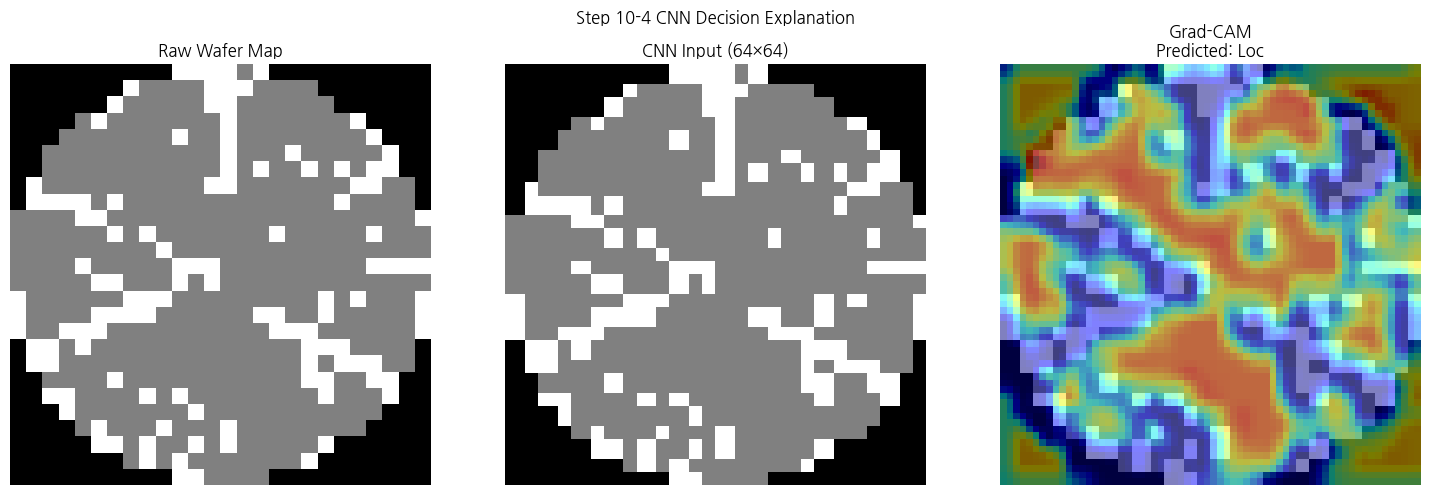

In [433]:
# 현재 Wafer의 CNN 판단 영역 시각화

raw_map = np.asarray(
    example_defect_map
)


# CNN 입력용 64×64 Map
processed_map = (

    preprocess_single_wafer(
        example_defect_map
    )

    [0, 0]

    .detach()
    .cpu()
    .numpy()
)


cam = (
    example_gradcam_result[
        "cam"
    ]
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


# ==================================================
# Raw Wafer
# ==================================================

axes[0].imshow(
    raw_map,
    cmap="gray",
    vmin=0,
    vmax=2
)

axes[0].set_title(
    "Raw Wafer Map"
)

axes[0].axis(
    "off"
)


# ==================================================
# CNN Input
# ==================================================

axes[1].imshow(
    processed_map,
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "CNN Input (64×64)"
)

axes[1].axis(
    "off"
)


# ==================================================
# Grad-CAM Overlay
# ==================================================

axes[2].imshow(
    processed_map,
    cmap="gray",
    vmin=0,
    vmax=1
)


axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.50,
    vmin=0,
    vmax=1
)


axes[2].set_title(

    f"Grad-CAM\n"
    f"Predicted: "
    f"{example_gradcam_result['predicted_class']}"
)


axes[2].axis(
    "off"
)


plt.suptitle(
    "Step 10-4 CNN Decision Explanation"
)


plt.tight_layout()

plt.show()

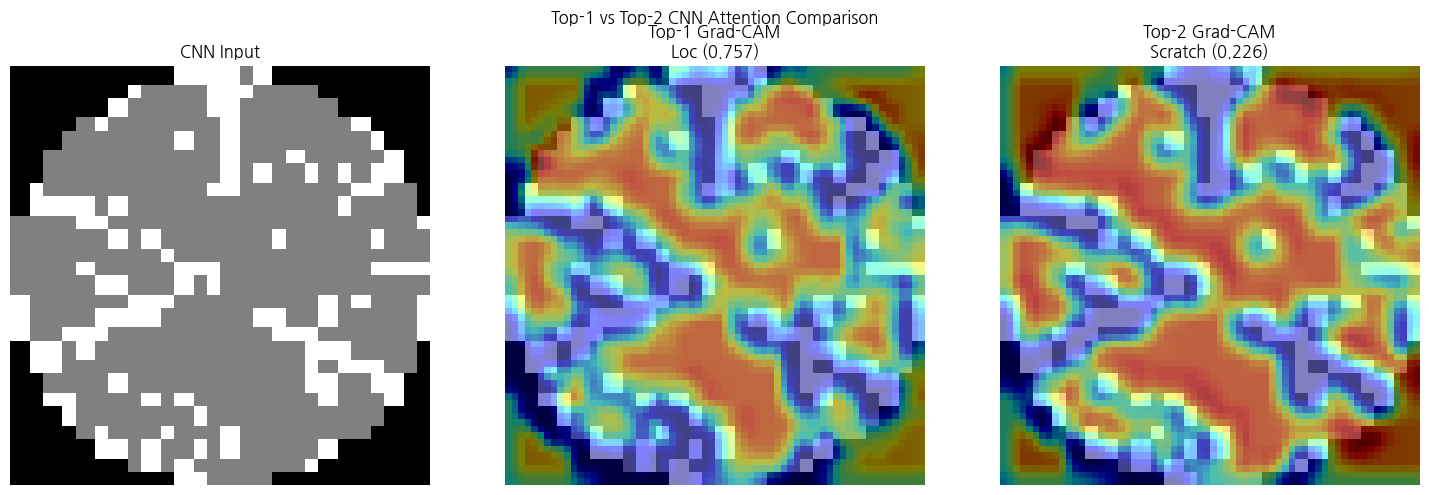

In [434]:
# Top-1과 Top-2 Grad-CAM 비교

top1_class = (
    example_multiclass_result[
        "predicted_class"
    ]
)


top2_class = (
    example_multiclass_result[
        "second_class"
    ]
)


top1_gradcam = (

    generate_wafer_gradcam(

        example_defect_map,

        target_class=
            top1_class
    )
)


top2_gradcam = (

    generate_wafer_gradcam(

        example_defect_map,

        target_class=
            top2_class
    )
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


axes[0].imshow(
    processed_map,
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0].set_title(
    "CNN Input"
)

axes[0].axis(
    "off"
)


# Top-1
axes[1].imshow(
    processed_map,
    cmap="gray"
)

axes[1].imshow(
    top1_gradcam["cam"],
    cmap="jet",
    alpha=0.50
)

axes[1].set_title(

    f"Top-1 Grad-CAM\n"

    f"{top1_class} "
    f"({example_multiclass_result['top1_probability']:.3f})"
)

axes[1].axis(
    "off"
)


# Top-2
axes[2].imshow(
    processed_map,
    cmap="gray"
)

axes[2].imshow(
    top2_gradcam["cam"],
    cmap="jet",
    alpha=0.50
)

axes[2].set_title(

    f"Top-2 Grad-CAM\n"

    f"{top2_class} "
    f"({example_multiclass_result['second_probability']:.3f})"
)

axes[2].axis(
    "off"
)


plt.suptitle(
    "Top-1 vs Top-2 CNN Attention Comparison"
)

plt.tight_layout()

plt.show()

## Step 10-5. Prediction Reliability Assessment

8-Class CNN의 Top-1 Prediction만으로 최종 결함 유형을 확정하지 않는다.

실제 새로운 Wafer에서는 정답 Label을 알 수 없으므로 다음과 같은 Deployment 가능한 정보를 함께 사용하여 Prediction Reliability를 평가한다.

- CNN Top-1 Probability
- Top-1 / Top-2 Confidence Margin
- Prediction Entropy
- Predicted-Class Spatial Prototype Distance
- Nearest Spatial Prototype과 CNN Prediction의 일치 여부
- Alternative Prototype과의 거리 차이
- Top-1 / Top-2 Grad-CAM의 유사성

특히 CNN의 Top-1과 Top-2 확률이 비슷하고 두 클래스의 Grad-CAM 또한 매우 유사하다면,
CNN이 동일한 Wafer 영역을 근거로 두 결함 유형 사이에서 구분에 어려움을 겪는 상황으로 해석한다.

Reliability Level은 모델의 확률적 정확도를 의미하지 않으며,
Prediction 결과를 자동으로 사용할지 추가 검토할지를 결정하기 위한 Rule-based Triage 정보로 사용한다.

In [435]:
# Step 10-5. Grad-CAM Similarity 계산

def compare_gradcam_maps(
    cam_a,
    cam_b
):

    cam_a = np.asarray(
        cam_a,
        dtype=float
    )

    cam_b = np.asarray(
        cam_b,
        dtype=float
    )


    a = cam_a.flatten()
    b = cam_b.flatten()


    # ==================================================
    # 1. Cosine Similarity
    # ==================================================

    cosine_similarity = float(

        np.dot(
            a,
            b
        )

        /

        (
            np.linalg.norm(a)
            *
            np.linalg.norm(b)
            +
            1e-12
        )
    )


    # ==================================================
    # 2. Pearson Correlation
    # ==================================================

    if (
        np.std(a) > 1e-12
        and
        np.std(b) > 1e-12
    ):

        correlation = float(
            np.corrcoef(
                a,
                b
            )[0, 1]
        )

    else:

        correlation = np.nan


    # ==================================================
    # 3. Mean Absolute Difference
    # ==================================================

    mean_absolute_difference = float(

        np.mean(
            np.abs(
                cam_a
                -
                cam_b
            )
        )
    )


    # ==================================================
    # 4. High-Activation Region IoU
    #
    # 각 CAM의 상위 20% 활성 영역 비교
    # ==================================================

    threshold_a = np.quantile(
        cam_a,
        0.80
    )

    threshold_b = np.quantile(
        cam_b,
        0.80
    )


    mask_a = (
        cam_a
        >=
        threshold_a
    )

    mask_b = (
        cam_b
        >=
        threshold_b
    )


    intersection = (
        mask_a
        &
        mask_b
    ).sum()


    union = (
        mask_a
        |
        mask_b
    ).sum()


    high_activation_iou = (

        float(
            intersection
            /
            union
        )

        if union > 0

        else np.nan
    )


    return {

        "cam_cosine_similarity":
            cosine_similarity,

        "cam_correlation":
            correlation,

        "cam_mean_absolute_difference":
            mean_absolute_difference,

        "high_activation_iou":
            high_activation_iou
    }

In [436]:
example_gradcam_comparison = (

    compare_gradcam_maps(

        top1_gradcam[
            "cam"
        ],

        top2_gradcam[
            "cam"
        ]
    )
)


print(
    "=== Top-1 vs Top-2 Grad-CAM Similarity ==="
)

print(
    "Top-1:",
    top1_class
)

print(
    "Top-2:",
    top2_class
)

print()

print(
    "Cosine Similarity:",
    f"{example_gradcam_comparison['cam_cosine_similarity']:.4f}"
)

print(
    "Pearson Correlation:",
    f"{example_gradcam_comparison['cam_correlation']:.4f}"
)

print(
    "High-Activation IoU:",
    f"{example_gradcam_comparison['high_activation_iou']:.4f}"
)

print(
    "Mean Absolute Difference:",
    f"{example_gradcam_comparison['cam_mean_absolute_difference']:.4f}"
)

=== Top-1 vs Top-2 Grad-CAM Similarity ===
Top-1: Loc
Top-2: Scratch

Cosine Similarity: 0.9793
Pearson Correlation: 0.9232
High-Activation IoU: 0.6302
Mean Absolute Difference: 0.1117


In [437]:
# Step 10-5. Deployment Reliability 기준

CLASS_LOW_CONFIDENCE_THRESHOLD = 0.70

CLASS_LOW_MARGIN_THRESHOLD = 0.20

CLASS_HIGH_ENTROPY_THRESHOLD = 0.30


SPATIAL_ATYPICAL_PERCENTILE = 0.95


# Step 8에서 실제 데이터 분포를 이용해 계산한
# Alternative Advantage 75% threshold 재사용

if "advantage_q75" in globals():

    STRONG_ALTERNATIVE_ADVANTAGE = float(
        advantage_q75
    )

else:

    # 현재 분석에서 계산된 값
    STRONG_ALTERNATIVE_ADVANTAGE = 0.2348


CAM_SIMILARITY_THRESHOLD = 0.90


print(
    "=== Deployment Reliability Threshold ==="
)

print(
    "Low Top-1 Confidence:",
    CLASS_LOW_CONFIDENCE_THRESHOLD
)

print(
    "Low Confidence Margin:",
    CLASS_LOW_MARGIN_THRESHOLD
)

print(
    "High Normalized Entropy:",
    CLASS_HIGH_ENTROPY_THRESHOLD
)

print(
    "Spatial Atypical Percentile:",
    SPATIAL_ATYPICAL_PERCENTILE
)

print(
    "Strong Alternative Advantage:",
    round(
        STRONG_ALTERNATIVE_ADVANTAGE,
        4
    )
)

print(
    "CAM Similarity Threshold:",
    CAM_SIMILARITY_THRESHOLD
)

=== Deployment Reliability Threshold ===
Low Top-1 Confidence: 0.7
Low Confidence Margin: 0.2
High Normalized Entropy: 0.3
Spatial Atypical Percentile: 0.95
Strong Alternative Advantage: 0.2348
CAM Similarity Threshold: 0.9


In [438]:
# Step 10-5.
# CNN + Spatial + Grad-CAM Reliability 통합

def assess_wafer_reliability(
    multiclass_result,
    spatial_result,
    gradcam_comparison
):

    review_reasons = []


    # ==================================================
    # 1. CNN Classification Uncertainty
    # ==================================================

    classification_uncertain = (

        multiclass_result[
            "top1_probability"
        ]
        <
        CLASS_LOW_CONFIDENCE_THRESHOLD

        or

        multiclass_result[
            "confidence_margin"
        ]
        <
        CLASS_LOW_MARGIN_THRESHOLD

        or

        multiclass_result[
            "normalized_entropy"
        ]
        >
        CLASS_HIGH_ENTROPY_THRESHOLD
    )


    if classification_uncertain:

        review_reasons.append(
            "CNN class prediction is uncertain"
        )


    # ==================================================
    # 2. Strong Spatial Conflict
    # ==================================================

    strong_spatial_conflict = (

        spatial_result[
            "predicted_distance_percentile"
        ]
        >=
        SPATIAL_ATYPICAL_PERCENTILE

        and

        spatial_result[
            "alternative_advantage"
        ]
        >=
        STRONG_ALTERNATIVE_ADVANTAGE
    )


    if strong_spatial_conflict:

        review_reasons.append(
            "Strong spatial-profile conflict"
        )


    # ==================================================
    # 3. Mild Prototype Disagreement
    # ==================================================

    mild_prototype_disagreement = (

        not spatial_result[
            "prototype_agreement"
        ]

        and

        not strong_spatial_conflict
    )


    if mild_prototype_disagreement:

        review_reasons.append(
            "CNN class and nearest spatial prototype differ"
        )


    # ==================================================
    # 4. Grad-CAM Ambiguity
    #
    # Top-1/Top-2 확률도 가깝고
    # 보는 영역까지 유사한 경우
    # ==================================================

    attention_ambiguity = (

        gradcam_comparison[
            "cam_cosine_similarity"
        ]
        >=
        CAM_SIMILARITY_THRESHOLD

        and

        multiclass_result[
            "confidence_margin"
        ]
        <
        CLASS_LOW_MARGIN_THRESHOLD
    )


    if attention_ambiguity:

        review_reasons.append(
            "Top-1 and Top-2 classes use highly similar attention regions"
        )


    # ==================================================
    # Reliability Level
    # ==================================================

    if strong_spatial_conflict:

        reliability_level = (
            "Manual review required"
        )


    else:

        concern_count = sum([

            classification_uncertain,

            mild_prototype_disagreement,

            attention_ambiguity
        ])


        if concern_count == 0:

            reliability_level = (
                "High reliability"
            )

        elif concern_count == 1:

            reliability_level = (
                "Moderate reliability"
            )

        else:

            reliability_level = (
                "Review recommended"
            )


    return {

        "reliability_level":
            reliability_level,

        "classification_uncertain":
            classification_uncertain,

        "strong_spatial_conflict":
            strong_spatial_conflict,

        "mild_prototype_disagreement":
            mild_prototype_disagreement,

        "attention_ambiguity":
            attention_ambiguity,

        "review_reason_count":
            len(
                review_reasons
            ),

        "review_reasons":
            review_reasons
    }

In [439]:
example_reliability_result = (

    assess_wafer_reliability(

        example_multiclass_result,

        example_spatial_result,

        example_gradcam_comparison
    )
)


print(
    "=== Step 10-5 Prediction Reliability ==="
)

print(
    "Predicted Pattern:",
    example_multiclass_result[
        "predicted_class"
    ]
)

print(
    "Reliability:",
    example_reliability_result[
        "reliability_level"
    ]
)

print()

print(
    "Classification Uncertain:",
    example_reliability_result[
        "classification_uncertain"
    ]
)

print(
    "Strong Spatial Conflict:",
    example_reliability_result[
        "strong_spatial_conflict"
    ]
)

print(
    "Mild Prototype Disagreement:",
    example_reliability_result[
        "mild_prototype_disagreement"
    ]
)

print(
    "Attention Ambiguity:",
    example_reliability_result[
        "attention_ambiguity"
    ]
)


print()

print(
    "=== Review Reasons ==="
)


if (
    example_reliability_result[
        "review_reason_count"
    ]
    == 0
):

    print(
        "No major reliability warning"
    )

else:

    for reason in (
        example_reliability_result[
            "review_reasons"
        ]
    ):

        print(
            "-",
            reason
        )

=== Step 10-5 Prediction Reliability ===
Predicted Pattern: Loc
Reliability: Moderate reliability

Classification Uncertain: False
Strong Spatial Conflict: False
Mild Prototype Disagreement: True
Attention Ambiguity: False

=== Review Reasons ===
- CNN class and nearest spatial prototype differ


In [440]:
# Step 10-6. 현재 노트북의 RCA 관련 변수 / 함수 확인

rca_keywords = [
    "rca",
    "cause",
    "root",
    "signature",
    "equipment",
    "material",
    "process"
]


rca_objects = []


for name, obj in globals().copy().items():

    lower_name = name.lower()

    if not any(
        keyword in lower_name
        for keyword in rca_keywords
    ):
        continue


    # 함수 여부
    if callable(obj):

        object_type = "function"

        try:
            object_info = str(
                inspect.signature(obj)
            )

        except Exception:

            object_info = "-"


    # DataFrame
    elif isinstance(
        obj,
        pd.DataFrame
    ):

        object_type = "DataFrame"

        object_info = str(
            obj.shape
        )


    # Dictionary
    elif isinstance(
        obj,
        dict
    ):

        object_type = "dict"

        object_info = (
            f"len={len(obj)}"
        )


    else:

        continue


    rca_objects.append({

        "object_name":
            name,

        "object_type":
            object_type,

        "info":
            object_info
    })


rca_object_df = pd.DataFrame(
    rca_objects
)


print(
    "=== 현재 노트북의 RCA 관련 객체 ==="
)


display(
    rca_object_df
)

=== 현재 노트북의 RCA 관련 객체 ===


,object_name,object_type,info
0,class_signature_df,DataFrame,"(104, 8)"
1,top_signature_df,DataFrame,"(40, 8)"
2,readable_signature_df,DataFrame,"(40, 10)"
3,signature_matrix_df,DataFrame,"(8, 13)"
4,category_signature_df,DataFrame,"(32, 4)"
5,rca_hypothesis_df,DataFrame,"(8, 6)"
6,rca_verification_df,DataFrame,"(16, 9)"
7,rca_primary_route_df,DataFrame,"(8, 6)"
8,get_rca_verification_plan,function,"(defect_class, top_n=2)"
9,example_rca_plan,DataFrame,"(2, 9)"


In [441]:
# Step 10-6. 기존 RCA Framework 구조 확인

RCA_CHECK_OBJECTS = {
    "rca_hypothesis_df":
        rca_hypothesis_df,

    "rca_verification_df":
        rca_verification_df,

    "rca_primary_route_df":
        rca_primary_route_df
}


for name, dataframe in RCA_CHECK_OBJECTS.items():

    print(
        "=" * 80
    )

    print(
        name,
        dataframe.shape
    )

    print(
        "Columns:"
    )

    print(
        dataframe.columns.tolist()
    )

    print()

    display(
        dataframe.head()
    )

    print()

rca_hypothesis_df (8, 6)
Columns:
['class', 'data_signature', 'pattern_interpretation', 'process_hypothesis', 'equipment_or_condition_candidate', 'evidence_level']



,class,data_signature,pattern_interpretation,process_hypothesis,equipment_or_condition_candidate,evidence_level
0,Center,"높은 center ratio 및 center defect density, 낮은 me...",결함이 wafer 중심부에 집중,Thin-film deposition non-uniformity; CMP cente...,"Deposition uniformity, CMP pressure/profile, c...",Literature-supported candidate
1,Donut,"높은 middle ratio, 낮은 edge ratio 및 mean radius",중앙이 아닌 중간 반경에 ring 형태의 결함 집중,Photoresist-related radial non-uniformity; pos...,"Coating/develop condition, resist flow or rede...",Literature-supported candidate
2,Edge-Loc,"높은 cluster fragmentation, global elongation 및 ...",wafer 외곽의 특정 영역에 국소적·방향성 결함 형성,Localized edge process non-uniformity; uneven ...,"Edge temperature distribution, local contact/h...",Literature-supported candidate
3,Edge-Ring,"높은 edge ratio와 mean radius, 높은 largest cluster...",wafer 가장자리를 따라 연속적인 ring 형태 형성,Etching non-uniformity; possible radial therma...,"Etch edge condition, plasma/radial uniformity,...",Strong literature-supported candidate
4,Loc,높은 middle-region tendency 및 cluster fragmentat...,wafer 일부 영역에 국소적으로 결함이 집중,Localized equipment/process disturbance; possi...,"Equipment vibration, localized chamber/process...",Literature-supported candidate



rca_verification_df (16, 9)
Columns:
['class', 'priority', 'category', 'candidate', 'why_check', 'required_data', 'comparison', 'supporting_signal', 'verification_status']



,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
0,Center,1,Process,Center-to-edge film / process non-uniformity,Center 영역에 결함이 집중되는 공간적 Signature 확인,"Radial thickness, CD, etch/deposition rate, wa...",Center vs Middle vs Edge radial profile 비교,Center 영역에서만 공정 결과가 체계적으로 이동,Requires process data
1,Center,2,Equipment,Center-region pressure / thermal / deposition ...,중심부 defect density가 다른 클래스보다 높음,"Temperature profile, pressure profile, deposit...",정상 wafer와 동일 chamber/recipe wafer 비교,Center 집중 이상이 특정 장비 또는 조건과 반복적으로 동반,Requires equipment data
2,Donut,1,Process,Mid-radius process non-uniformity,Middle ratio가 다른 클래스보다 뚜렷하게 높음,"Radial CD, thickness, develop/coat result, pro...",Center / Middle / Edge radial profile 비교,중간 반경 영역에서 ring 형태의 공정 편차 확인,Requires process data
3,Donut,2,Material / Process,Photoresist coating / develop radial variation,Wafer 중간 반경을 중심으로 결함이 집중,"PR thickness, coat/develop recipe, dispense/sp...",정상 wafer와 PR radial profile 비교,동일 반경에서 PR 또는 develop 결과 이상 확인,Requires material/process data
4,Edge-Loc,1,Equipment,Localized edge process non-uniformity,외곽의 특정 영역에 국소적·방향성 결함이 나타남,"Wafer orientation, local temperature, chamber ...",결함 발생 방향과 wafer/chamber orientation 비교,동일 방향 또는 위치에서 반복적으로 defect 발생,Requires equipment data



rca_primary_route_df (8, 6)
Columns:
['class', 'primary_category', 'primary_rca_candidate', 'required_verification_data', 'recommended_comparison', 'supporting_verification_signal']



,class,primary_category,primary_rca_candidate,required_verification_data,recommended_comparison,supporting_verification_signal
0,Center,Process,Center-to-edge film / process non-uniformity,"Radial thickness, CD, etch/deposition rate, wa...",Center vs Middle vs Edge radial profile 비교,Center 영역에서만 공정 결과가 체계적으로 이동
1,Donut,Process,Mid-radius process non-uniformity,"Radial CD, thickness, develop/coat result, pro...",Center / Middle / Edge radial profile 비교,중간 반경 영역에서 ring 형태의 공정 편차 확인
2,Edge-Loc,Equipment,Localized edge process non-uniformity,"Wafer orientation, local temperature, chamber ...",결함 발생 방향과 wafer/chamber orientation 비교,동일 방향 또는 위치에서 반복적으로 defect 발생
3,Edge-Ring,Process,Radial edge process non-uniformity,"Radial CD, etch rate, film thickness, within-w...",Center-to-edge process profile 비교,Wafer edge에서 연속적인 공정 편차 확인
4,Loc,Equipment / Process,Localized process disturbance,"Local CD/thickness, chamber map, wafer orienta...",정상 wafer와 defect 발생 위치 주변 process result 비교,동일 위치에서 국소적인 공정 편차 확인


In [442]:
# 기존 RCA Verification 함수 확인

RCA_TEST_CLASSES = [
    "Loc",
    "Scratch",
    "Edge-Loc"
]


for defect_class in RCA_TEST_CLASSES:

    print(
        "=" * 80
    )

    print(
        f"=== {defect_class} RCA Verification Plan ==="
    )

    try:

        test_plan = (
            get_rca_verification_plan(
                defect_class,
                top_n=2
            )
        )

        display(
            test_plan
        )

    except Exception as e:

        print(
            "Error:",
            e
        )

    print()

=== Loc RCA Verification Plan ===


,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
8,Loc,1,Equipment / Process,Localized process disturbance,특정 wafer 영역에 Cluster가 국소적으로 집중,"Local CD/thickness, chamber map, wafer orienta...",정상 wafer와 defect 발생 위치 주변 process result 비교,동일 위치에서 국소적인 공정 편차 확인,Requires process data
9,Loc,2,Environment / Equipment,Localized particle or chamber disturbance,전면이 아닌 특정 영역에만 결함 집중,"Particle inspection, chamber clean history, eq...",Defect 발생 시점 전후 particle/event trend 비교,Particle 증가 또는 equipment event와 defect 발생이 동반,Requires inspection/history data



=== Scratch RCA Verification Plan ===


,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
14,Scratch,1,Handling / Equipment,Mechanical contact / wafer handling,높은 elongation과 linear defect signature 확인,"Robot path, handler/chuck contact position, wa...",Scratch 방향과 handling trajectory/contact 위치 비교,기계적 이동 또는 접촉 방향과 Scratch가 일치,Requires equipment history
15,Scratch,2,Process / Equipment,CMP mechanical scratch,길고 방향성 있는 defect cluster가 반복됨,"CMP pad condition, slurry particle status, pol...",CMP 전/후 검사 및 pad 사용 이력 비교,CMP 이후 Scratch 출현 또는 pad/particle event와 동반,Requires process/equipment data



=== Edge-Loc RCA Verification Plan ===


,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
4,Edge-Loc,1,Equipment,Localized edge process non-uniformity,외곽의 특정 영역에 국소적·방향성 결함이 나타남,"Wafer orientation, local temperature, chamber ...",결함 발생 방향과 wafer/chamber orientation 비교,동일 방향 또는 위치에서 반복적으로 defect 발생,Requires equipment data
5,Edge-Loc,2,Handling / Equipment,Localized edge contact or handling issue,Edge 영역의 국소적 Cluster 및 방향성 증가,"Robot handling history, chuck/contact position...",Defect 위치와 handling/contact 위치 비교,기계적 접촉 위치와 defect 위치가 공간적으로 일치,Requires equipment history


In [443]:
# Step 10-6.
# Reliability 기반 RCA Investigation Route 선정

def select_rca_routes(
    multiclass_result,
    spatial_result,
    reliability_result
):

    primary_class = (
        multiclass_result[
            "predicted_class"
        ]
    )

    second_class = (
        multiclass_result[
            "second_class"
        ]
    )

    spatial_class = (
        spatial_result[
            "nearest_prototype_class"
        ]
    )

    reliability_level = (
        reliability_result[
            "reliability_level"
        ]
    )


    routes = []


    # ==================================================
    # 1. Primary CNN Route
    # ==================================================

    routes.append({

        "route_priority":
            1,

        "route_source":
            "CNN Top-1",

        "defect_class":
            primary_class
    })


    # ==================================================
    # 2. Reliability에 따른 보조 Route
    # ==================================================

    if reliability_level == (
        "High reliability"
    ):

        # Top-1만 사용
        pass


    elif reliability_level == (
        "Moderate reliability"
    ):

        # Spatial Prototype이 CNN과 다르면 추가
        if (
            spatial_class
            !=
            primary_class
        ):

            routes.append({

                "route_priority":
                    2,

                "route_source":
                    "Spatial Prototype",

                "defect_class":
                    spatial_class
            })


    else:

        # Review recommended
        # 또는 Manual review required

        if (
            second_class
            !=
            primary_class
        ):

            routes.append({

                "route_priority":
                    2,

                "route_source":
                    "CNN Top-2",

                "defect_class":
                    second_class
            })


        if (
            spatial_class
            not in
            [
                primary_class,
                second_class
            ]
        ):

            routes.append({

                "route_priority":
                    3,

                "route_source":
                    "Spatial Prototype",

                "defect_class":
                    spatial_class
            })


    # ==================================================
    # 중복 제거
    # ==================================================

    unique_routes = []

    seen_classes = set()


    for route in routes:

        defect_class = (
            route[
                "defect_class"
            ]
        )

        if defect_class in seen_classes:

            continue


        seen_classes.add(
            defect_class
        )

        unique_routes.append(
            route
        )


    return pd.DataFrame(
        unique_routes
    )

In [444]:
example_rca_route_df = (

    select_rca_routes(

        example_multiclass_result,

        example_spatial_result,

        example_reliability_result
    )
)


print(
    "=== Step 10-6 RCA Investigation Routes ==="
)


display(
    example_rca_route_df
)

=== Step 10-6 RCA Investigation Routes ===


,route_priority,route_source,defect_class
0,1,CNN Top-1,Loc
1,2,Spatial Prototype,Edge-Loc


In [445]:
# RCA Route별 Verification Plan 생성

def recommend_rca(
    multiclass_result,
    spatial_result,
    reliability_result,
    top_n_per_route=2
):

    # ==================================================
    # RCA Route 선정
    # ==================================================

    route_df = (

        select_rca_routes(

            multiclass_result,

            spatial_result,

            reliability_result
        )
    )


    rca_plan_list = []


    # ==================================================
    # 각 Route별 기존 RCA Plan 호출
    # ==================================================

    for _, route in route_df.iterrows():

        defect_class = (
            route[
                "defect_class"
            ]
        )


        plan = (
            get_rca_verification_plan(

                defect_class,

                top_n=
                    top_n_per_route
            )
        )


        if plan is None:

            continue


        if not isinstance(
            plan,
            pd.DataFrame
        ):

            plan = pd.DataFrame(
                plan
            )


        plan = (
            plan.copy()
        )


        plan.insert(
            0,
            "route_priority",
            int(
                route[
                    "route_priority"
                ]
            )
        )


        plan.insert(
            1,
            "route_source",
            route[
                "route_source"
            ]
        )


        plan.insert(
            2,
            "route_defect_class",
            defect_class
        )


        rca_plan_list.append(
            plan
        )


    # ==================================================
    # 결과
    # ==================================================

    if len(
        rca_plan_list
    ) == 0:

        combined_plan = (
            pd.DataFrame()
        )

    else:

        combined_plan = (

            pd.concat(
                rca_plan_list,
                ignore_index=True
            )
        )


    return {

        "rca_routes":
            route_df,

        "rca_verification_plan":
            combined_plan
    }

In [446]:
example_rca_result = (

    recommend_rca(

        example_multiclass_result,

        example_spatial_result,

        example_reliability_result,

        top_n_per_route=2
    )
)


print(
    "=== RCA Route ==="
)

display(
    example_rca_result[
        "rca_routes"
    ]
)


print()

print(
    "=== RCA Verification Plan ==="
)

display(
    example_rca_result[
        "rca_verification_plan"
    ]
)

=== RCA Route ===


,route_priority,route_source,defect_class
0,1,CNN Top-1,Loc
1,2,Spatial Prototype,Edge-Loc



=== RCA Verification Plan ===


,route_priority,route_source,route_defect_class,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
0,1,CNN Top-1,Loc,Loc,1,Equipment / Process,Localized process disturbance,특정 wafer 영역에 Cluster가 국소적으로 집중,"Local CD/thickness, chamber map, wafer orienta...",정상 wafer와 defect 발생 위치 주변 process result 비교,동일 위치에서 국소적인 공정 편차 확인,Requires process data
1,1,CNN Top-1,Loc,Loc,2,Environment / Equipment,Localized particle or chamber disturbance,전면이 아닌 특정 영역에만 결함 집중,"Particle inspection, chamber clean history, eq...",Defect 발생 시점 전후 particle/event trend 비교,Particle 증가 또는 equipment event와 defect 발생이 동반,Requires inspection/history data
2,2,Spatial Prototype,Edge-Loc,Edge-Loc,1,Equipment,Localized edge process non-uniformity,외곽의 특정 영역에 국소적·방향성 결함이 나타남,"Wafer orientation, local temperature, chamber ...",결함 발생 방향과 wafer/chamber orientation 비교,동일 방향 또는 위치에서 반복적으로 defect 발생,Requires equipment data
3,2,Spatial Prototype,Edge-Loc,Edge-Loc,2,Handling / Equipment,Localized edge contact or handling issue,Edge 영역의 국소적 Cluster 및 방향성 증가,"Robot handling history, chuck/contact position...",Defect 위치와 handling/contact 위치 비교,기계적 접촉 위치와 defect 위치가 공간적으로 일치,Requires equipment history


## Step 10-7. Final Explainable Wafer Diagnosis Pipeline

지금까지 구축한 모든 분석 모듈을 하나의 Wafer Diagnosis Pipeline으로 통합한다.

새로운 Wafer Map 하나가 입력되면 다음 순서로 자동 진단한다.

1. Raw Wafer Map 기본 Integrity 검사
2. Binary CNN을 이용한 Defect Pattern Screening
3. Normal / No-pattern이면 진단 종료
4. Defect가 의심되면 8-Class CNN으로 결함 유형 분류
5. Top-1 / Top-2 Prediction 및 Confidence 분석
6. 13개 Spatial Feature 추출
7. Train 기반 Class Prototype과 비교
8. Top-1 / Top-2 Grad-CAM 분석
9. CNN Confidence, Spatial Prototype 및 Grad-CAM을 이용한 Reliability 평가
10. Reliability에 따라 RCA Investigation Route 선정
11. 각 RCA Route에 대해 필요한 공정 / 장비 / 검사 데이터를 제안

본 Pipeline은 Wafer Map만으로 실제 Root Cause를 확정하지 않는다.

CNN 및 Spatial Pattern은 가능한 결함 유형과 조사 우선순위를 좁히는 데 사용하며,
최종 Root Cause 판단은 공정 조건, 장비 History, Particle Inspection, Wafer Orientation 등의 추가 데이터를 통해 검증해야 한다.

In [447]:
# Step 10-7.
# Final Explainable Wafer Diagnosis Pipeline

def diagnose_wafer(
    wafer_map,
    rca_top_n=2,
    generate_gradcam=True
):

    # ==================================================
    # STEP 1
    # Binary Defect Screening
    # ==================================================

    binary_result = (
        detect_wafer_defect(
            wafer_map
        )
    )


    final_result = {

        "binary_screening":
            binary_result,

        "defect_classification":
            None,

        "spatial_analysis":
            None,

        "gradcam_analysis":
            None,

        "reliability":
            None,

        "rca":
            None
    }


    # ==================================================
    # Normal / No-pattern
    # → 여기서 종료
    # ==================================================

    if not binary_result[
        "defect_detected"
    ]:

        final_result[
            "final_status"
        ] = (
            "Normal / no-pattern"
        )

        final_result[
            "recommended_action"
        ] = (
            "No additional defect-pattern diagnosis required"
        )

        return final_result


    # ==================================================
    # STEP 2
    # 8-Class Defect Classification
    # ==================================================

    multiclass_result = (

        classify_defect_pattern(
            wafer_map
        )
    )


    final_result[
        "defect_classification"
    ] = multiclass_result


    predicted_class = (
        multiclass_result[
            "predicted_class"
        ]
    )


    second_class = (
        multiclass_result[
            "second_class"
        ]
    )


    # ==================================================
    # STEP 3
    # Spatial / Prototype Analysis
    # ==================================================

    spatial_result = (

        analyze_wafer_spatially(

            wafer_map,

            predicted_class=
                predicted_class
        )
    )


    final_result[
        "spatial_analysis"
    ] = spatial_result


    # ==================================================
    # STEP 4
    # Grad-CAM
    # ==================================================

    if generate_gradcam:

        top1_gradcam_result = (

            generate_wafer_gradcam(

                wafer_map,

                target_class=
                    predicted_class
            )
        )


        top2_gradcam_result = (

            generate_wafer_gradcam(

                wafer_map,

                target_class=
                    second_class
            )
        )


        gradcam_comparison = (

            compare_gradcam_maps(

                top1_gradcam_result[
                    "cam"
                ],

                top2_gradcam_result[
                    "cam"
                ]
            )
        )


        gradcam_result = {

            "top1_gradcam":
                top1_gradcam_result,

            "top2_gradcam":
                top2_gradcam_result,

            "comparison":
                gradcam_comparison
        }


        final_result[
            "gradcam_analysis"
        ] = gradcam_result


    else:

        gradcam_comparison = {

            "cam_cosine_similarity":
                np.nan,

            "cam_correlation":
                np.nan,

            "cam_mean_absolute_difference":
                np.nan,

            "high_activation_iou":
                np.nan
        }


    # ==================================================
    # STEP 5
    # Reliability Assessment
    # ==================================================

    reliability_result = (

        assess_wafer_reliability(

            multiclass_result,

            spatial_result,

            gradcam_comparison
        )
    )


    final_result[
        "reliability"
    ] = reliability_result


    # ==================================================
    # STEP 6
    # RCA Recommendation
    # ==================================================

    rca_result = (

        recommend_rca(

            multiclass_result,

            spatial_result,

            reliability_result,

            top_n_per_route=
                rca_top_n
        )
    )


    final_result[
        "rca"
    ] = rca_result


    # ==================================================
    # Final Status
    # ==================================================

    final_result[
        "final_status"
    ] = (
        "Defect pattern suspected"
    )


    if (
        reliability_result[
            "reliability_level"
        ]
        ==
        "High reliability"
    ):

        final_result[
            "recommended_action"
        ] = (

            f"Proceed with "
            f"{predicted_class}-centered RCA"
        )


    elif (
        reliability_result[
            "reliability_level"
        ]
        ==
        "Moderate reliability"
    ):

        final_result[
            "recommended_action"
        ] = (

            "Proceed with primary RCA while "
            "checking supporting spatial evidence"
        )


    else:

        final_result[
            "recommended_action"
        ] = (

            "Review multiple defect hypotheses "
            "before concluding RCA"
        )


    return final_result

In [448]:
# Final Diagnosis 결과 출력 함수

def print_wafer_diagnosis(
    diagnosis
):

    print(
        "=" * 70
    )

    print(
        "FINAL WAFER DIAGNOSIS"
    )

    print(
        "=" * 70
    )


    # ==================================================
    # Binary Screening
    # ==================================================

    binary = (
        diagnosis[
            "binary_screening"
        ]
    )


    print()
    print(
        "[1] Defect Screening"
    )

    print(
        "Result:",
        binary[
            "screening_result"
        ]
    )

    print(
        "Defect Probability:",
        f"{binary['defect_probability']:.4f}"
    )

    print(
        "Decision Threshold:",
        f"{binary['decision_threshold']:.2f}"
    )


    # ==================================================
    # Normal이면 종료
    # ==================================================

    if not binary[
        "defect_detected"
    ]:

        print()
        print(
            "[Final Result]"
        )

        print(
            "Normal / No-pattern"
        )

        print(
            "Action:",
            diagnosis[
                "recommended_action"
            ]
        )

        print()
        print(
            "=" * 70
        )

        return


    # ==================================================
    # Multi-Class
    # ==================================================

    multiclass = (

        diagnosis[
            "defect_classification"
        ]
    )


    print()
    print(
        "[2] Defect Pattern Classification"
    )

    print(
        "Top-1:",
        multiclass[
            "predicted_class"
        ],
        f"({multiclass['top1_probability']:.4f})"
    )

    print(
        "Top-2:",
        multiclass[
            "second_class"
        ],
        f"({multiclass['second_probability']:.4f})"
    )

    print(
        "Confidence Margin:",
        f"{multiclass['confidence_margin']:.4f}"
    )

    print(
        "Normalized Entropy:",
        f"{multiclass['normalized_entropy']:.4f}"
    )


    # ==================================================
    # Spatial
    # ==================================================

    spatial = (
        diagnosis[
            "spatial_analysis"
        ]
    )


    print()
    print(
        "[3] Spatial / Prototype Analysis"
    )

    print(
        "CNN Predicted Class:",
        multiclass[
            "predicted_class"
        ]
    )

    print(
        "Nearest Spatial Prototype:",
        spatial[
            "nearest_prototype_class"
        ]
    )

    print(
        "Prototype Agreement:",
        spatial[
            "prototype_agreement"
        ]
    )

    print(
        "Predicted-Class Distance Percentile:",
        f"{spatial['predicted_distance_percentile']:.4f}"
    )

    print(
        "Alternative Advantage:",
        f"{spatial['alternative_advantage']:+.4f}"
    )

    print(
        "Spatial Typicality:",
        spatial[
            "spatial_typicality"
        ]
    )


    # ==================================================
    # Grad-CAM
    # ==================================================

    if (
        diagnosis[
            "gradcam_analysis"
        ]
        is not None
    ):

        gradcam = (

            diagnosis[
                "gradcam_analysis"
            ][
                "comparison"
            ]
        )


        print()
        print(
            "[4] Grad-CAM Comparison"
        )

        print(
            "Top-1 / Top-2 CAM Cosine Similarity:",
            f"{gradcam['cam_cosine_similarity']:.4f}"
        )

        print(
            "CAM Correlation:",
            f"{gradcam['cam_correlation']:.4f}"
        )

        print(
            "High-Activation IoU:",
            f"{gradcam['high_activation_iou']:.4f}"
        )


    # ==================================================
    # Reliability
    # ==================================================

    reliability = (
        diagnosis[
            "reliability"
        ]
    )


    print()
    print(
        "[5] Prediction Reliability"
    )

    print(
        "Reliability Level:",
        reliability[
            "reliability_level"
        ]
    )


    if len(
        reliability[
            "review_reasons"
        ]
    ) > 0:

        print(
            "Review Reasons:"
        )

        for reason in (
            reliability[
                "review_reasons"
            ]
        ):

            print(
                " -",
                reason
            )


    # ==================================================
    # RCA
    # ==================================================

    rca = (
        diagnosis[
            "rca"
        ]
    )


    print()
    print(
        "[6] RCA Investigation Routes"
    )


    for _, row in (
        rca[
            "rca_routes"
        ]
        .iterrows()
    ):

        print(

            f"{int(row['route_priority'])}. "
            f"{row['route_source']} "
            f"→ {row['defect_class']}"
        )


    print()
    print(
        "[Final Action]"
    )

    print(
        diagnosis[
            "recommended_action"
        ]
    )


    print()
    print(
        "=" * 70
    )

In [449]:
# 현재 Example Wafer 전체 자동 진단

example_final_diagnosis = (

    diagnose_wafer(
        example_defect_map
    )
)


print_wafer_diagnosis(
    example_final_diagnosis
)

FINAL WAFER DIAGNOSIS

[1] Defect Screening
Result: Defect suspected
Defect Probability: 0.8785
Decision Threshold: 0.12

[2] Defect Pattern Classification
Top-1: Loc (0.7568)
Top-2: Scratch (0.2257)
Confidence Margin: 0.5311
Normalized Entropy: 0.2970

[3] Spatial / Prototype Analysis
CNN Predicted Class: Loc
Nearest Spatial Prototype: Edge-Loc
Prototype Agreement: False
Predicted-Class Distance Percentile: 0.4925
Alternative Advantage: +0.0762
Spatial Typicality: Typical for predicted class

[4] Grad-CAM Comparison
Top-1 / Top-2 CAM Cosine Similarity: 0.9793
CAM Correlation: 0.9232
High-Activation IoU: 0.6302

[5] Prediction Reliability
Reliability Level: Moderate reliability
Review Reasons:
 - CNN class and nearest spatial prototype differ

[6] RCA Investigation Routes
1. CNN Top-1 → Loc
2. Spatial Prototype → Edge-Loc

[Final Action]
Proceed with primary RCA while checking supporting spatial evidence



In [450]:
print(
    "=== Final RCA Verification Plan ==="
)


display(
    example_final_diagnosis[
        "rca"
    ][
        "rca_verification_plan"
    ]
)

=== Final RCA Verification Plan ===


,route_priority,route_source,route_defect_class,class,priority,category,candidate,why_check,required_data,comparison,supporting_signal,verification_status
0,1,CNN Top-1,Loc,Loc,1,Equipment / Process,Localized process disturbance,특정 wafer 영역에 Cluster가 국소적으로 집중,"Local CD/thickness, chamber map, wafer orienta...",정상 wafer와 defect 발생 위치 주변 process result 비교,동일 위치에서 국소적인 공정 편차 확인,Requires process data
1,1,CNN Top-1,Loc,Loc,2,Environment / Equipment,Localized particle or chamber disturbance,전면이 아닌 특정 영역에만 결함 집중,"Particle inspection, chamber clean history, eq...",Defect 발생 시점 전후 particle/event trend 비교,Particle 증가 또는 equipment event와 defect 발생이 동반,Requires inspection/history data
2,2,Spatial Prototype,Edge-Loc,Edge-Loc,1,Equipment,Localized edge process non-uniformity,외곽의 특정 영역에 국소적·방향성 결함이 나타남,"Wafer orientation, local temperature, chamber ...",결함 발생 방향과 wafer/chamber orientation 비교,동일 방향 또는 위치에서 반복적으로 defect 발생,Requires equipment data
3,2,Spatial Prototype,Edge-Loc,Edge-Loc,2,Handling / Equipment,Localized edge contact or handling issue,Edge 영역의 국소적 Cluster 및 방향성 증가,"Robot handling history, chuck/contact position...",Defect 위치와 handling/contact 위치 비교,기계적 접촉 위치와 defect 위치가 공간적으로 일치,Requires equipment history


In [451]:
def visualize_wafer_diagnosis(
    wafer_map,
    diagnosis
):

    # Normal이면 Wafer만 표시
    if not diagnosis[
        "binary_screening"
    ][
        "defect_detected"
    ]:

        plt.figure(
            figsize=(5, 5)
        )

        plt.imshow(
            np.asarray(
                wafer_map
            ),
            cmap="gray",
            vmin=0,
            vmax=2
        )

        plt.title(

            "Normal / No-pattern\n"

            f"Defect Probability: "
            f"{diagnosis['binary_screening']['defect_probability']:.3f}"
        )

        plt.axis(
            "off"
        )

        plt.show()

        return


    # ==================================================
    # Defect Case
    # ==================================================

    processed_map = (

        preprocess_single_wafer(
            wafer_map
        )

        [0, 0]

        .detach()
        .cpu()
        .numpy()
    )


    multiclass = (
        diagnosis[
            "defect_classification"
        ]
    )


    gradcam = (
        diagnosis[
            "gradcam_analysis"
        ]
    )


    top1_cam = (
        gradcam[
            "top1_gradcam"
        ][
            "cam"
        ]
    )


    top2_cam = (
        gradcam[
            "top2_gradcam"
        ][
            "cam"
        ]
    )


    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )


    # Input
    axes[0].imshow(
        processed_map,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0].set_title(
        "CNN Input"
    )

    axes[0].axis(
        "off"
    )


    # Top 1
    axes[1].imshow(
        processed_map,
        cmap="gray"
    )

    axes[1].imshow(
        top1_cam,
        cmap="jet",
        alpha=0.50
    )

    axes[1].set_title(

        f"Top-1 Grad-CAM\n"
        f"{multiclass['predicted_class']} "
        f"({multiclass['top1_probability']:.3f})"
    )

    axes[1].axis(
        "off"
    )


    # Top 2
    axes[2].imshow(
        processed_map,
        cmap="gray"
    )

    axes[2].imshow(
        top2_cam,
        cmap="jet",
        alpha=0.50
    )

    axes[2].set_title(

        f"Top-2 Grad-CAM\n"
        f"{multiclass['second_class']} "
        f"({multiclass['second_probability']:.3f})"
    )

    axes[2].axis(
        "off"
    )


    plt.suptitle(

        f"Wafer Diagnosis | "
        f"Reliability: "
        f"{diagnosis['reliability']['reliability_level']}"
    )


    plt.tight_layout()

    plt.show()

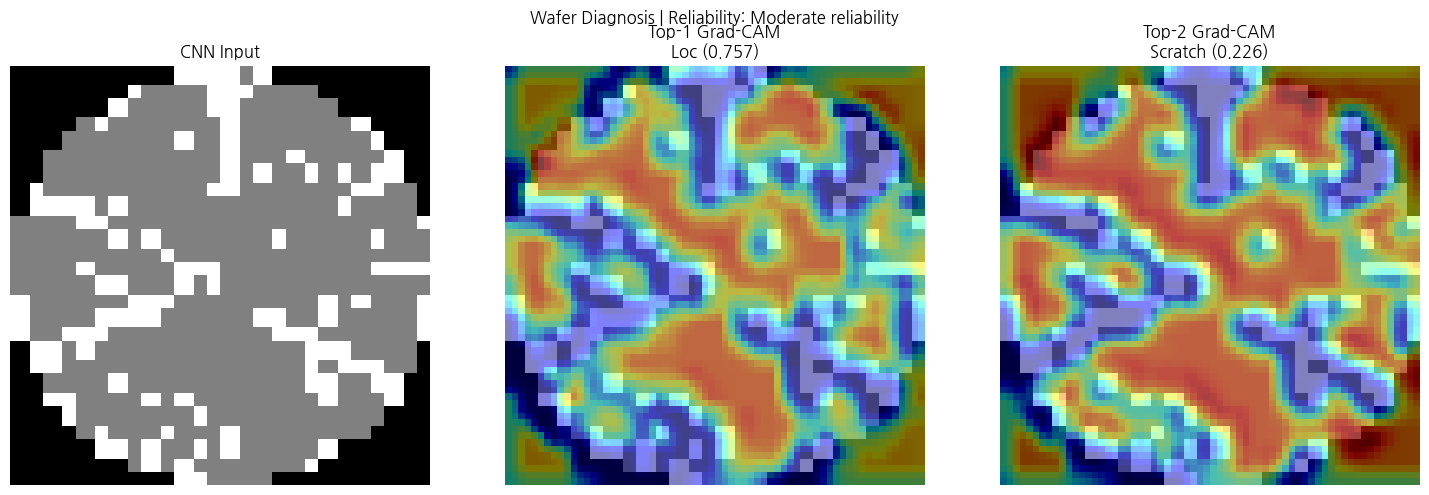

In [452]:
visualize_wafer_diagnosis(

    example_defect_map,

    example_final_diagnosis
)

## Step 10-8. Final Pipeline Validation

최종적으로 구축한 `diagnose_wafer()` Pipeline이 서로 다른 유형의 Wafer에서도 의도한 방식으로 작동하는지 검증한다.

다음 네 가지 대표 상황을 확인한다.

**Case 1. Clear Normal**
Binary Detector가 낮은 Defect Probability를 출력하고 추가 분석 없이 종료하는지 확인한다.

**Case 2. Clear Defect**
Binary Detector가 결함을 탐지하고, 8-Class CNN과 Spatial Evidence가 비교적 일관된 경우 좁은 범위의 RCA를 제안하는지 확인한다.

**Case 3. Ambiguous Defect**
CNN Top-1과 Top-2가 경쟁하는 경우 불확실성을 감지하고 Review를 권고하는지 확인한다.

**Case 4. Spatially Atypical Defect**
CNN Prediction과 Spatial Prototype 사이에 강한 불일치가 존재하는 경우 자동 확정하지 않고 추가 검토 또는 다중 RCA Route를 제안하는지 확인한다.

각 Sample의 실제 Label은 Pipeline 입력에 사용하지 않으며, 분석 이후 동작을 검증하기 위한 Reference로만 사용한다.

In [453]:
# Step 10-8.
# Binary Test Prediction 정보 연결

final_validation_binary_df = (
    binary_test_df.copy()
)


assert len(
    final_validation_binary_df
) == len(
    binary_test_defect_prob
)


final_validation_binary_df[
    "binary_defect_probability"
] = (
    binary_test_defect_prob
)


final_validation_binary_df[
    "binary_prediction"
] = (

    final_validation_binary_df[
        "binary_defect_probability"
    ]
    >=
    FINAL_BINARY_THRESHOLD

).astype(int)


final_validation_binary_df[
    "binary_correct"
] = (

    final_validation_binary_df[
        "binary_prediction"
    ]
    ==
    final_validation_binary_df[
        "binary_label"
    ]
)


print(
    "=== Final Validation Binary Table ==="
)

print(
    "Sample:",
    len(
        final_validation_binary_df
    )
)

display(
    final_validation_binary_df[
        [
            "lotName",
            "waferIndex",
            "label",
            "binary_label_name",
            "binary_defect_probability",
            "binary_prediction",
            "binary_correct"
        ]
    ]
    .head()
    .style.format({
        "binary_defect_probability":
            "{:.4f}"
    })
)

=== Final Validation Binary Table ===
Sample: 25469


,lotName,waferIndex,label,binary_label_name,binary_defect_probability,binary_prediction,binary_correct
0,lot19,1.000000,none,Normal / none,0.0000,0,True
1,lot19,2.000000,none,Normal / none,0.0029,0,True
2,lot19,3.000000,none,Normal / none,0.1135,0,True
3,lot19,4.000000,none,Normal / none,0.0180,0,True
4,lot19,5.000000,none,Normal / none,0.1702,1,False


In [454]:
# Case 1. Clear Normal

case1_row = (

    final_validation_binary_df[
        final_validation_binary_df[
            "binary_label"
        ]
        == 0
    ]

    .sort_values(
        "binary_defect_probability",
        ascending=True
    )

    .iloc[0]
)


case1_wafer = (
    case1_row[
        "waferMap"
    ]
)


print(
    "=== Case 1: Clear Normal ==="
)

print(
    "Reference Label:",
    case1_row[
        "label"
    ]
)

print(
    "Defect Probability:",
    f"{case1_row['binary_defect_probability']:.6f}"
)

=== Case 1: Clear Normal ===
Reference Label: none
Defect Probability: 0.000000


In [455]:
# 8-Class Test Sample 정보 구성

step10_defect_reference_df = (
    prediction_df.copy()
)


# 원본 Wafer Map 연결
step10_defect_reference_df[
    "waferMap"
] = [

    test_df.iloc[
        int(sample_pos)
    ][
        "waferMap"
    ]

    for sample_pos
    in step10_defect_reference_df[
        "sample_pos"
    ]
]


print(
    "=== 8-Class Test Reference Table ==="
)

print(
    "Sample:",
    len(
        step10_defect_reference_df
    )
)


display(
    step10_defect_reference_df[
        [
            "sample_pos",
            "true_label",
            "pred_label",
            "top1_prob",
            "second_label",
            "second_prob",
            "confidence_margin",
            "correct"
        ]
    ]
    .head()
)

=== 8-Class Test Reference Table ===
Sample: 3911


,sample_pos,true_label,pred_label,top1_prob,second_label,second_prob,confidence_margin,correct
0,0,Scratch,Loc,0.756832,Scratch,0.225711,0.531122,False
1,1,Edge-Loc,Edge-Loc,0.697406,Loc,0.301465,0.395941,True
2,2,Loc,Loc,0.999958,Edge-Loc,0.000028,0.999930,True
3,3,Edge-Loc,Edge-Loc,0.999996,Edge-Ring,0.000004,0.999991,True
4,4,Edge-Loc,Edge-Loc,0.998789,Edge-Ring,0.001211,0.997579,True


In [456]:
# Case 2. Clear Defect

clear_defect_candidates = (

    step10_defect_reference_df[
        (
            step10_defect_reference_df[
                "correct"
            ]
        )
        &
        (
            step10_defect_reference_df[
                "top1_prob"
            ]
            >= 0.99
        )
        &
        (
            step10_defect_reference_df[
                "confidence_margin"
            ]
            >= 0.90
        )
    ]

    .copy()
)


print(
    "Clear Defect Candidate:",
    len(
        clear_defect_candidates
    )
)


case2_row = (

    clear_defect_candidates

    .sort_values(
        [
            "top1_prob",
            "confidence_margin"
        ],
        ascending=False
    )

    .iloc[0]
)


case2_wafer = (
    case2_row[
        "waferMap"
    ]
)


print()
print(
    "=== Case 2: Clear Defect ==="
)

print(
    "Reference Label:",
    case2_row[
        "true_label"
    ]
)

print(
    "CNN Prediction:",
    case2_row[
        "pred_label"
    ]
)

print(
    "Top-1 Probability:",
    f"{case2_row['top1_prob']:.4f}"
)

print(
    "Confidence Margin:",
    f"{case2_row['confidence_margin']:.4f}"
)

Clear Defect Candidate: 2428

=== Case 2: Clear Defect ===
Reference Label: Edge-Ring
CNN Prediction: Edge-Ring
Top-1 Probability: 1.0000
Confidence Margin: 1.0000


In [457]:
# Case 3. Ambiguous Defect

ambiguous_candidates = (

    step10_defect_reference_df[
        (
            step10_defect_reference_df[
                "top1_prob"
            ]
            >= 0.40
        )
        &
        (
            step10_defect_reference_df[
                "top1_prob"
            ]
            <= 0.70
        )
        &
        (
            step10_defect_reference_df[
                "confidence_margin"
            ]
            <= 0.15
        )
    ]

    .copy()
)


print(
    "Ambiguous Candidate:",
    len(
        ambiguous_candidates
    )
)


case3_row = (

    ambiguous_candidates

    .sort_values(
        "confidence_margin",
        ascending=True
    )

    .iloc[0]
)


case3_wafer = (
    case3_row[
        "waferMap"
    ]
)


print()
print(
    "=== Case 3: Ambiguous Defect ==="
)

print(
    "Reference Label:",
    case3_row[
        "true_label"
    ]
)

print(
    "CNN Top-1:",
    case3_row[
        "pred_label"
    ],
    f"{case3_row['top1_prob']:.4f}"
)

print(
    "CNN Top-2:",
    case3_row[
        "second_label"
    ],
    f"{case3_row['second_prob']:.4f}"
)

print(
    "Margin:",
    f"{case3_row['confidence_margin']:.4f}"
)

Ambiguous Candidate: 135

=== Case 3: Ambiguous Defect ===
Reference Label: Edge-Ring
CNN Top-1: Edge-Loc 0.5001
CNN Top-2: Edge-Ring 0.4999
Margin: 0.0002


In [458]:
# Case 4. Spatially Atypical Defect
#
# CNN correct 여부는 선정 기준에 사용하지 않음

spatial_atypical_candidates = (

    step8_final_validation_df[
        (
            step8_final_validation_df[
                "strong_spatial_profile_mismatch_flag"
            ]
        )
        &
        (
            step8_final_validation_df[
                "refined_integrity_order"
            ]
            > 2
        )
    ]

    .copy()
)


print(
    "Spatially Atypical Candidate:",
    len(
        spatial_atypical_candidates
    )
)


case4_row = (

    spatial_atypical_candidates

    .sort_values(
        [
            "true_profile_distance_percentile",
            "alternative_profile_advantage"
        ],
        ascending=False
    )

    .iloc[0]
)


case4_sample_pos = int(
    case4_row[
        "sample_pos"
    ]
)


case4_wafer = (

    test_df.iloc[
        case4_sample_pos
    ][
        "waferMap"
    ]
)


print()
print(
    "=== Case 4: Spatially Atypical Defect ==="
)

print(
    "Reference Label:",
    case4_row[
        "true_label"
    ]
)

print(
    "Alternative Prototype:",
    case4_row[
        "nearest_alternative_label"
    ]
)

print(
    "True-Class Distance Percentile:",
    f"{case4_row['true_profile_distance_percentile']:.4f}"
)

print(
    "Alternative Advantage:",
    f"{case4_row['alternative_profile_advantage']:+.4f}"
)

Spatially Atypical Candidate: 52

=== Case 4: Spatially Atypical Defect ===
Reference Label: Edge-Loc
Alternative Prototype: Near-full
True-Class Distance Percentile: 0.9989
Alternative Advantage: +1.0885


In [459]:
# ==================================================
# Final Pipeline Validation
# ==================================================

case1_diagnosis = (
    diagnose_wafer(
        case1_wafer
    )
)


case2_diagnosis = (
    diagnose_wafer(
        case2_wafer
    )
)


case3_diagnosis = (
    diagnose_wafer(
        case3_wafer
    )
)


case4_diagnosis = (
    diagnose_wafer(
        case4_wafer
    )
)


print(
    "✓ 4개 Final Validation Case 진단 완료"
)

✓ 4개 Final Validation Case 진단 완료


In [460]:
print(
    "\n"
    + "=" * 80
)

print(
    "CASE 1 — CLEAR NORMAL"
)

print(
    "Reference:",
    case1_row[
        "label"
    ]
)

print(
    "=" * 80
)


print_wafer_diagnosis(
    case1_diagnosis
)


CASE 1 — CLEAR NORMAL
Reference: none
FINAL WAFER DIAGNOSIS

[1] Defect Screening
Result: Normal / no-pattern
Defect Probability: 0.0000
Decision Threshold: 0.12

[Final Result]
Normal / No-pattern
Action: No additional defect-pattern diagnosis required



In [461]:
print(
    "\n"
    + "=" * 80
)

print(
    "CASE 2 — CLEAR DEFECT"
)

print(
    "Reference:",
    case2_row[
        "true_label"
    ]
)

print(
    "=" * 80
)


print_wafer_diagnosis(
    case2_diagnosis
)


CASE 2 — CLEAR DEFECT
Reference: Edge-Ring
FINAL WAFER DIAGNOSIS

[1] Defect Screening
Result: Defect suspected
Defect Probability: 1.0000
Decision Threshold: 0.12

[2] Defect Pattern Classification
Top-1: Edge-Ring (1.0000)
Top-2: Edge-Loc (0.0000)
Confidence Margin: 1.0000
Normalized Entropy: 0.0000

[3] Spatial / Prototype Analysis
CNN Predicted Class: Edge-Ring
Nearest Spatial Prototype: Edge-Ring
Prototype Agreement: True
Predicted-Class Distance Percentile: 0.2532
Alternative Advantage: -0.5461
Spatial Typicality: Typical for predicted class

[4] Grad-CAM Comparison
Top-1 / Top-2 CAM Cosine Similarity: 0.7527
CAM Correlation: 0.7440
High-Activation IoU: 1.0000

[5] Prediction Reliability
Reliability Level: High reliability

[6] RCA Investigation Routes
1. CNN Top-1 → Edge-Ring

[Final Action]
Proceed with Edge-Ring-centered RCA



In [462]:
print(
    "\n"
    + "=" * 80
)

print(
    "CASE 3 — AMBIGUOUS DEFECT"
)

print(
    "Reference:",
    case3_row[
        "true_label"
    ]
)

print(
    "=" * 80
)


print_wafer_diagnosis(
    case3_diagnosis
)


CASE 3 — AMBIGUOUS DEFECT
Reference: Edge-Ring
FINAL WAFER DIAGNOSIS

[1] Defect Screening
Result: Defect suspected
Defect Probability: 1.0000
Decision Threshold: 0.12

[2] Defect Pattern Classification
Top-1: Edge-Loc (0.5001)
Top-2: Edge-Ring (0.4999)
Confidence Margin: 0.0002
Normalized Entropy: 0.3333

[3] Spatial / Prototype Analysis
CNN Predicted Class: Edge-Loc
Nearest Spatial Prototype: Edge-Loc
Prototype Agreement: True
Predicted-Class Distance Percentile: 0.5305
Alternative Advantage: -0.1506
Spatial Typicality: Typical for predicted class

[4] Grad-CAM Comparison
Top-1 / Top-2 CAM Cosine Similarity: 0.5754
CAM Correlation: 0.5754
High-Activation IoU: 1.0000

[5] Prediction Reliability
Reliability Level: Moderate reliability
Review Reasons:
 - CNN class prediction is uncertain

[6] RCA Investigation Routes
1. CNN Top-1 → Edge-Loc

[Final Action]
Proceed with primary RCA while checking supporting spatial evidence



In [463]:
print(
    "\n"
    + "=" * 80
)

print(
    "CASE 4 — SPATIALLY ATYPICAL DEFECT"
)

print(
    "Reference:",
    case4_row[
        "true_label"
    ]
)

print(
    "=" * 80
)


print_wafer_diagnosis(
    case4_diagnosis
)


CASE 4 — SPATIALLY ATYPICAL DEFECT
Reference: Edge-Loc
FINAL WAFER DIAGNOSIS

[1] Defect Screening
Result: Defect suspected
Defect Probability: 1.0000
Decision Threshold: 0.12

[2] Defect Pattern Classification
Top-1: Edge-Loc (0.9999)
Top-2: Random (0.0001)
Confidence Margin: 0.9998
Normalized Entropy: 0.0004

[3] Spatial / Prototype Analysis
CNN Predicted Class: Edge-Loc
Nearest Spatial Prototype: Near-full
Prototype Agreement: False
Predicted-Class Distance Percentile: 0.9989
Alternative Advantage: +1.0885
Spatial Typicality: Strongly atypical - review required

[4] Grad-CAM Comparison
Top-1 / Top-2 CAM Cosine Similarity: 0.8700
CAM Correlation: 0.7237
High-Activation IoU: 0.0081

[5] Prediction Reliability
Reliability Level: Manual review required
Review Reasons:
 - Strong spatial-profile conflict

[6] RCA Investigation Routes
1. CNN Top-1 → Edge-Loc
2. CNN Top-2 → Random
3. Spatial Prototype → Near-full

[Final Action]
Review multiple defect hypotheses before concluding RCA



In [464]:
# ==================================================
# Step 10-8. Final Pipeline Validation Summary
# ==================================================

# 필요한 Diagnosis가 모두 존재하는지 먼저 확인
required_diagnosis_vars = [
    "case1_diagnosis",
    "case2_diagnosis",
    "case3_diagnosis",
    "case4_diagnosis"
]

missing_vars = [
    var_name
    for var_name in required_diagnosis_vars
    if var_name not in globals()
]

if len(missing_vars) > 0:

    raise NameError(
        "먼저 Cell 327을 실행해주세요. "
        f"없는 변수: {missing_vars}"
    )


# ==================================================
# Summary Row 생성 함수
# ==================================================

def make_final_validation_row(
    case_name,
    reference_label,
    diagnosis
):

    binary = diagnosis[
        "binary_screening"
    ]


    # --------------------------------------------------
    # Normal / No-pattern
    # --------------------------------------------------

    if not binary[
        "defect_detected"
    ]:

        return {

            "case":
                case_name,

            "reference_label":
                str(reference_label),

            "binary_result":
                "Normal",

            "defect_probability":
                float(
                    binary[
                        "defect_probability"
                    ]
                ),

            "predicted_pattern":
                "-",

            "top1_probability":
                np.nan,

            "second_pattern":
                "-",

            "nearest_prototype":
                "-",

            "prototype_agreement":
                "-",

            "reliability":
                "Screening stop",

            "rca_route_count":
                0
        }


    # --------------------------------------------------
    # Defect
    # --------------------------------------------------

    multiclass = diagnosis[
        "defect_classification"
    ]

    spatial = diagnosis[
        "spatial_analysis"
    ]

    reliability = diagnosis[
        "reliability"
    ]

    rca = diagnosis[
        "rca"
    ]


    # RCA Route 수 안전하게 계산
    if (
        rca is not None
        and
        "rca_routes" in rca
        and
        rca["rca_routes"] is not None
    ):

        rca_route_count = len(
            rca[
                "rca_routes"
            ]
        )

    else:

        rca_route_count = 0


    return {

        "case":
            case_name,

        "reference_label":
            str(reference_label),

        "binary_result":
            "Defect",

        "defect_probability":
            float(
                binary[
                    "defect_probability"
                ]
            ),

        "predicted_pattern":
            multiclass[
                "predicted_class"
            ],

        "top1_probability":
            float(
                multiclass[
                    "top1_probability"
                ]
            ),

        "second_pattern":
            multiclass[
                "second_class"
            ],

        "nearest_prototype":
            spatial[
                "nearest_prototype_class"
            ],

        "prototype_agreement":
            bool(
                spatial[
                    "prototype_agreement"
                ]
            ),

        "reliability":
            reliability[
                "reliability_level"
            ],

        "rca_route_count":
            int(
                rca_route_count
            )
    }


# ==================================================
# Reference Label 안전하게 가져오기
# ==================================================

case1_reference = "none"

case2_reference = str(
    case2_row[
        "true_label"
    ]
)

case3_reference = str(
    case3_row[
        "true_label"
    ]
)

case4_reference = str(
    case4_row[
        "true_label"
    ]
)


# ==================================================
# Final Summary DataFrame
# ==================================================

validation_rows = [

    make_final_validation_row(
        "1. Clear Normal",
        case1_reference,
        case1_diagnosis
    ),

    make_final_validation_row(
        "2. Clear Defect",
        case2_reference,
        case2_diagnosis
    ),

    make_final_validation_row(
        "3. Ambiguous Defect",
        case3_reference,
        case3_diagnosis
    ),

    make_final_validation_row(
        "4. Spatially Atypical",
        case4_reference,
        case4_diagnosis
    )
]


final_pipeline_validation_df = pd.DataFrame(
    validation_rows
)


print(
    "=== Final Pipeline Validation Summary ==="
)


display(
    final_pipeline_validation_df
    .style.format({

        "defect_probability":
            "{:.4f}",

        "top1_probability":
            "{:.4f}"
    })
)

=== Final Pipeline Validation Summary ===


,case,reference_label,binary_result,defect_probability,predicted_pattern,top1_probability,second_pattern,nearest_prototype,prototype_agreement,reliability,rca_route_count
0,1. Clear Normal,none,Normal,0.0000,-,nan,-,-,-,Screening stop,0
1,2. Clear Defect,Edge-Ring,Defect,1.0000,Edge-Ring,1.0000,Edge-Loc,Edge-Ring,True,High reliability,1
2,3. Ambiguous Defect,Edge-Ring,Defect,1.0000,Edge-Loc,0.5001,Edge-Ring,Edge-Loc,True,Moderate reliability,1
3,4. Spatially Atypical,Edge-Loc,Defect,1.0000,Edge-Loc,0.9999,Random,Near-full,False,Manual review required,3


In [465]:
# ==================================================
# Step 10-9.
# 최종 진단 결과 한국어 출력 함수
# ==================================================

RELIABILITY_KR = {

    "High reliability":
        "높은 신뢰도",

    "Moderate reliability":
        "보통 신뢰도",

    "Review recommended":
        "추가 검토 권장",

    "Manual review required":
        "수동 검토 필요"
}


REVIEW_REASON_KR = {

    "CNN class prediction is uncertain":
        "CNN의 결함 유형 예측이 불확실합니다.",

    "Strong spatial-profile conflict":
        "CNN 예측과 공간적 패턴 사이에 강한 불일치가 있습니다.",

    "CNN class and nearest spatial prototype differ":
        "CNN 예측 클래스와 가장 가까운 Spatial Prototype이 다릅니다.",

    "Top-1 and Top-2 classes use highly similar attention regions":
        "CNN의 1순위와 2순위 결함이 매우 유사한 영역을 근거로 판단되었습니다."
}


def print_wafer_diagnosis_korean(
    diagnosis,
    reference_label=None
):

    print(
        "=" * 72
    )

    print(
        "웨이퍼 자동 진단 결과"
    )

    print(
        "=" * 72
    )


    # ==================================================
    # 실제 Label
    # Pipeline에서는 사용하지 않고
    # 진단 후 비교용으로만 표시
    # ==================================================

    if reference_label is not None:

        print()

        print(
            "[검증용 실제 Label]"
        )

        print(
            reference_label
        )


    # ==================================================
    # 1. Binary Screening
    # ==================================================

    binary = diagnosis[
        "binary_screening"
    ]


    print()
    print(
        "[1] 결함 유무 판정"
    )


    if binary[
        "defect_detected"
    ]:

        print(
            "판정: 결함 패턴 의심"
        )

    else:

        print(
            "판정: 정상 / 특정 결함 패턴 없음"
        )


    print(
        "결함 확률:",
        f"{binary['defect_probability']:.2%}"
    )

    print(
        "판정 기준값:",
        f"{binary['decision_threshold']:.2f}"
    )


    # ==================================================
    # Normal이면 종료
    # ==================================================

    if not binary[
        "defect_detected"
    ]:

        print()
        print(
            "[최종 판단]"
        )

        print(
            "추가적인 결함 유형 분석이 필요하지 않습니다."
        )

        print()

        print(
            "=" * 72
        )

        return


    # ==================================================
    # 2. 8-Class CNN
    # ==================================================

    multiclass = diagnosis[
        "defect_classification"
    ]


    print()
    print(
        "[2] 결함 유형 분류"
    )

    print(
        "1순위:",
        multiclass[
            "predicted_class"
        ],
        f"({multiclass['top1_probability']:.2%})"
    )

    print(
        "2순위:",
        multiclass[
            "second_class"
        ],
        f"({multiclass['second_probability']:.2%})"
    )

    print(
        "1·2순위 확률 차이:",
        f"{multiclass['confidence_margin']:.4f}"
    )

    print(
        "예측 불확실성(정규화 Entropy):",
        f"{multiclass['normalized_entropy']:.4f}"
    )


    # ==================================================
    # 3. Spatial
    # ==================================================

    spatial = diagnosis[
        "spatial_analysis"
    ]


    print()
    print(
        "[3] 공간 패턴 분석"
    )

    print(
        "CNN 예측:",
        multiclass[
            "predicted_class"
        ]
    )

    print(
        "가장 가까운 Spatial Prototype:",
        spatial[
            "nearest_prototype_class"
        ]
    )


    if spatial[
        "prototype_agreement"
    ]:

        print(
            "CNN–Spatial 일치 여부: 일치"
        )

    else:

        print(
            "CNN–Spatial 일치 여부: 불일치"
        )


    print(
        "예측 클래스 내 거리 백분위:",
        f"{spatial['predicted_distance_percentile']:.2%}"
    )

    print(
        "대안 Prototype 우위:",
        f"{spatial['alternative_advantage']:+.4f}"
    )


    # ==================================================
    # 4. Grad-CAM
    # ==================================================

    if diagnosis[
        "gradcam_analysis"
    ] is not None:

        cam = diagnosis[
            "gradcam_analysis"
        ][
            "comparison"
        ]


        print()
        print(
            "[4] CNN 판단 영역 비교"
        )

        print(
            "1순위–2순위 Grad-CAM 유사도:",
            f"{cam['cam_cosine_similarity']:.4f}"
        )

        print(
            "Grad-CAM 상관계수:",
            f"{cam['cam_correlation']:.4f}"
        )

        print(
            "고활성 영역 IoU:",
            f"{cam['high_activation_iou']:.4f}"
        )


    # ==================================================
    # 5. Reliability
    # ==================================================

    reliability = diagnosis[
        "reliability"
    ]


    reliability_kr = RELIABILITY_KR.get(

        reliability[
            "reliability_level"
        ],

        reliability[
            "reliability_level"
        ]
    )


    print()
    print(
        "[5] 예측 신뢰도"
    )

    print(
        "신뢰도 수준:",
        reliability_kr
    )


    if len(
        reliability[
            "review_reasons"
        ]
    ) > 0:

        print(
            "검토가 필요한 이유:"
        )


        for reason in reliability[
            "review_reasons"
        ]:

            reason_kr = (
                REVIEW_REASON_KR.get(
                    reason,
                    reason
                )
            )

            print(
                " -",
                reason_kr
            )


    # ==================================================
    # 6. RCA
    # ==================================================

    print()
    print(
        "[6] RCA 조사 우선순위"
    )


    rca_routes = diagnosis[
        "rca"
    ][
        "rca_routes"
    ]


    SOURCE_KR = {

        "CNN Top-1":
            "CNN 1순위",

        "CNN Top-2":
            "CNN 2순위",

        "Spatial Prototype":
            "공간 패턴"
    }


    for _, row in (
        rca_routes.iterrows()
    ):

        source_kr = SOURCE_KR.get(
            row[
                "route_source"
            ],
            row[
                "route_source"
            ]
        )


        print(

            f"{int(row['route_priority'])}순위: "
            f"{row['defect_class']} "
            f"({source_kr} 근거)"
        )


    # ==================================================
    # 최종 해석
    # ==================================================

    print()
    print(
        "[최종 판단]"
    )


    level = reliability[
        "reliability_level"
    ]


    if level == "High reliability":

        print(
            f"{multiclass['predicted_class']} 결함 가능성이 높으며, "
            "해당 결함을 중심으로 RCA를 진행하는 것이 권장됩니다."
        )


    elif level == "Moderate reliability":

        print(
            f"{multiclass['predicted_class']}을 우선적으로 조사하되, "
            "공간적 패턴과 추가 데이터를 함께 확인하는 것이 권장됩니다."
        )


    elif level == "Review recommended":

        print(
            "결함은 감지되었으나 유형 판단에 불확실성이 있으므로 "
            "여러 결함 후보를 함께 검토하는 것이 권장됩니다."
        )


    else:

        print(
            "CNN 예측과 다른 분석 신호 사이의 불일치가 크므로 "
            "결함 유형을 자동 확정하지 말고 수동 검토가 필요합니다."
        )


    print()
    print(
        "=" * 72
    )

### 최종 Normal / Defect / Review 판정

기존 Binary Detector는 Defect Recall을 높이기 위해 낮은 Threshold(0.12)를 사용하므로,
일부 실제 Normal Wafer가 Defect로 Screening되는 False Positive가 발생할 수 있다.

그러나 후단의 8-Class CNN은 Normal Class를 학습하지 않았기 때문에,
Binary 단계에서 Defect로 전달된 Wafer를 다시 Normal로 직접 분류할 수는 없다.

따라서 최종 시스템에서는 다음의 3가지 상태를 사용한다.

- **Normal**: Binary Detector가 Defect Probability 0.12 미만으로 판단한 경우
- **Defect**: Binary Screening 이후 후단 분석에서도 충분한 결함 Evidence가 존재하는 경우
- **Review**: Binary에서는 Defect가 의심되지만 Probability가 낮거나,
  CNN / Spatial / Grad-CAM 분석 결과가 불확실하거나 서로 충돌하는 경우

Review는 Normal 또는 Defect를 강제로 확정하지 않고 추가적인 Inspection,
Process Data 또는 Engineer Review가 필요함을 의미한다.

이를 통해 Defect Recall을 우선하는 Screening 구조를 유지하면서도,
Binary False Positive가 곧바로 특정 Failure Type으로 확정되는 문제를 완화하였다.

In [466]:
# ==================================================
# Final 3-State Decision
# Normal / Defect / Review
# ==================================================

def assign_final_wafer_decision(
    diagnosis,
    strong_defect_probability=0.50
):

    binary = diagnosis[
        "binary_screening"
    ]

    defect_prob = float(
        binary[
            "defect_probability"
        ]
    )


    # ==================================================
    # 1. Binary 단계에서 Normal
    # ==================================================

    if not binary[
        "defect_detected"
    ]:

        return {

            "final_decision":
                "Normal",

            "final_decision_kr":
                "정상 / 특정 결함 패턴 없음",

            "decision_reason":
                (
                    "Binary Detector의 결함 확률이 "
                    "Screening Threshold보다 낮습니다."
                ),

            "requires_review":
                False
        }


    # ==================================================
    # 2. Binary에서는 Defect 의심
    # ==================================================

    reliability = diagnosis[
        "reliability"
    ]

    reliability_level = reliability[
        "reliability_level"
    ]


    # --------------------------------------------------
    # CNN / Spatial 분석에서 명확한 Review 신호
    # --------------------------------------------------

    if reliability_level in [
        "Review recommended",
        "Manual review required"
    ]:

        return {

            "final_decision":
                "Review",

            "final_decision_kr":
                "추가 검토 필요",

            "decision_reason":
                (
                    "Binary 단계에서는 결함이 의심되지만 "
                    "후단 Classification 또는 Spatial Evidence에 "
                    "불확실성/충돌이 존재합니다."
                ),

            "requires_review":
                True
        }


    # --------------------------------------------------
    # Binary Probability 자체가 낮은 Screening 영역
    #
    # 0.12 이상이므로 Defect 후보에는 포함되지만,
    # 0.50 미만이면 바로 Defect로 확정하지 않음
    # --------------------------------------------------

    if defect_prob < strong_defect_probability:

        return {

            "final_decision":
                "Review",

            "final_decision_kr":
                "추가 검토 필요",

            "decision_reason":
                (
                    f"결함 확률({defect_prob:.4f})이 "
                    "Screening Threshold는 넘었지만 "
                    "강한 Defect Evidence 기준에는 미치지 못합니다."
                ),

            "requires_review":
                True
        }


    # ==================================================
    # 3. Binary + 후단 분석 모두 충분히 일관적
    # ==================================================

    return {

        "final_decision":
            "Defect",

        "final_decision_kr":
            "결함 패턴 확인",

        "decision_reason":
            (
                "Binary Detector의 결함 Evidence가 충분하고 "
                "후단 분석에서도 강한 충돌이 발견되지 않았습니다."
            ),

        "requires_review":
            False
    }

In [467]:
# ==================================================
# Final Diagnosis Wrapper
# ==================================================

def diagnose_wafer_final(
    wafer_map,
    rca_top_n=2,
    generate_gradcam=True
):

    # 기존 전체 Pipeline 실행
    diagnosis = diagnose_wafer(
        wafer_map,
        rca_top_n=rca_top_n,
        generate_gradcam=generate_gradcam
    )


    # 최종 Normal / Defect / Review 판정
    final_decision = (
        assign_final_wafer_decision(
            diagnosis
        )
    )


    diagnosis[
        "final_decision"
    ] = final_decision


    return diagnosis

In [468]:
def print_final_decision_korean(
    diagnosis
):

    final_result = diagnosis[
        "final_decision"
    ]


    print()
    print(
        "=" * 72
    )

    print(
        "최종 Wafer 판정"
    )

    print(
        "=" * 72
    )


    print(
        "최종 상태:",
        final_result[
            "final_decision_kr"
        ]
    )


    print(
        "판정 근거:",
        final_result[
            "decision_reason"
        ]
    )


    if final_result[
        "final_decision"
    ] == "Normal":

        print(
            "권장 조치: 추가 결함 Pattern 분석 없이 종료합니다."
        )


    elif final_result[
        "final_decision"
    ] == "Defect":

        print(
            "권장 조치: 예측된 Failure Type을 중심으로 "
            "RCA Investigation을 진행합니다."
        )


    else:

        print(
            "권장 조치: Normal 또는 특정 Failure Type으로 "
            "자동 확정하지 않고 추가 Inspection 및 "
            "Process/Equipment Data를 확인합니다."
        )


    print(
        "=" * 72
    )

### 무작위 Test Wafer 1개 자동 진단

전체 Test Set에서 Wafer 하나를 무작위로 선택하여 최종 `diagnose_wafer()` Pipeline에 입력한다.

Test Set에는 Normal / none Wafer와 8개 Defect Pattern Wafer가 모두 포함되어 있으므로,
실행할 때마다 정상 또는 결함 Wafer가 무작위로 선택된다.

선택된 Wafer에 대해서 다음 과정을 자동으로 수행한다.

- Binary CNN을 이용한 정상 / 결함 Pattern 판정
- 정상으로 판단되면 추가 분석 없이 종료
- 결함으로 판단되면 8-Class CNN 결함 유형 분류
- Spatial Prototype 비교
- Grad-CAM 분석
- Prediction Reliability 평가
- RCA Investigation Route 제안

화면에 표시되는 실제 Label은 모델의 입력으로 사용하지 않으며,
Pipeline의 진단 결과를 사후 검증하기 위한 Reference로만 사용한다.

본 Cell은 새로운 Wafer 하나를 실제 시스템에 입력했을 때와 유사한 형태로
전체 Pipeline의 동작을 간단히 점검하기 위해 사용한다.

※ Test Set의 약 85%가 Normal / none이므로 반복 실행 시 Normal Wafer가 자주 선택될 수 있다.

In [469]:
# ==================================================
# Test Set에서 무작위 Wafer 하나 진단
# ==================================================

random_row = (

    binary_test_df

    .sample(
        n=1
    )

    .iloc[0]
)


random_wafer = (
    random_row[
        "waferMap"
    ]
)


random_reference_label = (
    random_row[
        "label"
    ]
)


print(
    "=== 무작위 Test Wafer 선택 ==="
)

print(
    "Lot:",
    random_row[
        "lotName"
    ]
)

print(
    "Wafer Index:",
    random_row[
        "waferIndex"
    ]
)

print(
    "실제 Label (검증용):",
    random_reference_label
)


# ==================================================
# 진단
# ==================================================

random_diagnosis = (
    diagnose_wafer_final(
        random_wafer
    )
)


print_wafer_diagnosis_korean(

    random_diagnosis,

    reference_label=
        random_reference_label
)

print_final_decision_korean(
    random_diagnosis
)

=== 무작위 Test Wafer 선택 ===
Lot: lot42386
Wafer Index: 12.0
실제 Label (검증용): none
웨이퍼 자동 진단 결과

[검증용 실제 Label]
none

[1] 결함 유무 판정
판정: 정상 / 특정 결함 패턴 없음
결함 확률: 0.68%
판정 기준값: 0.12

[최종 판단]
추가적인 결함 유형 분석이 필요하지 않습니다.


최종 Wafer 판정
최종 상태: 정상 / 특정 결함 패턴 없음
판정 근거: Binary Detector의 결함 확률이 Screening Threshold보다 낮습니다.
권장 조치: 추가 결함 Pattern 분석 없이 종료합니다.


### 무작위 Defect Wafer 1개 자동 진단

전체 Test Set 중 실제 Defect Pattern Label을 가진 Wafer만 대상으로 하나를 무작위 선택한다.

Normal / none Wafer는 선택 대상에서 제외하므로,
본 Cell을 실행하면 반드시 Center, Donut, Edge-Loc, Edge-Ring, Loc,
Near-full, Random, Scratch 중 하나의 결함 Wafer가 선택된다.

선택된 Wafer는 최종 `diagnose_wafer()` Pipeline에 입력되어 다음 분석을 수행한다.

- Binary CNN의 Defect Detection
- 8-Class CNN 결함 유형 분류
- Top-1 / Top-2 Prediction 비교
- Spatial Prototype 분석
- Grad-CAM 설명
- Prediction Reliability 평가
- RCA Investigation Route 제안

실제 Defect Label은 모델이 사용하지 않으며,
최종 Prediction과 비교하기 위한 검증 정보로만 표시한다.

본 Cell은 정상 Wafer가 반복적으로 선택되는 것을 피하고,
결함 진단 Pipeline 자체의 동작을 반복적으로 확인하고 싶을 때 사용한다.

In [470]:
# ==================================================
# 실제 Defect Wafer 중 하나를 무작위 선택
# ==================================================

random_defect_row = (

    binary_test_df[
        binary_test_df[
            "binary_label"
        ]
        == 1
    ]

    .sample(
        n=1
    )

    .iloc[0]
)


random_defect_wafer = (

    random_defect_row[
        "waferMap"
    ]
)


random_defect_diagnosis = (
    diagnose_wafer_final(
        random_defect_wafer
    )
)


print(
    "=== 무작위 Defect Wafer ==="
)

print(
    "Lot:",
    random_defect_row[
        "lotName"
    ]
)

print(
    "Wafer Index:",
    random_defect_row[
        "waferIndex"
    ]
)


print_wafer_diagnosis_korean(

    random_defect_diagnosis,

    reference_label=
        random_defect_row[
            "label"
        ]
)

print_final_decision_korean(
    random_defect_diagnosis
)

=== 무작위 Defect Wafer ===
Lot: lot42636
Wafer Index: 4.0
웨이퍼 자동 진단 결과

[검증용 실제 Label]
Loc

[1] 결함 유무 판정
판정: 결함 패턴 의심
결함 확률: 100.00%
판정 기준값: 0.12

[2] 결함 유형 분류
1순위: Edge-Loc (91.14%)
2순위: Loc (7.45%)
1·2순위 확률 차이: 0.8369
예측 불확실성(정규화 Entropy): 0.1626

[3] 공간 패턴 분석
CNN 예측: Edge-Loc
가장 가까운 Spatial Prototype: Scratch
CNN–Spatial 일치 여부: 불일치
예측 클래스 내 거리 백분위: 26.16%
대안 Prototype 우위: +0.0617

[4] CNN 판단 영역 비교
1순위–2순위 Grad-CAM 유사도: 0.7034
Grad-CAM 상관계수: 0.7012
고활성 영역 IoU: 0.2002

[5] 예측 신뢰도
신뢰도 수준: 보통 신뢰도
검토가 필요한 이유:
 - CNN 예측 클래스와 가장 가까운 Spatial Prototype이 다릅니다.

[6] RCA 조사 우선순위
1순위: Edge-Loc (CNN 1순위 근거)
2순위: Scratch (공간 패턴 근거)

[최종 판단]
Edge-Loc을 우선적으로 조사하되, 공간적 패턴과 추가 데이터를 함께 확인하는 것이 권장됩니다.


최종 Wafer 판정
최종 상태: 결함 패턴 확인
판정 근거: Binary Detector의 결함 Evidence가 충분하고 후단 분석에서도 강한 충돌이 발견되지 않았습니다.
권장 조치: 예측된 Failure Type을 중심으로 RCA Investigation을 진행합니다.


### 4가지 진단 상황별 무작위 Wafer 선택

최종 Pipeline이 서로 다른 상황에서 어떻게 동작하는지 비교하기 위해
Test Set에서 다음 네 가지 Case에 해당하는 Wafer를 각각 하나씩 무작위 선택한다.

**Case 1. 명확한 정상**
- 실제 Label이 Normal / none
- Binary Defect Probability가 매우 낮은 Wafer
- 정상 판정 후 분석이 종료되는 상황을 확인한다.

**Case 2. 명확한 결함**
- 8-Class CNN이 높은 Confidence로 정확하게 분류한 Wafer
- 명확한 결함에서 Pipeline이 높은 Reliability와 좁은 RCA Route를 제시하는지 확인한다.

**Case 3. 애매한 결함**
- CNN Top-1과 Top-2 Probability 차이가 작은 Wafer
- 결함 유형을 명확히 구분하기 어려운 경우 Pipeline이 불확실성을 감지하는지 확인한다.

**Case 4. 공간적으로 비전형적인 결함**
- CNN Prediction 또는 실제 Class와 Spatial Pattern 사이의 불일치가 큰 Wafer
- 높은 CNN Confidence가 있더라도 독립적인 Spatial Evidence와 충돌할 경우
  추가 검토를 권고하는지 확인한다.

본 Cell에서는 Wafer를 선택하기만 하며 실제 진단은 수행하지 않는다.

선택된 4개의 Wafer는 다음 Cell에서 `diagnose_wafer()`를 통해 한꺼번에 분석한다.

Cell을 다시 실행하면 각 Case에서 새로운 Wafer가 무작위로 선택된다.

In [471]:
# ==================================================
# 4가지 Validation Case에서 각각 무작위 Wafer 선택
# ==================================================


# --------------------------------------------------
# Case 1
# Clear Normal
# --------------------------------------------------

case1_random_row = (

    final_validation_binary_df[
        (
            final_validation_binary_df[
                "binary_label"
            ]
            == 0
        )
        &
        (
            final_validation_binary_df[
                "binary_defect_probability"
            ]
            < 0.05
        )
    ]

    .sample(
        n=1
    )

    .iloc[0]
)


case1_random_wafer = (
    case1_random_row[
        "waferMap"
    ]
)


# --------------------------------------------------
# Case 2
# Clear Defect
# --------------------------------------------------

case2_random_row = (

    clear_defect_candidates

    .sample(
        n=1
    )

    .iloc[0]
)


case2_random_wafer = (
    case2_random_row[
        "waferMap"
    ]
)


# --------------------------------------------------
# Case 3
# Ambiguous Defect
# --------------------------------------------------

case3_random_row = (

    ambiguous_candidates

    .sample(
        n=1
    )

    .iloc[0]
)


case3_random_wafer = (
    case3_random_row[
        "waferMap"
    ]
)


# --------------------------------------------------
# Case 4
# Spatially Atypical
# --------------------------------------------------

case4_random_row = (

    spatial_atypical_candidates

    .sample(
        n=1
    )

    .iloc[0]
)


case4_random_sample_pos = int(
    case4_random_row[
        "sample_pos"
    ]
)


case4_random_wafer = (

    test_df.iloc[
        case4_random_sample_pos
    ][
        "waferMap"
    ]
)


print(
    "✓ 4가지 Case에서 각각 무작위 Wafer 선택 완료"
)

✓ 4가지 Case에서 각각 무작위 Wafer 선택 완료


### 4가지 Case의 Final Pipeline 자동 진단

이전 Cell에서 무작위로 선택한 네 가지 Case의 Wafer를
최종 `diagnose_wafer()` Pipeline에 각각 입력하여 전체 진단 과정을 수행한다.

각 Wafer에 대해 다음 정보를 한국어로 출력한다.

- 정상 / 결함 Pattern 판정
- Binary Defect Probability
- CNN 결함 유형 Top-1 / Top-2 Prediction
- Prediction Confidence 및 불확실성
- Spatial Prototype 비교
- CNN Prediction과 Spatial Pattern의 일치 여부
- Grad-CAM 기반 Attention 비교
- Prediction Reliability
- 추가 검토가 필요한 이유
- RCA Investigation Route

네 가지 상황을 동시에 비교함으로써 최종 Pipeline이 다음과 같이
상황에 따라 적절하게 행동하는지 확인한다.

- 명확한 정상 → 추가 분석 없이 종료
- 명확한 결함 → 높은 신뢰도로 주요 RCA Route 제안
- 애매한 결함 → 추가 검토 권장
- 공간적으로 비전형적인 결함 → 자동 확정하지 않고 수동 검토 또는 다중 RCA 제안

실제 Label은 Pipeline의 Prediction에 사용되지 않으며,
진단 결과가 적절한지 사후 확인하기 위한 Reference로만 출력한다.

Cell 336을 다시 실행한 뒤 본 Cell을 실행하면
새롭게 선택된 4개의 Wafer에 대해 동일한 검증을 반복할 수 있다.

In [472]:
# ==================================================
# Random Case 4종 전체 진단
# ==================================================

random_case_diagnoses = []


random_case_info = [

    (
        "Case 1 — 명확한 정상",

        case1_random_wafer,

        case1_random_row[
            "label"
        ]
    ),

    (
        "Case 2 — 명확한 결함",

        case2_random_wafer,

        case2_random_row[
            "true_label"
        ]
    ),

    (
        "Case 3 — 애매한 결함",

        case3_random_wafer,

        case3_random_row[
            "true_label"
        ]
    ),

    (
        "Case 4 — 공간적으로 비전형적인 결함",

        case4_random_wafer,

        case4_random_row[
            "true_label"
        ]
    )
]


for (
    case_name,
    wafer_map,
    reference_label
) in random_case_info:


    print()
    print()
    print(
        "#" * 80
    )

    print(
        case_name
    )

    print(
        "#" * 80
    )


    diagnosis = (
        diagnose_wafer_final(
            wafer_map
        )
    )


    print_wafer_diagnosis_korean(

        diagnosis,

        reference_label=
            reference_label
    )

    print_final_decision_korean(
    diagnosis
    )


    random_case_diagnoses.append(
        diagnosis
    )



################################################################################
Case 1 — 명확한 정상
################################################################################
웨이퍼 자동 진단 결과

[검증용 실제 Label]
none

[1] 결함 유무 판정
판정: 정상 / 특정 결함 패턴 없음
결함 확률: 0.00%
판정 기준값: 0.12

[최종 판단]
추가적인 결함 유형 분석이 필요하지 않습니다.


최종 Wafer 판정
최종 상태: 정상 / 특정 결함 패턴 없음
판정 근거: Binary Detector의 결함 확률이 Screening Threshold보다 낮습니다.
권장 조치: 추가 결함 Pattern 분석 없이 종료합니다.


################################################################################
Case 2 — 명확한 결함
################################################################################
웨이퍼 자동 진단 결과

[검증용 실제 Label]
Edge-Ring

[1] 결함 유무 판정
판정: 결함 패턴 의심
결함 확률: 100.00%
판정 기준값: 0.12

[2] 결함 유형 분류
1순위: Edge-Ring (100.00%)
2순위: Edge-Loc (0.00%)
1·2순위 확률 차이: 1.0000
예측 불확실성(정규화 Entropy): 0.0000

[3] 공간 패턴 분석
CNN 예측: Edge-Ring
가장 가까운 Spatial Prototype: Edge-Ring
CNN–Spatial 일치 여부: 일치
예측 클래스 내 거리 백분위: 57.27%
대안 Prototype 우위: -0.4093

[4] CNN 판단 영역 비교
1순위–2순위 Grad-CAM 유

Step 10-8. Final Pipeline Validation
→ 대표 4 Case 검증

Step 10-9. Interactive / Random Wafer Diagnosis

10-9A. 전체 Test Set에서 무작위 Wafer 진단
→ Cell 334

10-9B. Defect Wafer만 무작위 진단
→ Cell 335

10-9C. 4가지 상황별 Random Validation
→ Cell 336
→ Cell 337

In [473]:
# ==================================================
# Final 3-State Decision - Full Test Set Evaluation
# ==================================================

from tqdm.auto import tqdm
import pandas as pd
import numpy as np


final_state_records = []


for pos in tqdm(
    range(len(binary_test_df)),
    desc="Final 3-State Evaluation"
):

    row = binary_test_df.iloc[pos]

    wafer_map = row["waferMap"]

    true_binary = int(
        row["binary_label"]
    )

    defect_prob = float(
        binary_test_defect_prob[pos]
    )


    # ==================================================
    # Binary에서 이미 Normal이면 후단 분석 필요 없음
    # ==================================================

    if defect_prob < FINAL_BINARY_THRESHOLD:

        final_decision = "Normal"

        final_state_records.append({

            "sample_pos":
                pos,

            "actual_binary":
                true_binary,

            "actual_class":
                (
                    "Normal"
                    if true_binary == 0
                    else "Defect"
                ),

            "defect_probability":
                defect_prob,

            "final_decision":
                final_decision
        })

        continue


    # ==================================================
    # Binary Screening을 통과한 경우
    # 전체 Final Pipeline 실행
    # ==================================================

    diagnosis = diagnose_wafer_final(

        wafer_map,

        generate_gradcam=True
    )


    final_decision = (
        diagnosis[
            "final_decision"
        ][
            "final_decision"
        ]
    )


    final_state_records.append({

        "sample_pos":
            pos,

        "actual_binary":
            true_binary,

        "actual_class":
            (
                "Normal"
                if true_binary == 0
                else "Defect"
            ),

        "defect_probability":
            defect_prob,

        "final_decision":
            final_decision
    })


# DataFrame 생성
final_3state_test_df = pd.DataFrame(
    final_state_records
)


print(
    "✓ 전체 Test Set 3-State 평가 완료"
)

print(
    "Sample:",
    len(final_3state_test_df)
)

Final 3-State Evaluation:   0%|          | 0/25469 [00:00<?, ?it/s]

✓ 전체 Test Set 3-State 평가 완료
Sample: 25469


In [474]:
# ==================================================
# Actual Normal / Defect vs Final Decision
# ==================================================

final_3state_count_table = pd.crosstab(

    final_3state_test_df[
        "actual_class"
    ],

    final_3state_test_df[
        "final_decision"
    ]
)


# 열 순서 고정
for col in [
    "Normal",
    "Defect",
    "Review"
]:

    if col not in final_3state_count_table.columns:
        final_3state_count_table[col] = 0


final_3state_count_table = (
    final_3state_count_table[
        [
            "Normal",
            "Defect",
            "Review"
        ]
    ]
)


print(
    "=== Final 3-State Decision Count ==="
)

display(
    final_3state_count_table
)

=== Final 3-State Decision Count ===


final_decision,Normal,Defect,Review
actual_class,,,
Defect,116,3366,428
Normal,20502,284,773


In [475]:
# ==================================================
# Final 3-State Decision Ratio
# ==================================================

final_3state_ratio_table = (

    final_3state_count_table

    .div(
        final_3state_count_table.sum(
            axis=1
        ),
        axis=0
    )

    * 100
)


print(
    "=== Final 3-State Decision Ratio (%) ==="
)


display(

    final_3state_ratio_table

    .style.format(
        "{:.2f}%"
    )
)

=== Final 3-State Decision Ratio (%) ===


final_decision,Normal,Defect,Review
actual_class,,,
Defect,2.97%,86.09%,10.95%
Normal,95.10%,1.32%,3.59%
